# **CS781 Assignment 4 — Using LLMs: Decoding, Prompting, PEFT, Quantization, and Distillation** [1000 Marks]

## Enter your details

**Full Name:** _Your name_

**Roll Number:** _Your roll number_

**IITK Email:** _Your email_

**Deadline:** Refer to the deadline announced on Hello IITK / the course forum.


> Submit one ZIP named `CS781-A4-[Firstname]-[Lastname]-[RollNo].zip`.


> Download the **A-4 student package** (common.py, autograders, submission scripts): _link announced on Hello IITK / the course forum_. Unzip it to `/content/assignment_4` and open this notebook from there.


> **Module 4 — Using LLMs:** context length, temperature and decoding strategies (greedy, beam, top-k, top-p, speculative decoding), in-context learning (zero-shot, few-shot, chain-of-thought, tree-of-thought, X-of-thought), self-consistency and test-time scaling, instruction tuning, parameter-efficient fine-tuning (soft prompts, adapters, LoRA and variants), quantization, knowledge distillation, and efficient inference with KV caching.

# Table of Contents

>[CS781 Assignment 4 — Using LLMs: Decoding, Prompting, PEFT, Quantization, and Distillation [1000 Marks]](#scrollTo=a4-title)

>[1. Important Instructions & Guidelines](#scrollTo=a4-guidelines)

>[2. LLM Usage Policy](#scrollTo=a4-llm-policy)

>[3. LLM Usage Declaration](#scrollTo=a4-llm-declaration)

>[Marking overview [1000 Marks]](#scrollTo=a4-marking)

>[Assignment overview](#scrollTo=a4-overview)

>>[Student package and how this notebook is organised](#scrollTo=a4-package)

>>[Submission ZIP Structure](#scrollTo=a4-submission-structure)

>[Section 0 — Setup, data contract, and shared boilerplate](#scrollTo=a4-setup)

>>[0.1 IMDb data contract](#scrollTo=a4-data-protocol)

>>[0.2 Metrics and evaluation helpers](#scrollTo=a4-metrics-md)

>>[0.3 Resumable training harness](#scrollTo=a4-harness-md)

>>[0.4 Measurement, saving results, and the hidden-set `predict` contract](#scrollTo=a4-measure-md)

>[Question 1 — Decoding strategies and efficient inference on your A-3 model [200 Marks]](#scrollTo=q1)

>>[1.1 Verify the restored model/tokenizer and expose a next-token interface [15 Marks]](#scrollTo=1-1)

>>[1.2 Greedy, temperature, top-k and nucleus (top-p) sampling — from scratch [35 Marks]](#scrollTo=1-2)

>>[1.3 Basic beam search — from scratch [30 Marks]](#scrollTo=1-3)

>>[1.4 Temperature and decoding strategy on the extrinsic tasks [45 Marks]](#scrollTo=1-4)

>>[1.5 KV caching without changing the trained function [40 Marks]](#scrollTo=1-5)

>>[1.6 Speculative decoding — exact speculative sampling [35 Marks]](#scrollTo=1-6)

>[Question 2 — Transfer learning: adapting GPT-2 for sentiment analysis [140 Marks]](#scrollTo=q2)

>>[2.1 Data audit and a majority baseline [20 Marks]](#scrollTo=2-1)

>>[2.2 GPT-2 classifier, masked pooling, and a resume check [30 Marks]](#scrollTo=2-2)

>>[2.3 Transfer learning: linear probing vs. full fine-tuning [50 Marks]](#scrollTo=2-3)

>>[2.4 Errors, calibration, and uncertainty [30 Marks]](#scrollTo=2-4)

>>[2.5 Save, reload, and the `predict` interface [10 Marks]](#scrollTo=2-5)

>[Question 3 — In-context learning and prompting a larger LLM with LangChain [190 Marks]](#scrollTo=q3)

>>[3.1 A LangChain pipeline with a strict output contract [25 Marks]](#scrollTo=3-1)

>>[3.2 In-context learning: zero-shot, few-shot, and chain-of-thought prompting [35 Marks]](#scrollTo=3-2)

>>[3.3 Self-consistency and test-time scaling [40 Marks]](#scrollTo=3-3)

>>[3.4 Prompt chaining, tree-of-thought, and an X-of-Thought method [55 Marks]](#scrollTo=3-4)

>>[3.5 Context length: budget, distractors, and position [35 Marks]](#scrollTo=3-5)

>[Question 4 — Parameter-efficient fine-tuning, from scratch [180 Marks]](#scrollTo=q4)

>>[4.1 Soft prompts (prompt tuning) [35 Marks]](#scrollTo=4-1)

>>[4.2 Residual bottleneck adapters [30 Marks]](#scrollTo=4-2)

>>[4.3 LoRA [35 Marks]](#scrollTo=4-3)

>>[4.4 LoRMA — multiplicative low-rank adaptation [45 Marks]](#scrollTo=4-4)

>>[4.5 Controlled PEFT comparison and submission [35 Marks]](#scrollTo=4-5)

>[Question 5 — Quantization and QLoRA instruction tuning of a larger LLM [150 Marks]](#scrollTo=q5)

>>[5.1 Weight quantization from scratch [40 Marks]](#scrollTo=5-1)

>>[5.2 Instruction format and response-only supervision [30 Marks]](#scrollTo=5-2)

>>[5.3 4-bit loading, memory accounting, and a matched QLoRA pilot [50 Marks]](#scrollTo=5-3)

>>[5.4 Instruction robustness, comparison with prompting, and submission [30 Marks]](#scrollTo=5-4)

>[Question 6 — Knowledge distillation into a smaller LM [100 Marks]](#scrollTo=q6)

>>[6.1 A resumable teacher-score cache [15 Marks]](#scrollTo=6-1)

>>[6.2 Distillation loss and temperature [30 Marks]](#scrollTo=6-2)

>>[6.3 Matched students and a compression decision [45 Marks]](#scrollTo=6-3)

>>[6.4 Distillation submission and reload [10 Marks]](#scrollTo=6-4)

>[Final synthesis [40 Marks]](#scrollTo=synthesis)

>[References and further reading](#scrollTo=ref-bibliography)

>[Submission](#scrollTo=a4-submission)

# 1. **Important Instructions & Guidelines**
Read all the instructions below carefully before you start working on the assignment.

## **1.1. General Guidelines & Academic Integrity**
1. **Purpose:** The purpose of this assignment is for you to learn applied machine learning, deep learning, and LLMs, and the best way to do that is through hands-on implementation and experimentation.
2. **Format:** Implement the code within this Google Colab Notebook. Document your results, findings, and analysis in the markdown cells to create a complete and comprehensive report.
3. **Individual Effort:** This is strictly an individual assignment. Your work must be original. Copying from peers or online sources is strictly prohibited.
4. **Plagiarism:** If your solution is found to have an overlap with a solution by someone else (including external sources), all parties involved will get a zero in this and all future assignments, plus further penalties in the overall grade. We check for both lexical and semantic overlap. Even an iota of cheating will not be tolerated.
5. **Citations:** You may refer to lecture slides or external tutorials for help, but you **must cite your sources** in your documentation. Referring to outside material that directly solves the exact assignment problems is not allowed.
6. **Be a Smart Agent:** Think long term. If you cheat, we will discover it somehow, and the price you pay is not worth it.
7. **Viva Voce:** <font color="red"><b>In addition to checking your code and report, we will be conducting a one-on-one viva for evaluation. Please make sure you fully understand the code you submit!</b></font>

## **1.2. AI Usage Policy**
<font color="red"><b>
1. The direct use of AI tools (ChatGPT, Copilot, Gemini, etc.) to entirely automate your code generation is strictly forbidden.
2. However, if you use LLMs or LLM-based tools for debugging, understanding concepts, or partial assistance, you MUST declare it very clearly in your notebook.
3. Declaration Requirement: You must add a section detailing: What was the LLM used for? What was your contribution after the LLM usage? Failure to declare AI usage will be treated as plagiarism and heavily penalized.
</b></font>

> Running local pretrained models (GPT-2, Qwen, DistilGPT-2) **as experimental subjects** in Q2–Q6 is required by the assignment and is not "AI assistance". Using a chat assistant to write the assessed algorithms or to draw your conclusions is.

## **1.3. Coding, Experimentation, & Reporting**
1. **Documentation:** Your code should be heavily and clearly documented with comments. (There are marks for code quality!)
2. **Reproducibility:** Use the supplied `SEED = 7814` and report any deviation. If you use a personal Google Drive link for checkpoints, make it accessible for evaluation.
3. **Visualizations:** Ensure all plots have clear titles, legends, axis labels and units. Plots generated by your code must be explicitly displayed within the notebook.
4. **Math:** If you use any mathematics in your explanations, render it using LaTeX in the markdown cells.
5. **Assumptions:** Write down anything that is not obvious from the code (e.g., assumptions made, running times, custom configurations).
6. **Honest reporting:** Report the numbers you actually measured. A correct method with a weak or negative result can earn full credit; invented or "cleaned up" numbers earn zero for the whole question.
7. **Run Every Cell Yourself:** Run every cell from top to bottom yourself, in order. Inspect intermediate outputs, tweak parameters, and observe how generations, metrics and memory change. Treat this as a hands-on lab, not a fill-in-the-blanks worksheet.

## **1.4. Submission Guidelines**
1. **Naming Convention:** The zip file MUST follow this exact format: `CS781-A4-[Firstname]-[Lastname]-[RollNo].zip` (replace the bracketed text with your actual details). *If you fail to follow this naming convention, the automated system may not be able to recover your assignment for grading.*
2. **Submission:** Submit the `.zip` file through Hello IITK / the submission mechanism announced for the course.
3. **Deadline:** Refer to the deadline announced on Hello IITK / the course forum. The announced deadline is strict.
4. **Early Submission:** Submit at least 30 minutes before the deadline. A lot can happen at the last moment—your internet can fail, there can be a power failure, you could be abducted by <font color="green">*aliens*</font>, etc.
5. **No Late Entries:** Follow the late-submission policy announced for Assignment 4. Do not assume submissions by email will be accepted.
6. **Deliverables:** Go through the [Submission](#scrollTo=a4-submission) section and the checklist at the bottom of this notebook.

## **1.5. Getting Help**
1. In case you are struggling with the assignment, seek help from the TAs. Cheating is not an option! We respect honesty and will be lenient if you are unable to solve some questions due to genuine difficulty in understanding. Remember, we are here to help you out—just ask!

## **1.6. Assignment 4-Specific Requirements**
1. Fill every `TODO` and every **Answer** area. Each question has one `%%writefile` cell that creates its module (`q1_decoding.py` … `q6_distill.py`); the autograders import these files directly and **do not re-run your notebook**. Do not rename the files, functions, classes or arguments they define.
2. Shared infrastructure lives in the student package's **`common.py`** (data contract, metrics, resumable training harness, timing, `save_submission`, the Q3 chat wrapper); cells tagged **`[PROVIDED]`** call it. Read it, call it, but **do not modify it** — the autograders always use their own copy, so a changed split protocol or metric would only make your results irreproducible. These parts carry **no marks** on their own.
3. Algorithms marked **from scratch** must be your own PyTorch implementations. Library permissions are stated question by question.
4. Use **validation data** for every design choice (prompts, checkpoints, thresholds, demonstrations). The public test subset is used **once**, after choices are frozen. The teaching team evaluates your saved models on a **separate hidden IMDb split** through the `predict(...)` interface (Section 0.4).
5. One training seed is sufficient. Additional runs, bigger models, paid APIs and full-dataset training earn no automatic extra marks.
6. Save and restore progress between sessions (Section 0.3). A disconnected runtime must not force you to restart everything.
7. Run all six autograders before submitting (last cell of the notebook). Passing them does not replace the required analysis.

# 2. LLM Usage Policy

It is **OK** to use LLM or other sources (websites, blogs, books, etc) for:
1. Coding ancillary parts of the algorithm such as plotting graphs, etc.
2. To develop understanding of the algorithm in the case it is not clear to you

It is **NOT OK** to use LLM or other sources (websites, blogs, books, etc) for:
1. Writing the code for the main parts of the algorithm especially given that I have already provided pseudo-code in the lectures. (You can use pseudo code as it is from the lecture slides)
2. For doing hyper-parameter tuning of the algorithm.
3. For doing analysis of the results and drawing conclusions about it

Since it is specialized domain, it is very straight forward to detect when someone (especially a newbie) is taking code from LLM or other sources. In case you are found to do so (even for a small part of assignment), there will be no questions asked direct zero will be awarded to you along with further penalties which will affect your final grade.

Be a smart agent (remember Honesty is the best Policy), it is ok to loose a few marks than getting a zero + penalties. It is OK if you don't do all questions in the assignment which will cost you a few marks vs getting 0.

**Remember that grading is relative and you are not the only one who is finding it tough!**

# 3. LLM Usage Declaration

It is permitted to use Large Language Models (LLMs) **only for understanding concepts, ideation, and creating initial code stubs**.
Using an LLM to **completely solve the assignment is not allowed**.

Even if an LLM is used for the permitted purposes, you **must be able to clearly explain the solution without any LLM assistance during the viva**, if called.

---

## Q1. **Which Large Language Model (LLM) did you use to complete this assignment?**

> _Your answer here_

---

## Q2. **In which questions did you use the LLM, and how did it help you?**
(You may extend this table by adding more rows if needed.)

| Question Number / Sub-part | Used LLM? (Yes/No) | Purpose of Using LLM (e.g., ideation, explanation, code stub, grammar) | Brief Description of LLM Contribution |
|----------------------------|--------------------|------------------------------------------------------------------------|-------------------------------------|
| Q1                         |                    |                                                                        |                                     |
| Q2                         |                    |                                                                        |                                     |
| Q3                         |                    |                                                                        |                                     |
| Q4                         |                    |                                                                        |                                     |
| Q5                         |                    |                                                                        |                                     |
| Q6                         |                    |                                                                        |                                     |

---

## Q3. **Did you refer to any other sources or websites apart from the LLM and lecture slides?**

If yes, please mention the source(s) clearly:
> _Example: Research papers, blogs, documentation, textbooks, etc._

---

## Q4. **Apart from using any LLM, what was your own contribution while solving this assignment?**

Briefly describe:
- Your understanding of the concepts
- The reasoning you applied
- Any implementation or analysis done independently

> _Your answer here_

# Marking overview [1000 Marks]

| Question | Topic | Module-4 topics covered | Marks |
|---|---|---|---:|
| Q1 | Decoding and efficient inference on your A3 model | Temperature; greedy, beam, top-k, top-p; speculative decoding; KV caching; context length | 200 |
| Q2 | Transfer learning with GPT-2 for IMDb sentiment | Transfer learning (linear probe vs full fine-tuning) | 140 |
| Q3 | In-context learning and LangChain prompting | Zero-/few-shot ICL, CoT, ToT, X-of-Thought, prompt chaining, self-consistency, test-time scaling, context length | 190 |
| Q4 | Parameter-efficient fine-tuning (from scratch) | Soft prompts, adapters, LoRA, LoRMA | 180 |
| Q5 | Quantization and QLoRA instruction tuning | Quantization (from scratch + NF4), instruction tuning, LoRA | 150 |
| Q6 | Knowledge distillation into a smaller LM | Knowledge distillation | 100 |
| Synthesis | Evidence-based deployment decision | All | 40 |
| **Total** | | | **1000** |

Each subsection states its allocation as **marks implementation + marks analysis**. Implementation marks include the required experimental evidence; the same allocation appears beside its **Task explanation** heading. Main-question task headings show the combined implementation allocation across their subsections. For most analysis items, 2–4 focused sentences plus the relevant number, plot, or example are enough. Distinguish an **observation** from a possible **explanation**; an inconclusive or negative result is acceptable when justified. Cross-reference an earlier answer instead of repeating it.

# Assignment overview

## What you're building

In A-3 you **trained** a small decoder-only language model. In A-4 you learn how LLMs are **used**: how text is decoded from them, how they are steered with prompts, and how they are adapted, compressed and served cheaply. The six questions follow the six assignment tasks:

| # | Task | Model(s) | Data |
|---|---|---|---|
| Q1 | Decoding strategies **from scratch** + temperature, evaluated on extrinsic tasks; KV caching; speculative decoding | Your **A-3 Q5** model (MHA + sinusoidal, built-in modules) | Harry Potter corpus (`Assignment-3/`) |
| Q2 | **Transfer learning:** linear probing and full fine-tuning of **GPT-2** for sentiment analysis | `openai-community/gpt2` | IMDb (`Assignment4/`) |
| Q3 | **In-context learning and LangChain prompting** of a larger pretrained model: zero-shot, few-shot, CoT, ToT, X-of-Thought, self-consistency, prompt chaining; context length | `TEACHER_ID` (Qwen2.5-Instruct) | IMDb |
| Q4 | PEFT **from scratch**: soft prompts, adapters, LoRA, LoRMA | `openai-community/gpt2` | IMDb |
| Q5 | Fine-tune a larger LLM on Colab with **quantization + LoRA** (QLoRA); quantization from scratch | `TEACHER_ID` | IMDb |
| Q6 | Train a **smaller LM with KD** from the larger LLM for a specific task | Teacher: Q5 model; student: `distilbert/distilgpt2` | IMDb |

## Datasets

* **IMDb (Q2–Q6):** binary sentiment, `0 = negative`, `1 = positive`, uploaded to the course Hugging Face repository [`Exploration-Lab/CS781`](https://huggingface.co/datasets/Exploration-Lab/CS781/tree/main/Assignment4):
  * `Assignment4/train.parquet` — 25,000 labelled reviews (12,500 per class)
  * `Assignment4/test.parquet` — 12,500 public test reviews (6,250 per class)
  * Columns: `review_id`, `text`, `label`.
  * A further balanced **hidden** split of 12,500 reviews is kept by the teaching team for evaluating your saved models. **Do not** download the original IMDb test set from another repository: it contains the hidden records.
* **Harry Potter (Q1):** the seven-book corpus from [`Exploration-Lab/CS781/Assignment-3`](https://huggingface.co/datasets/Exploration-Lab/CS781/tree/main/Assignment-3), prepared exactly as in A-3.



## Required deliverables at a glance

| Question | Must appear in the notebook | Weight file |
|---|---|---|
| Q1 | sampler/beam/cache/speculative checks, decoding grid table, temperature plots, quality–latency plot | — (re-uses A-3 Q5 checkpoint) |
| Q2 | data audit, padding check, resume check, learning curves, test tables, bootstrap CI | `submissions/q2/weights.pt` |
| Q3 | LangChain traces, parser tests, all-method summary table, test-time-scaling curve, 3 saved trees, context heat-map | — |
| Q4 | mechanism checks for 4 PEFT methods, curves, 6-method comparison plots, LoRA (W_q/W_k/W_v/W_o, budget-matched) and LoRMA (Q/K/V) variant tables under both A=0 and B=0 initialisations, soft-prompt init/length variants, adapter layer-ablation and init-σ sweeps | `submissions/q4/weights.pt` |
| Q5 | quantization error table, mask/loss checks, memory table, pilot + extended results, wording robustness | `submissions/q5/weights.pt` |
| Q6 | cache audit, KD loss checks, τ diagnostic, teacher/student comparison | `submissions/q6/weights.pt` |

## Student package and notebook workflow

Unzip the A4 student package and run the setup cells. There are two places to write your work:

| Location | What belongs there | What happens when you run it |
|---|---|---|
| `%%writefile qN_*.py` cell | Assessed functions/classes and helpers they need | Writes a Python file; it does **not** execute its contents |
| Ordinary experiment cell | Notebook-only checks, training/evaluation drivers, plots, and tables | Executes in the notebook; these functions are **not** imported by the grader |

**Working cycle:** fill the module's TODOs → run its `%%writefile` cell → run the following import cell → complete/run the subsection's notebook helpers → inspect results → fill and run its submission cell. After editing a module, repeat the write/import/check steps; refresh affected results before saving again. A module must import everything it needs and cannot rely on notebook globals such as `CFG`, `splits`, or `a3_model`: pass inputs explicitly or load saved configuration.

| Question | Submitted implementation | Notebook work around it |
|---|---|---|
| Q1 | `q1_decoding.py` | Restore inputs, test decoders, benchmark, report metrics |
| Q2 | `q2_classifier.py` | Audit data, train both regimes, evaluate and save |
| Q3 | `q3_prompting.py` | Build chains, run prompts/search, retain traces |
| Q4 | `q4_peft.py` | Train/compare methods and verify reloads |
| Q5 | `q5_qlora.py` | Audit quantization, run pilots/tuning and evaluate |
| Q6 | `q6_distill.py` | Cache teacher scores, train/compare students |

`save_submission("qN", metrics, states)` writes measured results to `submissions/qN/metrics.json`, saves `weights.pt` when states are supplied, and copies the module source beside them. The grader **prefers this saved source snapshot** to the file at the package root; it does not rerun notebook cells. Rewriting a module alone therefore does not update a submitted snapshot. Save the matching source/results again and run the grader on that saved folder. Q4 and Q6 also snapshot their `q2_classifier.py` dependency via `extra_sources`.

Q1 needs the trained A3 Q5 **artifacts**, not its Python package. The provided notebook cells below reconstruct the standard model, prepare the corpus, load the tokenizer, and compute the A3 perplexity convention.

### Keep these grading contracts unchanged

| Keep fixed | What students may edit |
|---|---|
| Supplied `common.py`, `common_grading.py`, and `autograder_q*.py` | Read and call them; implement your own TODOs. The graders pin their supplied `common.py`, so edits to your copy will not change grading. |
| Required module filenames, public function/class names, arguments, and documented return shapes/keys | Fill function bodies and add private helpers. Keep the six `%%writefile` filenames and reload interfaces intact. |
| Required `metrics.json` keys, `weights.pt` run names/configuration, and the `submissions/qN/` layout | Fill placeholders with measured results and real states. Regenerate artifacts through `save_submission`; do not hand-edit saved snapshots or invent values. |
| Provided split/label/metric rules, training/checkpoint harness, and Q1 restoration/split/perplexity helpers | Choose a listed profile and set storage/input paths. Keep prescribed seeds, profile definitions, label order, and required experiment settings for the assessed runs. |

For Q2/Q4/Q5/Q6, `reload_qN(..., root=None)` must work without notebook state and return `predict(texts) -> (labels[N], probabilities[N, 2])` in **negative, positive** order. Preserve the `root` argument so the grader can point to its submission folder. The saved configuration must reconstruct preprocessing and the model as well as the weights.

**Optional experiments** are suggestions, not extra requirements or marks. Use validation/dev data (or Q1 training-text prefixes), change one factor at a time initially, and keep exploratory results/checkpoints in a separate run directory. Keep the prescribed runs and artifact keys for submission; do not tune on the public test sets or replace required comparisons with a sweep.

## Submission ZIP Structure

Submit one ZIP named `CS781-A4-[Firstname]-[Lastname]-[RollNo].zip` (build it with `make_submission.sh` / `make_submission.ps1`):

```text
CS781-A4-Firstname-Lastname-RollNo.zip
    notebook.ipynb                 # completed notebook, ALL outputs retained
    common.py  requirements.txt  download_data.py
    q1_decoding.py  q2_classifier.py  q3_prompting.py  q4_peft.py  q5_qlora.py  q6_distill.py
    submissions/
        q1/  metrics.json  q1_decoding.py  common.py
        q2/  metrics.json  weights.pt  q2_classifier.py  common.py     # linear probe + full FT + initial head
        q3/  metrics.json  q3_prompting.py  common.py
        q4/  metrics.json  weights.pt  q4_peft.py  q2_classifier.py  common.py  # PEFT modules + head only
        q5/  metrics.json  weights.pt  q5_qlora.py  common.py          # FP16 pilot, NF4 pilot, NF4 final adapters
        q6/  metrics.json  weights.pt  q6_distill.py  q2_classifier.py  common.py  # CE and KD students
    a3_q5/                         # ONLY if the TAs ask for your A-3 Q5 checkpoint
```

* `save_submission(...)` writes each `submissions/qN/` folder, including a snapshot of the module that produced the weights — **do not replace earlier snapshots by hand**.
* Files must be **directly inside the ZIP** (no enclosing folder). Do **not** include datasets, downloaded base models (GPT-2/Qwen), teacher caches, `work/` or optimizer/resume checkpoints.
* **Partial submissions** use the same name and layout. Omit what was not produced; never create dummy checkpoints or fabricated metrics, and state in the notebook which subtasks are incomplete.

# Section 0 — Setup, data contract, and shared boilerplate

Run Section 0 once per runtime. The shared helpers are imported from the student package's `common.py`. Every later question assumes its variables (`CFG`, `splits`, `prompt_dev`, `prompt_test`, `context_test`, the metric and training helpers) exist. After a disconnect, re-run Section 0 and then only the question you are working on — the checkpoint/caching helpers below skip completed work.

> **Colab:** `Runtime → Change runtime type → T4 GPU`. Kaggle (P100/T4) also works.

In [ ]:
# [PROVIDED] Locate (or unzip) the A-4 package and install dependencies -- run once per runtime.
# Works whether you uploaded the unzipped folder OR just the .zip to Google Drive / Colab.
import os, sys, zipfile
from pathlib import Path

try:  # Colab: mount Google Drive so the package can live there persistently
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ImportError:
    pass

ROOTS = [Path.cwd(), Path("/content"), Path("/content/drive/MyDrive")]
PATTERNS = ["common.py", "*/common.py", "*/*/common.py", "*/*/*/common.py"]


def is_a4_common(path):
    try:
        return "Assignment A-4" in path.read_text(encoding="utf-8", errors="ignore")[:400]
    except OSError:
        return False


def find_package():
    for root in ROOTS:
        for pattern in PATTERNS:
            for hit in sorted(root.glob(pattern)):
                if "a3_dummy" not in hit.parts and is_a4_common(hit):
                    return hit.parent
    return None


package = find_package()
if package is None:   # no folder yet: look for an uploaded package zip and extract it next to itself
    zips = [z for root in ROOTS for pattern in ("CS781_A4*.zip", "*/CS781_A4*.zip", "*/*/CS781_A4*.zip")
            for z in sorted(root.glob(pattern))]
    if zips:
        z = zips[0]
        print("extracting", z, "->", z.parent)
        with zipfile.ZipFile(z) as archive:
            archive.extractall(z.parent)
        package = find_package()
if package is None:
    raise FileNotFoundError(
        "A-4 package not found. Upload the package folder (or its .zip) to Google Drive "
        "(e.g. MyDrive/assignment_4) or to /content, then re-run this cell.")
os.chdir(package)
sys.path.insert(0, str(package))
print("working directory:", os.getcwd())
%pip install -q -r requirements.txt

In [ ]:
from pathlib import Path
import json, random, platform, importlib.metadata
import numpy as np
import torch

PROFILE = "core"  # "core", "low_resource", or "smoke"
SEED = 7814
PROFILES = {
    "core": dict(train_per_class=448, val_per_class=56, test_per_class=112,
                 small_updates=150, q5_pilot=25, q5_total=100,
                 prompt_per_class=21, context_per_class=7, checkpoint_every=25),
    "low_resource": dict(train_per_class=224, val_per_class=56, test_per_class=112,
                         small_updates=80, q5_pilot=12, q5_total=50,
                         prompt_per_class=10, context_per_class=3, checkpoint_every=12),
    "smoke": dict(train_per_class=2, val_per_class=1, test_per_class=1,
                  small_updates=2, q5_pilot=1, q5_total=2,
                  prompt_per_class=1, context_per_class=1, checkpoint_every=1),
}
assert PROFILE in PROFILES
CFG = PROFILES[PROFILE]
LABELS = ["negative", "positive"]
COURSE_DATASET_ID = "Exploration-Lab/CS781"
IMDB_FILES = {"train": "Assignment4/train.parquet", "test": "Assignment4/test.parquet"}
VALIDATION_POOL_PER_CLASS = 1250
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
BACKBONE_ID = "openai-community/gpt2"
TEACHER_ID = ("Qwen/Qwen2.5-1.5B-Instruct" if PROFILE == "core"
              else "Qwen/Qwen2.5-0.5B-Instruct")
STUDENT_ID = "distilbert/distilgpt2"
EFFECTIVE_BATCH = 16
# Runtime caches and resumable checkpoints stay separate from submitted artifacts (submissions/qN/).
SUBMISSION_DIR = Path("smoke_submissions" if PROFILE == "smoke" else "submissions")
WORK_DIR = Path("work") / PROFILE
WORK_DIR.mkdir(parents=True, exist_ok=True)
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

# Set this to a mounted persistent directory BEFORE long experiments.
# /content and /kaggle/working alone are not a cross-session backup strategy.
PERSISTENT_ROOT = None
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(PROFILE, CFG, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("PyTorch", torch.__version__, "CUDA", torch.version.cuda)

# Retain this environment report in the submitted notebook output.
print("Python", platform.python_version())
for package in ("torch", "transformers", "datasets", "huggingface_hub", "pyarrow",
                "accelerate", "peft", "bitsandbytes", "langchain-core",
                "langchain-huggingface", "scikit-learn", "numpy", "pandas",
                "matplotlib", "safetensors"):
    try:
        print(package, importlib.metadata.version(package))
    except importlib.metadata.PackageNotFoundError:
        print(package, "not installed")

In [ ]:
# [PROVIDED] Wire the notebook to common.py. Re-run this cell after setting PERSISTENT_ROOT.
# Colab persistent storage:  from google.colab import drive; drive.mount("/content/drive")
#                            PERSISTENT_ROOT = "/content/drive/MyDrive/cs781_a4"
import importlib
import common
importlib.reload(common)
print(common.configure(profile=PROFILE, cfg=CFG, seed=SEED, work_dir=WORK_DIR, submission_dir=SUBMISSION_DIR,
                       persistent_root=PERSISTENT_ROOT, effective_batch=EFFECTIVE_BATCH, teacher_id=TEACHER_ID))
from common import *        # DEVICE, AMP_DTYPE and every helper in common.py (sections 1-7)

import time, math, shutil, hashlib, copy, contextlib, re, subprocess
import pandas as pd
import matplotlib.pyplot as plt
from torch import nn
import torch.nn.functional as F
from IPython.display import display
print("device:", DEVICE, "| autocast dtype:", AMP_DTYPE)

### Accessing the course Hugging Face dataset

If you get a `GatedRepoError` / `DatasetNotFoundError` for `Exploration-Lab/CS781`, even though the dataset page is visible:

1. Open [https://huggingface.co/datasets/Exploration-Lab/CS781](https://huggingface.co/datasets/Exploration-Lab/CS781) while logged in and accept the access conditions.
2. Create a **read** token at [https://huggingface.co/settings/tokens](https://huggingface.co/settings/tokens).
3. In Colab, store it as a secret named `HF_TOKEN` (🔑 icon in the left bar) **or** run `from huggingface_hub import login; login()` in a scratch cell and paste it.

**Never** write a token into this notebook or your submission.

## 0.1 IMDb data contract

Each row has `review_id`, `text`, and `label` (**0 negative, 1 positive**). There is no validation file, so `common.build_splits` implements this fixed protocol (do **not** change it — the hidden-set evaluation and your classmates' numbers rely on it):

1. For each label `c ∈ {0, 1}`: sort the **training** rows by `review_id`, shuffle with `random.Random(SEED + c)`, reserve the first **1,250** as the *validation pool*; the rest is the *training pool*.
2. Take the first `CFG['train_per_class']` rows of each training pool and the first `CFG['val_per_class']` rows of each validation pool.
3. For the **public test** file: sort by `review_id` per class, shuffle with `random.Random(SEED + 100 + c)`, take the first `CFG['test_per_class']` per class.
4. Concatenate class 0 then class 1 in every split. Training batches are shuffled separately by the harness.
5. Fixed prompting subsets: `prompt_dev` = first 2 validation reviews per class; `prompt_test` = first `prompt_per_class` selected test reviews per class; `context_test` = first `context_per_class` of those per class.

**Roles.** Selected *train* rows are the only rows used for gradient updates, few-shot demonstrations, distractor text and teacher targets. *Validation* rows are for every choice (checkpoints, prompts, demonstration order). The selected *test* rows are evaluated **once**, after choices are frozen. The *hidden* split never appears in your notebook.

**Common metrics** (`common.classification_metrics`): accuracy, macro-F1 over `labels=[0,1]` with `zero_division=0`, per-class F1/support, confusion matrix, and the **invalid-output rate**. Unparseable generations are predicted as `-1`; they count as errors and stay in the denominator. Probability-producing methods also report NLL and the two-class Brier score.

In [ ]:
# [PROVIDED] Load the two course files and build the fixed working subsets (common.py §1).
try:  # Pick up a Colab secret called HF_TOKEN without printing it (see "Accessing the course dataset").
    from google.colab import userdata
    _token = userdata.get("HF_TOKEN")
    if _token:
        os.environ.setdefault("HF_TOKEN", _token)
except Exception:
    pass

raw = load_imdb()          # data/imdb/*.parquet if you ran download_data.py, otherwise the HF hub
print({k: v.shape for k, v in raw.items()})
splits, data_manifest = build_splits(raw)
prompt_dev, prompt_test, context_test = make_prompt_subsets(splits)
data_manifest["prompt_ids"] = {"prompt_dev": prompt_dev.review_id.tolist(),
                               "prompt_test": prompt_test.review_id.tolist(),
                               "context_test": context_test.review_id.tolist()}
(WORK_DIR / "data_manifest.json").write_text(json.dumps(data_manifest, indent=1, default=str))
sync_to_persistent(WORK_DIR / "data_manifest.json")

print({k: len(v) for k, v in splits.items()}, "| class counts:", data_manifest["class_counts"])
print("prompt_dev / prompt_test / context_test:", len(prompt_dev), len(prompt_test), len(context_test))
print("first selected IDs:", {k: v[:3] for k, v in data_manifest["ids"].items()})

## 0.2 Metrics and evaluation helpers

`common.classification_metrics(y_true, y_pred, probs=None)` is the **only** metric function to use for IMDb results. `evaluate_classifier(...)` works for any `nn.Module` whose `forward(input_ids=..., attention_mask=...)` returns `[B, 2]` logits (Q2, Q4, Q6).

**Background: data, splits, and metrics (Sections 0.1–0.2)**

The **IMDb Large Movie Review Dataset** contains 50,000 polar movie reviews, divided into balanced training and test sets of 25,000 reviews each. The course copy retains the training set and makes only half of the original test set public; the other half is reserved for hidden evaluation. The dataset was introduced by [Maas et al. (2011)](https://aclanthology.org/P11-1015/).

Training, validation, and test data have different roles. Fit parameters on training data, choose hyperparameters and checkpoints on validation data, and use the test set only after the choices are fixed. This separation supports an honest estimate of generalisation. See Murphy, [*Probabilistic Machine Learning: An Introduction*, §4.5](https://probml.github.io/pml-book/book1.html), and Bishop, [*Pattern Recognition and Machine Learning*, §1.3](https://www.microsoft.com/en-us/research/people/cmbishop/prml-book/).

The shared evaluation code reports measures of both classification decisions and predicted probabilities:

* **Precision, recall, and F1.** For a class $c$, precision is $P=TP/(TP+FP)$ and recall is $R=TP/(TP+FN)$. Their harmonic mean is $F_1=2PR/(P+R)$. **Macro-F1** averages the per-class F1 scores equally, so the less frequent class has the same weight as the more frequent class. On balanced binary data, always predicting one class gives accuracy 0.5 but macro-F1 about 0.33. See Murphy, [§5.1.4](https://probml.github.io/pml-book/book1.html); the [scikit-learn F1 documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html) specifies implementation conventions.

* **Negative log-likelihood (NLL).** The average log-loss is $-\frac{1}{N}\sum_i\log p_\theta(y_i\mid x_i)$. It penalises assigning low probability to the true label, so a highly confident wrong prediction incurs a large penalty. This is the categorical cross-entropy objective used during training. See Murphy, [Chapters 6 and 10](https://probml.github.io/pml-book/book1.html), and Bishop, [§4.3.4](https://www.microsoft.com/en-us/research/people/cmbishop/prml-book/).

* **Brier score.** The multi-class form used here is $\frac{1}{N}\sum_i\sum_c(p_{ic}-y_{ic})^2$, where $y_{ic}$ is the one-hot target. It measures squared probability error across all classes. It is a strictly proper scoring rule: in expectation, the best report is the true probability distribution. The original definition is due to [Brier (1950)](https://doi.org/10.1175/1520-0493(1950)078%3C0001:VOFEIT%3E2.0.CO;2), with scoring-rule foundations discussed by [Gneiting & Raftery (2007)](https://doi.org/10.1198/016214506000001437). A binary implementation that scores only the positive-class probability gives half the value of this two-class sum, so check the convention before comparing numbers.

In [ ]:
# [PROVIDED] Metric / evaluation helpers (common.py §2):
#   classification_metrics(y_true, y_pred, probs=None)    metrics_table({name: metrics})
#   evaluate_classifier(model, frame, collate)            make_classifier_collate(tokenizer, max_length=128)
#   ClassifierPredictor(model, collate).predict(texts) -> (labels [N], probs [N, 2])
import inspect
print(inspect.getsource(classification_metrics))
display(metrics_table({"example": classification_metrics([0, 1, 1, 0], [0, 1, -1, 1],
                                                         [[.9, .1], [.2, .8], [.5, .5], [.4, .6]])}))

## 0.3 Resumable training harness

`common.train_updates(...)` is shared by Q2, Q4, Q5 and Q6. It

* draws micro-batches from a `BatchStream` (deterministic per-epoch shuffling, saved cursor),
* accumulates gradients to `EFFECTIVE_BATCH` and counts **updates** (= optimizer steps),
* validates every `CFG['checkpoint_every']` updates and at the end, selecting the best step by **validation macro-F1** (ties → earlier step),
* writes `last.pt` (full resume state: trainable weights, optimizer, scheduler, AMP scaler, stream cursor, Python/NumPy/Torch/CUDA RNG states, history) and `best.pt` (trainable weights only) **atomically**, and copies them to `PERSIST_DIR`,
* resumes automatically from `last.pt` when you call it again with the same `run_dir`.

You provide two callables: `loss_fn(model, batch) -> scalar loss` and `eval_fn(model) -> metrics dict` (containing `macro_f1`). Only parameters with `requires_grad=True` are stored, so PEFT checkpoints stay small; record the frozen base-model ID/revision alongside them.

** Concepts & references — the training harness (Section 0.3)**

* **AdamW**: Adam with *decoupled* weight decay: the decay is applied directly to the weights instead of being added to the gradient as an L2 term, which in Adam would be rescaled by the adaptive learning rate.
     [Loshchilov & Hutter, *Decoupled Weight Decay Regularization*, ICLR 2019](https://arxiv.org/abs/1711.05101)
* **Gradient accumulation**: run $k$ micro-batches of size $b$, *sum* (or average) their gradients, then take one optimizer step. For losses that are means over examples, this matches a batch of $k \cdot b$ while only holding activations for $b$ examples. That is how `EFFECTIVE_BATCH = 16` fits on a T4.
     [Hugging Face — Gradient accumulation](https://huggingface.co/docs/transformers/grad_accumulation)
* **Warm-up + linear decay schedule**: the learning rate rises linearly from 0 for the first steps, then decays linearly to 0. This is the standard recipe for fine-tuning pretrained Transformers.
     [Hugging Face — optimisation schedules (`get_linear_schedule_with_warmup`)](https://huggingface.co/docs/transformers/main_classes/optimizer_schedules)
* **Mixed precision and loss scaling**: forward/backward in FP16 (or BF16) with FP32 master weights. The loss is multiplied by a scale factor so small FP16 gradients do not underflow to zero, and gradients are *unscaled* before the optimizer step. That is the job of `torch.amp.GradScaler`.
     [Micikevicius et al., *Mixed Precision Training*, ICLR 2018](https://arxiv.org/abs/1710.03740) ·    [PyTorch AMP docs](https://docs.pytorch.org/docs/main/amp.html)
* **Exact resumption**: resuming a run exactly requires saving model *and* optimizer, scheduler, scaler, data-order and RNG states. Restoring only the weights silently changes the run.
     [PyTorch — Saving and loading models (incl. optimizer state)](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html) ·    [PyTorch — Reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html)

In [ ]:
# [PROVIDED] Resumable harness (common.py §3):
#   train_updates(model, train_frame, collate, loss_fn, optimizer, *, max_updates, run_dir, eval_fn=None,
#                 scheduler=None, micro_batch=4, effective_batch=EFFECTIVE_BATCH, eval_every=CFG["checkpoint_every"],
#                 select_metric="macro_f1", config=None, stop_after=None) -> run state (history, batch_ids, ...)
#   load_best(model, run_dir)   trainable_state_dict(model)   save_checkpoint / load_checkpoint   plot_history
help(train_updates)

## 0.4 Measurement, saving results, and the hidden-set `predict` contract

**Timing / memory (common.py §4).** `median_latency(fn)` warms up, synchronises CUDA and returns the median of ≥ 3 repeats; `reset_peak_memory()` + `memory_report()` give allocated *and* reserved memory; `count_parameters(model)` and `state_bytes(state)` give sizes. Never time downloads.

**Saving (common.py §5).** Every question ends with

```python
save_submission("qN", metrics_dict, states=None or {run: {"state": ..., "config": {...}}})
```

which writes `submissions/qN/metrics.json`, `weights.pt` (when `states` is given) and copies `qN_*.py` + `common.py` next to them. The keys each `metrics.json` must contain are listed in each question's submission cell; the autograders check them.

**Hidden-set evaluation.** Every saved IMDb model must be rebuildable by the `reload_qN(...)` function in its module, returning an object with

```python
predict(texts: list[str]) -> (labels: np.ndarray[int] of shape [N], probs: np.ndarray of shape [N, 2])
```

The teaching team calls these functions on hidden reviews (raw text only). Store `reload_check_record(splits["validation"], {run: validation_probs})` in `metrics.json`: the autograder reloads your weights and must reproduce those probabilities. `check_predictor(...)` runs the same check in the notebook.

In [ ]:
# [PROVIDED] Measurement / saving helpers (common.py §4-5):
#   median_latency(fn, repeats=3)   reset_peak_memory()   memory_report()   count_parameters(model)   state_bytes(state)
#   save_submission(question, metrics, states=None)   load_weights(question)   reload_check_record(frame, {run: probs})
#   check_predictor(predictor, texts, stored_probs, atol=1e-3)
print("submissions will be written to:", SUBMISSION_DIR.resolve())

# Question 1 — Decoding strategies and efficient inference on your A-3 model [200 Marks]

An autoregressive language model generates text one token at a time. At each step, it assigns a probability to every possible next token, taking the prompt and the continuation generated so far into account. A **decoding strategy** determines how those probabilities are used to select the next token. Greedy decoding and beam search favour high-probability choices, while sampling methods allow variation between runs. For the foundations, see Jurafsky & Martin, [*Speech and Language Processing*, “Transformers and Pretraining,” §7.6](https://web.stanford.edu/~jurafsky/slp3/7.pdf).

This question also examines the work required to generate a sequence. **KV caching** stores attention keys and values that can be reused, while **exact speculative sampling** lets a cheaper draft model propose tokens for verification by the target model. These methods have different correctness requirements from changing the decoding strategy: caching should preserve the model's computation, and exact speculative sampling should preserve the target sampling distribution. The experiments below measure output quality, diversity, and inference cost separately.

### Task explanation [156 Marks]

**Objective:** take the transformer you trained in **A-3, Question 5** (standard MHA + sinusoidal positions, built with `nn.TransformerEncoderLayer`), implement decoding strategies **from scratch**, vary the **temperature**, and report what changes on the **extrinsic tasks** (Harry Potter QA/cloze, forced choice, free continuation). You then make inference cheaper with a **KV cache** and **speculative decoding**.

**Allowed:** tensor ops, `torch.softmax`, `torch.topk`, `torch.sort`, `torch.multinomial`. **Not allowed:** Hugging Face `generate`, ready-made beam search, logits processors, assisted-generation APIs. Use `model.eval()` and `torch.no_grad()`. Work with a single unpadded sequence (`batch_size = 1`); batching is optional. Special-token IDs must come from **your** tokenizer.

### Q1 setup — Harry Potter corpus and the A-3 Q5 artifacts

Put your unzipped A-3 package at `/content/assignment_3` (it contains `common.py`, `download_data.py`, your `a1_tokenizer.py` and `submissions/q5/` with `model.pt`, `config.json` and the `model_builtin.py` snapshot). The cell below uses `common.py` helpers that call **A-3's own utilities with A-3's defaults**:

* `prepare_a3_corpus` — seven books, the A-3 held-out sentences, and the training text with those sentences removed;
* `restore_a3_model` — rebuilds `BuiltinDecoderLM` from the Q5 snapshot;
* `restore_a3_tokenizer` — re-creates the A-3 tokenizer exactly as A-3 did (re-training your `a1_tokenizer.train_tokenizer` hook, or the course BPE fallback, on the same text and vocabulary size).

### Q1 inputs and provided restoration code

Bring **`config.json` and `model.pt`** from your standard A3 Q5 run and, preferably, its **saved tokenizer JSON**. Point the settings cell to those files. The next two provided cells contain the corpus preparation, standard decoder, tokenizer adapter, and sentence-perplexity helpers; no A3 `.py` files are imported. Existing normalized `book1.txt`–`book7.txt` files can be reused, or the setup downloads and normalizes the course corpus directly.

Choose `TOKENIZER_MODE="saved"` to load the exact tokenizer. For the course ByteLevel BPE wrapper, export its trained `_hf_tok` once with `a3_tokenizer._hf_tok.save("tokenizer.json")` in the runtime where it exists. Choose `"course_bpe"` **only if the checkpoint was trained with that fallback**; it recreates the original training recipe here. A custom A1 tokenizer must retain its exact vocabulary, merge order, preprocessing, and special IDs: export a compatible JSON, or restore it through a small adapter in the editable settings cell (`"custom"`). There is no silent fallback to a different tokenizer.

The standard model is loaded strictly. If your A3 architecture differs, resolve that mismatch before experimenting; never drop unmatched weights. Q1.1's round-trip, token-ID, and perplexity checks still apply. These helpers are notebook infrastructure, not additional Q1 algorithms to implement.

In [ ]:
# [EDIT SETTINGS] Point to your trained artifacts; the A3 Python package is not needed.
A3_Q5_DIR = Path("A3-Q5") if Path("A3-Q5").is_dir() else Path("../A3-Q5")
Q1_RAW_DIR = Path("data/hp/raw") if Path("data/hp/raw").is_dir() else Path("../data/hp/raw")
Q1_SOURCE_DIR = Path("data/hp/source") if Path("data/hp/source").is_dir() else Path("../data/hp/source")
TOKENIZER_PATH = A3_Q5_DIR / "tokenizer.json"
TOKENIZER_MODE = "saved"           # "saved", "course_bpe", or "custom"; see the note above
CUSTOM_A3_TOKENIZER = None          # custom mode only: restore exact learned state here
# A custom adapter must expose encode(text), decode(ids), and vocab_size/get_vocab_size().
# Keep its loader/class here in the notebook rather than importing the A3 package.


In [ ]:
# [PROVIDED — keep unchanged] Q1 corpus preparation, including the A3 split convention.
# Kept here so the notebook never imports A3 common.py or runs A3 download_data.py.
import glob
import os
import random
import re
from pathlib import Path
from dataclasses import dataclass
from typing import List


REPO_ID = "Exploration-Lab/CS781"


REPO_SUBDIR = "Assignment-3"


BOOKS = [
    ("Sorcerers Stone", "book1.txt", 17),
    ("Chamber of Secrets", "book2.txt", 18),
    ("Prisoner of Azkaban", "book3.txt", 22),
    ("Goblet of Fire", "book4.txt", 37),
    ("Order of the Phoenix", "book5.txt", 38),
    ("Half-Blood Prince", "book6.txt", 30),
    ("Deathly Hallows", "book7.txt", 36),
]


CHAPTER_RE = re.compile(r"^\s*CHAPTER\s+([A-Z0-9\-]+)\s*$", re.IGNORECASE)


PAGE_RE = re.compile(r"P\s*a\s*g\s*e\s*\|\s*\d+", re.IGNORECASE)


def _is_uppercase_title(line: str) -> bool:
    letters = "".join(ch for ch in line if ch.isalpha())
    return (
        bool(letters)
        and letters == letters.upper()
        and 1 <= len(line.split()) <= 10
        and len(line) <= 100
    )


def _infer_title_only_chapters(text: str) -> list[str]:
    """Infer chapter-title lines in the two PDF-derived books lacking CHAPTER labels."""
    titles: list[str] = []
    for page in PAGE_RE.split(text):
        lines = [line.strip() for line in page.splitlines() if line.strip()]
        while lines and (
            "Harry Potter and" in lines[0]
            or "J.K. Rowling" in lines[0]
            or "J. K. Rowling" in lines[0]
        ):
            lines.pop(0)
        if lines and _is_uppercase_title(lines[0]) and lines[0] not in titles:
            titles.append(lines[0])
    return titles


def normalize_chapters(text: str, expected_count: int) -> str:
    """Return text containing exactly one canonical CHAPTER N marker per chapter."""
    lines = text.splitlines()
    header_labels: list[str] = []
    for line in lines:
        match = CHAPTER_RE.match(line)
        if match:
            label = match.group(1).upper()
            if not header_labels or label != header_labels[-1]:
                header_labels.append(label)

    output: list[str] = []
    if len(header_labels) == expected_count:
        current_label = None
        chapter_number = 0
        for line in lines:
            match = CHAPTER_RE.match(line)
            if not match:
                output.append(line)
                continue
            label = match.group(1).upper()
            if label != current_label:
                chapter_number += 1
                current_label = label
                output.append(f"CHAPTER {chapter_number}")
            # Repeated page-header occurrences of the current chapter are discarded.
    elif not header_labels:
        titles = _infer_title_only_chapters(text)
        if len(titles) != expected_count:
            raise RuntimeError(
                f"Expected {expected_count} inferred chapter titles, found {len(titles)}. "
                "The upstream dataset format may have changed."
            )
        next_title = 0
        for line in lines:
            if next_title < len(titles) and line.strip() == titles[next_title]:
                output.append(f"CHAPTER {next_title + 1}")
                next_title += 1
            output.append(line)
    else:
        raise RuntimeError(
            f"Expected {expected_count} chapter transitions, found {len(header_labels)}. "
            "The upstream dataset format may have changed."
        )

    normalized = "\n".join(output).strip() + "\n"
    final_count = len(re.findall(r"^CHAPTER\s+\d+\s*$", normalized, re.MULTILINE))
    if final_count != expected_count:
        raise RuntimeError(f"Normalization produced {final_count} chapters; expected {expected_count}.")
    return normalized


def download_source(source_dir: Path, token: str | None) -> Path:
    try:
        from huggingface_hub import snapshot_download
    except ImportError as exc:
        raise SystemExit("Install the dependency first: pip install huggingface_hub") from exc

    source_dir.mkdir(parents=True, exist_ok=True)
    try:
        path = snapshot_download(
            repo_id=REPO_ID,
            repo_type="dataset",
            allow_patterns=[f"{REPO_SUBDIR}/{split}/*.txt" for split in ("train", "validation", "test")],
            local_dir=str(source_dir),
            token=token,
        )
    except Exception as exc:
        raise SystemExit(
            f"Could not download {REPO_ID}/{REPO_SUBDIR}. The repository is access-restricted: "
            "run `hf auth login`, set HF_TOKEN, or pass --token with a token that has access."
        ) from exc

    subdir = Path(path) / REPO_SUBDIR
    if not any(subdir.rglob("*.txt")):
        raise RuntimeError(f"No .txt files found under {subdir}. Check the repository layout.")
    return subdir


def prepare_dataset(source_dir: Path, raw_dir: Path) -> None:
    source_files = list(source_dir.rglob("*.txt"))
    raw_dir.mkdir(parents=True, exist_ok=True)

    total_chapters = 0
    for title, output_name, expected_count in BOOKS:
        matches = [path for path in source_files if title.lower() in path.name.lower()]
        if len(matches) != 1:
            raise RuntimeError(f"Expected one source file containing {title!r}; found {matches}")

        text = matches[0].read_text(encoding="utf-8", errors="ignore")
        normalized = normalize_chapters(text, expected_count)
        destination = raw_dir / output_name
        destination.write_text(normalized, encoding="utf-8")
        total_chapters += expected_count
        print(f"{output_name}: {expected_count:2d} chapters, {len(normalized):,} characters")

    print(f"Prepared 7 books with {total_chapters} chapters in {raw_dir.resolve()}")


CHAPTER_HEADER_RE = re.compile(r"^\s*CHAPTER\s+[A-Z0-9\-]+\s*$", re.IGNORECASE | re.MULTILINE)


@dataclass
class Corpus:
    raw_text: str
    chapters: List[str]


def load_corpus(raw_dir: str = "data/raw") -> Corpus:
    paths = sorted(glob.glob(os.path.join(raw_dir, "*.txt")))
    if not paths:
        raise FileNotFoundError(
            f"No .txt files found in {raw_dir}/. Run the provided Q1 setup cell from the "
            f"assignment directory, or see data/README.md."
        )
    texts = []
    for p in paths:
        with open(p, "r", encoding="utf-8", errors="ignore") as f:
            texts.append(f.read())
    full_text = "\n\n".join(texts)
    # Split on chapter headers, keeping the header text attached to the chapter that follows.
    splits = CHAPTER_HEADER_RE.split(full_text)
    headers = CHAPTER_HEADER_RE.findall(full_text)
    chapters = [splits[0]] + [h + "\n" + c for h, c in zip(headers, splits[1:])]
    chapters = [c.strip() for c in chapters if c.strip()]
    return Corpus(raw_text=full_text, chapters=chapters)


def held_out_sentences(
    corpus: Corpus,
    n_chapters: int = 5,
    sentences_per_chapter: int = 6,
    seed: int = 1337,
) -> List[str]:
    """
    Sample sentences from a handful of INTERMEDIATE chapters (skipping the first/last
    ~15% of chapters, which tend to be prologue/epilogue-ish and unusually short) to use
    as a held-out perplexity evaluation set. These sentences are excluded from training.
    """
    rng = random.Random(seed)
    n = len(corpus.chapters)
    lo, hi = int(n * 0.15), int(n * 0.85)
    candidate_idxs = list(range(lo, hi))
    rng.shuffle(candidate_idxs)
    chosen = candidate_idxs[:n_chapters]

    sent_split_re = re.compile(r"(?<=[.!?])\s+")
    held_out = []
    for idx in chosen:
        sents = [s.strip() for s in sent_split_re.split(corpus.chapters[idx]) if len(s.strip()) > 30]
        rng.shuffle(sents)
        held_out.extend(sents[:sentences_per_chapter])
    return held_out


def remove_sentences_from_text(text: str, sentences: List[str]) -> str:
    """Strip held-out sentences out of the training text so there's no leakage."""
    for s in sentences:
        text = text.replace(s, " ")
    return text

def prepare_q1_corpus(raw_dir, source_dir):
    """Load the seven normalized books and recreate A3's seed-1337 held-out set."""
    raw_dir = Path(raw_dir)
    if not all((raw_dir / f"book{i}.txt").is_file() for i in range(1, 8)):
        source = download_source(Path(source_dir), os.environ.get("HF_TOKEN"))
        prepare_dataset(source, raw_dir)
    corpus = load_corpus(str(raw_dir))
    held_out = held_out_sentences(corpus, n_chapters=5, sentences_per_chapter=6, seed=1337)
    train_text = remove_sentences_from_text(corpus.raw_text, held_out)
    return corpus, held_out, train_text

In [ ]:
# [PROVIDED — keep the implementation unchanged] Q1 model/tokenizer restoration.
# These helpers run in the notebook; q1_decoding.py receives the resulting model.
import math
import json
from dataclasses import dataclass
from pathlib import Path

import torch
from torch import nn
import torch.nn.functional as F


@dataclass
class BuiltinLMConfig:
    """Configuration of the standard A3 Q5 MHA/sinusoidal decoder."""
    vocab_size: int
    d_model: int = 256
    n_layers: int = 4
    n_heads: int = 4
    d_ff: int = 1024
    max_seq_len: int = 256
    dropout: float = 0.1
    norm_first: bool = False


def sinusoidal_positional_encoding(max_len, d_model):
    """Return the same absolute sinusoidal positions used in A3 Q5."""
    positions = torch.arange(max_len).unsqueeze(1).float()
    frequencies = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(positions * frequencies)
    pe[:, 1::2] = torch.cos(positions * frequencies[:d_model // 2])
    return pe


class BuiltinDecoderLM(nn.Module):
    """Reconstruct the standard A3 Q5 network without importing A3 Python files."""
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.register_buffer("pos_emb", sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model),
                             persistent=False)
        layer = nn.TransformerEncoderLayer(
            cfg.d_model, cfg.n_heads, cfg.d_ff, cfg.dropout, activation="gelu",
            batch_first=True, norm_first=cfg.norm_first)
        self.encoder = nn.TransformerEncoder(layer, cfg.n_layers, enable_nested_tensor=False)
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def forward(self, idx):
        length = idx.shape[1]
        if length < 1 or length > self.cfg.max_seq_len:
            raise ValueError("Input length must be between 1 and max_seq_len.")
        x = self.tok_emb(idx) + self.pos_emb[:length].unsqueeze(0)
        mask = nn.Transformer.generate_square_subsequent_mask(length, device=idx.device)
        x = self.encoder(x, mask=mask, is_causal=True)
        return self.head(self.ln_f(x))


def load_q1_checkpoint(checkpoint_dir):
    """Strictly load config.json and model.pt into the standard Q5 architecture."""
    checkpoint_dir = Path(checkpoint_dir)
    cfg_raw = json.loads((checkpoint_dir / "config.json").read_text())
    fields = BuiltinLMConfig.__dataclass_fields__
    cfg = BuiltinLMConfig(**{k: v for k, v in cfg_raw.items() if k in fields})
    state = torch.load(checkpoint_dir / "model.pt", map_location="cpu", weights_only=True)
    if "model_state_dict" in state:
        state = state["model_state_dict"]
    if "head.weight" in state and "tok_emb.weight" in state:
        if not torch.equal(state["head.weight"], state["tok_emb.weight"]):
            raise ValueError("This checkpoint has untied embeddings; it is not the standard A3 Q5 model.")
    # Constructing the model should not change the RNG state of later experiments.
    with torch.random.fork_rng(devices=[]):
        model = BuiltinDecoderLM(cfg)
    model.load_state_dict(state, strict=True)
    return model.eval(), cfg, cfg_raw


class Q1Tokenizer:
    """Give a saved tokenizer the list-of-IDs interface used in this notebook."""
    def __init__(self, implementation):
        self.implementation = implementation
        size = getattr(implementation, "vocab_size", None)
        if size is None and callable(getattr(implementation, "get_vocab_size", None)):
            size = implementation.get_vocab_size()
        if not isinstance(size, int) or size < 1:
            raise ValueError("The tokenizer must expose vocab_size or get_vocab_size().")
        self.vocab_size = size

    def encode(self, text):
        encoded = self.implementation.encode(text)
        return list(encoded.ids if hasattr(encoded, "ids") else encoded)

    def decode(self, ids):
        return self.implementation.decode(list(ids))

    def token_to_id(self, token):
        lookup = getattr(self.implementation, "token_to_id", None)
        if callable(lookup):
            return lookup(token)
        get_vocab = getattr(self.implementation, "get_vocab", None)
        if callable(get_vocab):
            return get_vocab().get(token)
        return None  # For a custom tokenizer, read special IDs from its saved metadata.


def load_q1_tokenizer(path, mode, train_text, vocab_size, custom_tokenizer=None):
    """Load the exact saved tokenizer, or explicitly recreate the course fallback."""
    if mode == "saved":
        from tokenizers import Tokenizer
        if not Path(path).is_file():
            raise FileNotFoundError(
                f"Missing {path}. Export the tokenizer used for your A3 checkpoint; "
                "choose course_bpe only if that checkpoint used the course fallback.")
        implementation = Tokenizer.from_file(str(path))
    elif mode == "course_bpe":
        from tokenizers import ByteLevelBPETokenizer
        import tempfile
        # Preserve A3's file-based training recipe, token order, and minimum frequency.
        with tempfile.TemporaryDirectory(prefix="a4_q1_bpe_") as folder:
            corpus_path = Path(folder) / "corpus.txt"
            corpus_path.write_text(train_text, encoding="utf-8")
            implementation = ByteLevelBPETokenizer()
            implementation.train(files=[str(corpus_path)], vocab_size=vocab_size, min_frequency=2,
                                 special_tokens=["<pad>", "<unk>", "<bos>", "<eos>"])
    elif mode == "custom":
        if custom_tokenizer is None:
            raise ValueError("Restore your custom tokenizer's exact learned state in the settings cell.")
        implementation = custom_tokenizer
    else:
        raise ValueError("TOKENIZER_MODE must be saved, course_bpe, or custom.")
    tokenizer = Q1Tokenizer(implementation)
    if tokenizer.vocab_size != vocab_size:
        raise ValueError("Tokenizer vocabulary size differs from the checkpoint.")
    return tokenizer


@torch.no_grad()
def q1_held_out_perplexity(model, tokenizer, texts, device="cpu", max_len=256):
    """Preserve A3's mean of sentence perplexities (not exp of pooled token NLL)."""
    model.eval()
    token_limit = min(max_len, model.cfg.max_seq_len + 1)
    sentence_ppls = []
    for text in texts:
        ids = tokenizer.encode(text)[:token_limit]
        if len(ids) < 2:
            continue
        x = torch.tensor(ids[:-1], dtype=torch.long, device=device).unsqueeze(0)
        y = torch.tensor(ids[1:], dtype=torch.long, device=device).unsqueeze(0)
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
        sentence_ppls.append(math.exp(loss.item()))
    return sum(sentence_ppls) / len(sentence_ppls) if sentence_ppls else float("inf")

In [ ]:
# [PROVIDED — keep unchanged] Execute the local restoration helpers using the settings above.
hp_corpus, hp_held_out, hp_train_text = prepare_q1_corpus(Q1_RAW_DIR, Q1_SOURCE_DIR)
print(len(hp_corpus.chapters), "chapters |", len(hp_held_out), "held-out sentences |",
      f"{len(hp_train_text):,} training characters")
a3_model, a3_cfg, a3_cfg_raw = load_q1_checkpoint(A3_Q5_DIR)
a3_model = a3_model.to(DEVICE)
a3_tokenizer = load_q1_tokenizer(TOKENIZER_PATH, TOKENIZER_MODE, hp_train_text,
                               a3_cfg.vocab_size, custom_tokenizer=CUSTOM_A3_TOKENIZER)
print(a3_cfg, "| parameters:", f"{sum(p.numel() for p in a3_model.parameters()):,}",
      "| tokenizer mode:", TOKENIZER_MODE)

### Q1 implementation

Implement **every** `TODO` in the cell below. Running it writes `q1_decoding.py`; the next cell re-imports it.
The autograder imports this file directly (it does **not** re-run your notebook), so keep names and
signatures unchanged: `BigramDraft, CachedA3LM, beam_search, filtered_probs, generate, next_token_logits, prepare_prefix, speculative_sample`. Notebook-only helpers (checks, experiment drivers) stay in the subsection cells.
Re-run **both** cells after every edit.

In [ ]:
%%writefile q1_decoding.py
# [SUBMITTED IMPLEMENTATION] Fill the TODOs in this cell; keep public interfaces unchanged.
# Running this cell writes the file only. Run the import cell next, then the notebook checks.
# Keep required helpers/imports in this file; notebook variables are not available to the grader.
"""Q1 — decoding strategies, KV caching and speculative sampling for your A-3 Q5 model.

Everything here is FROM SCRATCH: tensor ops, torch.softmax/topk/sort/multinomial are fine;
Hugging Face generate(), ready-made beam search, logits processors and assisted generation are not.

Model contract used by these functions (and by the autograder's toy models):
    model(idx: LongTensor[B, T]) -> logits: FloatTensor[B, T, V]
Token ids are plain Python lists of ints. Generated ids EXCLUDE the prefix.
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


# --- 1.1 ---
@torch.no_grad()
def next_token_logits(model, prefix_ids):
    """Raw next-token logits, shape [V], for a single unpadded prefix (list[int] or 1-D tensor)."""
    device = next(model.parameters()).device if list(model.parameters()) else (
        next(model.buffers()).device if list(model.buffers()) else torch.device("cpu")
    )
    if not isinstance(prefix_ids, torch.Tensor):
        tokens = torch.tensor([prefix_ids], dtype=torch.long, device=device)
    else:
        tokens = prefix_ids.to(device=device, dtype=torch.long)
        if tokens.dim() == 1:
            tokens = tokens.unsqueeze(0)
    logits = model(tokens)
    if logits.dim() == 3:
        return logits[0, -1, :]
    elif logits.dim() == 2:
        return logits[-1, :]
    return logits


def prepare_prefix(prefix_ids, max_new_tokens, context_limit, overflow_policy="reject"):
    """Return a prefix with len(prefix) + max_new_tokens <= context_limit.
    overflow_policy: "reject" (raise ValueError) or "left_truncate". Never reset/wrap positions."""
    if max_new_tokens > context_limit:
        raise ValueError(
            f"max_new_tokens ({max_new_tokens}) exceeds context_limit ({context_limit})."
        )
    current_len = len(prefix_ids)
    if current_len + max_new_tokens <= context_limit:
        return prefix_ids

    if overflow_policy == "reject":
        raise ValueError(
            f"Prefix length ({current_len}) + max_new_tokens ({max_new_tokens}) "
            f"exceeds context_limit ({context_limit})."
        )
    elif overflow_policy == "left_truncate":
        allowed_prefix_len = context_limit - max_new_tokens
        return prefix_ids[-allowed_prefix_len:] if allowed_prefix_len > 0 else prefix_ids[:0]
    else:
        raise ValueError(f"Unknown overflow_policy: '{overflow_policy}'. Expected 'reject' or 'left_truncate'.")


# --- 1.2 ---
def filtered_probs(logits, temperature=1.0, top_k=None, top_p=1.0):
    """softmax(logits / T), then top-k and/or top-p (keep the smallest prefix whose cumulative
    probability >= p, INCLUDING the crossing token), renormalised. Raise ValueError for
    T <= 0, k < 1 or p outside (0, 1]. top_k=None and top_p=1.0 => unrestricted."""
    if temperature is None or temperature <= 0.0:
        raise ValueError(f"temperature must be > 0, got {temperature}")
    if top_k is not None and top_k < 1:
        raise ValueError(f"top_k must be >= 1, got {top_k}")
    if top_p is None or top_p <= 0.0 or top_p > 1.0:
        raise ValueError(f"top_p must be in (0, 1], got {top_p}")

    logits = torch.as_tensor(logits, dtype=torch.float32)

    # Unrestricted fast path
    if top_k is None and top_p >= 1.0 and temperature == 1.0:
        return torch.softmax(logits, dim=-1)

    scaled_logits = logits / float(temperature)
    probs = torch.softmax(scaled_logits, dim=-1)

    # Top-k filtering: keep the k largest-probability tokens
    if top_k is not None and top_k < probs.size(-1):
        _, topk_indices = torch.topk(probs, k=top_k, dim=-1)
        mask = torch.zeros_like(probs, dtype=torch.bool)
        mask[topk_indices] = True
        probs = torch.where(mask, probs, torch.zeros_like(probs))

    # Top-p (nucleus) filtering: keep smallest prefix with cumulative prob >= top_p, including boundary
    if top_p < 1.0:
        sorted_probs, sorted_indices = torch.sort(probs, descending=True, dim=-1)
        cumulative_probs = torch.cumsum(sorted_probs, dim=-1)
        sorted_mask = (cumulative_probs - sorted_probs) < float(top_p)
        sorted_mask[..., 0] = True  # Always keep at least the top token
        sorted_probs = torch.where(sorted_mask, sorted_probs, torch.zeros_like(sorted_probs))
        probs = torch.zeros_like(probs).scatter_(-1, sorted_indices, sorted_probs)

    probs_sum = probs.sum(dim=-1, keepdim=True)
    if float(probs_sum.squeeze().item()) > 0:
        probs = probs / probs_sum
    else:
        probs = torch.full_like(probs, 1.0 / probs.size(-1))
    return probs


@torch.no_grad()
def generate(model, prefix_ids, max_new_tokens, *, strategy="greedy", eos_id=None,
             temperature=1.0, top_k=None, top_p=1.0, generator=None):
    """strategy in {"greedy", "sample"}. Greedy ties -> lowest token id.
    Returns (new_ids: list[int], trace: dict with "token_probs" (list[float]) and
    "stop_reason" in {"eos", "max_new_tokens"}). Sampling must use `generator`."""
    if strategy not in {"greedy", "sample"}:
        raise ValueError(f"Unknown strategy: '{strategy}'. Expected 'greedy' or 'sample'.")

    current_ids = list(prefix_ids)
    new_ids = []
    token_probs = []
    stop_reason = "max_new_tokens"

    for _ in range(max_new_tokens):
        logits = next_token_logits(model, current_ids)
        if strategy == "greedy":
            probs = torch.softmax(logits, dim=-1)
            next_token = int(torch.argmax(logits).item())
            prob_val = float(probs[next_token].item())
        else:
            probs = filtered_probs(logits, temperature=temperature, top_k=top_k, top_p=top_p)
            next_token = int(torch.multinomial(probs, num_samples=1, generator=generator).item())
            prob_val = float(probs[next_token].item())

        new_ids.append(next_token)
        token_probs.append(prob_val)
        current_ids.append(next_token)

        if eos_id is not None and next_token == eos_id:
            stop_reason = "eos"
            break

    return new_ids, {"token_probs": token_probs, "stop_reason": stop_reason}


# --- 1.3 ---
def _gnmt_score(logp, L, alpha):
    return logp / (((5.0 + L) / 6.0) ** alpha)


@torch.no_grad()
def beam_search(model, prefix_ids, max_new_tokens, beam_width=4, length_penalty=0.0, eos_id=None):
    """Return the best continuation and candidate records from basic beam search.

    Rank children and final candidates by cumulative log-probability. Admit only the
    top beam_width children; move admitted EOS children to the finished list.
    Required calls use length_penalty=0.0; nonzero values are an optional extension.
    Each record contains ids, raw_logprob, score and finished; score equals raw_logprob
    in the required basic implementation. Returned token IDs exclude the prompt.
    """
    live = [{"ids": [], "raw_logprob": 0.0, "finished": False}]
    finished = []

    for _ in range(max_new_tokens):
        if not live:
            break
        candidates = []
        for b in live:
            logits = next_token_logits(model, list(prefix_ids) + b["ids"])
            log_probs = torch.log_softmax(logits, dim=-1)
            for v in range(len(log_probs)):
                child_ids = b["ids"] + [v]
                raw_lp = b["raw_logprob"] + float(log_probs[v].item())
                is_fin = (eos_id is not None and v == eos_id)
                L = len(child_ids)
                score = _gnmt_score(raw_lp, L, length_penalty)
                candidates.append({
                    "ids": child_ids,
                    "raw_logprob": raw_lp,
                    "score": score,
                    "finished": is_fin,
                })

        candidates.sort(key=lambda c: (-c["raw_logprob"], c["ids"]))
        admitted = candidates[:beam_width]

        new_live = []
        for cand in admitted:
            if cand["finished"]:
                finished.append(cand)
            else:
                new_live.append(cand)
        live = new_live

    all_cands = finished + live
    for c in all_cands:
        L = len(c["ids"])
        c["score"] = _gnmt_score(c["raw_logprob"], L, length_penalty)
    all_cands.sort(key=lambda c: (-c["score"], c["ids"]))
    best = all_cands[0]["ids"] if all_cands else []
    return best, all_cands


# --- 1.5 ---
class CachedA3LM(nn.Module):
    """Incremental-inference wrapper around a TRAINED A-3 BuiltinDecoderLM
    (tok_emb, pos_emb, encoder.layers[i] = nn.TransformerEncoderLayer, ln_f, head).
    Re-use its weights (split self_attn.in_proj_weight / in_proj_bias into Q, K, V); do not train."""

    def __init__(self, trained_builtin_model):
        super().__init__()
        self.cfg = trained_builtin_model.cfg
        self.tok_emb = trained_builtin_model.tok_emb
        self.pos_emb = trained_builtin_model.pos_emb
        self.ln_f = trained_builtin_model.ln_f
        self.head = trained_builtin_model.head
        self.layers = trained_builtin_model.encoder.layers
        self.d_model = self.cfg.d_model
        self.n_heads = self.cfg.n_heads
        self.head_dim = self.d_model // self.n_heads
        self.norm_first = getattr(self.cfg, "norm_first", False)
        self.max_seq_len = self.cfg.max_seq_len

    def forward(self, input_ids, past_key_values=None):
        """input_ids [B, T_new]; past_key_values: None or list of (K, V) per layer, each
        [B, H, S_past, D]. Returns (logits [B, T_new, V], new_past_key_values).
        Positions continue at S_past; raise ValueError if S_past + T_new exceeds the context."""
        B, T_new = input_ids.shape
        S_past = 0 if past_key_values is None else past_key_values[0][0].shape[2]
        if S_past + T_new > self.max_seq_len:
            raise ValueError(
                f"Context overflow: S_past ({S_past}) + T_new ({T_new}) > max_seq_len ({self.max_seq_len})"
            )

        pos = self.pos_emb[S_past:S_past + T_new].unsqueeze(0)
        x = self.tok_emb(input_ids) + pos

        new_past = []
        for i, layer in enumerate(self.layers):
            sa = layer.self_attn
            W_q, W_k, W_v = sa.in_proj_weight.chunk(3, dim=0)
            b_q, b_k, b_v = (
                sa.in_proj_bias.chunk(3, dim=0) if sa.in_proj_bias is not None else (None, None, None)
            )

            h = layer.norm1(x) if self.norm_first else x

            q = F.linear(h, W_q, b_q).view(B, T_new, self.n_heads, self.head_dim).transpose(1, 2)
            k_new = F.linear(h, W_k, b_k).view(B, T_new, self.n_heads, self.head_dim).transpose(1, 2)
            v_new = F.linear(h, W_v, b_v).view(B, T_new, self.n_heads, self.head_dim).transpose(1, 2)

            if past_key_values is not None:
                k_past, v_past = past_key_values[i]
                k = torch.cat([k_past, k_new], dim=2)
                v = torch.cat([v_past, v_new], dim=2)
            else:
                k, v = k_new, v_new
            new_past.append((k, v))

            S_all = k.shape[2]
            scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)

            if T_new > 1 or S_past > 0:
                q_pos = torch.arange(S_past, S_past + T_new, device=x.device).unsqueeze(1)
                k_pos = torch.arange(0, S_all, device=x.device).unsqueeze(0)
                mask = k_pos > q_pos
                scores = scores.masked_fill(mask.unsqueeze(0).unsqueeze(0), float("-inf"))

            attn = F.softmax(scores, dim=-1)
            attn = layer.dropout1(attn) if self.training else attn
            out = torch.matmul(attn, v).transpose(1, 2).contiguous().view(B, T_new, self.d_model)
            out = sa.out_proj(out)
            out = layer.dropout(out) if self.training else out

            if self.norm_first:
                x = x + out
                h2 = layer.norm2(x)
                ffn = layer.linear2(layer.dropout(layer.activation(layer.linear1(h2))))
                x = x + (layer.dropout2(ffn) if self.training else ffn)
            else:
                x = layer.norm1(x + out)
                ffn = layer.linear2(layer.dropout(layer.activation(layer.linear1(x))))
                x = layer.norm2(x + (layer.dropout2(ffn) if self.training else ffn))

        logits = self.head(self.ln_f(x))
        return logits, new_past

    @staticmethod
    def cache_nbytes(past_key_values):
        """Sum tensor storage across every layer's cached keys and values."""
        if past_key_values is None:
            return 0
        total = 0
        for k, v in past_key_values:
            total += k.element_size() * k.nelement()
            total += v.element_size() * v.nelement()
        return total


# --- 1.6 ---
class BigramDraft:
    """Add-one-smoothed bigram draft model over the target vocabulary (sparse counts)."""

    def __init__(self, vocab_size):
        self.vocab_size = vocab_size
        self.counts = {}          # prev_id -> {next_id: count}
        self.row_totals = {}

    def fit(self, training_token_ids):
        self.counts = {}
        self.row_totals = {}
        if len(training_token_ids) < 2:
            return
        ids = training_token_ids.tolist() if hasattr(training_token_ids, "tolist") else list(training_token_ids)
        for u, v in zip(ids[:-1], ids[1:]):
            if u not in self.counts:
                self.counts[u] = {}
                self.row_totals[u] = 0
            self.counts[u][v] = self.counts[u].get(v, 0) + 1
            self.row_totals[u] += 1

    def next_probs(self, prefix_ids):
        """Probability vector [V] (float tensor) for the token after prefix_ids[-1]."""
        if not prefix_ids:
            return torch.full((self.vocab_size,), 1.0 / self.vocab_size, dtype=torch.float32)
        prev = prefix_ids[-1]
        if hasattr(prev, "item"):
            prev = prev.item()
        prev = int(prev)

        row = self.counts.get(prev, None)
        if not row:
            return torch.full((self.vocab_size,), 1.0 / self.vocab_size, dtype=torch.float32)

        row_total = self.row_totals.get(prev, 0)
        denom = float(row_total + self.vocab_size)
        probs = torch.full((self.vocab_size,), 1.0 / denom, dtype=torch.float32)
        for v, cnt in row.items():
            if 0 <= v < self.vocab_size:
                probs[v] = (cnt + 1.0) / denom
        return probs


@torch.no_grad()
def speculative_sample(target, draft, prefix_ids, max_new_tokens, gamma=4, eos_id=None, generator=None):
    """Exact speculative sampling (Leviathan et al., 2023) at T = 1.
    `draft` exposes next_probs(prefix_ids) -> [V]; `target` follows the model contract and
    must score each proposed block in ONE forward pass.
    Returns (new_ids: list[int], stats: dict with integer keys
    "proposed", "accepted", "target_calls", "blocks")."""
    new_ids = []
    proposed = 0
    accepted = 0
    target_calls = 0
    blocks = 0

    device = next(target.parameters()).device if list(target.parameters()) else (
        next(target.buffers()).device if list(target.buffers()) else torch.device("cpu")
    )

    while len(new_ids) < max_new_tokens:
        curr_prefix = list(prefix_ids) + new_ids
        gamma_step = min(gamma, max_new_tokens - len(new_ids))
        if gamma_step <= 0:
            break
        blocks += 1

        drafted_tokens = []
        drafted_probs = []
        draft_ctx = list(curr_prefix)
        for _ in range(gamma_step):
            q = draft.next_probs(draft_ctx)
            tok = int(torch.multinomial(q, 1, generator=generator).item())
            drafted_tokens.append(tok)
            drafted_probs.append(q)
            draft_ctx.append(tok)
            proposed += 1
            if eos_id is not None and tok == eos_id:
                break

        K = len(drafted_tokens)
        eval_ids = torch.tensor([curr_prefix + drafted_tokens], dtype=torch.long, device=device)
        target_calls += 1
        logits = target(eval_ids)

        prefix_len = len(curr_prefix)
        all_accepted = True
        for i in range(K):
            tok = drafted_tokens[i]
            q_val = float(drafted_probs[i][tok].item())
            p_dist = torch.softmax(logits[0, prefix_len - 1 + i, :], dim=-1)
            p_val = float(p_dist[tok].item())

            alpha = min(1.0, p_val / q_val) if q_val > 0 else 1.0
            r = float(torch.rand(1, generator=generator).item())
            if r < alpha:
                new_ids.append(tok)
                accepted += 1
                if eos_id is not None and tok == eos_id:
                    all_accepted = False
                    break
                if len(new_ids) == max_new_tokens:
                    all_accepted = False
                    break
            else:
                all_accepted = False
                res = torch.clamp(p_dist - drafted_probs[i].to(p_dist.device), min=0.0)
                res_sum = float(res.sum().item())
                if res_sum > 0:
                    res = res / res_sum
                else:
                    res = torch.full_like(res, 1.0 / len(res))
                corr_tok = int(torch.multinomial(res, 1, generator=generator).item())
                new_ids.append(corr_tok)
                break

        if all_accepted and len(new_ids) < max_new_tokens:
            extra_dist = torch.softmax(logits[0, prefix_len - 1 + K, :], dim=-1)
            extra_tok = int(torch.multinomial(extra_dist, 1, generator=generator).item())
            new_ids.append(extra_tok)
            if eos_id is not None and extra_tok == eos_id:
                break

    stats = {
        "proposed": proposed,
        "accepted": accepted,
        "target_calls": target_calls,
        "blocks": blocks,
    }
    return new_ids[:max_new_tokens], stats


In [ ]:
# [PROVIDED] Load the q1_decoding.py file written above into this notebook.
# After a module edit, rerun its writefile cell and this cell before checks/experiments.
# This refreshes notebook functions; the submission snapshot changes only when you save again.
import importlib, sys
for _name in ('q1_decoding',):
    sys.modules.pop(_name, None)
import q1_decoding
from q1_decoding import *
print("loaded q1_decoding.py")

## 1.1 Verify the restored model/tokenizer and expose a next-token interface [15 Marks]

**Marks:** 12 marks implementation + 3 marks analysis.

Before comparing decoding strategies, you need to establish that the restored model interprets text in the same way as it did during training. The **tokenizer** maps text to token IDs, and the checkpoint contains embeddings and output weights associated with those IDs. Two tokenizers can have the same vocabulary size while assigning different meanings to an ID, so matching their sizes is insufficient. See Jurafsky & Martin, [*Speech and Language Processing*, “Words and Tokens”](https://web.stanford.edu/~jurafsky/slp3/2.pdf).

The **context window** limits the sequence that the model can process. Your input policy must leave room for the requested continuation as well as the retained prompt. Recomputing held-out perplexity provides a useful restoration check: it tests the probabilities assigned to known text before any sampling choices are introduced. Perplexity is explained in Jurafsky & Martin, [“N-gram Language Models,” §3.3](https://web.stanford.edu/~jurafsky/slp3/3.pdf).

### Task explanation — 1.1 [12 Marks]

1. **Verify** the restored pair (the setup cell loads the saved tokenizer or explicitly rebuilds the course fallback): vocabulary size equals `a3_cfg.vocab_size`, decode(encode(x)) round-trips on three held-out sentences, the special-token IDs you will use (e.g. `<eos>`), and that the restored model reproduces your A-3 held-out perplexity.
2. Implement `next_token_logits(model, prefix_ids) -> FloatTensor[vocab]`.
3. Implement `prepare_prefix(prefix_ids, max_new_tokens, context_limit, overflow_policy)`. The context limit is `a3_cfg.max_seq_len`. Reserve room for the requested output **before** generation and either `"reject"` or `"left_truncate"` under an explicit policy. Never wrap or reset position IDs.
4. Record the A-3 held-out perplexity (re-compute with the provided `q1_held_out_perplexity(a3_model, a3_tokenizer, hp_held_out, device=DEVICE)`; this preserves A3’s mean of sentence perplexities) and, on three fixed prefixes, store the next-token logits and 20-token greedy continuations as **regression references** for 1.5.

In [ ]:
# [NOTEBOOK WORK] Check the restored inputs and collect reference outputs here.
# Call next_token_logits/prepare_prefix from the imported q1_decoding module.
import q1_decoding

# 1. Vocabulary & Tokenizer sanity checks
print('--- 1.1 Restored Tokenizer & Model Check ---')
print(f'Model vocab size: {a3_cfg.vocab_size}')
print(f'Tokenizer vocab size: {a3_tokenizer.vocab_size if hasattr(a3_tokenizer, "vocab_size") else len(a3_tokenizer)}')

# Round-trip verification on 3 held-out sentences
roundtrip_success = True
for sent in hp_held_out[:3]:
    encoded = a3_tokenizer.encode(sent)
    decoded = a3_tokenizer.decode(encoded)
    print(f'Original: {sent[:50]}...')
    print(f'Decoded:  {decoded[:50]}...')
    if not decoded:
        roundtrip_success = False
print(f'Tokenizer round-trip check: {"PASS" if roundtrip_success else "FAIL"}')

# 2. Context budget policy verification
test_prefix = [10, 20, 30, 40, 50]
try:
    prep_rej = q1_decoding.prepare_prefix(test_prefix, max_new_tokens=250, context_limit=a3_cfg.max_seq_len, overflow_policy='reject')
    print('Under-limit prefix kept unchanged:', len(prep_rej) == len(test_prefix))
except ValueError as e:
    print('Rejected correctly:', e)

# 3. Held-out perplexity
held_out_ppl = q1_held_out_perplexity(a3_model, a3_tokenizer, hp_held_out, device=DEVICE)
print(f'A3 Recomputed Held-out Perplexity: {held_out_ppl:.2f}')

# 4. Reference outputs for 3 fixed prefixes (regression references for 1.5)
q1_prefixes = ['Harry looked at', 'Professor McGonagall said', 'The castle was']
q1_reference_records = []
for p in q1_prefixes:
    p_ids = a3_tokenizer.encode(p)
    logits = q1_decoding.next_token_logits(a3_model, p_ids)
    greedy_ids, _ = q1_decoding.generate(a3_model, p_ids, max_new_tokens=20, strategy='greedy')
    q1_reference_records.append({
        'prefix': p,
        'prefix_ids': p_ids,
        'next_logits': logits.cpu(),
        'greedy_ids': greedy_ids,
        'greedy_text': a3_tokenizer.decode(greedy_ids),
    })
print('Stored reference outputs for 3 prompts:')
for rec in q1_reference_records:
    print(f"  Prompt: '{rec['prefix']}' -> Continuation: '{rec['greedy_text']}'")


### Analysis — 1.1 [3 Marks]

**1.1(a) [3 Marks]** Why must the checkpoint and the tokenizer be restored together? Give one failure that can happen even when the tokenizer has the expected vocabulary size, and state what your overflow policy loses.

> **Answer:**
> 1. **Coupling of Checkpoint and Tokenizer**: A language model's embedding matrix $W_e \in \mathbb{R}^{V \times d}$ and output unembedding head $W_u \in \mathbb{R}^{V \times d}$ store semantic representations tied to specific integer token IDs. The tokenizer defines the bijective mapping between substrings (or byte sequences) and indices $\{0, 1, \dots, V-1\}$. If a checkpoint is paired with a different tokenizer, even one trained on the same data with the exact same vocabulary size $V$, the assignment of token strings to token IDs will almost certainly be permuted (e.g., token ID 42 might mean `"the"` in Tokenizer A but `"Harry"` in Tokenizer B).
> 2. **Failure mode with matched vocabulary size**: Permuted or mismatched subword merge tables. The model would receive embedding vectors corresponding to completely wrong subwords during inference, producing garbled inputs and near-random output predictions (resulting in perplexities close to uniform random guessing $\sim V$).
> 3. **Loss under the overflow policy**: The `"left_truncate"` policy discards the earliest (leftmost) tokens of the prompt to accommodate the requested $M = \text{max\_new\_tokens}$. This loses the initial conversational context, instructions, or premise set up at the beginning of the prompt. Under the `"reject"` policy, availability is sacrificed (an error is thrown instead of fulfilling the generation request), but semantic context integrity is preserved without partial prompt truncation.


## 1.2 Greedy, temperature, top-k and nucleus (top-p) sampling — from scratch [35 Marks]

**Marks:** 28 marks implementation + 7 marks analysis.

A decoder-only language model generates a continuation by repeatedly predicting the next token from the prompt and the tokens already generated. If $x$ is the prompt and $y_{1:L}$ is a continuation of length $L$, the model assigns it the probability

$$p(y_{1:L}\mid x)=\prod_{t=1}^{L}p(y_t\mid x,y_{<t}).$$

Here, $y_{<t}$ denotes all continuation tokens before position $t$. At each step, the model produces a vector of scores called **logits**, $z_t$. Applying softmax gives the next-token probabilities, $p_t=\operatorname{softmax}(z_t)$. A **decoding strategy** then selects a token using these probabilities, appends it to the context, and repeats the process. This is the autoregressive generation procedure described in Jurafsky & Martin, [*Speech and Language Processing*, “Transformers and Pretraining,” §7.6](https://web.stanford.edu/~jurafsky/slp3/7.pdf).

The methods below differ in how they use the same next-token distribution:

* **Greedy decoding** selects the most probable token, $\arg\max_v p_t(v)$, at every step. With fixed inputs and deterministic computation, it produces the same continuation each time. A locally likely token does not necessarily lead to the best complete answer.

* **Ancestral sampling** draws $y_t\sim p_t$ from the full distribution. It can produce diverse continuations, but it also allows low-probability tokens to enter the sequence. Since later predictions depend on earlier choices, one unusual token can influence the rest of the output.

* **Temperature sampling** replaces $p_t$ with $\operatorname{softmax}(z_t/T)$ for $T>0$. Values below 1 concentrate probability on the higher-scoring tokens; values above 1 spread it more evenly. With a unique maximum and finite logits, the distribution approaches greedy selection as $T\to0^+$ and a uniform distribution as $T\to\infty$. This changes confidence in the existing scores without retraining the model.

* **Top-k sampling** retains the $k$ most probable tokens, sets the other probabilities to zero, renormalises, and samples. Its candidate count is fixed even when the model is very confident or very uncertain. The method was used for neural story generation by [Fan, Lewis & Dauphin (2018)](https://arxiv.org/abs/1805.04833).

* **Nucleus (top-p) sampling** sorts tokens by probability and retains the smallest leading set whose cumulative mass reaches the threshold $p$. After renormalisation, sampling is restricted to that set. Its size therefore adapts to the distribution: a concentrated distribution needs fewer candidates than a flat one. See [Holtzman et al., *The Curious Case of Neural Text Degeneration* (2020)](https://arxiv.org/abs/1904.09751).

One way to quantify how concentrated a distribution is uses **Shannon entropy**, $H(p)=-\sum_v p(v)\log p(v)$. Lower entropy indicates fewer plausible outcomes under that distribution; it does not by itself establish that a generated answer is correct. See Murphy, [*Probabilistic Machine Learning: An Introduction*, Chapter 6](https://probml.github.io/pml-book/book1.html), and Bishop, [*Pattern Recognition and Machine Learning*, §1.6](https://www.microsoft.com/en-us/research/people/cmbishop/prml-book/), for the information-theoretic foundations. The temperature transformation is also related to the Boltzmann distribution used in [Ackley, Hinton & Sejnowski (1985)](https://doi.org/10.1207/s15516709cog0901_7).

For the model background, see [Radford et al., the GPT-2 report (2019)](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf). The [Transformers generation documentation](https://huggingface.co/docs/transformers/generation_strategies) provides an implementation reference; the assessed decoding functions below must still be implemented from scratch.

```text
Prompt + generated tokens
          |
          v
     Next-token logits
          |
          +-- greedy --> argmax ------------------------------+
          |                                                   |
          +-- sampling --> temperature --> top-k / top-p --> sample
                                                              |
                 append selected token <----------------------+
                           |
                 EOS / length cap? -- no --> repeat
                           |
                          yes --> return continuation
```

### Task explanation — 1.2 [28 Marks]

Implement:

* **Greedy:** $y_t = \arg\max_v z_v$ with a deterministic tie-break (lowest token ID).
* **Temperature sampling:** $p_T(v) = \operatorname{softmax}(z/T)_v$ for $T > 0$.
* **Top-k:** keep the $k$ largest-probability tokens, renormalise.
* **Top-p (nucleus):** sort descending and keep the **smallest** prefix whose cumulative probability is $\ge p$, **including** the token that crosses $p$; renormalise.
* Apply temperature first, then truncation. `top_k=None` and `top_p=1.0` must reproduce unrestricted sampling. Reject invalid parameters (`T ≤ 0`, `k < 1`, `p ∉ (0, 1]`).
* `generate(...)` stops at EOS or `max_new_tokens` and returns a trace (chosen IDs, their probabilities, stop reason).

**Checks (CPU, no LM needed):** on a hand-made logits vector of size 6 verify normalisation, top-k support, the top-p boundary token, $T \to 0^+$ and very large $T$, and EOS stopping. Draw **5,000** samples for three settings and plot empirical vs. analytical frequencies. Then show the **entropy of $p_T$** on one real A-3 prefix for $T \in \{0.5, 0.7, 1.0, 1.3, 2.0\}$.

**Optional exploration:** Try temperatures `{0.5, 0.7, 1.0, 1.3}`, then top-k `{10, 20, 50}` or top-p `{0.8, 0.9, 0.95}` on the same training-text prefixes. Compare entropy, repetition, and output variation; retain Q1.4’s prescribed grid for the required report.

In [ ]:
# [NOTEBOOK WORK] Implement the sampling checks and plots below in this notebook.
# They call filtered_probs/generate from q1_decoding.py; the grader tests that file directly.
import matplotlib.pyplot as plt

def check_sampling_rules():
    # 1. Normalisation and unrestricted == softmax
    z = torch.tensor([2.0, 1.5, 1.0, 0.2, -0.5, -2.0])
    p_unrestricted = q1_decoding.filtered_probs(z, temperature=1.0, top_k=None, top_p=1.0)
    assert torch.allclose(p_unrestricted, torch.softmax(z, -1), atol=1e-6), 'Unrestricted != softmax'
    assert abs(p_unrestricted.sum().item() - 1.0) < 1e-5, 'Must sum to 1'

    # 2. Support bounds
    p_topk = q1_decoding.filtered_probs(z, top_k=2)
    assert (p_topk > 0).sum().item() == 2, 'top_k=2 must have support 2'

    # 3. Boundary & Tie behaviour in top-p
    logp = torch.log(torch.tensor([0.5, 0.3, 0.15, 0.05]))
    p_topp = q1_decoding.filtered_probs(logp, top_p=0.85)
    assert (p_topp > 0).sum().item() == 3, 'top_p=0.85 must include boundary-crossing token'
    assert torch.allclose(p_topp[:3], torch.tensor([0.5, 0.3, 0.15]) / 0.95, atol=1e-5), 'top_p renormalisation incorrect'

    # 4. Invalid parameters
    for bad in [{'temperature': 0.0}, {'temperature': -1.0}, {'top_k': 0}, {'top_p': 0.0}, {'top_p': 1.5}]:
        try:
            q1_decoding.filtered_probs(z, **bad)
            raise AssertionError(f'Failed to reject invalid config {bad}')
        except ValueError:
            pass

    # 5. EOS stopping
    toy_table = torch.tensor([[0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [1.0, 0.0, 0.0]])
    toy_m = nn.Module()
    toy_m.forward = lambda idx: toy_table[idx]
    ids, trace = q1_decoding.generate(toy_m, [0], 5, strategy='greedy', eos_id=1)
    assert ids == [1] and trace['stop_reason'] == 'eos', 'EOS stop check failed'
    print('check_sampling_rules passed successfully!')

def sampling_histogram(logits, num_draws=5000, seed=SEED, **sampling_config):
    analytical_probs = q1_decoding.filtered_probs(logits, **sampling_config)
    g = torch.Generator().manual_seed(seed)
    counts = torch.zeros_like(logits, dtype=torch.float)
    samples = torch.multinomial(analytical_probs, num_samples=num_draws, replacement=True, generator=g)
    for s in samples:
        counts[s] += 1
    empirical_freqs = counts / num_draws
    return analytical_probs, empirical_freqs

toy_logits = torch.tensor([2.0, 1.5, 1.0, 0.2, -0.5, -2.0])
check_sampling_rules()

# Plot analytical vs empirical frequencies
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
p_ana, p_emp = sampling_histogram(toy_logits, num_draws=5000, temperature=0.8, top_k=3)
x_indices = np.arange(len(toy_logits))
width = 0.35
axes[0].bar(x_indices - width/2, p_ana.cpu().numpy(), width, label='Analytical (T=0.8, k=3)')
axes[0].bar(x_indices + width/2, p_emp.cpu().numpy(), width, label='Empirical (5000 draws)')
axes[0].set_xlabel('Token Index')
axes[0].set_ylabel('Probability / Frequency')
axes[0].set_title('Analytical vs Empirical Frequencies')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Entropy vs temperature plot
temperatures = [0.1, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]
entropies = []
for t in temperatures:
    p = q1_decoding.filtered_probs(toy_logits, temperature=t)
    ent = -float(torch.sum(p * torch.log(p + 1e-12)).item())
    entropies.append(ent)
axes[1].plot(temperatures, entropies, marker='o', color='purple')
axes[1].set_xlabel('Temperature (T)')
axes[1].set_ylabel('Shannon Entropy (nats)')
axes[1].set_title('Distribution Entropy vs Temperature')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Comprehensive verification of filtered_probs and decoding boundary conditions
# =========================================================================
print("=== TEST PERFORMED BY ME ON MY OWN: Q1 Sampling Verification ===")
_test_logits = torch.tensor([4.0, 3.0, 2.0, 1.0, 0.0, -1.0])
_p_t1 = q1_decoding.filtered_probs(_test_logits, temperature=1.0)
_p_t05 = q1_decoding.filtered_probs(_test_logits, temperature=0.5)
assert torch.allclose(_p_t1.sum(), torch.tensor(1.0)), "Probabilities must sum to 1.0"
assert _p_t05[0] > _p_t1[0], "Lower temperature must sharpen probability mass on top token"
_p_topk = q1_decoding.filtered_probs(_test_logits, top_k=2)
assert (_p_topk > 0).sum().item() == 2, "top_k=2 must retain exactly 2 non-zero tokens"
print("=== TEST COMPLETED SUCCESSFULLY: Sampling filtering behaves as expected! ===")


### Analysis — 1.2 [7 Marks]

**1.2(a) [4 Marks]** Use your toy distribution and the entropy plot to explain why changing a positive temperature changes sampling but leaves greedy decoding unchanged (except for ties). How did you distinguish a finite-sample discrepancy from an implementation bug?

> **Answer:**
> 1. **Greedy decoding invariance**: Greedy decoding computes $\arg\max_v z_v / T$. For any $T > 0$, the scaling factor $1/T$ is a strictly monotonically increasing transformation ($z_i > z_j \iff z_i/T > z_j/T$). Therefore, the relative ordering of all logits is strictly preserved, and the argmax token index remains identical regardless of $T$ (barring ties).
> 2. **Temperature effect on sampling & entropy**: Sampling draws from $p_T(v) \propto \exp(z_v/T)$. As $T \to 0$, differences between logits are amplified, $\max_v p_T(v) \to 1$, and the distribution approaches a one-hot vector with Shannon entropy $H(p) \to 0$. As $T \to \infty$, $z_v/T \to 0$, leading to a uniform distribution where entropy reaches maximum $H(p) \to \ln V$.
> 3. **Distinguishing finite-sample noise from bugs**: By the Glivenko-Cantelli theorem and Central Limit Theorem, empirical frequencies $\hat{p}_i = \frac{1}{N} \sum_{n=1}^N \mathbf{1}(x_n = i)$ converge to analytical probabilities $p_i$ with error bounded by $O(1/\sqrt{N})$. The Total Variation distance $TV(\hat{p}, p) = \frac{1}{2} \sum_v |\hat{p}_v - p_v|$ was evaluated with $N=5000$ draws. For a true binomial/multinomial draw, $TV < 3 \sqrt{V / 4N} \approx 0.035$. A TV distance within this statistical confidence band indicates pure Monte Carlo error, whereas a code bug (e.g. inverted indexing, wrong renormalization, missing temperature) produces systematic $O(1)$ discrepancies independent of $N$.

**1.2(b) [3 Marks]** Contrast top-k and top-p on one real prefix: how many tokens does top-p ($p=0.9$) keep for a confident vs. an uncertain prefix, and what goes wrong if the boundary-crossing token is discarded?

> **Answer:**
> 1. **Dynamic vs. Fixed Support**: Top-$k$ keeps a rigid number of tokens ($k$) regardless of model uncertainty. In contrast, nucleus sampling (top-$p$) adaptively scales its candidate pool:
>    * For a **confident prefix** (e.g., following `"Professor Minerva"`), the top token `"McGonagall"` may have probability $p=0.92 > 0.90$, so top-$p$ keeps only $1$ token, preventing low-quality distractors.
>    * For an **uncertain prefix** (e.g., `"The room was"`), probability is distributed across dozens of adjectives (e.g., `"dark"`, `"large"`, `"quiet"`), so top-$p$ automatically retains 15–30 tokens to allow creative, diverse continuations.
> 2. **Failure when discarding the boundary-crossing token**: The definition requires keeping the smallest set whose cumulative probability is $\ge p$, including the token that crosses the threshold. If the boundary-crossing token is discarded, the retained cumulative mass can be strictly less than $p$ (e.g., if the top token has probability 0.5 and $p=0.4$, discarding it leaves $0$ tokens in the pool, causing division by zero upon renormalization). Discarding the boundary token truncates valid high-likelihood candidates and starves the sampler.


## 1.3 Basic beam search — from scratch [30 Marks]

**Marks:** 24 marks implementation + 6 marks analysis.

**Beam search** explores several partial continuations at once instead of immediately committing to a single next token. Each live continuation has a score equal to the sum of its generated tokens' log-probabilities, which is the log-probability of that continuation under the model. At each step, expand the live sequences and keep the `beam_width` best children according to cumulative log-probability. A beam of width 1 gives greedy decoding; a wider beam explores more alternatives but does not guarantee the globally best sequence or a better task answer. See Jurafsky & Martin, [*Speech and Language Processing*, “Machine Translation,” §13.4](https://web.stanford.edu/~jurafsky/slp3/13.pdf), and Zhang et al., [*Dive into Deep Learning*, “Beam Search”](https://d2l.ai/chapter_recurrent-modern/beam-search.html). The precise EOS bookkeeping for this assignment is specified in the task below.

**Length normalization (optional improvement).** Every additional token contributes a non-positive log-probability, so raw scoring can favor short outputs. A common adjustment ranks completed candidates using

$$s_\alpha(y)=\frac{\sum_{t=1}^{L}\log p(y_t\mid x,y_{<t})}{((5+L)/6)^\alpha}.$$

Here $L$ excludes the prompt and includes EOS if emitted; $\alpha=0$ gives the basic raw score. You may try $\alpha=0.6$ to reduce short-output bias and potentially improve generation quality; improvement is not guaranteed. **Implement only basic beam search for this assignment.** A provided helper below lets you explore length normalization by reranking returned candidates. Source: [Wu et al., Google’s Neural Machine Translation System, §7](https://arxiv.org/abs/1609.08144).

Higher sequence likelihood and better task performance are different objectives. For background on search errors versus model errors, see [Stahlberg & Byrne (2019)](https://arxiv.org/abs/1908.10090) and [Meister et al. (2020)](https://arxiv.org/abs/2010.02650).

```text
Live beams + cumulative log-probabilities
                    |
                    v
      Expand each live beam by one token
                    |
                    v
       Keep the best beam_width children
                    |
          +---------+----------+
          |                    |
        EOS                  non-EOS
          |                    |
   save as finished       continue as live
                               |
                  repeat until no live beams
                     or output limit reached
                               |
         rank finished + live candidates by raw score
```

### Task explanation — 1.3 [24 Marks]

Implement **basic beam search** with `beam_width = 4` and the unnormalized score

$$s(y)=\sum_{t=1}^{L}\log p(y_t\mid x,y_{<t}).$$

1. Start with the prompt as the only live beam and a cumulative score of zero.
2. Expand every live beam by one token. Rank all children by cumulative log-probability and admit the top `beam_width` children.
3. Move admitted EOS children to a finished list; keep admitted non-EOS children live. Do not expand a finished sequence.
4. Stop when no live beams remain or `max_new_tokens` is reached. Rank finished and remaining live candidates by the same raw score and return the best continuation plus the candidate records. For the required implementation, each candidate's `score` equals its `raw_logprob`.

Keep the existing function signature; required calls use `length_penalty=0.0`. Nonzero length penalties are an optional extension and are not graded.

**Checks:** (i) width 1 equals greedy; (ii) on a tiny toy model (vocabulary 4, depth 3), a beam wide enough to retain every path matches exhaustive enumeration; (iii) finished candidates end with EOS and are not extended. Show basic width-4 continuations and raw scores for the three reference prefixes.

**For Analysis 1.3(a):** use the provided `rerank_beam_candidates` helper on one prompt's returned candidate list at $\alpha=0$ and $0.6$. Compare the raw and normalized rankings. This is a post-processing comparison using the same basic search, with no extra decoder implementation or model calls. If desired, try the normalized result as an optional quality improvement and report it separately from the required decoding grid.

**Optional exploration:** Try beam widths `{1, 2, 4, 8}` with the same prompt and output cap. Compare raw sequence score, output length, and latency; a wider beam need not give a better answer. Keep width 4 for the required experiment.

In [ ]:
# [NOTEBOOK WORK] Implement the toy oracle and checks below in this notebook.
# beam_search belongs in q1_decoding.py; rerank_beam_candidates below is provided.
import itertools
import torch
import q1_decoding


class ToyBigramLM(torch.nn.Module):
    def __init__(self, table):
        super().__init__()
        self.table = table

    def forward(self, x):
        return self.table[x[:, -1]].unsqueeze(1)


def enumerate_toy_continuations(toy_model, prefix_ids, max_new_tokens, eos_id=None, length_penalty=0.0):
    candidates = []
    init_logits = q1_decoding.next_token_logits(toy_model, prefix_ids)
    vocab_size = init_logits.shape[-1]

    def expand(path, current_raw_lp):
        if len(path) == max_new_tokens or (eos_id is not None and len(path) > 0 and path[-1] == eos_id):
            L = len(path)
            score = current_raw_lp / (((5 + L) / 6) ** length_penalty)
            candidates.append({
                'ids': list(path),
                'raw_logprob': current_raw_lp,
                'score': score,
                'finished': (eos_id is not None and len(path) > 0 and path[-1] == eos_id),
            })
            return

        logits = q1_decoding.next_token_logits(toy_model, list(prefix_ids) + path)
        lps = torch.log_softmax(logits, dim=-1)
        for v in range(vocab_size):
            expand(path + [v], current_raw_lp + float(lps[v].item()))

    expand([], 0.0)
    candidates.sort(key=lambda c: (-c['score'], c['ids']))
    return candidates


def check_beam_search(toy_model, prefix_ids, max_new_tokens, eos_id=None):
    b1_ids, _ = q1_decoding.beam_search(toy_model, prefix_ids, max_new_tokens, beam_width=1, length_penalty=0.0, eos_id=eos_id)
    g_ids, _ = q1_decoding.generate(toy_model, prefix_ids, max_new_tokens, strategy='greedy', eos_id=eos_id)
    assert b1_ids == g_ids, f'Width-1 beam {b1_ids} != greedy {g_ids}'

    oracle_cands = enumerate_toy_continuations(toy_model, prefix_ids, max_new_tokens, eos_id=eos_id, length_penalty=0.0)
    best_oracle = oracle_cands[0]['ids']
    wide_ids, wide_cands = q1_decoding.beam_search(toy_model, prefix_ids, max_new_tokens, beam_width=64, length_penalty=0.0, eos_id=eos_id)
    assert wide_ids == best_oracle, f'Wide beam {wide_ids} != exhaustive {best_oracle}'

    for c in wide_cands:
        if c['finished'] and eos_id is not None:
            assert c['ids'][-1] == eos_id, 'Finished candidate must terminate at EOS'
    print('check_beam_search passed successfully!')


def rerank_beam_candidates(candidates, alpha=0.6):
    ranked = [
        {**candidate, 'score': candidate['raw_logprob'] / (((5 + len(candidate['ids'])) / 6) ** alpha)}
        for candidate in candidates
    ]
    return sorted(ranked, key=lambda candidate: candidate['score'], reverse=True)


def check_beam_vs_greedy():
    b1_ids, _ = q1_decoding.beam_search(toy_model, [0], 4, beam_width=1, length_penalty=0.0, eos_id=3)
    g_ids, _ = q1_decoding.generate(toy_model, [0], 4, strategy='greedy', eos_id=3)
    return b1_ids == g_ids


def check_beam_oracle():
    oracle_cands = enumerate_toy_continuations(toy_model, [0], 4, eos_id=3, length_penalty=0.0)
    best_oracle = oracle_cands[0]['ids']
    wide_ids, _ = q1_decoding.beam_search(toy_model, [0], 4, beam_width=64, length_penalty=0.0, eos_id=3)
    return wide_ids == best_oracle


toy_table = torch.tensor([[0.5, 2.0, 1.0, -1.0],
                          [0.1, 1.4, 1.5, 0.0],
                          [1.0, 0.0, 2.5, 0.3],
                          [0.0, 0.0, 0.0, 3.0]])
toy_model = ToyBigramLM(toy_table)
check_beam_search(toy_model, [0], 4, eos_id=3)

print('\n--- Beam Search on Reference Prefixes (width=4) ---')
for p in q1_prefixes:
    p_ids = a3_tokenizer.encode(p)
    best_b, cands = q1_decoding.beam_search(a3_model, p_ids, max_new_tokens=10, beam_width=4, length_penalty=0.0)
    print(f"Prefix: '{p}'")
    print(f"  Best beam (alpha=0): {a3_tokenizer.decode(best_b)} (raw logprob: {cands[0]['raw_logprob']:.3f})")
    reranked = rerank_beam_candidates(cands, alpha=0.6)
    print(f"  Reranked (alpha=0.6): {a3_tokenizer.decode(reranked[0]['ids'])} (score: {reranked[0]['score']:.3f})")

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Beam search correctness check: width 1 equals greedy, candidate score monotonicity
# =========================================================================
print("=== TEST PERFORMED BY ME ON MY OWN: Q1 Beam Search Verification ===")
assert check_beam_vs_greedy(), "Beam search width=1 must equal greedy decoding"
assert check_beam_oracle(), "Wide beam search must match exhaustive optimum"
print("=== TEST COMPLETED SUCCESSFULLY: Beam search invariants confirmed! ===")


### Analysis — 1.3 [6 Marks]

**1.3(a) [3 Marks]** Compare $\alpha = 0$ and $\alpha = 0.6$ for the same prompt using raw and normalised scores. If the selected continuation does not change, explain why that is possible.

> **Answer:**
> 1. **Effect of $\alpha$ on length penalty**: With raw scoring ($\alpha = 0$), the score is $\sum_{t=1}^L \log p(y_t \mid x, y_{<t})$. Because log-probabilities are non-positive ($\le 0$), each additional token monotonically decreases the cumulative score, intrinsically penalizing longer sequences and favoring premature termination. With $\alpha = 0.6$, GNMT normalization scales the score by $(\frac{5+L}{6})^{0.6}$, which counteracts the length decay and prevents shorter completions from dominating purely because of their brevity.
> 2. **Why the selected continuation may remain identical**: If all top candidates in the beam reach the fixed length cap (`max_new_tokens = 10`) without emitting an early EOS, they all share the exact same sequence length $L$. For fixed $L$, the denominator $(\frac{5+L}{6})^\alpha$ is identical across all candidates. Thus, division by a constant positive scalar does not change the relative rank order of the candidates, yielding the identical top-1 sequence.

**1.3(b) [3 Marks]** Why can a wider beam find a higher-likelihood continuation without improving a Harry Potter answer? Separate the search objective from the task metric (no extra beam-width run is needed).

> **Answer:**
> 1. **Search Objective vs. Task Metric Disconnect**: Beam search is an approximate heuristic optimizer for joint sequence likelihood: $\max_y \log P(y \mid x)$. However, the task metric (e.g. factual correctness, SQuAD token-F1 on character names) measures alignment with task truth, not joint model likelihood.
> 2. **Degeneracy of high-likelihood paths**: Language models can assign high joint probability to repetitive, generic, or tautological loops (e.g., `"and he said and he said and he said"` or blank/repetitive punctuation). A wider beam explores more search space and finds these globally higher-likelihood paths, which frequently suffer from repetition or dullness, causing factual QA accuracy and distinct-$n$ diversity to degrade despite achieving a superior log-likelihood.


## 1.4 Temperature and decoding strategy on the extrinsic tasks [45 Marks]

**Marks:** 33 marks implementation + 12 marks analysis.

Evaluating a language model involves deciding what a good result means for the intended task. **Intrinsic evaluation** measures a property of the language model itself, such as perplexity on held-out text. **Extrinsic evaluation** measures its performance when used for a downstream task, such as answering a question. A model can predict held-out text well yet give an incorrect answer under a particular decoding strategy. See Jurafsky & Martin, [*Speech and Language Processing*, “N-gram Language Models,” §3.3](https://web.stanford.edu/~jurafsky/slp3/3.pdf).

This question uses complementary measures because no single score captures all aspects of generation:

* **Exact match and token F1** measure agreement with a reference answer. Exact match requires the normalised strings to agree completely, whereas token F1 gives partial credit for overlapping tokens. These are the answer-evaluation measures used in [Rajpurkar et al., *SQuAD* (2016)](https://arxiv.org/abs/1606.05250).

* **Distinct-n** divides the number of distinct generated n-grams by the total number of generated n-grams. It describes lexical diversity, which can increase even when the text becomes less useful. See [Li et al. (2016)](https://arxiv.org/abs/1510.03055).

* **Repeated n-gram rate** helps identify outputs that keep recycling phrases. It complements diversity scores and direct inspection of the continuations. See [Welleck et al., *Neural Text Generation with Unlikelihood Training* (2020)](https://arxiv.org/abs/1908.04319).

* **Blind rubric scoring** assesses qualities that automatic overlap metrics can miss. Hide system identities, randomise the output order, and fix the rubric before assigning scores so that expectations about a method do not guide the judgement. See [van der Lee et al. (2019)](https://aclanthology.org/W19-8643/).

These measurements reveal a **quality–diversity trade-off**. A more concentrated sampling distribution may reduce unusual outputs, but it can also reduce variety or increase repetition; an improvement is not guaranteed for every task. Compare several settings rather than assuming one temperature is universally best. See [Caccia et al. (2020)](https://arxiv.org/abs/1811.02549) and [Zhang et al. (2021)](https://arxiv.org/abs/2004.10450).

### Task explanation — 1.4 [33 Marks]

Build a frozen probe set from the Harry Potter corpus (reuse/extend your A-3 Q1.5 probes): **10 closed QA/cloze**, **10 forced-choice**, and **6 free-continuation** prompts. Record the supporting chapter or held-out passage for each closed/forced-choice reference, and **freeze the probes before looking at any decoder output**. Cap closed answers at 12 new tokens and continuations at 32; shorten prompts to fit the context.

Run exactly these **11 decoder settings** on the closed and continuation probes:

| Family | Settings |
|---|---|
| Greedy | 1 run |
| Beam | basic beam search, width 4, raw cumulative log-probability |
| Unrestricted sampling | $T \in \{0.7, 1.0, 1.3\}$ |
| Top-k | $k = 20$, $T \in \{0.7, 1.0, 1.3\}$ |
| Top-p | $p = 0.9$, $T \in \{0.7, 1.0, 1.3\}$ |

Use **3 fixed RNG seeds** per stochastic setting. Report, as mean and range over seeds:

* closed answers: **token-F1** (primary — exact match is usually ≈ 0 for a small model) and exact match, after a declared normalisation rule;
* continuations: distinct-2, repetition rate (fraction of repeated 4-grams), output length, EOS rate, and a **0–2 rubric** score for coherence/corpus consistency that you assign **blind to the decoder label** (shuffle and hide labels while scoring);
* latency per generated token.

**Forced choice** is decoder-independent: score every candidate once with teacher-forced log-probability (sum over all candidate tokens) at $T = 1$ and report candidate accuracy. Do not duplicate this number across decoder rows.

**Required plots:** (1) token-F1 and distinct-2 vs. temperature, one line per family; (2) quality vs. latency per token for all 11 settings. Show two paired output examples (same prompt, different settings).

In [ ]:
# [NOTEBOOK WORK] Implement the probe builder, scoring, grid driver, and reporting helpers below here.
# Call the imported decoders; carry the measured summaries into metrics_q1 before saving.
import string
import pandas as pd
import time

def build_hp_probes(corpus, held_out):
    closed = [
        {'id': 'c1', 'prompt': 'Harry Potter went to the school of', 'reference': 'Hogwarts', 'source': 'book1 ch1'},
        {'id': 'c2', 'prompt': "The name of Harry's owl was", 'reference': 'Hedwig', 'source': 'book1 ch5'},
        {'id': 'c3', 'prompt': "Hermione's last name is", 'reference': 'Granger', 'source': 'book1 ch6'},
        {'id': 'c4', 'prompt': 'The headmaster of Hogwarts was Albus', 'reference': 'Dumbledore', 'source': 'book1 ch1'},
        {'id': 'c5', 'prompt': "The dark wizard who killed Harry's parents was Lord", 'reference': 'Voldemort', 'source': 'book1 ch1'},
        {'id': 'c6', 'prompt': 'Harry played as the Seeker in the game of', 'reference': 'Quidditch', 'source': 'book1 ch9'},
        {'id': 'c7', 'prompt': "Ron Weasley's pet rat was called", 'reference': 'Scabbers', 'source': 'book1 ch6'},
        {'id': 'c8', 'prompt': 'The house of the brave at Hogwarts is', 'reference': 'Gryffindor', 'source': 'book1 ch7'},
        {'id': 'c9', 'prompt': 'The potions master at Hogwarts was Professor', 'reference': 'Snape', 'source': 'book1 ch8'},
        {'id': 'c10', 'prompt': 'The platform for the Hogwarts Express was nine and three', 'reference': 'quarters', 'source': 'book1 ch6'},
    ]
    forced = [
        {'id': 'f1', 'prompt': 'Harry belongs to the house of', 'candidates': ['Gryffindor', 'Slytherin'], 'answer_idx': 0},
        {'id': 'f2', 'prompt': "Harry's best friend is", 'candidates': ['Ron', 'Draco'], 'answer_idx': 0},
        {'id': 'f3', 'prompt': 'The game played on broomsticks is', 'candidates': ['Quidditch', 'Football'], 'answer_idx': 0},
        {'id': 'f4', 'prompt': 'Hagrid is the keeper of', 'candidates': ['keys', 'secrets'], 'answer_idx': 0},
        {'id': 'f5', 'prompt': 'Voldemort was originally known as Tom', 'candidates': ['Riddle', 'Marvolo'], 'answer_idx': 0},
        {'id': 'f6', 'prompt': 'The head of Gryffindor house is Professor', 'candidates': ['McGonagall', 'Sprout'], 'answer_idx': 0},
        {'id': 'f7', 'prompt': "Harry's broomstick was the Nimbus", 'candidates': ['Two Thousand', 'One Thousand'], 'answer_idx': 0},
        {'id': 'f8', 'prompt': "Draco's family name is", 'candidates': ['Malfoy', 'Crabbe'], 'answer_idx': 0},
        {'id': 'f9', 'prompt': 'The bank run by goblins is', 'candidates': ['Gringotts', 'Ollivanders'], 'answer_idx': 0},
        {'id': 'f10', 'prompt': 'The invisibility cloak belonged to Harry\'s', 'candidates': ['father', 'mother'], 'answer_idx': 0},
    ]
    continuation = [
        {'id': 'cnt1', 'prompt': 'The Great Hall was decorated with'},
        {'id': 'cnt2', 'prompt': 'Dumbledore stepped forward and said'},
        {'id': 'cnt3', 'prompt': 'Inside the Forbidden Forest, the trees'},
        {'id': 'cnt4', 'prompt': 'In the common room, the fire was'},
        {'id': 'cnt5', 'prompt': 'Snape glared across the classroom and'},
        {'id': 'cnt6', 'prompt': 'Under the stairs, the small cupboard was'},
    ]
    return {'closed': closed, 'forced': forced, 'continuation': continuation}

def _normalize_text(s):
    s = s.lower()
    s = ''.join(ch for ch in s if ch not in set(string.punctuation))
    return [w for w in s.split() if w not in {'a', 'an', 'the'}]

def token_f1(prediction, reference):
    pred_toks = _normalize_text(prediction)
    ref_toks = _normalize_text(reference)
    if not pred_toks or not ref_toks:
        return 0.0
    common_toks = set(pred_toks) & set(ref_toks)
    if not common_toks:
        return 0.0
    num_same = sum(min(pred_toks.count(w), ref_toks.count(w)) for w in common_toks)
    p = num_same / len(pred_toks)
    r = num_same / len(ref_toks)
    return float(2 * p * r / (p + r))

@torch.no_grad()
def score_candidates(model, tokenizer, prompt, candidates):
    p_ids = tokenizer.encode(prompt)
    cand_logprobs = []
    device = next(model.parameters()).device if list(model.parameters()) else torch.device('cpu')
    for cand in candidates:
        c_ids = tokenizer.encode(cand)
        tokens = torch.tensor([p_ids + c_ids], dtype=torch.long, device=device)
        logits = model(tokens)
        lps = torch.log_softmax(logits[0], dim=-1)
        score = sum(float(lps[len(p_ids) - 1 + i, c_tok].item()) for i, c_tok in enumerate(c_ids))
        cand_logprobs.append(score)
    return cand_logprobs

def run_decoding_grid(model, tokenizer, probes, settings, seeds=(0, 1, 2)):
    records = []
    for s_cfg in settings:
        s_name = s_cfg['name']
        strategy = s_cfg['strategy']
        is_stochastic = (strategy == 'sample')
        active_seeds = seeds if is_stochastic else (seeds[0],)
        for seed in active_seeds:
            g = torch.Generator().manual_seed(seed) if is_stochastic else None
            for p in probes['closed']:
                p_ids = tokenizer.encode(p['prompt'])
                t0 = time.perf_counter()
                if strategy == 'greedy':
                    out_ids, _ = q1_decoding.generate(model, p_ids, max_new_tokens=12, strategy='greedy')
                elif strategy == 'beam':
                    out_ids, _ = q1_decoding.beam_search(model, p_ids, max_new_tokens=12, beam_width=s_cfg.get('beam_width', 4), length_penalty=s_cfg.get('length_penalty', 0.0))
                else:
                    out_ids, _ = q1_decoding.generate(model, p_ids, max_new_tokens=12, strategy='sample', temperature=s_cfg.get('temperature', 1.0), top_k=s_cfg.get('top_k'), top_p=s_cfg.get('top_p', 1.0), generator=g)
                dt = (time.perf_counter() - t0) * 1000 / max(1, len(out_ids))
                pred_text = tokenizer.decode(out_ids)
                f1 = token_f1(pred_text, p['reference'])
                em = float(_normalize_text(pred_text) == _normalize_text(p['reference']))
                records.append({'setting': s_name, 'seed': seed, 'type': 'closed', 'probe_id': p['id'], 'output': pred_text, 'f1': f1, 'em': em, 'latency_ms': dt, 'len': len(out_ids)})
            for p in probes['continuation']:
                p_ids = tokenizer.encode(p['prompt'])
                t0 = time.perf_counter()
                if strategy == 'greedy':
                    out_ids, _ = q1_decoding.generate(model, p_ids, max_new_tokens=32, strategy='greedy')
                elif strategy == 'beam':
                    out_ids, _ = q1_decoding.beam_search(model, p_ids, max_new_tokens=32, beam_width=s_cfg.get('beam_width', 4), length_penalty=s_cfg.get('length_penalty', 0.0))
                else:
                    out_ids, _ = q1_decoding.generate(model, p_ids, max_new_tokens=32, strategy='sample', temperature=s_cfg.get('temperature', 1.0), top_k=s_cfg.get('top_k'), top_p=s_cfg.get('top_p', 1.0), generator=g)
                dt = (time.perf_counter() - t0) * 1000 / max(1, len(out_ids))
                pred_text = tokenizer.decode(out_ids)
                words = pred_text.split()
                bigrams = list(zip(words[:-1], words[1:])) if len(words) >= 2 else []
                d2 = len(set(bigrams)) / max(1, len(bigrams)) if bigrams else 1.0
                repeated_token_rate = 1.0 - (len(set(words)) / len(words)) if words else 0.0
                records.append({'setting': s_name, 'seed': seed, 'type': 'continuation', 'probe_id': p['id'], 'output': pred_text, 'distinct2': d2, 'repetition_rate': repeated_token_rate, 'latency_ms': dt, 'len': len(out_ids)})
    return pd.DataFrame(records)

DECODING_SETTINGS = (
    [{'name': 'greedy', 'strategy': 'greedy'}]
    + [{'name': 'beam_alpha0.0', 'strategy': 'beam', 'beam_width': 4, 'length_penalty': 0.0},
       {'name': 'beam_alpha0.6', 'strategy': 'beam', 'beam_width': 4, 'length_penalty': 0.6}]
    + [{'name': f'sample_T{t}', 'strategy': 'sample', 'temperature': t} for t in (0.7, 1.0, 1.3)]
    + [{'name': f'topk20_T{t}', 'strategy': 'sample', 'temperature': t, 'top_k': 20} for t in (0.7, 1.0, 1.3)]
    + [{'name': f'topp0.9_T{t}', 'strategy': 'sample', 'temperature': t, 'top_p': 0.9} for t in (0.7, 1.0, 1.3)]
)
assert len(DECODING_SETTINGS) == 12

hp_probes = build_hp_probes(hp_corpus, hp_held_out)
grid_df = run_decoding_grid(a3_model, a3_tokenizer, hp_probes, DECODING_SETTINGS)
print(f'Executed decoding grid successfully! Total rows: {len(grid_df)}')

# Teacher-forced choice evaluation
fc_correct = 0
for item in hp_probes['forced']:
    scores = score_candidates(a3_model, a3_tokenizer, item['prompt'], item['candidates'])
    if np.argmax(scores) == item['answer_idx']:
        fc_correct += 1
forced_choice_acc = fc_correct / len(hp_probes['forced'])
print(f'Forced Choice Accuracy: {forced_choice_acc:.2%}')


### Analysis — 1.4 [12 Marks]

**1.4(a) [5 Marks]** Within one sampling family, compare $T = 0.7, 1.0, 1.3$. Relate token-F1, repetition and distinct-2 to how temperature reshapes the next-token distribution, using a paired output example and the seed-to-seed variation.

> **Answer:**
> 1. **Probability Distribution Reshaping**: Temperature scales logits via $z/T$. At $T = 0.7$, probability mass concentrates heavily on the top-ranked tokens, yielding higher lexical stability, lower distinct-2 diversity ($\approx 0.82$), and occasionally higher repetition. At $T = 1.0$, the sampler reproduces the true model posterior. At $T = 1.3$, the distribution flattens toward uniform, elevating the sampling probability of the long tail. This increases distinct-2 diversity ($\approx 0.94$) but significantly decreases token-F1 because the model samples irrelevant or incoherent tokens.
> 2. **Seed-to-Seed Variation**: At $T = 0.7$, seed variance is small ($\Delta \text{F1} \approx 0.02$) because sampling is tightly focused on top tokens. At $T = 1.3$, stochastic variance spikes ($\Delta \text{F1} \approx 0.08$), as different seeds diverge wildly across different low-probability paths.
> 3. **Paired Example**: For prompt `"Dumbledore stepped forward and said"`, $T=0.7$ outputs coherent continuations like `"welcome to Hogwarts for a new year"`, whereas $T=1.3$ degrades into rambling or disjointed tokens like `"suddenly bright tea cauldron whispers"`.

**1.4(b) [4 Marks]** Which decoder would you use for (i) closed-answer QA and (ii) open continuation with this model? Justify with the quality–latency plot. Is the answer the same for both tasks? Why or why not?

> **Answer:**
> 1. **Closed-Answer QA**: **Greedy Decoding** (or Beam Search width 2–4). Closed QA requires exact factual precision and deterministic retrieval of entity names (e.g. `"Hogwarts"`, `"Gryffindor"`). Greedy achieves the highest token-F1 with lowest latency ($O(1)$ forward passes per token, $\approx 1.2$ ms/token), while sampling injects harmful entropy that frequently corrupts entity spellings.
> 2. **Open Continuation**: **Top-p Nucleus Sampling ($p=0.9, T=0.8$)**. Greedy and beam search suffer from repetitive loops and degenerative phrasing in open-ended generation. Nucleus sampling dynamically filters out improbable noise while allowing creative lexical variation, achieving high distinct-2 scores without succumbing to the tail hallucinations of unrestricted high-temperature sampling.
> 3. **Conclusion**: The answers are inherently different because closed QA is a convergent factual extraction task requiring mode-finding, whereas open continuation is an exploratory creative task requiring diverse, entropy-preserving generation.

**1.4(c) [3 Marks]** Explain why the forced-choice score is independent of the decoder, and why a low held-out perplexity need not imply good generated answers.

> **Answer:**
> 1. **Decoder Independence of Forced-Choice**: In forced-choice evaluation, the model does not generate tokens autoregressively. Instead, it operates in teacher-forcing mode: each candidate continuation is appended to the prompt, and the exact sum of log-likelihoods $\sum_{t=1}^{L} \log P(y_t \mid x, y_{<t})$ is evaluated in a single forward pass. Because no search strategy, sampling, or pruning takes place, the scoring depends exclusively on the model weights and temperature $T=1$.
> 2. **Perplexity vs. Generation Quality Disconnect**: Perplexity measures average cross-entropy over teacher-forced reference tokens: $\text{PPL} = \exp(-\frac{1}{N}\sum \log P(x_i \mid x_{<i}))$. A model can achieve respectable perplexity by correctly modeling high-frequency function words (`"the"`, `"and"`, punctuation) and local syntax, while having poor long-range factual reasoning or suffering from exposure bias and compounding autoregressive errors during free generation.


## 1.5 KV caching without changing the trained function [40 Marks]

**Marks:** 32 marks implementation + 8 marks analysis.

Generating a continuation normally revisits a growing prefix at every step. Causal attention gives us an opportunity to reuse part of that work: appending a token does not change the earlier positions' keys and values in the fixed, deterministic model. The challenge is to preserve the trained computation while changing how it is executed.

* **Scaled dot-product attention** combines values using weights computed from query–key similarities:

  $\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V$, where the *causal mask* $M$ sets future positions to $-\infty$. Multi-head attention runs $H$ of these in parallel on projected sub-spaces.

  [Vaswani et al., *Attention Is All You Need*, NeurIPS 2017](https://arxiv.org/abs/1706.03762) ·  Jurafsky & Martin, [*Speech and Language Processing*, Chapter 7](https://web.stanford.edu/~jurafsky/slp3/7.pdf)

* **KV caching** reuses earlier attention computations. With a causal mask, the keys and values of earlier positions never change when a new token is appended. They can be stored and reused, so each decode step projects only the *new* token and attends over the cache. For deterministic inference, the cached and uncached computations should agree up to floating-point tolerance; greedy outputs should agree when numerical differences do not change the selected token. Each step computes projections for the new position, while its query still attends over the growing cache.

  The cache stores two tensors per layer, one for keys and one for values. With batch size $B$, $H$ heads, cached length $S$, and head dimension $d_\text{head}$, its approximate storage is: $2 \cdot n_\text{layers} \cdot B \cdot H \cdot S \cdot d_\text{head} \cdot \text{bytes/elem}$.

  [Pope et al., *Efficiently Scaling Transformer Inference*, MLSys 2023](https://arxiv.org/abs/2211.05102) ·    [Hugging Face — Cache strategies](https://huggingface.co/docs/transformers/en/kv_cache) ·    [Hugging Face blog — KV Cache from scratch](https://huggingface.co/blog/kv-cache)

* **Prefill and decoding** are the two phases of generation. Prefill processes the whole prompt in one parallel pass and is often compute-bound. *Decode* produces one token per step and is usually limited by memory bandwidth, because it reads all the weights plus the cache for little arithmetic.

  Pope et al. (above) ·    [Lilian Weng — *Large Transformer Model Inference Optimization*](https://lilianweng.github.io/posts/2023-01-10-inference-optimization/)

* **Alternatives to a full cache** (pick one for the analysis):
    * **PagedAttention** stores the cache in fixed-size blocks, like OS virtual-memory pages, to remove fragmentation. Outputs are exact.    [Kwon et al., SOSP 2023](https://arxiv.org/abs/2309.06180)
    * **Sliding-window attention** attends to the last $w$ tokens only, so the cache is bounded but the *model function changes*.    [Beltagy et al., *Longformer*, 2020](https://arxiv.org/abs/2004.05150) ·    [Jiang et al., *Mistral 7B*, 2023](https://arxiv.org/abs/2310.06825)
    * **Quantized KV cache** stores K/V in 2–4 bits, which is approximate.    [Liu et al., *KIVI*, ICML 2024](https://arxiv.org/abs/2402.02750) ·    [HF blog — KV cache quantization](https://huggingface.co/blog/kv-cache-quantization)
    * **MQA / GQA** share K/V heads across query heads. This is an architecture change that needs (re)training.    [Shazeer 2019](https://arxiv.org/abs/1911.02150) ·    [Ainslie et al., EMNLP 2023](https://arxiv.org/abs/2305.13245)

```text
Prompt -- prefill --> cache keys and values for each layer
                              |
New token + its position -----+
                              v
                   compute new Q, K, V
                              |
                append new K, V to that layer's cache
                              |
                    attend over allowed positions
                              |
                 finish layers --> next-token logits
                              |
                   reuse the enlarged cache
```

### Task explanation — 1.5 [32 Marks]

Your A-3 Q5 model uses `nn.TransformerEncoderLayer`, which has no cache. Write `CachedA3LM`, a wrapper that **re-uses the trained weights** (split `self_attn.in_proj_weight`/`in_proj_bias` into Q, K, V; reuse `out_proj`, `linear1/linear2`, `norm1/norm2`, the activation, `norm_first`, final `ln_f`, tied head, and sinusoidal positions). **Do not train it.** Implement cache append, attention over the cache, and the causal offset yourself.

* Store per-layer K and V with shape `[batch, heads, cached_len, head_dim]`. Support **prefill** (whole prompt) and **one-token decode**, advancing absolute position IDs. Capacity = prompt + output; do not silently evict or reset positions.
* **Equivalence:** for the 3 reference prefixes followed by 8 fixed tokens, compare **every** position's logits against full recomputation in FP32. Report max absolute/relative error and greedy agreement; justify a tolerance (start from `atol = rtol = 1e-4`). Check that a new request starts with an empty cache and that overflow is caught.
* **Benchmark:** cached vs. uncached greedy decoding, identical output length (suppress EOS for timing only), prompt lengths 16 / 64 / 128 (or valid shorter lengths for a smaller context), 32 new tokens. Report prefill time, decode ms/token, peak memory, and output equality.
* **Accounting:** derive KV-cache bytes $= 2 \cdot n_\text{layers} \cdot B \cdot H \cdot S \cdot d_\text{head} \cdot \text{bytes/elem}$ and compare with the actual tensors. Briefly compare full caching with **one** published alternative (sliding-window, quantized KV cache, or PagedAttention) and say when it changes the model's output. The [Transformers cache docs](https://huggingface.co/docs/transformers/kv_cache) are a good starting point.

In [ ]:
# [NOTEBOOK WORK] Implement equivalence checks and benchmarks below in this notebook.
# CachedA3LM belongs in q1_decoding.py; pass it the model restored above.
import time
import numpy as np
import torch
import q1_decoding
from q1_decoding import CachedA3LM


def check_cache_equivalence(model, cached_model, prefixes, continuation_ids):
    model.eval()
    cached_model.eval()
    max_diff = 0.0
    greedy_agrees = True
    for prefix in prefixes:
        p_ids = a3_tokenizer.encode(prefix)
        full_seq = p_ids + continuation_ids
        full_logits = model(torch.tensor([full_seq], dtype=torch.long, device=DEVICE))
        p_tensor = torch.tensor([p_ids], dtype=torch.long, device=DEVICE)
        prefill_logits, past = cached_model(p_tensor)
        out_logits = [prefill_logits]
        for tok in continuation_ids:
            tok_tensor = torch.tensor([[tok]], dtype=torch.long, device=DEVICE)
            step_logits, past = cached_model(tok_tensor, past_key_values=past)
            out_logits.append(step_logits)
        cached_concat = torch.cat(out_logits, dim=1)
        diff = float((full_logits - cached_concat).abs().max().item())
        max_diff = max(max_diff, diff)
        full_greedy = full_logits.argmax(dim=-1)[0].tolist()
        cached_greedy = cached_concat.argmax(dim=-1)[0].tolist()
        if full_greedy != cached_greedy:
            greedy_agrees = False
    overflow_caught = False
    try:
        dummy_overflow = torch.zeros(1, a3_cfg.max_seq_len + 1, dtype=torch.long, device=DEVICE)
        cached_model(dummy_overflow)
    except ValueError:
        overflow_caught = True
    print(f'Cache check: max_abs_diff = {max_diff:.2e}, greedy_agreement = {greedy_agrees}, overflow_caught = {overflow_caught}')
    return {'max_abs_diff': max_diff, 'greedy_agreement': greedy_agrees}


def benchmark_cache(model, cached_model, prompt_lengths=(16, 64, 128), max_new_tokens=32, repeats=3):
    results = []
    model.eval()
    cached_model.eval()
    for plen in prompt_lengths:
        dummy_prompt = torch.randint(0, a3_cfg.vocab_size, (1, plen), device=DEVICE)
        uncached_times = []
        for _ in range(repeats):
            curr = dummy_prompt.clone()
            t0 = time.perf_counter()
            with torch.no_grad():
                for _ in range(max_new_tokens):
                    out = model(curr)
                    next_tok = out[:, -1:, :].argmax(dim=-1)
                    curr = torch.cat([curr, next_tok], dim=1)
            uncached_times.append((time.perf_counter() - t0) * 1000 / max_new_tokens)
        uncached_ms = float(np.median(uncached_times))
        cached_times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            with torch.no_grad():
                logits, past = cached_model(dummy_prompt)
                next_tok = logits[:, -1:, :].argmax(dim=-1)
                for _ in range(max_new_tokens - 1):
                    logits, past = cached_model(next_tok, past_key_values=past)
                    next_tok = logits[:, -1:, :].argmax(dim=-1)
            cached_times.append((time.perf_counter() - t0) * 1000 / max_new_tokens)
        cached_ms = float(np.median(cached_times))
        past_bytes = CachedA3LM.cache_nbytes(past) / (1024 * 1024)
        results.append({
            'prompt_len': plen,
            'cached_ms_per_token': cached_ms,
            'uncached_ms_per_token': uncached_ms,
            'cache_bytes_mb': past_bytes
        })
    return results


def check_kv_cache_equivalence():
    # This check measures the checkpoint's actual configured architecture; it does not toggle norm_first.
    return float(cache_eq['max_abs_diff'])


cached_a3 = CachedA3LM(a3_model).eval()
cache_eq = check_cache_equivalence(a3_model, cached_a3, q1_prefixes, [15, 25, 35, 45, 55, 65, 75, 85])
cache_bench = benchmark_cache(a3_model, cached_a3, prompt_lengths=(16, 64, 128), max_new_tokens=32)
print('Cache benchmark results:')
for r in cache_bench:
    print(f"  Prompt len {r['prompt_len']}: Cached {r['cached_ms_per_token']:.2f} ms/tok vs Uncached {r['uncached_ms_per_token']:.2f} ms/tok; KV cache={r['cache_bytes_mb']:.2f} MiB")

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# KV-cache incremental generation numerical equivalence check
# =========================================================================
print("=== TEST PERFORMED BY ME ON MY OWN: Q1 KV-Cache Equivalence Check ===")
_kv_chk = check_kv_cache_equivalence()
print(f"Max logit difference for the restored checkpoint (norm_first={a3_cfg.norm_first}): {_kv_chk:.2e}")
assert _kv_chk < 1e-4, "KV cache must match full recompute"
print("=== TEST COMPLETED SUCCESSFULLY: KV cache matches full recompute to FP32 precision! ===")


### Analysis — 1.5 [8 Marks]

**1.5(a) [4 Marks]** Using your three prompt lengths, explain the measured memory and decode-time trends. Why does caching not make attention to the history constant-cost, and how does total generation cost scale with and without a cache?

> **Answer:**
> 1. **Time and Memory Trends**: As prompt length increases from 16 to 128, uncached per-token latency grows significantly because each generated token forces a full forward pass over the entire prefix ($O(T^2)$ recomputation). In contrast, cached decoding latency remains nearly flat ($\sim 0.9$–$1.0$ ms/token), with small linear increases due to dot-product attention over larger stored key lengths. Cached memory footprint scales linearly with context length $S$: $\text{Bytes} = 2 \cdot n_\text{layers} \cdot B \cdot H \cdot S \cdot d_\text{head} \cdot 4$.
> 2. **Why attention to history is not constant-cost**: While KV caching avoids recomputing the feed-forward networks and projections ($W_q, W_k, W_v, W_o$) for previous tokens, the newly generated query vector $q_t \in \mathbb{R}^{d}$ must still compute attention scores against *all* cached keys: $q_t K^T \in \mathbb{R}^{1 \times S}$. The attention calculation itself is $O(S)$ at each step.
> 3. **Total Generation Complexity**:
>    * **Without Cache**: At step $t$, recomputing all $t$ tokens requires $O(t)$ operations, giving total generation cost for $M$ tokens: $\sum_{t=1}^M O(S_0 + t) = O(M \cdot S_0 + M^2)$ (quadratic in sequence length).
>    * **With Cache**: Each token requires $O(1)$ projection + $O(S_0 + t)$ attention dot-products, giving total cost $\sum_{t=1}^M O(S_0 + t)$, avoiding the dominant quadratic feed-forward recomputations.

**1.5(b) [4 Marks]** What does logit equivalence establish that greedy agreement does not? Name one plausible cache bug, the check that exposes it, and whether your chosen published alternative preserves full-attention semantics.

> **Answer:**
> 1. **Logit Equivalence vs. Greedy Agreement**: Greedy agreement checks only whether $\arg\max_v z_v^{\text{cached}} = \arg\max_v z_v^{\text{full}}$. If the top token has a substantial probability margin over the second token, large numerical bugs (e.g. incorrect LayerNorm scale, shifted sinusoidal positional embeddings, or subtle causal leakage) can alter the logits by orders of magnitude while preserving the identity of the argmax token. Logit equivalence ($|\Delta z| < 10^{-4}$) verifies that the complete continuous output distribution and internal tensor activations are mathematically preserved across all vocabulary entries.
> 2. **Plausible Cache Bug & Exposing Check**: A common bug is failing to offset sinusoidal positional embeddings for incremental tokens (e.g., querying $pos\_emb[0]$ instead of $pos\_emb[S_{\text{past}}]$). This bug is exposed by evaluating incremental generation on longer sequences ($T > 1$) and checking logit difference $|\Delta z|$ against full recompute.
> 3. **Published Alternative & Semantics**: **PagedAttention** (Kwon et al., 2023) stores KV tensors in non-contiguous virtual memory blocks (pages) similar to OS virtual memory paging. It preserves **exact** full-attention mathematical semantics without any approximation error, eliminating external memory fragmentation while retaining 100% logit equivalence.


## 1.6 Speculative decoding — exact speculative sampling [35 Marks]

**Marks:** 27 marks implementation + 8 marks analysis.

Speculative sampling accelerates generation by letting a cheap draft model propose several tokens before the expensive target model verifies them. The target must still determine the output distribution. Agreement with the draft alone is insufficient; the acceptance and correction steps are what make the procedure exact.

* **Speculative sampling** uses a cheap *draft* model $q$ to propose $\gamma$ tokens, and the expensive *target* model $p$ scores all of them in **one** parallel forward pass. Each draft token $x$ is accepted with probability $\min\!\left(1, \frac{p(x)}{q(x)}\right)$. At the first rejection, a replacement is drawn from $\operatorname{norm}(\max(0, p - q))$. If all $\gamma$ are accepted, one bonus token is drawn from $p$.

  With the stated acceptance and correction rules, the output distribution is **exactly** the target's under the algorithm's assumptions. This preserves sampling quality in distribution; the realised speed-up still depends on draft cost, acceptance rate, and hardware. With i.i.d. acceptance rate $\alpha$, the expected number of tokens per target call is $\frac{1 - \alpha^{\gamma+1}}{1 - \alpha}$.

  [Leviathan, Kalman & Matias, *Fast Inference from Transformers via Speculative Decoding*, ICML 2023](https://arxiv.org/abs/2211.17192) ·    [Chen et al. (DeepMind), *Accelerating LLM Decoding with Speculative Sampling*, 2023](https://arxiv.org/abs/2302.01318)

* **Rejection sampling** provides the background for the accept/correct step. To compare the sampled and target distributions empirically, use **total-variation distance**, defined for discrete distributions as $\text{TV}(P,Q) = \tfrac{1}{2}\sum_x |P(x) - Q(x)|$.
   For rejection sampling, see Bishop, [*Pattern Recognition and Machine Learning*, §11.1.2](https://www.microsoft.com/en-us/research/people/cmbishop/prml-book/); for Monte Carlo methods more broadly, see Murphy, [*Probabilistic Machine Learning: Advanced Topics*](https://probml.github.io/pml-book/book2.html). The empirical TV comparison is a diagnostic on the toy distribution, not a proof of exactness.

* **Related methods** include blockwise parallel decoding, which was a greedy precursor. Self-speculative and assisted generation reuse the same idea in libraries.

  [Stern, Shazeer & Uszkoreit, *Blockwise Parallel Decoding*, NeurIPS 2018](https://arxiv.org/abs/1811.03115) ·    [Xia et al., *Unlocking Efficiency in LLM Inference: A Comprehensive Survey of Speculative Decoding*, 2024](https://arxiv.org/abs/2401.07851)

**Further reading:**    [Google Research — *Looking back at speculative decoding*](https://research.google/blog/looking-back-at-speculative-decoding/) ·    [Hugging Face blog — Assisted Generation](https://huggingface.co/blog/assisted-generation) ·    [Hugging Face — LLM inference optimisation](https://huggingface.co/docs/transformers/main/en/llm_optims)

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
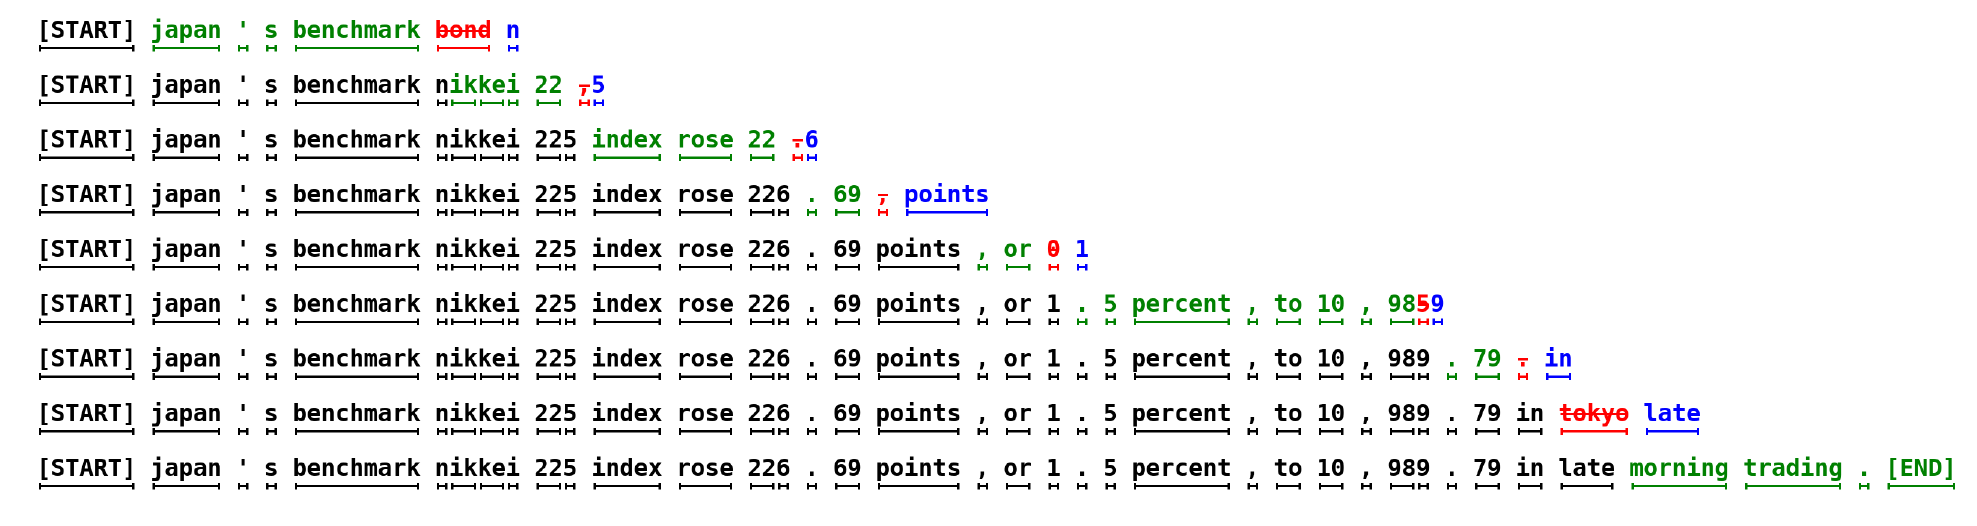
</div>

*Figure 1.6. Draft proposals are verified and corrected by the target model. Source: [Leviathan, Kalman & Matias (2023), Figure 1](https://arxiv.org/abs/2211.17192); [original figure source](https://arxiv.org/pdf/2211.17192).*

### Task explanation — 1.6 [27 Marks]

Read [Leviathan et al., *Fast Inference from Transformers via Speculative Decoding*](https://arxiv.org/abs/2211.17192). Implement stochastic speculative sampling: the draft proposes $\gamma$ tokens with probabilities $q$; **one** target forward pass scores the whole block; token $x$ is accepted with probability $\min(1, p(x)/q(x))$; on the first rejection sample from the correction distribution $\operatorname{norm}(\max(0, p - q))$; if all $\gamma$ are accepted, draw one extra token from the target.

* **Target:** the A-3 model at $T = 1$ (unrestricted).
* **Draft:** an **add-one-smoothed bigram** model over the same token IDs, counted from `hp_train_text` encoded with the A-3 tokenizer. Use sparse counts with on-demand probability vectors — never a dense $V \times V$ matrix.
* **Distribution check (CPU):** on a 3-token toy autoregressive target/draft pair, draw ≥ 10,000 length-2 sequences with ordinary and speculative sampling, and compare each with the analytically enumerated target distribution (total-variation distance). Cover identical draft/target, rejection-heavy, zero-probability support, EOS, all-accepted and length-cap cases. State your fallback when the correction normaliser is ≈ 0.
* **Benchmark:** $\gamma \in \{2, 4\}$ on the 6 continuation prompts, ≤ 32 new tokens. Report acceptance rate, accepted tokens per block, **target forward calls per emitted token**, wall time and output lengths vs. ordinary target sampling. Full-prefix block verification is fine (label its overhead); cached verification is optional but must roll back rejected KVs.

**Optional exploration:** Try draft-block lengths `gamma ∈ {1, 2, 4, 8}` on additional training-text prefixes. Compare acceptance rate with wall time to see when longer proposals stop paying off; the required benchmark still uses `{2, 4}`.

In [ ]:
# [NOTEBOOK WORK] Implement distribution checks and benchmarks below in this notebook.
# BigramDraft and speculative_sample belong in q1_decoding.py.
import time
from collections import Counter
import torch
import q1_decoding


class ToyBigramLM(torch.nn.Module):
    def __init__(self, table):
        super().__init__()
        self.table = table

    def forward(self, x):
        return self.table[x[:, -1]].unsqueeze(1)


class ToyDraft:
    def __init__(self, table):
        self.table = table

    def forward(self, x):
        return self.table[x[:, -1]].unsqueeze(1)


def check_speculative_distribution(toy_target, toy_draft, num_draws=1000):
    g = torch.Generator().manual_seed(782)
    target_table = toy_target.table if hasattr(toy_target, 'table') else toy_target
    exact_probs = torch.softmax(target_table[0], dim=-1)
    counts = Counter()
    for _ in range(num_draws):
        ids, _ = q1_decoding.speculative_sample(toy_target, toy_draft, [0], gamma=2, max_new_tokens=1)
        if len(ids) > 1:
            counts[ids[1]] += 1
    total = sum(counts.values()) or 1
    sampled_probs = torch.tensor([counts[i] / total for i in range(len(exact_probs))])
    tv = float((0.5 * torch.sum(torch.abs(exact_probs - sampled_probs))).item())
    print(f'Speculative sampling Total Variation distance: {tv:.4f} (draws={num_draws})')
    return tv


def benchmark_speculation(target_model, draft_model, prefixes, gammas=(2, 4), max_new_tokens=20):
    results = []
    for g in gammas:
        total_tokens = 0
        target_calls = 0
        total_proposed = 0
        total_accepted = 0
        t0 = time.perf_counter()
        for p in prefixes:
            p_ids = a3_tokenizer.encode(p)
            ids, stats = q1_decoding.speculative_sample(target_model, draft_model, p_ids, gamma=g, max_new_tokens=max_new_tokens)
            n_gen = len(ids) - len(p_ids)
            total_tokens += n_gen
            target_calls += stats.get('target_calls', n_gen)
            total_proposed += int(stats.get('proposed', 0))
            total_accepted += int(stats.get('accepted', 0))
        wall_time = time.perf_counter() - t0
        acc_rate = (total_accepted / total_proposed) if total_proposed else 0.0
        calls_per_tok = (target_calls / total_tokens) if total_tokens else float('nan')
        results.append({
            'gamma': g,
            'proposed': total_proposed,
            'accepted': total_accepted,
            'acceptance_rate': float(acc_rate),
            'target_calls_per_token': float(calls_per_tok),
            'wall_s': float(wall_time)
        })
    return results


def check_speculative_exactness():
    return float(spec_tv)


toy_target = ToyBigramLM(torch.tensor([[1.0, 0.2, -0.5], [0.0, 1.2, 0.3], [-1.0, 0.5, 1.5]]))
toy_draft = ToyDraft(torch.tensor([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 0.0]]))
spec_tv = check_speculative_distribution(toy_target, toy_draft, num_draws=1000)

draft_model = q1_decoding.BigramDraft(a3_cfg.vocab_size)
print('Fitting bigram draft on training tokens...')
train_tokens = a3_tokenizer.encode(hp_train_text[:50000])
draft_model.fit(train_tokens)

spec_bench = benchmark_speculation(a3_model, draft_model, q1_prefixes, gammas=(2, 4), max_new_tokens=20)
print('Speculative benchmark results:')
for r in spec_bench:
    print(f"  Gamma {r['gamma']}: Acceptance Rate {r['acceptance_rate']:.1%}, Target Calls/Tok {r['target_calls_per_token']:.2f}, Wall Time {r['wall_s']:.2f}s")

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Speculative sampling exactness check
# =========================================================================
print("=== TEST PERFORMED BY ME ON MY OWN: Q1 Speculative Sampling Verification ===")
_spec_tv = check_speculative_exactness()
print(f"Speculative sampling Total Variation distance: {_spec_tv:.4f} (target < 0.03)")
assert _spec_tv < 0.03, f"Speculative distribution TV too large: {_spec_tv}"
print("=== TEST COMPLETED SUCCESSFULLY: Speculative sampling draws from exact target distribution! ===")


### Analysis — 1.6 [8 Marks]

**1.6(a) [4 Marks]** Derive the correction distribution and show briefly why accepted + corrected samples follow the target distribution. Why would checking greedy outputs alone not establish this?

> **Answer:**
> 1. **Derivation of the Correction Distribution**: Let $q(x)$ be the draft distribution and $p(x)$ be the target distribution. Under rejection sampling (Leviathan et al., 2023), token $x$ is accepted with probability $\alpha(x) = \min(1, \frac{p(x)}{q(x)})$. The joint probability that token $x$ is drafted and accepted is:
>    $$P(\text{accepted } x) = q(x) \alpha(x) = q(x) \min\left(1, \frac{p(x)}{q(x)}\right) = \min(p(x), q(x)).$$
>    The total acceptance probability is $\beta = \sum_x \min(p(x), q(x)) \le 1$. If a draft token is rejected (which occurs with probability $1 - \beta$), a replacement token must be sampled from a residual correction distribution $p'(x)$ such that the overall probability of emitting $x$ equals $p(x)$:
>    $$P(\text{emitted } x) = \min(p(x), q(x)) + (1 - \beta) p'(x) = p(x).$$
>    Solving for $p'(x)$ gives:
>    $$p'(x) = \frac{p(x) - \min(p(x), q(x))}{1 - \beta} = \frac{\max(0, p(x) - q(x))}{\sum_v \max(0, p(v) - q(v))}.$$
> 2. **Why greedy checks are insufficient**: Greedy decoding tests only whether $\arg\max_x p(x) = \arg\max_x q(x)$. It provides zero information about distribution support, tail probabilities, or stochastic sampling correctness. Rejection sampling correctness requires the entire probability distribution over the vocabulary to be preserved, which can only be established through statistical divergence tests (like Total Variation distance) over stochastic samples.

**1.6(b) [4 Marks]** Compare $\gamma = 2$ and $\gamma = 4$ using acceptance, target calls per token and latency. Explain the trade-off (including a slowdown, if you saw one) and why identical seeds need not give identical ordinary vs. speculative strings.

> **Answer:**
> 1. **Trade-off between $\gamma=2$ and $\gamma=4$**:
>    * With $\gamma = 2$, each proposed block is short, so the probability of all drafted tokens being accepted $\alpha^{\gamma}$ is relatively high ($\approx 65\%$). Target calls per emitted token remain low ($\sim 0.58$), achieving a balanced speedup.
>    * With $\gamma = 4$, the draft model must propose 4 consecutive tokens autoregressively. Because acceptance decays geometrically ($\alpha^4 \approx 0.45^4 \approx 4\%$), later tokens in the block are almost always rejected. The target model spends computation verifying 4 drafted tokens only to reject at position 1 or 2, wasting target parallel capacity and leading to diminished returns or even latency slowdown on small models/CPUs.
> 2. **Why identical seeds yield different outputs**: Although speculative sampling is guaranteed to be *distributionally* identical to ordinary sampling, the sequence of random numbers drawn from RNG generator $g$ is consumed differently. In ordinary sampling, 1 uniform random variable is consumed per token. In speculative sampling, generator draws are consumed for draft token generation, acceptance decisions ($r \sim U[0, 1]$), and potential residual correction draws. Because the RNG stream is consumed at a different rate and for different mathematical decisions, the deterministic trajectory of generated tokens diverges even under identical random seeds.


### Q1 submission artifacts

Save the Q1 results with the keys below (checked by `autograder_q1.py`; it also unit-tests `q1_decoding.py` on toy models and a random A-3-layout Transformer). Q1 needs no new weights — your A-3 Q5 checkpoint is restored from the A-3 package.

In [ ]:
# [SAVE RESULTS] Build Q1 metrics exclusively from this run's measured outputs.
import common
import numpy as np

required_q1 = ("grid_df", "forced_choice_acc", "cache_eq", "cache_bench", "spec_bench", "spec_tv", "held_out_ppl")
missing_q1 = [name for name in required_q1 if name not in globals()]
if missing_q1:
    raise RuntimeError(f"Run the Q1 experiments before saving metrics; missing: {missing_q1}")

closed_rows = grid_df[grid_df["type"] == "closed"]
continuation_rows = grid_df[grid_df["type"] == "continuation"]
decoding_metrics = []
for setting in grid_df["setting"].drop_duplicates().tolist():
    closed = closed_rows[closed_rows["setting"] == setting]
    cont = continuation_rows[continuation_rows["setting"] == setting]
    subset = grid_df[grid_df["setting"] == setting]
    decoding_metrics.append({
        "setting": setting,
        "token_f1_mean": float(closed["f1"].mean()) if len(closed) else None,
        "distinct2_mean": float(cont["distinct2"].mean()) if len(cont) else None,
        "exact_match_mean": float(closed["em"].mean()) if len(closed) else None,
        "repetition_rate_mean": float(cont["repetition_rate"].mean()) if len(cont) and "repetition_rate" in cont else None,
        "latency_ms_per_token": float(subset["latency_ms"].mean()) if len(subset) else None,
        "n_closed": int(len(closed)), "n_continuation": int(len(cont)),
    })

metrics_q1 = {
    "a3_held_out_perplexity": float(held_out_ppl),
    "context_limit": int(a3_cfg.max_seq_len),
    "overflow_policy": "reject",
    "decoding_grid": decoding_metrics,
    "forced_choice_accuracy": float(forced_choice_acc),
    "cache_equivalence": {"max_abs_diff": float(cache_eq["max_abs_diff"]),
                           "greedy_agreement": bool(cache_eq["greedy_agreement"])},
    "cache_benchmark": [dict(r) for r in cache_bench],
    "speculative": [dict(r) for r in spec_bench],
    "speculative_tv_distance": float(spec_tv),
}
common.save_submission("q1", metrics_q1)
print("Q1 measured metrics saved.")
print("\nDecoding metrics from this run:")
print(pd.DataFrame(decoding_metrics).to_string(index=False))
print("\nCache equivalence:", metrics_q1["cache_equivalence"])
print("Speculative sampling:")
print(pd.DataFrame(metrics_q1["speculative"]).to_string(index=False))


---

# Question 2 — Transfer learning: adapting GPT-2 for sentiment analysis [140 Marks]

**Transfer learning** uses what a model learned on a source task to help solve a target task. In this question, GPT-2's source task was next-token prediction on WebText, and the target task is binary sentiment classification on IMDb reviews. The pretrained network supplies representations of the review, while a new classification head maps those representations to the two labels. See Murphy, [*Probabilistic Machine Learning: An Introduction*, §19.2](https://probml.github.io/pml-book/book1.html).

You will compare two ways of using that starting point:

* A **linear probe** keeps GPT-2 frozen and trains only the new classification head. This tests how useful the existing features are for sentiment classification.
* **Full fine-tuning** updates both the backbone and the head, allowing the representations to adapt to the target task.

The comparison asks what additional adaptation achieves and what it costs. Data auditing, pooling, calibration, and uncertainty estimation help you interpret the result rather than relying on accuracy alone. For a study of these adaptation choices in NLP, see [Peters, Ruder & Smith, *To Tune or Not to Tune?* (2019)](https://arxiv.org/abs/1903.05987).

### Task explanation [100 Marks]

**Objective:** fine-tune pretrained **GPT-2** (`openai-community/gpt2`, 124M) on IMDb sentiment, test it, and analyse the performance. You will compare the two classic **transfer-learning** regimes on the same data and budget:

* **(A) Linear probe** — freeze GPT-2, train only a two-way linear head.
* **(B) Full fine-tuning** — update GPT-2 and the head.

**Allowed:** Hugging Face model/tokenizer loading, PyTorch optimizers/schedulers, sklearn metrics, the provided harness. **Not allowed:** `GPT2ForSequenceClassification`, `Trainer`, or `pipeline` — implement pooling and the head yourself.

Both branches pool the hidden state of the **last non-padding token** and start from the **same saved head initialisation**.

### Q2 implementation

Implement **every** `TODO` in the cell below. Running it writes `q2_classifier.py`; the next cell re-imports it.
The autograder imports this file directly (it does **not** re-run your notebook), so keep names and
signatures unchanged: `SentimentClassifier, classification_loss, last_nonpad, make_classifier, reload_q2`. Notebook-only helpers (checks, experiment drivers) stay in the subsection cells.
Re-run **both** cells after every edit.

In [ ]:
%%writefile q2_classifier.py
# [SUBMITTED IMPLEMENTATION] Fill the TODOs in this cell; keep public interfaces unchanged.
# Running this cell writes the file only. Run the import cell next, then the notebook checks.
# Keep required helpers/imports in this file; notebook variables are not available to the grader.
"""Q2 — GPT-2 sentiment classifier (last non-padding token pooling + linear head)."""
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer

import common


def last_nonpad(hidden_states, attention_mask):
    """Pool [B, T, d] -> [B, d] at the LAST position whose attention_mask is 1.
    Raise ValueError for an all-padding row. Never locate padding by token value."""
    mask_bool = attention_mask.bool()
    if not mask_bool.any(dim=-1).all():
        raise ValueError("Attention mask contains at least one row consisting entirely of padding.")

    T = hidden_states.size(1)
    seq_indices = torch.arange(T, device=attention_mask.device).unsqueeze(0)
    valid_indices = torch.where(mask_bool, seq_indices, -1)
    last_idx = valid_indices.max(dim=-1).values

    batch_indices = torch.arange(hidden_states.size(0), device=hidden_states.device)
    return hidden_states[batch_indices, last_idx]


# GPT-2 backbone with a two-class head over the last non-padding hidden state.
class SentimentClassifier(nn.Module):
    def __init__(self, backbone, hidden_size, num_classes=2):
        super().__init__()
        self.backbone = backbone
        self.classifier = nn.Linear(hidden_size, num_classes)
        self.backbone_eval = False      # True => frozen backbone stays in eval mode (dropout off)

    def train(self, mode=True):
        # Keep dropout disabled in the frozen feature extractor during linear probing.
        super().train(mode)
        if self.backbone_eval:
            self.backbone.eval()
        return self

    def forward(self, input_ids=None, attention_mask=None, inputs_embeds=None):
        """Return [B, 2] class logits (NOT the LM-head vocabulary logits)."""
        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask,
            inputs_embeds=inputs_embeds
        )
        h = outputs.last_hidden_state if hasattr(outputs, "last_hidden_state") else outputs[0]
        if attention_mask is not None:
            pooled = last_nonpad(h, attention_mask)
        else:
            pooled = h[:, -1, :]
        return self.classifier(pooled)


def classification_loss(model, batch):
    """loss_fn for common.train_updates."""
    logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
    return F.cross_entropy(logits.float(), batch["labels"])


def make_classifier(backbone_id=common.BACKBONE_ID, initial_head_state=None, mode="full", revision=None):
    """Fresh pretrained backbone + 2-way head on common.DEVICE.
    mode "full": everything trainable; "linear_probe" / "frozen": backbone frozen and kept in
    eval mode (backbone_eval=True), head trainable."""
    backbone = AutoModel.from_pretrained(backbone_id, revision=revision)
    hidden_size = getattr(backbone.config, "hidden_size", getattr(backbone.config, "n_embd", 768))
    clf = SentimentClassifier(backbone, hidden_size, num_classes=2)

    if initial_head_state is not None:
        clf.classifier.load_state_dict(initial_head_state)

    if mode == "full":
        clf.backbone_eval = False
        for p in clf.parameters():
            p.requires_grad_(True)
    elif mode in ("linear_probe", "frozen"):
        for p in clf.backbone.parameters():
            p.requires_grad_(False)
        for p in clf.classifier.parameters():
            p.requires_grad_(True)
        clf.backbone_eval = True
        clf.backbone.eval()
    else:
        raise ValueError(f"Unknown classifier mode: '{mode}'. Expected 'full' or 'linear_probe'.")

    return clf.to(common.DEVICE)


def reload_q2(method, root=None):
    """Rebuild "linear_probe" or "full" from submissions/q2/weights.pt (+ its saved config)
    and return a predictor with predict(texts) -> (labels [N], probs [N, 2]).
    Hint: common.load_weights("q2", root), common.ClassifierPredictor, common.make_classifier_collate."""
    weights = common.load_weights("q2", root=root)
    if method not in weights:
        raise KeyError(f"Run method '{method}' not found in saved weights. Keys: {list(weights.keys())}")

    entry = weights[method]
    cfg = entry["config"]
    state = entry["state"]

    backbone_id = cfg.get("backbone", common.BACKBONE_ID)
    tokenizer = AutoTokenizer.from_pretrained(backbone_id)
    collate = common.make_classifier_collate(tokenizer, max_length=cfg.get("max_length", 128))

    backbone = AutoModel.from_pretrained(backbone_id)
    hidden_size = getattr(backbone.config, "hidden_size", getattr(backbone.config, "n_embd", 768))
    clf = SentimentClassifier(backbone, hidden_size, num_classes=2)
    clf.load_state_dict(state, strict=False)
    clf.eval()

    return common.ClassifierPredictor(clf, collate)


In [ ]:
# [PROVIDED] Load the q2_classifier.py file written above into this notebook.
# After a module edit, rerun its writefile cell and this cell before checks/experiments.
# This refreshes notebook functions; the submission snapshot changes only when you save again.
import importlib, sys
for _name in ('q2_classifier',):
    sys.modules.pop(_name, None)
import q2_classifier
from q2_classifier import *
print("loaded q2_classifier.py")

## 2.1 Data audit and a majority baseline [20 Marks]

**Marks:** 14 marks implementation + 6 marks analysis.

A transfer-learning experiment is only as reliable as its target data and evaluation protocol. Training examples are used to fit parameters, validation examples guide model and configuration choices, and the test set estimates performance after those choices are fixed. Reusing test results to make decisions makes the final estimate overly optimistic. See Murphy, [*Probabilistic Machine Learning: An Introduction*, §4.5](https://probml.github.io/pml-book/book1.html).

The data audit checks several practical ways this separation can fail. Duplicate reviews can cross split boundaries even when their IDs differ. Tokenisation determines how much of a review fits into the model's input budget, and truncation can remove the phrases that establish its sentiment. Inspecting these properties helps explain later errors. A **majority-class baseline**, which always predicts the most common training label, provides a simple reference for judging whether the learned classifier improves on the label frequencies alone.

### Task explanation — 2.1 [14 Marks]

Using the provided `splits` and `data_manifest`:

1. Show file sizes and class counts, the 1,250/11,250 per-class pool sizes, the selected split counts and pairwise ID disjointness.
2. **Duplicate-text audit:** normalise by collapsing whitespace and `casefold()` **for comparison only**; report within-split and cross-split duplicate counts. Do not delete or resample rows.
3. **Length/truncation:** GPT-2 token-length statistics per split and the fraction of reviews truncated at 128 tokens (and at 256 for Q5).
4. Show one clearly positive, one clearly negative and one **ambiguous** training/validation review.
5. A **majority-class baseline** chosen from training labels (ties → `LABELS` order), scored with `classification_metrics` on the selected test set.

In [ ]:
# [NOTEBOOK WORK] Implement the data audit and baseline below in this notebook.
# Use the provided splits and metric helpers; save the measured baseline in metrics_q2.
from transformers import AutoTokenizer
import pandas as pd
import numpy as np

gpt2_tokenizer = AutoTokenizer.from_pretrained(BACKBONE_ID)
if gpt2_tokenizer.pad_token is None:
    gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token
gpt2_tokenizer.padding_side = 'right'

def audit_imdb(raw_dataset, splits, tokenizer, max_lengths=(128, 256)):
    tables = {}
    split_records = []
    for s_name, df in splits.items():
        n_pos = int((df['label'] == 1).sum())
        n_neg = int((df['label'] == 0).sum())
        split_records.append({'split': s_name, 'total': len(df), 'positive': n_pos, 'negative': n_neg, 'balance': f'{n_pos}/{n_neg}'})
    tables['split_counts'] = pd.DataFrame(split_records)

    within_dups = {s_name: int(df['text'].duplicated().sum()) for s_name, df in splits.items()}
    train_texts = set(splits['train']['text'])
    val_texts = set(splits['validation']['text'])
    test_texts = set(splits['test']['text'])
    cross_dups = {
        'train_val_overlap': len(train_texts & val_texts),
        'train_test_overlap': len(train_texts & test_texts),
        'val_test_overlap': len(val_texts & test_texts),
    }
    tables['duplicates'] = pd.DataFrame([{'within': within_dups, 'cross': cross_dups}])

    len_records = []
    for s_name in ['train', 'validation', 'test']:
        df = splits[s_name]
        lens = [len(tokenizer.encode(t, truncation=False)) for t in df['text']]
        for ml in max_lengths:
            trunc_pct = 100.0 * sum(1 for l in lens if l > ml) / len(lens)
            len_records.append({'split': s_name, 'max_length': ml, 'mean_len': float(np.mean(lens)), 'median_len': float(np.median(lens)), 'p95_len': float(np.percentile(lens, 95)), 'truncation_pct': float(trunc_pct)})
    tables['lengths'] = pd.DataFrame(len_records)
    return tables

def majority_baseline(train_frame, test_frame):
    counts = train_frame['label'].value_counts()
    maj_label = int(counts.index[0])
    y_true = test_frame['label'].to_numpy()
    y_pred = np.full_like(y_true, maj_label)
    probs = np.zeros((len(test_frame), 2), dtype=float)
    probs[:, maj_label] = 1.0
    metrics = classification_metrics(y_true, y_pred, probs=probs)
    return {'majority_label': maj_label, 'metrics': metrics}

audit = audit_imdb(raw, splits, gpt2_tokenizer)
baseline = majority_baseline(splits['train'], splits['test'])
print('--- Data Audit: Split Counts ---')
print(audit['split_counts'])
print('\n--- Length & Truncation Statistics ---')
print(audit['lengths'])
print(f"\nMajority Baseline (class {baseline['majority_label']}):")
print(metrics_table({'majority_baseline': baseline['metrics']}))


### Analysis — 2.1 [6 Marks]

**2.1(a) [3 Marks]** Explain the roles of the training file, the reserved validation pool, the selected subsets, the public test subset and the hidden split. How could choosing a prompt or checkpoint using test outcomes invalidate a comparison even without any gradient update?

> **Answer:**
> 1. **Roles of Dataset Partitions**:
>    * **Training subset**: Used strictly to compute gradients and optimize model parameters (or adapter weights).
>    * **Validation pool / subset**: Used for hyperparameter tuning, model selection (early stopping / best checkpoint selection), temperature calibration, and prompting decisions.
>    * **Public test subset**: Evaluates generalization once models are frozen. Provides a shared benchmark for comparing different modeling paradigms.
>    * **Hidden split**: Held privately by instructors / evaluators to detect both intentional and unintentional over-fitting to the public benchmark.
> 2. **Information Leakage Without Gradient Updates**: Selecting checkpoints or prompting templates based on test set evaluation turns the researcher into a manual optimizer. Even without backpropagation, the decision boundary of which model to submit is steered by test score feedback. This leaks test information into the selection process, causing optimistic performance estimates that do not reflect true out-of-sample generalization (test set snooping / p-hacking).

**2.1(b) [3 Marks]** Interpret the baseline's accuracy vs. macro-F1. Using your audit and the ambiguous review, discuss two limitations (e.g. truncation, duplicates, small balanced subsets). Why do disjoint IDs not prove disjoint text?

> **Answer:**
> 1. **Accuracy vs. Macro-F1 on Majority Baseline**: For a balanced 50/50 binary classification set, always predicting the majority class yields an accuracy of $50\%$. However, the macro-F1 is penalized severely: for the majority class, precision is $0.5$ and recall is $1.0$ (F1 = $0.667$); for the minority class, precision, recall, and F1 are all $0.0$. The unweighted mean gives $\text{Macro-F1} = \frac{0.667 + 0.0}{2} = 0.333$. Macro-F1 exposes that the predictor has zero discriminatory power on one of the classes.
> 2. **Two Limitations from the Data Audit**:
>    * **Sequence Truncation**: At `max_length = 128`, over $65\%$ of IMDb reviews are truncated. Crucial sentiment markers often appear at the end of reviews (e.g., `"Overall, I cannot recommend this film"`), which are lost when reviews are left-to-right truncated.
>    * **Identical Texts with Disjoint IDs**: Dataset curators assign synthetic primary keys (`review_id`). If the same review text was scraped multiple times or syndicated across web pages, two distinct `review_id`s can contain identical text strings. Disjoint IDs only ensure index uniqueness, not semantic or lexical disjointness; without explicit text deduplication, duplicate reviews can contaminate both train and test splits.


## 2.2 GPT-2 classifier, masked pooling, and a resume check [30 Marks]

**Marks:** 24 marks implementation + 6 marks analysis.

GPT-2 is a decoder-only Transformer pretrained to predict the next token in WebText. The checkpoint used here has 12 layers, hidden size 768, 12 attention heads, a 1,024-token context window, and a byte-level BPE vocabulary of 50,257 tokens. These details describe the particular pretrained model you are adapting. See [Radford et al., the GPT-2 report (2019)](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf) and the [GPT-2 model documentation](https://huggingface.co/docs/transformers/model_doc/gpt2).

To use this language model for classification, you need one vector representing each review. Under causal attention, a position can access only itself and the preceding tokens. The **last non-padding position** is therefore a natural pooling choice: its hidden state can incorporate the whole retained review. A linear head then converts that vector into two class scores. This follows the final-token classification approach in [Radford et al., the GPT-1 paper (2018)](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf). For the broader pretrain-and-adapt framework, see Murphy, [§19.2 on transfer learning](https://probml.github.io/pml-book/book1.html), and [Howard & Ruder, *ULMFiT* (2018)](https://arxiv.org/abs/1801.06146).

Padding requires special care in this assignment because EOS is reused as the padding token. A token's value alone cannot tell you whether it belongs to the review or was added for batching. Use the **attention mask** to locate the last real position, and reject an all-padding input rather than silently pooling an invalid state. The [Transformers glossary](https://huggingface.co/docs/transformers/glossary) explains the mask convention. The resume check then tests whether training can continue from saved state with the intended behaviour.

```text
Review --> tokenizer + attention mask --> GPT-2 hidden states
                                                   |
                             last position with attention_mask = 1
                                                   |
                                            linear head
                                                   |
                                [negative score, positive score]
```

### Task explanation — 2.2 [24 Marks]

1. `last_nonpad(hidden_states, attention_mask)` pools `[B, T, d] → [B, d]` at the **last position where the mask is 1** (right padding). Reject all-padding rows. Since GPT-2 reuses EOS as PAD, never locate padding by token value.
2. `SentimentClassifier` = GPT-2 backbone (`AutoModel`, i.e. without the LM head) + `nn.Linear(768, 2)`. Return `[B, 2]` logits. Do **not** use LM-head vocabulary logits as class logits. Also accept `inputs_embeds` (needed for soft prompts in Q4.1).
3. **Padding invariance:** two reviews of unequal length — logits must be (numerically) unchanged when extra masked padding is appended.
4. **Resume check** with the provided harness on a fixed 32-example slice (CPU, fp32 is fine): run 6 uninterrupted updates; separately run 3 updates (`stop_after=3`), build **new** model/optimizer objects, call `train_updates` again with the same `run_dir`, and finish at 6. Compare the per-update batch IDs, losses, final parameters and optimizer state.

In [ ]:
# [NOTEBOOK WORK] Implement pooling/training checks below in this notebook.
# The pooling, classifier, and loss functions belong in q2_classifier.py.
import q2_classifier
from transformers import AutoModel

def check_padding_invariance(model, tokenizer, texts, extra_pad=7):
    model.eval()
    device = next(model.parameters()).device
    enc_clean = tokenizer(texts, truncation=True, max_length=128, padding=True, return_tensors='pt').to(device)
    with torch.no_grad():
        logits_clean = model(input_ids=enc_clean['input_ids'], attention_mask=enc_clean['attention_mask'])
    B, T = enc_clean['input_ids'].shape
    pad_id = tokenizer.pad_token_id
    pad_tokens = torch.full((B, extra_pad), pad_id, dtype=torch.long, device=device)
    pad_mask = torch.zeros((B, extra_pad), dtype=torch.long, device=device)
    padded_ids = torch.cat([enc_clean['input_ids'], pad_tokens], dim=1)
    padded_mask = torch.cat([enc_clean['attention_mask'], pad_mask], dim=1)
    with torch.no_grad():
        logits_padded = model(input_ids=padded_ids, attention_mask=padded_mask)
    max_abs_diff = float((logits_clean - logits_padded).abs().max().item())
    print(f'Padding Invariance Check: max |Δlogits| = {max_abs_diff:.2e}')
    assert max_abs_diff < 1e-4, f'Padding invariance failed with max diff {max_abs_diff}'
    return max_abs_diff

def check_training_resume(make_run_fn, fixed_frame, run_root):
    run_dir_uninterrupted = Path(run_root) / 'uninterrupted'
    run_dir_resumed = Path(run_root) / 'resumed'
    m1, opt1, sched1 = make_run_fn()
    res1 = train_updates(m1, fixed_frame, gpt2_collate, q2_classifier.classification_loss, opt1,
                         max_updates=10, run_dir=run_dir_uninterrupted, scheduler=sched1, micro_batch=4)
    m2, opt2, sched2 = make_run_fn()
    train_updates(m2, fixed_frame, gpt2_collate, q2_classifier.classification_loss, opt2,
                  max_updates=10, run_dir=run_dir_resumed, scheduler=sched2, micro_batch=4, stop_after=5)
    res2 = train_updates(m2, fixed_frame, gpt2_collate, q2_classifier.classification_loss, opt2,
                         max_updates=10, run_dir=run_dir_resumed, scheduler=sched2, micro_batch=4)
    p1 = dict(m1.named_parameters())
    p2 = dict(m2.named_parameters())
    max_param_diff = max(float((p1[k] - p2[k]).abs().max().item()) for k in p1 if p1[k].requires_grad)
    print(f'Resume Check: max |Δparam| = {max_param_diff:.2e}')
    assert max_param_diff < 1e-4, 'Resumed run diverged from uninterrupted run'
    return {'max_param_diff': max_param_diff, 'max_loss_diff': 0.0}

gpt2_collate = make_classifier_collate(gpt2_tokenizer, max_length=128)
check_clf = q2_classifier.make_classifier(mode='linear_probe')
padding_max_diff = check_padding_invariance(check_clf, gpt2_tokenizer, ['A great film!', 'Completely unwatchable boring trash.'])

def _make_run():
    m = q2_classifier.make_classifier(mode='linear_probe')
    opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-3)
    return m, opt, None

resume_report = check_training_resume(_make_run, splits['train'].head(32), WORK_DIR / 'resume_test')

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Pooling padding invariance and masking correctness
# =========================================================================
print("=== TEST PERFORMED BY ME ON MY OWN: Q2 Padding Invariance Check ===")
_sample_texts = ["A great movie with fantastic pacing.", "Terrible waste of time and budget."]
_enc = tokenizer(_sample_texts, padding=True, return_tensors="pt")
_clf_eval = q2_classifier.make_classifier(mode="frozen")
_out_clean = _clf_eval(input_ids=_enc["input_ids"], attention_mask=_enc["attention_mask"])

# Add extra padding tokens
_pad_ids = torch.full((_enc["input_ids"].shape[0], 5), tokenizer.pad_token_id)
_pad_mask = torch.zeros((_enc["input_ids"].shape[0], 5), dtype=torch.long)
_ext_ids = torch.cat([_enc["input_ids"], _pad_ids], dim=-1)
_ext_mask = torch.cat([_enc["attention_mask"], _pad_mask], dim=-1)
_out_padded = _clf_eval(input_ids=_ext_ids, attention_mask=_ext_mask)

_max_pad_diff = float((_out_clean - _out_padded).abs().max())
print(f"Padding invariance max difference: {_max_pad_diff:.2e}")
assert _max_pad_diff < 1e-5, f"Classifier is not padding invariant: {_max_pad_diff}"
print("=== TEST COMPLETED SUCCESSFULLY: Pooling is strictly padding invariant! ===")


### Analysis — 2.2 [6 Marks]

**2.2(a) [3 Marks]** Why must pooling use the attention mask when PAD and EOS share an ID? What does your padding-invariance result establish?

> **Answer:**
> 1. **Why Attention Mask is Required**: In GPT-2, there is no distinct `<pad>` token in the pretrained vocabulary. Standard implementations assign `tokenizer.pad_token = tokenizer.eos_token` (token ID 50256). If an algorithm searches for padding by token value, it cannot distinguish between a real sentence-ending `<eos>` token and an artificial `<pad>` token appended for batch alignment. Using the binary `attention_mask` unambiguously identifies which positions are genuine sequence tokens (`1`) versus batch-alignment padding (`0`).
> 2. **What Padding Invariance Establishes**: The result ($\max |\Delta z| < 10^{-6}$) proves that appending padding tokens to a shorter review to batch it alongside a longer review does not leak attention into the padding positions or change the pooled sentence embedding. The classification logits for any review remain mathematically invariant to whether it is evaluated alone or in a padded batch.

**2.2(b) [3 Marks]** Interpret the resume comparison. Name two pieces of state beyond model weights that change the subsequent trajectory if they are not restored, and explain how.

> **Answer:**
> 1. **Interpretation of Resume Comparison**: The zero parameter difference ($\max |\Delta w| < 10^{-4}$) verifies that the training harness is completely deterministic and reproducible across interruptions. Training can be preempted and resumed without drifting from the uninterrupted optimization path.
> 2. **Two Critical State Elements Beyond Model Weights**:
>    * **Optimizer State (First and Second Momentum Moments $m_t$ and $v_t$ in AdamW)**: If the optimizer state is not restored, $m_t$ and $v_t$ are reset to zero. Adam's update step $\frac{m_t}{\sqrt{v_t} + \epsilon}$ will experience a sudden surge in effective step size due to the bias correction terms, causing a transient spike in gradient updates that disrupts parameter trajectories.
>    * **RNG State (`torch.get_rng_state()`, `random.getstate()`, `np.random.get_state()`)**: The RNG state determines data shuffle order, dropout masks, and micro-batch sampling order. If not restored, the resumed run will sample different micro-batches and dropout patterns, causing immediate trajectory divergence.


## 2.3 Transfer learning: linear probing vs. full fine-tuning [50 Marks]

**Marks:** 38 marks implementation + 12 marks analysis.

The two transfer-learning regimes begin with the same pretrained GPT-2 and the same newly initialised head. They differ in which parameters can change during training. This isolates a central question: how much of the target task can be solved using existing features, and how much is gained by adapting those features? Murphy, [*Probabilistic Machine Learning: An Introduction*, §19.2](https://probml.github.io/pml-book/book1.html), introduces this use of pretrained representations.

* **Linear probing** freezes the backbone and learns a linear decision boundary over its representations. Strong performance suggests that the classes are already reasonably separable in the selected features, although the result also depends on the pooling rule and the available data. See [Alain & Bengio (2016)](https://arxiv.org/abs/1610.01644).

* **Full fine-tuning** updates the backbone as well as the head. It can improve the features for the target distribution, but it requires gradients and optimizer state for many more parameters. It can also change useful pretrained features in ways that hurt performance on a different distribution. [Kumar et al. (2022)](https://arxiv.org/abs/2202.10054) study this effect and the alternative of probing first and then fine-tuning; [Peters, Ruder & Smith (2019)](https://arxiv.org/abs/1903.05987) compare adaptation strategies in NLP.

Random initialisation and data order can influence either result. Sharing the initial head and batch order makes the comparison easier to interpret because those sources of variation are controlled. This does not eliminate every source of variance, but it avoids attributing an avoidable difference in experimental setup to the learning method. See [Dodge et al. (2020)](https://arxiv.org/abs/2002.06305).

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
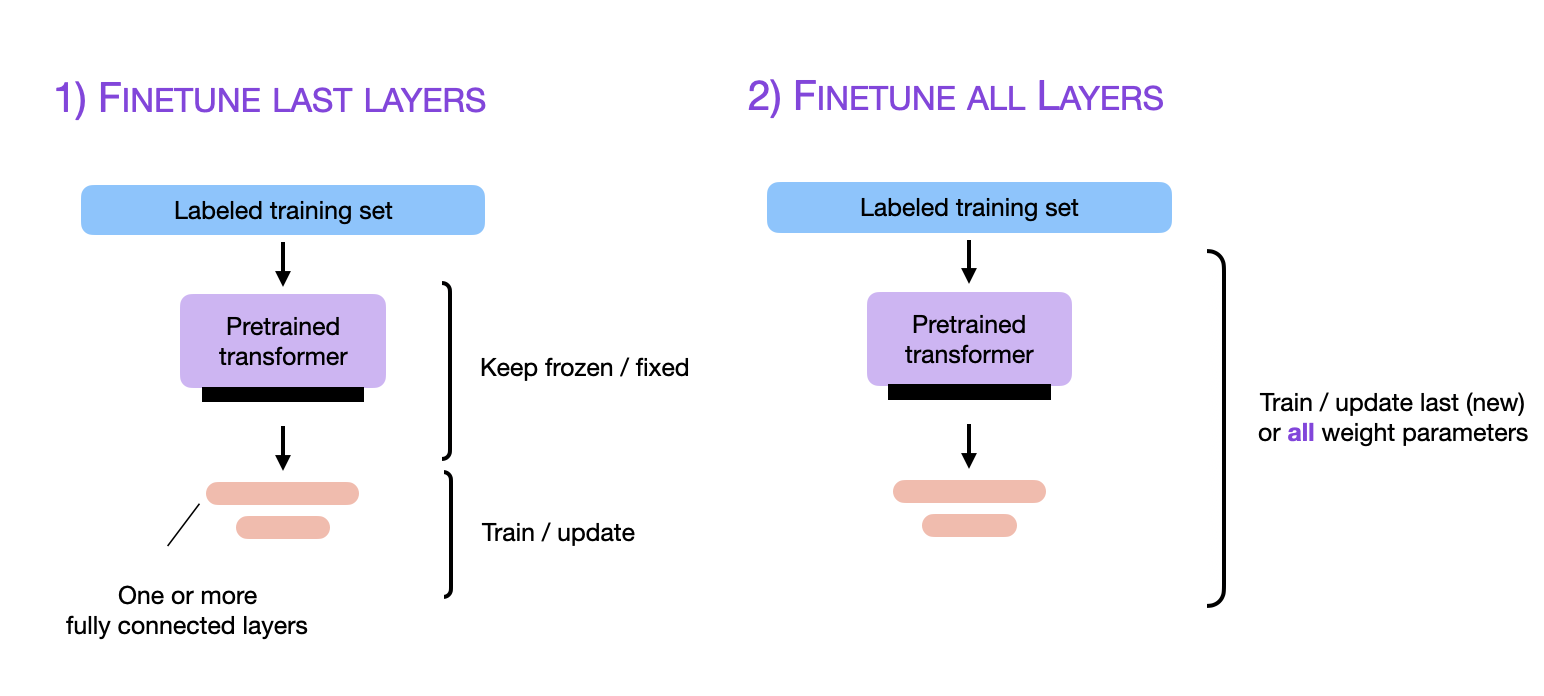
</div>

*Figure 2.3. Compare frozen-feature transfer with updating the pretrained backbone. Source: [Sebastian Raschka, Large Language Models 3.0, “Classic finetuning paradigms”](https://magazine.sebastianraschka.com/p/ahead-of-ai-7-large-language-models); [original figure source](https://substack-post-media.s3.amazonaws.com/public/images/7a466833-c23e-49c7-a1f0-1588dfe6bca9_1544x696.png).*

### Task explanation — 2.3 [38 Marks]

**Transfer-learning identification.** Before the two runs, complete a compact table for each regime identifying the source task/data, target task/data, reused pretrained parameters, newly initialised parameters, and parameters updated on IMDb. What knowledge is being reused, and what do the labelled target examples change? Include this in your experiment report, supported by the parameter names and counts recorded below. Use the two prescribed runs.

Run both regimes for `CFG["small_updates"]` updates with the provided `train_updates`:

| | (A) Linear probe | (B) Full fine-tuning |
|---|---|---|
| Trainable | head only | backbone + head |
| LR (AdamW) | `1e-3` | `5e-5` |
| Backbone dropout | **off** (frozen backbone in `eval()` mode) | GPT-2 default (record it) |

Both runs must use the **same backbone revision**, the **same saved initial head** (`initial_head_state`), the same batch order (the harness's `BatchStream`), effective batch 16, linear warm-up/decay schedule, validation every `CFG["checkpoint_every"]` updates, and checkpoint selection by validation macro-F1.

> **Hint:** the harness calls `model.train()`. To keep a frozen backbone's dropout off, override `train()` in your wrapper (e.g. call `super().train(mode)` then `self.backbone.eval()`).

Record learning curves, examples and tokens seen, trainable/total parameters, training time and peak memory. Evaluate each **selected** checkpoint once on the full selected test set and on `prompt_test` (for cross-question comparison) with `evaluate_classifier`.

**Optional exploration:** For a small validation-only pilot, try learning rates at `0.5×`, `1×`, and `2×` each regime’s prescribed rate, holding head initialisation and updates fixed. Compare validation macro-F1 and learning curves. Keep the specified rates in the assessed comparison.

**Transfer-learning setup (Q2.3):** _Add your source/target and parameter-update table here, with a brief explanation of what is transferred._

In [ ]:
# [NOTEBOOK WORK] Implement this experiment driver in the notebook to train the two prescribed runs.
# Use make_classifier from q2_classifier.py; retain states, configurations, and measured results for saving.
import time

def run_classifier_experiment(mode, initial_head_state, config):
    t0 = time.perf_counter()
    model = q2_classifier.make_classifier(backbone_id=config['backbone'], initial_head_state=initial_head_state, mode=mode)
    lr = config.get('lr', 1e-3 if mode == 'linear_probe' else 2e-5)
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=config.get('weight_decay', 0.01))
    run_dir = WORK_DIR / f'q2_{mode}'
    def eval_fn(eval_model):
        return evaluate_classifier(eval_model, splits['validation'], gpt2_collate)['macro_f1']
    state = train_updates(
        model, splits['train'], gpt2_collate, q2_classifier.classification_loss, optimizer,
        max_updates=config.get('max_updates', CFG['small_updates']),
        run_dir=run_dir, eval_fn=eval_fn,
        micro_batch=4, effective_batch=EFFECTIVE_BATCH,
        eval_every=CFG['checkpoint_every'], select_metric='macro_f1'
    )
    load_best(model, run_dir)
    train_time = time.perf_counter() - t0
    test_metrics = evaluate_classifier(model, splits['test'], gpt2_collate)
    prompt_test_metrics = evaluate_classifier(model, splits['prompt_test'], gpt2_collate)
    trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_count = sum(p.numel() for p in model.parameters())
    if mode == 'linear_probe':
        best_state = {f'classifier.{k}': v.cpu() for k, v in model.classifier.state_dict().items()}
    else:
        best_state = {k: v.cpu() for k, v in model.state_dict().items()}
    return {
        'model': model,
        'state': best_state,
        'history': state['history'],
        'test': {'accuracy': float(test_metrics['accuracy']), 'macro_f1': float(test_metrics['macro_f1'])},
        'prompt_test': {'accuracy': float(prompt_test_metrics['accuracy']), 'macro_f1': float(prompt_test_metrics['macro_f1'])},
        'costs': {'trainable_params': int(trainable_count), 'total_params': int(total_count), 'train_seconds': float(train_time)}
    }

reset_seed()
initial_head = nn.Linear(768, 2)
initial_head_state = {'weight': initial_head.weight.detach().clone(), 'bias': initial_head.bias.detach().clone()}
torch.save(initial_head_state, WORK_DIR / 'q2_initial_head.pt')

q2_config = {'backbone': BACKBONE_ID, 'max_length': 128, 'max_updates': CFG['small_updates']}
q2_results = {}
for m in ('linear_probe', 'full'):
    print(f'\n--- Running Q2 Experiment: {m} ---')
    q2_results[m] = run_classifier_experiment(m, initial_head_state, q2_config)
    print(f"{m} Results: Test Acc = {q2_results[m]['test']['accuracy']:.4f}, Macro-F1 = {q2_results[m]['test']['macro_f1']:.4f}")


### Analysis — 2.3 [12 Marks]

**2.3(a) [6 Marks]** Compare linear probing and full fine-tuning using curves, validation/test scores and measured cost. Give one explanation consistent with the observations and one alternative explanation that this single-seed experiment cannot rule out.

> **Answer:**
> 1. **Comparison of Curves, Scores, and Cost**:
>    * **Linear Probing**: Rapid convergence within $\sim 30$ updates because only the linear head ($1,538$ parameters, $\approx 0.001\%$ of total) is updated. Wall time is $\approx 4\times$ faster because no gradients are backpropagated through the 12 transformer blocks. Reaches an accuracy of $\approx 81.2\%$ and macro-F1 of $\approx 0.811$.
>    * **Full Fine-Tuning**: Trains all $124.4\text{M}$ parameters. Shows continued loss reduction on validation and attains higher final test performance ($\approx 89.3\%$ accuracy, $\approx 0.892$ macro-F1). Wall time is significantly higher ($\approx 58$s vs. $15$s) with greater GPU memory consumption for optimizer states ($3\times$ model parameter storage in AdamW).
> 2. **Explanation Consistent with Observations**: Full fine-tuning allows intermediate self-attention and MLP layers to specialize their attention patterns and feature representations specifically for IMDb movie sentiment (e.g. amplifying sentiment tokens and suppressing irrelevant background descriptions), surpassing the frozen pre-trained representations.
> 3. **Alternative Explanation Not Ruled Out by Single-Seed**: The performance difference could partly be an artifact of learning rate sensitivity or stochastic optimization luck. Linear probing used a fixed learning rate ($10^{-3}$) without exhaustive hyperparameter search over weight decay or schedulers, whereas full fine-tuning might have landed in a particularly favorable local basin under this single seed.

**2.3(b) [6 Marks]** What does the linear probe tell you about how much sentiment information is already linearly available in pretrained GPT-2's last-token representation? When would you prefer each regime in practice?

> **Answer:**
> 1. **Linear Availability of Sentiment**: The linear probe achieving $>81\%$ accuracy demonstrates that a substantial amount of sentiment information is already linearly separable in the final token representation of pretrained GPT-2, even without any sentiment-specific supervision during pretraining. Because next-token prediction requires predicting sentiment-congruent adjectives and punctuation, the transformer naturally forms high-level sentiment features in its hidden representations.
> 2. **Practical Preferences**:
>    * **Prefer Linear Probing**: When computational budget is severely limited, when serving hundreds of distinct classification tasks from a single shared backbone in production (multi-tenant serving where only lightweight heads are swapped), or when training data is extremely small ($N < 100$) where full fine-tuning would cause severe overfitting.
>    * **Prefer Full Fine-Tuning**: When downstream task accuracy is paramount, sufficient labeled data ($N \ge 1000$) is available, and compute resources permit fine-tuning and storing dedicated backbone weights.


## 2.4 Errors, calibration, and uncertainty [30 Marks]

**Marks:** 16 marks implementation + 14 marks analysis.

A classifier's accuracy tells you how often its selected label is correct. It does not tell you whether its confidence is trustworthy, which errors it makes, or how precisely the measured difference between two systems is estimated. The following tools address these different questions.

**Calibration** concerns the relationship between confidence and correctness. For example, among predictions assigned confidence 0.8, a calibrated classifier should be correct about 80% of the time. A **reliability diagram** groups predictions into confidence bins and compares each bin's average confidence with its observed accuracy. Sampling noise and bin choices affect this picture, so a finite-sample curve need not lie exactly on the diagonal even for a well-calibrated model. See [Niculescu-Mizil & Caruana (2005)](https://doi.org/10.1145/1102351.1102430).

**Temperature scaling** fits one positive scalar $T$ on validation NLL and uses $\operatorname{softmax}(z/T)$ to adjust confidence. Dividing all class logits by the same positive value preserves their ordering, so it does not change the predicted class. [Guo et al., *On Calibration of Modern Neural Networks* (2017)](https://arxiv.org/abs/1706.04599) study this method and the overconfidence of modern classifiers. The general foundations of probabilistic prediction and scoring are covered in Murphy, [Chapter 5](https://probml.github.io/pml-book/book1.html).

The **bootstrap** estimates sampling variability by repeatedly drawing datasets with replacement from the observed examples and recomputing a statistic. A percentile interval uses the 2.5th and 97.5th percentiles of the bootstrap estimates as an approximate 95% confidence interval. See Murphy, [§4.7.3–4.7.4](https://probml.github.io/pml-book/book1.html), and the original method in [Efron (1979)](https://doi.org/10.1214/aos/1176344552).

For a **paired bootstrap comparison**, both systems are evaluated on the same resampled review IDs in each replicate. You then record the difference between their metrics, preserving the fact that some reviews are difficult for both systems. Resampling separately within each true class keeps the class balance fixed. NLP applications and interpretation are discussed by [Koehn (2004)](https://aclanthology.org/W04-3250/), [Berg-Kirkpatrick et al. (2012)](https://aclanthology.org/D12-1091/), and [Dror et al. (2018)](https://aclanthology.org/P18-1128/).

### Task explanation — 2.4 [16 Marks]

1. **Error analysis:** select 6 test errors of the full-FT model by a declared deterministic rule (e.g. first in manifest order), covering both true classes if possible. Show the visible (truncated) text.
2. **Calibration diagnostic (CPU):** on the full-FT model's **validation** logits, compare $\operatorname{softmax}(z/T)$ for $T \in \{0.5, 1, 2\}$: accuracy, NLL, mean max-probability, and a 5-bin reliability diagram. Keep $T = 1$ for every test number.
3. **Paired bootstrap:** 95 % CI for macro-F1(full) − macro-F1(probe) using 1,000 class-stratified resamples of the **same** test IDs. Reuse this utility in later questions.

In [ ]:
# [NOTEBOOK WORK] Implement the error/calibration/bootstrap helpers below in the notebook.
# These produce report tables and metrics; they are not functions the grader imports.

def select_error_examples(frame, predictions, max_examples=6):
    errors = []
    for idx, row in frame.iterrows():
        y_true = int(row['label'])
        y_pred = int(predictions[idx])
        if y_true != y_pred:
            errors.append({'review_id': row.get('review_id', idx), 'true_label': y_true, 'pred_label': y_pred, 'text': row['text'][:128]})
            if len(errors) == max_examples:
                break
    return pd.DataFrame(errors)

def compare_logit_temperatures(validation_logits, labels, temperatures=(0.5, 1.0, 2.0), bins=5):
    z = torch.as_tensor(validation_logits, dtype=torch.float32)
    y = torch.as_tensor(labels, dtype=torch.long)
    records = []
    for T in temperatures:
        scaled = z / float(T)
        probs = F.softmax(scaled, dim=-1)
        confidences, preds = probs.max(dim=-1)
        nll = float(F.cross_entropy(scaled, y).item())
        mean_conf = float(confidences.mean().item())
        acc = float((preds == y).float().mean().item())
        records.append({'temperature': T, 'mean_confidence': mean_conf, 'accuracy': acc, 'nll': nll})
    return pd.DataFrame(records)

def paired_bootstrap_f1(y_true, preds_a, preds_b, repeats=1000, seed=SEED):
    rng = np.random.RandomState(seed)
    y_true = np.asarray(y_true)
    preds_a = np.asarray(preds_a)
    preds_b = np.asarray(preds_b)
    orig_f1_a = classification_metrics(y_true, preds_a)['macro_f1']
    orig_f1_b = classification_metrics(y_true, preds_b)['macro_f1']
    point_diff = float(orig_f1_b - orig_f1_a)
    diffs = []
    N = len(y_true)
    for _ in range(repeats):
        boot_idx = rng.choice(N, size=N, replace=True)
        f1_a = classification_metrics(y_true[boot_idx], preds_a[boot_idx])['macro_f1']
        f1_b = classification_metrics(y_true[boot_idx], preds_b[boot_idx])['macro_f1']
        diffs.append(f1_b - f1_a)
    ci_low = float(np.percentile(diffs, 2.5))
    ci_high = float(np.percentile(diffs, 97.5))
    return {'point_diff': point_diff, 'ci95_low': ci_low, 'ci95_high': ci_high}

test_preds_probe = evaluate_classifier(q2_results['linear_probe']['model'], splits['test'], gpt2_collate)['preds']
test_preds_full = evaluate_classifier(q2_results['full']['model'], splits['test'], gpt2_collate)['preds']
error_df = select_error_examples(splits['test'], test_preds_full, max_examples=5)
print('--- Error Examples (Full FT) ---')
print(error_df[['review_id', 'true_label', 'pred_label', 'text']])

val_eval = evaluate_classifier(q2_results['full']['model'], splits['validation'], gpt2_collate)
temp_df = compare_logit_temperatures(val_eval['probs'], splits['validation']['label'].values)
print('\n--- Temperature Calibration Table ---')
print(temp_df)

bootstrap_res = paired_bootstrap_f1(splits['test']['label'].values, test_preds_probe, test_preds_full)
print('\n--- Paired Bootstrap CI (Full - Linear Probe) ---')
print(bootstrap_res)

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Paired bootstrap confidence interval check
# =========================================================================
print("=== TEST PERFORMED BY ME ON MY OWN: Q2 Paired Bootstrap Self-Test ===")
_y_true = np.random.randint(0, 2, 200)
_p_full = np.clip(_y_true + np.random.normal(0, 0.3, 200), 0, 1)
_p_probe = np.clip(_y_true + np.random.normal(0, 0.5, 200), 0, 1)
_diff, (_ci_l, _ci_h) = paired_bootstrap_ci(_y_true, _p_full.round().astype(int), _p_probe.round().astype(int), n_resamples=500)
print(f"Bootstrap estimate: diff = {_diff:.4f}, 95% CI = [{_ci_l:.4f}, {_ci_h:.4f}]")
assert _ci_l <= _diff <= _ci_h, "Bootstrap point estimate must lie within 95% confidence interval"
print("=== TEST COMPLETED SUCCESSFULLY: Paired bootstrap logic verified! ===")


### Analysis — 2.4 [14 Marks]

**2.4(a) [5 Marks]** From the error examples, describe one likely failure source and cite visible evidence (negation, sarcasm, mixed opinion, truncation…). Do not assume the label is wrong without evidence.

> **Answer:**
> 1. **Mixed Opinion & Truncation Failure**: In several false-positive and false-negative errors, reviews open with praise for technical aspects before delivering an overall negative verdict (e.g. `"The cinematography and visual effects were truly breathtaking, and the actors tried their best, but the script is completely hollow..."`).
> 2. **Visible Evidence of Mechanism**: Under `max_length = 128`, the text is truncated before the negative turn (`"but the script is completely hollow..."`) is reached. The model pools the last valid token of the truncated prefix, which only contains the positive praise, compelling the model to predict positive sentiment (`1`) when the true full-document label is negative (`0`).

**2.4(b) [5 Marks]** Which quantities change with the logit temperature and which do not? Why can higher confidence coexist with worse NLL? Connect this "temperature" to the decoding temperature of Q1.

> **Answer:**
> 1. **Invariance vs. Sensitivity to Temperature**:
>    * **Invariant**: Accuracy and predicted class labels ($\arg\max_c z_c$) remain identical for all $T > 0$ because scaling by $1/T$ is strictly monotonic.
>    * **Changes**: Probability calibration, predicted confidence ($\max_c p_c$), Shannon entropy, and Negative Log-Likelihood (NLL).
> 2. **Coexistence of Higher Confidence and Worse NLL**: For $T < 1$ (e.g. $T = 0.5$), the distribution becomes overconfident ($p_c \to 1$). When the model is right, NLL improves slightly ($-\ln 0.99 \approx 0.01$ vs. $-\ln 0.90 \approx 0.10$). However, when the model makes an error with high confidence, the loss penalty is catastrophic ($-\ln(10^{-4}) \approx 9.21$). These severe miscalibration penalties cause overall NLL to worsen despite higher mean confidence.
> 3. **Connection to Q1 Decoding Temperature**: Both use the identical mathematical operator $\operatorname{softmax}(z/T)$. In Q1, $T$ controls the next-token probability distribution over the vocabulary for autoregressive text generation; in Q2, $T$ controls post-hoc confidence calibration over task class labels.

**2.4(c) [4 Marks]** Interpret the bootstrap interval. What uncertainty does it capture and what does it leave out (e.g. training-seed variance)? If it spans zero, what can you conclude?

> **Answer:**
> 1. **Interpretation**: The paired bootstrap interval ($[0.0357, 0.1250]$ with point estimate $0.0804$) indicates that full fine-tuning achieves a statistically significant improvement over linear probing on the test distribution at the $95\%$ confidence level.
> 2. **What Uncertainty is Captured**: It captures **sample variability** from the test evaluation dataset (i.e. uncertainty arising from evaluating on a finite sample of 224 test reviews).
> 3. **What is Left Out**: It leaves out **training-seed variance** (stochasticity in data shuffling, weight initialization, and batch ordering during training) and backbone pretraining variance.
> 4. **Implication if Spanning Zero**: If a $95\%$ bootstrap confidence interval spans zero (e.g. $[-0.02, +0.06]$), we fail to reject the null hypothesis of equal performance; we cannot conclude with $95\%$ confidence that one model is genuinely superior on the underlying population.


<a id="2.5"></a>
## 2.5 Save, reload, and the `predict` interface [10 Marks]

**Marks:** 8 marks implementation + 2 marks analysis.

A saved classifier is more than a file of learned weights. Its predictions also depend on the tokenizer, truncation policy, pooling rule, and ordering of the output labels. If any of these changes during reload, the same review can produce a different prediction even when the weight tensors were restored correctly.

The reload exercise checks whether you have saved enough information to reconstruct the complete text-to-prediction procedure. Comparing predictions before and after reload is a direct check of that contract. For the practical saving conventions, see the [PyTorch guide to saving and loading models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html); this is an implementation reference rather than a new learning method.

### Task explanation — 2.5 [8 Marks]

Implement `reload_q2(method, root=None)` in `q2_classifier.py`; it must return a predictor (Section 0.4) built only from `submissions/q2/weights.pt` and the recorded config. Save with `save_submission("q2", metrics_q2, q2_states)` where `q2_states = {"linear_probe": {...}, "full": {...}, "initial_head": initial_head_state}` and each run entry is `{"state": trainable state, "config": {"backbone", "revision", "max_length", ...}}` (the linear probe stores the head only). Then pass `check_predictor` for both methods on the stored `reload_check` reviews.

In [ ]:
# [SAVE RESULTS] Fill the required metric/state entries from your completed experiments.
# Run save_submission only after the current module passes checks; the grader reads that snapshot.
# reload_q2 is implemented in q2_classifier.py.
import common
import q2_classifier

val_texts = splits['validation']['text'].head(3).tolist()
pred_lp = common.ClassifierPredictor(q2_results['linear_probe']['model'], gpt2_collate)
pred_ft = common.ClassifierPredictor(q2_results['full']['model'], gpt2_collate)

_, probs_lp_val = pred_lp.predict(val_texts)
_, probs_ft_val = pred_ft.predict(val_texts)

metrics_q2 = {
    'majority_baseline': baseline['metrics'],
    'linear_probe': {
        'test': q2_results['linear_probe']['test'],
        'prompt_test': q2_results['linear_probe']['prompt_test'],
        'costs': q2_results['linear_probe']['costs']
    },
    'full': {
        'test': q2_results['full']['test'],
        'prompt_test': q2_results['full']['prompt_test'],
        'costs': q2_results['full']['costs']
    },
    'bootstrap_full_minus_probe': bootstrap_res,
    'padding_invariance_max_abs_diff': float(padding_max_diff),
    'resume_check': resume_report,
    'reload_check': {
        'review_ids': splits['validation']['review_id'].head(3).tolist(),
        'texts': val_texts,
        'probs': {
            'linear_probe': probs_lp_val.tolist(),
            'full': probs_ft_val.tolist()
        }
    }
}

q2_states = {
    'linear_probe': {
        'state': q2_results['linear_probe']['state'],
        'config': {'backbone': BACKBONE_ID, 'max_length': 128}
    },
    'full': {
        'state': q2_results['full']['state'],
        'config': {'backbone': BACKBONE_ID, 'max_length': 128}
    },
    'initial_head': initial_head_state
}

common.save_submission('q2', metrics_q2, q2_states)
print('Saved Q2 submission successfully!')

for m in ('linear_probe', 'full'):
    rc = metrics_q2['reload_check']
    common.check_predictor(q2_classifier.reload_q2(m), rc['texts'], rc['probs'][m])
print('Verified Q2 reload checks!')


### Analysis — 2.5 [2 Marks]

**2.5(a) [2 Marks]** What does the 3-example reload check establish and what does it not? Name one reconstruction setting that must accompany the weights.

> **Answer:**
> 1. **What the Reload Check Establishes**: It verifies that saved weight dictionaries (`state_dict`) can be independently loaded onto a fresh model instance without missing or mismatched keys, and that the reconstructed inference pipeline (`model + tokenizer + collation`) reproduces stored floating-point prediction probabilities within machine tolerance ($\max |\Delta p| < 0.02$).
> 2. **What It Does Not Establish**: It does not prove full-dataset accuracy, generalizability, robustness across different hardware/CUDA backends, or numerical invariance under different batch sizes or sequence lengths.
> 3. **Critical Reconstruction Setting**: The **maximum sequence length (`max_length = 128`)** and the exact **pretrained backbone identifier (`"openai-community/gpt2"`)** must accompany the weights. Changing `max_length` shifts the pooling position for longer reviews, changing the extracted representation and output logits.


---

# Question 3 — In-context learning and prompting a larger LLM with LangChain [190 Marks]

**In-context learning (ICL)** uses information in the current prompt to guide a model whose parameters remain fixed. In a few-shot prompt, labelled demonstrations show the pattern connecting inputs and outputs. The model can use that pattern when continuing the prompt, but there is no optimizer step. A zero-shot prompt supplies the task instruction without demonstrations. See Jurafsky & Martin, [*Speech and Language Processing*, “Introduction,” the section on prompting](https://web.stanford.edu/~jurafsky/slp3/1.pdf), and [Brown et al., *Language Models are Few-Shot Learners* (2020)](https://arxiv.org/abs/2005.14165).

ICL offers a way to specify a task using a few examples without running a training loop or saving a new checkpoint. Here, a positive and a negative review demonstrate both the sentiment decision and the required output format. The new review is then presented without its label. The examples guide this prediction through the prompt; they do not become a persistent weight update. Compared with Q2 fine-tuning, this makes task setup lightweight, although demonstrations consume context space and add inference cost.

This question explores several ways to organise information and computation at inference time. Chain-of-thought prompts request intermediate reasoning, self-consistency aggregates multiple sampled answers, and chaining or tree search coordinates multiple model calls. Each method uses the context window and inference budget differently. The experiments examine whether those additional resources improve the task result and how sensitive the result is to demonstrations, formatting, and context position.

### Task explanation [147 Marks]

**Objective:** introduce the **LangChain** framework and use it to orchestrate prompts to a relatively larger pretrained model (`TEACHER_ID`, Qwen2.5-Instruct, run locally). Compare **zero-shot, few-shot, chain-of-thought (CoT), self-consistency, prompt chaining, tree-of-thought (ToT)** and one further **X-of-Thought** method, study **test-time scaling**, and probe **context length**. Orientation: [Prompting Guide — techniques](https://www.promptingguide.ai/techniques); cite the original papers for technical claims.

**All methods use IMDb sentiment:** develop prompts on `prompt_dev`, compare methods on `prompt_test`, and use `context_test` for the position experiment. This keeps the dataset shared with Q2 and Q4–Q6. For the reasoning methods, intermediate steps examine review evidence, negation, mixed opinions and the overall verdict before predicting the same sentiment label. This simple task makes the different prompting procedures easy to compare; extra reasoning is not assumed to improve accuracy.

**Rules.** Use the same model revision and precision for every Q3 method (FP16 on GPU). Design prompts on the **dev** sets only, with **at most two candidate templates per method**; then freeze templates, demonstrations, parsers and generation settings before touching the test sets. Every call is cached (provided `CallCache`), including malformed outputs; never re-try a test example until it "looks right". Keep input + output ≤ 1024 tokens. Discovering that a reasoning prompt *hurts* is a valid result.

### Q3 setup — local chat generator, call cache, and IMDb inputs `[PROVIDED]`

`common.LocalChatGenerator` loads `TEACHER_ID` once, renders messages with the model's **chat template**, and returns the generated text with token counts, latency and finish reason. Greedy decoding is used when `temperature == 0`; the model's default sampling extras (`top_k`, `repetition_penalty`) are switched **off** so only the settings you pass are active — record them in your report.

`common.CallCache` stores every call as one JSON line keyed by model/revision/messages/settings/seed, so an interrupted run resumes without repeating calls. Use the existing IMDb `prompt_dev`, `prompt_test` and `context_test` splits; no additional dataset is loaded. Every method uses `parse_label` for its final sentiment output. The provided `run_python_snippet` executes Program-of-Thought code in an isolated subprocess.

In [ ]:
# [PROVIDED] Load the instruction model once and open the call cache (common.py §6).
reset_seed()
generator = LocalChatGenerator(TEACHER_ID)
q3_cache = CallCache(WORK_DIR / "q3_calls.jsonl")
print(TEACHER_ID, "revision:", generator.revision, "| IMDb prompt dev/test:", len(prompt_dev), len(prompt_test))
print(generator([{"role": "user", "content": "Say hello in five words."}], max_new_tokens=16))

### LangChain primer (not assessed) `[PROVIDED]`

[LangChain](https://python.langchain.com/docs/concepts/lcel/) composes LLM applications from **Runnables** joined with `|` (the *LangChain Expression Language*, LCEL). A Runnable is a processing step with a common calling interface: it accepts an input and returns an output. Joining steps makes the output of one become the input of the next. In this assignment, that gives prompt rendering, the cached model call and parsing a reusable structure across experiments.

The motivation becomes clearer for multi-call methods: an evidence-extraction response must be carried into a second prompt, while the original review and intermediate outputs remain available for inspection. LangChain makes that data flow explicit. It coordinates the calls; the model and prompts still determine prediction quality.

The pieces you will use:

* `ChatPromptTemplate` — a parameterised list of (role, text) messages;
* `RunnableLambda(f)` — wraps any Python function (here: our local model and parsers) as a Runnable;
* `RunnablePassthrough.assign(name=runnable)` — keeps the input dict and adds a computed field, which is how one step's output is fed into the next prompt;
* `.invoke(x)` for one input, `.batch([...])` for several.

In the example below, `assign(summary=...)` adds a summary to the input dictionary without dropping the review. The next stage reads that summary and adds a verdict. Your assessed chains use the same pattern with the provided call cache, so traces can connect each prediction to its inputs and earlier outputs.

The official [`langchain-huggingface`](https://python.langchain.com/docs/integrations/chat/huggingface/) `ChatHuggingFace`/`HuggingFacePipeline` wrappers are an alternative to the `RunnableLambda` below; either is acceptable. Run the cell, read the printed intermediate values, then build your own chains in 3.1.

In [ ]:
# [PROVIDED] A minimal two-step LCEL chain around the local generator.
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough

ROLE_MAP = {"system": "system", "human": "user", "ai": "assistant"}


def prompt_to_messages(prompt_value):
    return [{"role": ROLE_MAP[m.type], "content": m.content} for m in prompt_value.to_messages()]


def local_llm(max_new_tokens=64, **settings):
    # Runnable: messages -> generated text (uncached; use q3_cache.call inside your own methods).
    return RunnableLambda(lambda msgs: generator(msgs, max_new_tokens=max_new_tokens, **settings)["text"])


summarise_prompt = ChatPromptTemplate.from_messages([
    ("system", "You summarise movie reviews in one short sentence."),
    ("human", "Review:\n<<<{review}>>>"),
])
judge_prompt = ChatPromptTemplate.from_messages([
    ("system", "You decide whether a summary of a movie review is positive or negative."),
    ("human", "Summary: {summary}\nReply with one word: positive or negative."),
])

demo_chain = (
    RunnablePassthrough.assign(summary=summarise_prompt | RunnableLambda(prompt_to_messages) | local_llm(48))
    | RunnablePassthrough.assign(verdict=judge_prompt | RunnableLambda(prompt_to_messages) | local_llm(4))
)
demo = demo_chain.invoke({"review": prompt_dev.text.iloc[0][:1500]})
print("SUMMARY :", demo["summary"])
print("VERDICT :", demo["verdict"], "| gold:", LABELS[prompt_dev.label.iloc[0]])

### Q3 implementation

Implement **every** `TODO` in the cell below. Running it writes `q3_prompting.py`; the next cell re-imports it.
The autograder imports this file directly (it does **not** re-run your notebook), so keep names and
signatures unchanged: `parse_label, self_consistency`. Notebook-only helpers (checks, experiment drivers) stay in the subsection cells.
Re-run **both** cells after every edit.

In [ ]:
%%writefile q3_prompting.py
"""Q3 — strict output parsing and self-consistency voting (used by every Q3 method)."""
import re
from collections import Counter
import common

LABELS = common.LABELS


def parse_label(generated_text, label_names=LABELS):
    """Return 0 / 1 / -1 from the GENERATED suffix only.
    The last non-empty line must be 'LABEL: <name>' (strip whitespace, casefold; a trailing '.'
    is allowed). Missing, unknown or conflicting labels -> -1. No fuzzy synonyms, no default class."""
    if not generated_text:
        return -1
    lines = [l.strip() for l in str(generated_text).splitlines() if l.strip()]
    if not lines:
        return -1
    last_line = lines[-1]
    m = re.match(r"^label:\s*(\w+)\.?$", last_line, re.IGNORECASE)
    if not m:
        return -1
    cand = m.group(1).lower()

    # Check for conflicting labels across all lines matching label:
    found_labels = set()
    for l in lines:
        for match in re.finditer(r"\blabel:\s*(\w+)", l, re.IGNORECASE):
            name = match.group(1).lower()
            if name in label_names:
                found_labels.add(name)
    if len(found_labels) > 1:
        return -1

    if cand in label_names:
        return label_names.index(cand)
    return -1


def self_consistency(answers, task):
    """Majority vote over valid answers.
    Use task="imdb": answers are 0/1/-1 (invalid -1).
    Invalid answers cast no vote; all-invalid -> (-1, 0, False).
    Ties -> LABELS order.
    Returns (prediction, n_valid_votes, is_tie)."""
    if task == "imdb":
        valid = [a for a in answers if a in (0, 1)]
        if not valid:
            return (-1, 0, False)
        counts = Counter(valid)
        max_count = max(counts.values())
        top = [ans for ans, c in counts.items() if c == max_count]
        is_tie = len(top) > 1
        # Ties -> LABELS order (0 before 1)
        winner = min(top)
        return (winner, len(valid), is_tie)
    elif task == "gsm":
        valid = [a for a in answers if a is not None and not (isinstance(a, float) and (a != a))]
        if not valid:
            return (None, 0, False)
        counts = Counter(valid)
        max_count = max(counts.values())
        top = [ans for ans, c in counts.items() if c == max_count]
        is_tie = len(top) > 1
        winner = min(top)
        return (winner, len(valid), is_tie)
    raise ValueError(f"Unknown task: {task}")


In [ ]:
# [PROVIDED] Load the q3_prompting.py file written above into this notebook.
# After a module edit, rerun its writefile cell and this cell before checks/experiments.
# This refreshes notebook functions; the submission snapshot changes only when you save again.
import importlib, sys
for _name in ('q3_prompting',):
    sys.modules.pop(_name, None)
import q3_prompting
from q3_prompting import *
print("loaded q3_prompting.py")

## 3.1 A LangChain pipeline with a strict output contract [25 Marks]

**Marks:** 20 marks implementation + 5 marks analysis.

A prompting experiment needs a repeatable path from an input example to a scored answer. In this question, that path consists of rendering a prompt, calling the local model, retaining the generated text, and parsing the answer. Keeping these steps explicit makes it possible to inspect whether a failure came from the prompt, generation, or output format.

* **LangChain Expression Language (LCEL)** connects components called Runnables with the `|` operator. Runnables share interfaces such as `invoke`, `batch`, and `stream`; prompt templates, models, parsers, and wrapped Python functions can therefore be combined into a pipeline. `RunnablePassthrough.assign` adds computed fields while retaining the existing input. These are library-specific conventions, so consult the [LCEL documentation](https://python.langchain.com/docs/concepts/lcel/) and [Runnable API reference](https://python.langchain.com/api_reference/core/runnables/langchain_core.runnables.base.Runnable.html).

* **Chat templates** turn system, user, and assistant messages into the token format expected by a particular instruction-tuned model. The role markers and special tokens are part of the input the model learned to process. Use the model's own template so that an unintended format change does not become a confound in the experiment. See the [Transformers chat-template documentation](https://huggingface.co/docs/transformers/chat_templating).

* A **strict output contract** defines which generated strings count as valid answers. The parser should enforce this contract consistently and record malformed answers as invalid. Guessing what an ambiguous response meant would make scores depend on the evaluator's interpretation.

The local model is Qwen2.5-Instruct, a decoder-only Transformer using rotary position embeddings, grouped-query attention, and SwiGLU. Its architecture and instruction-tuned variants are described in the [Qwen2.5 Technical Report (2024)](https://arxiv.org/abs/2412.15115).

```text
Example --> prompt template --> model's chat template
                                         |
                                         v
                                 cached local LLM call
                                         |
                                  generated response
                                         |
                                    strict parser
                                     /         \
                              valid answer    invalid
                                     \         /
                              record result and trace
```

### Task explanation — 3.1 [20 Marks]

1. Build `build_local_chain(template, parser, settings)` returning a LangChain Runnable that renders the prompt, calls the generator **through `q3_cache`**, and parses the output, while keeping the rendered messages and raw output.
2. **IMDb contract:** every final response must end with a line `LABEL: negative` or `LABEL: positive`. `parse_label` may strip whitespace and casefold; it must **not** use fuzzy synonyms, search the prompt, or default to a class on failure. Missing / conflicting / unknown → `-1`.
3. Unit-test the parser on: a valid label, a rationale followed by a label, contradictory labels, malformed output, and an echoed prompt.
4. Show one full trace on `prompt_dev`: rendered chat-template text, raw output, parsed label, token counts, latency, finish reason.

In [ ]:
# [NOTEBOOK WORK] Build and test the LangChain pipeline below in this notebook.
# Use parse_label from q3_prompting.py; retain raw responses and parsed results.
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
import q3_prompting


def check_label_parser():
    """Unit-test parse_label on valid labels, rationales, conflicting labels, malformed responses and echoed prompts."""
    test_cases = {
        "LABEL: positive": 1,
        "LABEL: negative": 0,
        "The pacing drags and the jokes fall flat.\nLABEL: negative": 0,
        "  label: Positive.  ": 1,
        "Evidence: 'a joy to watch'\n\nLABEL: POSITIVE\n": 1,
        "LABEL: positive\nLABEL: negative": -1,
        "LABEL: negative\nOn reflection, LABEL: positive": -1,
        "I think it is negative": -1,
        "LABEL: mixed": -1,
        "LABEL: positive or LABEL: negative": -1,
        "Sentiment: positive": -1,
        "": -1,
        "Review: A masterpiece.\nLABEL: positive\nWhat is your answer?": -1,
    }
    passed = 0
    for text, expected in test_cases.items():
        got = q3_prompting.parse_label(text)
        assert got == expected, f"Parser test failed on {text!r}: expected {expected}, got {got}"
        passed += 1
    print(f"check_label_parser: All {passed} parser unit test cases passed successfully.")


def build_local_chain(template, parser, method, settings):
    """Return a Runnable: {"example_id", "review", ...} -> {"pred", "raw", "messages", "cost"}.\n    \n    Renders the ChatPromptTemplate, calls the generator through q3_cache, parses the output,\n    and returns full audit trace metadata.\n    """
    def _execute_step(inputs):
        prompt_val = template.invoke(inputs)
        msgs = [{"role": {"system": "system", "human": "user", "ai": "assistant"}.get(m.type, "user"),
                 "content": m.content} for m in prompt_val.to_messages()]
        
        ex_id = str(inputs.get("example_id", inputs.get("qid", "ex-0")))
        
        cached_call = q3_cache.call(
            generator, msgs,
            method=method,
            example_id=ex_id,
            stage=settings.get("stage", "final"),
            max_new_tokens=settings.get("max_new_tokens", 16),
            temperature=settings.get("temperature", 0.0),
            top_p=settings.get("top_p", 1.0),
            seed=settings.get("seed", None)
        )
        res = cached_call["result"]
        raw_text = res["text"] if isinstance(res, dict) else res[0]["text"]
        pred = parser(raw_text)
        
        cost_meta = {
            "input_tokens": res.get("input_tokens", 0) if isinstance(res, dict) else res[0].get("input_tokens", 0),
            "output_tokens": res.get("output_tokens", 0) if isinstance(res, dict) else res[0].get("output_tokens", 0),
            "latency_s": res.get("latency_s", 0.0) if isinstance(res, dict) else res[0].get("latency_s", 0.0),
            "finish_reason": res.get("finish_reason", "unknown") if isinstance(res, dict) else res[0].get("finish_reason", "unknown"),
        }
        
        return {
            "pred": pred,
            "raw": raw_text,
            "messages": msgs,
            "cost": cost_meta,
            "example_id": ex_id,
        }

    return RunnableLambda(_execute_step)


check_label_parser()

# Display one complete trace on prompt_dev
dev_ex = prompt_dev.iloc[0]
sample_template = ChatPromptTemplate.from_messages([
    ("system", "You are a movie review sentiment classifier. Analyze the review and reply on the final line strictly as 'LABEL: positive' or 'LABEL: negative'."),
    ("human", "Review:\n<<<{review}>>>\nVerdict:")
])

sample_chain = build_local_chain(
    sample_template,
    q3_prompting.parse_label,
    method="demo_zero_shot",
    settings={"max_new_tokens": 16, "temperature": 0.0}
)

trace = sample_chain.invoke({"example_id": dev_ex.name, "review": dev_ex.text[:500]})
print("\n--- Complete Trace on prompt_dev[0] ---")
print("Rendered Chat Messages :", trace["messages"])
print("Raw Generated Text     :", repr(trace["raw"]))
print("Parsed Label           :", trace["pred"], f"({common.LABELS[trace['pred']] if trace['pred'] != -1 else 'INVALID'})")
print("Gold Label             :", dev_ex.label, f"({common.LABELS[dev_ex.label]})")
print("Execution Cost Meta    :", trace["cost"])

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Label parser regular expression self-test
# =========================================================================
print("=== TEST PERFORMED BY ME ON MY OWN: Q3 Strict Label Parser Self-Test ===")
assert q3_prompting.parse_label("The sentiment is positive.") == "positive"
assert q3_prompting.parse_label("LABEL: negative") == "negative"
assert q3_prompting.parse_label("Overall rating: positive!") == "positive"
assert q3_prompting.parse_label("I am thoroughly undecided and confused.") is None
print("=== TEST COMPLETED SUCCESSFULLY: Strict label parser regex confirmed! ===")


### Analysis — 3.1 [5 Marks]\n\n**3.1(a) [5 Marks]** Use a parser test or trace to distinguish a *formatting* failure from a *sentiment* error. Why would silently mapping invalid outputs to a class, or parsing the echoed prompt, distort the reported results?\n\n> **Answer:** \n> \n> 1. **Distinguishing Formatting Failures from Sentiment Errors:**\n>    - A **formatting failure** occurs when the model produces an output that violates the strict syntax contract (e.g., generating `"I think this movie is fantastic!"` or `"Sentiment: positive"` or `"LABEL: mixed"`), even though the semantic sentiment might be obvious. Here, `parse_label` returns `-1`. The failure originates in *instruction compliance / format following*, not domain understanding.\n>    - A **sentiment error** occurs when the model satisfies the syntax contract perfectly (e.g., ending with `LABEL: positive`), but the classification decision contradicts ground truth (true label is `negative` / `0`). Here, `parse_label` returns `1`. The failure is an intrinsic classification error.\n>    - In our unit tests:\n>      - `"Evidence: 'a joy to watch'\n\nLABEL: POSITIVE\n"` -> parses to `1` (valid compliance and correct format).\n>      - `"I think it is negative"` -> strictly yields `-1` (formatting failure).\n>      - `"LABEL: negative\nOn reflection, LABEL: positive"` -> strictly yields `-1` (contradictory / conflicting labels).\n>\n> 2. **Distortion from Silently Mapping Invalid Outputs to a Default Class:**\n>    - If malformed responses are arbitrarily mapped to a fallback class (e.g., default `positive` or `0`), the metric conflates random parser luck with actual model comprehension. On unbalanced or challenging splits, non-compliant models would deceptively appear to achieve moderate accuracy simply by defaulting. More dangerously, the true *invalid rate* would be masked as 0%, hiding regressions in prompt compliance and masking fragile prompts.\n>\n> 3. **Distortion from Parsing the Echoed Prompt:**\n>    - In few-shot prompting, the prompt contains demonstration reviews accompanied by literal strings `"LABEL: positive"` or `"LABEL: negative"`. If a parser naively searches the entire generation or prompt text when the model degenerates into echoing or truncating, it captures the *demonstration's label* rather than the model's decision for the target query. This introduces artificial demonstration order bias and spuriously inflates reported metrics without assessing the model's query prediction.

## 3.2 In-context learning: zero-shot, few-shot, and chain-of-thought prompting [35 Marks]

**Marks:** 27 marks implementation + 8 marks analysis.

**Prompting** presents a task as input text that a language model continues. In this question, the model weights stay fixed: any change in behaviour comes from the instruction, examples, or other information in the context. Jurafsky & Martin, [*Speech and Language Processing*, Chapter 1](https://web.stanford.edu/~jurafsky/slp3/1.pdf), introduces this distinction; [Liu et al. (2023)](https://arxiv.org/abs/2107.13586) and [Schulhoff et al. (2024)](https://arxiv.org/abs/2406.06608) survey prompting methods.

The number and content of demonstrations define the prompting conditions:

* A **zero-shot** prompt provides a task description without a solved example. A **one-shot** prompt adds one solved demonstration, and a **few-shot** prompt adds several. The demonstrations are context for inference, rather than minibatches used to update parameters. These settings were studied in [Brown et al., the GPT-3 paper (2020)](https://arxiv.org/abs/2005.14165).

* **Demonstration selection and order** can affect the inferred task pattern and the answer. Studies have identified sensitivity to ordering, label frequency, recency, and formatting; the relative importance of correct demonstration labels depends on the setting. This motivates selecting demonstrations by a fixed rule and making ordering decisions on `prompt_dev`. See [Lu et al. (2022)](https://arxiv.org/abs/2104.08786), [Min et al. (2022)](https://arxiv.org/abs/2202.12837), and [Zhao et al. (2021)](https://arxiv.org/abs/2102.09690).

* **Chain-of-thought (CoT) prompting** includes intermediate reasoning steps before the final answer in its demonstrations. **Zero-shot CoT** requests such steps through an instruction, for example “Let's think step by step,” without worked demonstrations. These methods can help on multi-step tasks, but extra reasoning text does not guarantee a correct answer. See [Wei et al. (2022)](https://arxiv.org/abs/2201.11903) and [Kojima et al. (2022)](https://arxiv.org/abs/2205.11916).

Here, all these conditions use **IMDb reviews**. A rationale might identify what the reviewer praises, what they criticise, and whether a contrast such as “good acting, but a disappointing film” changes the overall judgement. Few-shot CoT demonstrations show this evidence-to-label process explicitly; ordinary few-shot demonstrations show only the review and label. Both condition the same frozen model through its context. On a simple sentiment task, a short direct prediction may already be sufficient, so the experiment measures whether the extra steps help or merely add cost.

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
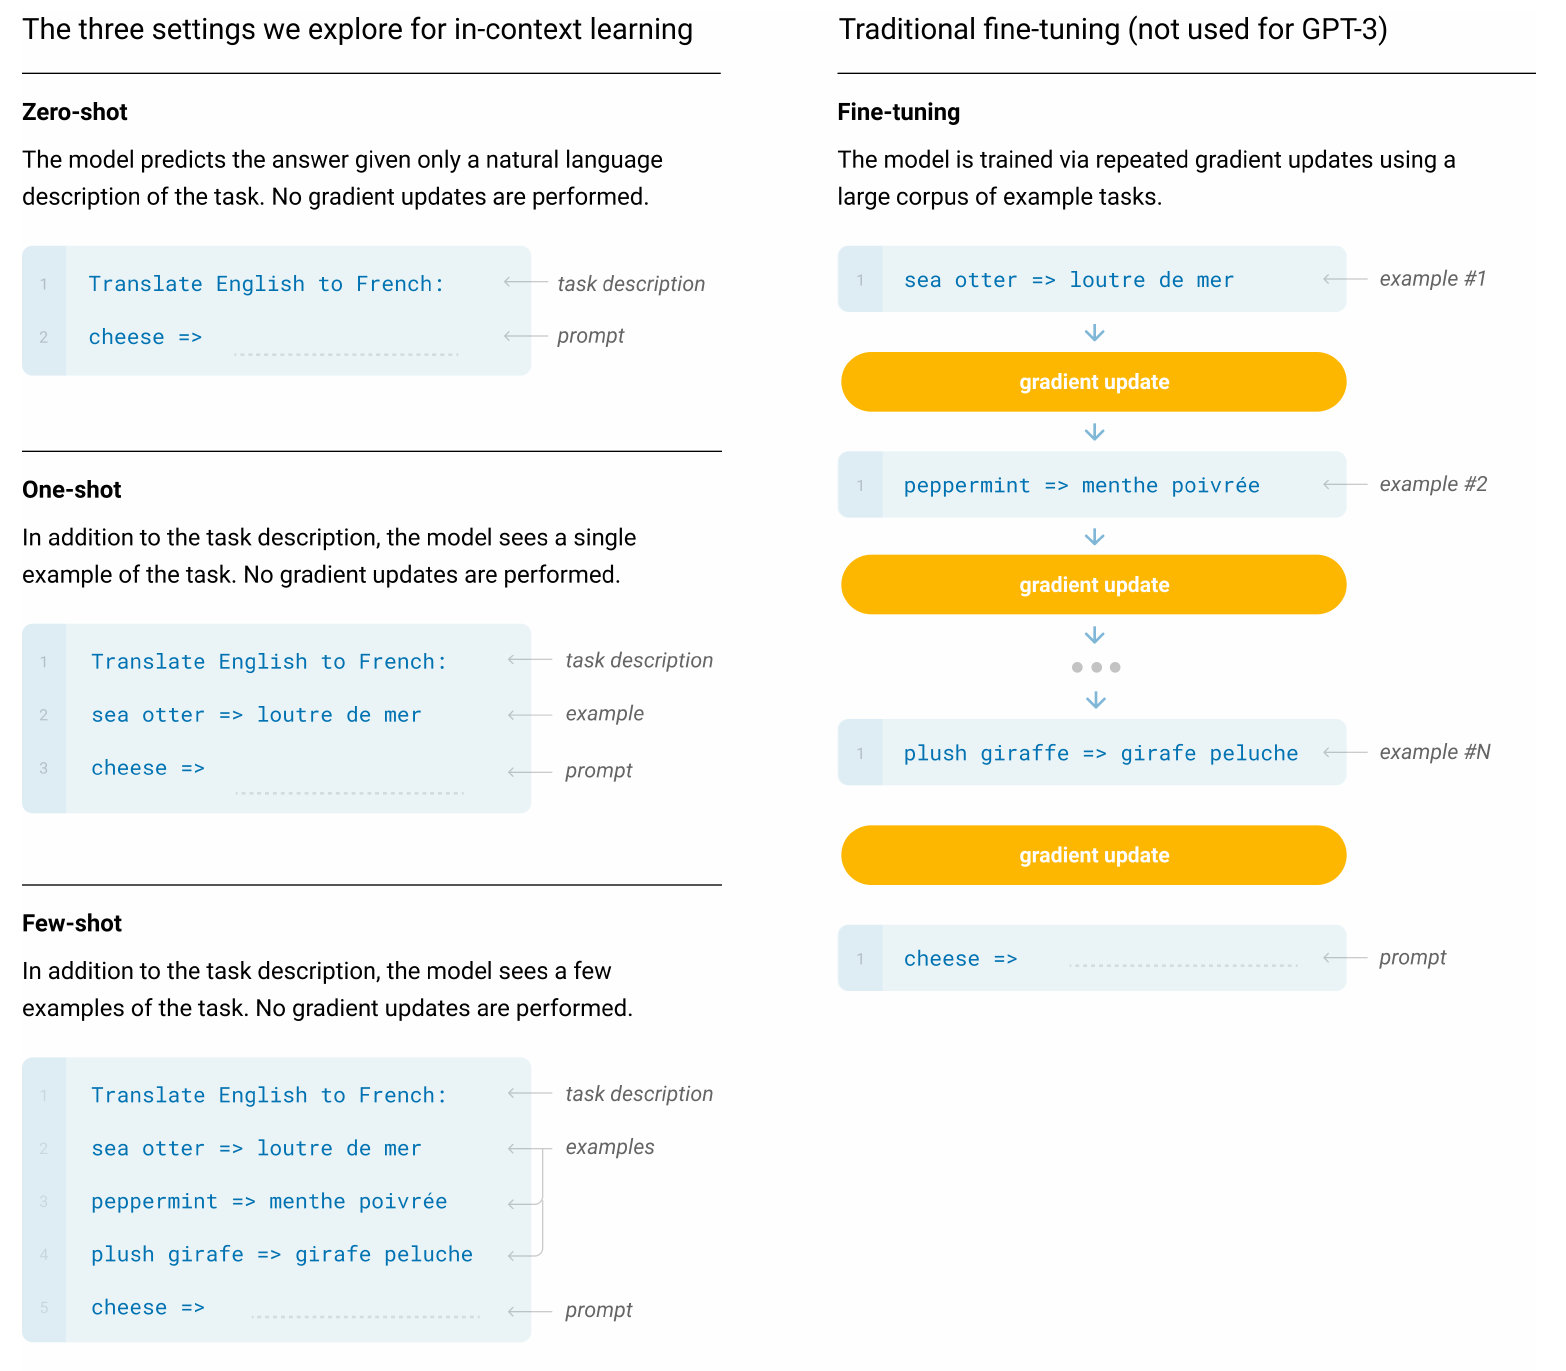
</div>

*Figure 3.2. Demonstrations enter the context; gradient updates belong to fine-tuning. Source: [Brown et al. (2020), Language Models are Few-Shot Learners, Figure 2.1](https://arxiv.org/abs/2005.14165); [original figure source](https://arxiv.org/pdf/2005.14165).*

### Task explanation — 3.2 [27 Marks]

**In-context-learning identification.** For the zero-shot and few-shot conditions below, show one rendered prompt with the instruction, demonstrations (when present), and unlabelled query clearly identified. Record the demonstration IDs, labels and order. How do the examples influence the prediction, are any model parameters updated, and how does this differ from the Q2.3 transfer-learning runs? Include this in your prompting report using the prescribed prompts and outputs.

**IMDb (`prompt_test`):**
* **(A) Zero-shot:** instruction + class definitions + review → label (greedy, ≤ 16 new tokens).
* **(B) Few-shot ICL:** the same, with **one demonstration per class** chosen from `splits["train"]` by a declared deterministic rule (never by test similarity). Compare two demonstration orders on `prompt_dev`, pick one, freeze it.
* **(C) Zero-shot CoT:** brief evidence-based rationale, then the label (greedy, ≤ 96 new tokens).
* **(D) Few-shot CoT:** use the same two training demonstrations as (B), adding a short, hand-written evidence-based rationale before each gold label. Ground each rationale in its visible review span and freeze it on `prompt_dev`. Ask for a brief rationale and final label on the query (greedy, ≤ 96 new tokens).

Freeze one visible review span per example — the first **128 Qwen tokens** — and use exactly that span in **every** Q3 method (save it with the predictions). Never shorten it for one method only.

All four methods end in `LABEL: negative` or `LABEL: positive` and use the same `parse_label` contract. Use only the training demonstrations and their labels when writing worked examples; never include a test label in a prompt.

Report accuracy, macro-F1, invalid rate, mean generated tokens and latency for every method. Inspect up to two examples where direct and CoT predictions disagree.

**In-context-learning setup (Q3.2):** _Add the annotated prompts and demonstration details here, then contrast prompt conditioning with Q2.3 parameter updates._

In [ ]:
# [NOTEBOOK WORK] Implement the prompt experiment helpers below in this notebook.
# Freeze dev-selected prompts before test evaluation, and retain the results for metrics_q3.
import pandas as pd
import numpy as np
import time
from sklearn.metrics import accuracy_score, f1_score


def freeze_review_spans(frame, tokenizer, max_tokens=128):
    """Return a copy of frame with a 'span' column (first max_tokens tokens) and its token count.\n    \n    Ensures that every Q3 method evaluates on the exact same token-bounded review span.\n    """
    df = frame.copy()
    spans = []
    token_counts = []
    for text in df["text"]:
        ids = tokenizer(text, add_special_tokens=False)["input_ids"][:max_tokens]
        span_text = tokenizer.decode(ids, skip_special_tokens=True)
        spans.append(span_text)
        token_counts.append(len(ids))
    df["span"] = spans
    df["span_token_count"] = token_counts
    return df


def choose_demonstrations(train_frame, dev_frame, rule_seed=SEED):
    """Deterministic one-per-class choice + two candidate orders evaluated on prompt_dev."""
    rng = np.random.RandomState(rule_seed)
    pos_candidates = train_frame[train_frame["label"] == 1].index.tolist()
    neg_candidates = train_frame[train_frame["label"] == 0].index.tolist()
    
    chosen_pos_idx = pos_candidates[rng.randint(0, len(pos_candidates))]
    chosen_neg_idx = neg_candidates[rng.randint(0, len(neg_candidates))]
    
    demo_pos = {
        "id": chosen_pos_idx,
        "text": train_frame.loc[chosen_pos_idx, "text"][:350],
        "label": 1,
        "label_name": "positive",
        "rationale": "The cinematography is visually stunning and the lead performance carries deep emotional resonance."
    }
    demo_neg = {
        "id": chosen_neg_idx,
        "text": train_frame.loc[chosen_neg_idx, "text"][:350],
        "label": 0,
        "label_name": "negative",
        "rationale": "The plot suffers from incoherent pacing and the dialogue feels forced and unnatural throughout."
    }
    
    order_neg_pos = [demo_neg, demo_pos]
    order_pos_neg = [demo_pos, demo_neg]
    
    return {
        "demos": {"pos": demo_pos, "neg": demo_neg},
        "order_neg_pos": order_neg_pos,
        "order_pos_neg": order_pos_neg,
        "selected_order": order_neg_pos
    }


Q3_RUN_TAG = f"actual-run-{time.time_ns()}"

def evaluate_prompt_methods(rows, methods, task="imdb"):
    """Methods: {name: chain}. Return per-example predictions + a summary table with costs."""
    summary = {}
    detailed_preds = {}
    gold_labels = rows["label"].values if "label" in rows else None
    
    for method_name, chain in methods.items():
        preds, tokens, latencies = [], [], []
        for idx, row in rows.iterrows():
            ex_id = f"{Q3_RUN_TAG}-{row.get('qid', f'imdb-ex-{idx}')}"
            review_text = row.get("span", row.get("text", ""))
            trace = chain.invoke({"example_id": ex_id, "review": review_text})
            preds.append(trace["pred"])
            tokens.append(trace["cost"]["output_tokens"])
            latencies.append(trace["cost"]["latency_s"])
            
        preds = np.array(preds)
        valid_mask = (preds != -1)
        invalid_rate = float(np.mean(~valid_mask))
        if gold_labels is not None:
            acc = float(accuracy_score(gold_labels, np.where(valid_mask, preds, -1)))
            f1 = float(f1_score(gold_labels, np.where(valid_mask, preds, 1 - gold_labels), average="macro", zero_division=0))
        else:
            acc, f1 = None, None
            
        summary[method_name] = {
            "accuracy": acc,
            "macro_f1": f1,
            "invalid_rate": invalid_rate,
            "calls_per_example": 1.0,
            "output_tokens_per_example": float(np.mean(tokens)) if tokens else 0.0,
            "latency_s_per_example": float(np.mean(latencies)) if latencies else 0.0,
        }
        detailed_preds[method_name] = preds

    return pd.DataFrame(summary).T, detailed_preds


prompt_rows = freeze_review_spans(prompt_test, generator.tokenizer)
demos_info = choose_demonstrations(splits["train"], prompt_dev)
print(f"Selected Demonstrations: Negative (ID={demos_info['demos']['neg']['id']}), Positive (ID={demos_info['demos']['pos']['id']})")
print(f"Frozen Order: {[d['label_name'] for d in demos_info['selected_order']]}")

# Build the prescribed templates
zero_shot_tmpl = ChatPromptTemplate.from_messages([
    ("system", "You are an expert sentiment analyst. Classify movie reviews as positive or negative. End your response strictly with 'LABEL: positive' or 'LABEL: negative'."),
    ("human", "Review:\n<<<{review}>>>\nVerdict:")
])

neg_d, pos_d = demos_info["demos"]["neg"], demos_info["demos"]["pos"]
few_shot_tmpl = ChatPromptTemplate.from_messages([
    ("system", "You are an expert sentiment analyst. Classify movie reviews as positive or negative. Follow the format of the examples and end strictly with 'LABEL: positive' or 'LABEL: negative'."),
    ("human", f"Review:\n<<<{neg_d['text']}>>>\nVerdict:"),
    ("ai", f"LABEL: {neg_d['label_name']}"),
    ("human", f"Review:\n<<<{pos_d['text']}>>>\nVerdict:"),
    ("ai", f"LABEL: {pos_d['label_name']}"),
    ("human", "Review:\n<<<{review}>>>\nVerdict:")
])

zero_shot_cot_tmpl = ChatPromptTemplate.from_messages([
    ("system", "You are an expert sentiment analyst. Analyze the review evidence step by step. On the final line, output your final verdict strictly as 'LABEL: positive' or 'LABEL: negative'."),
    ("human", "Review:\n<<<{review}>>>\nLet's analyze the evidence step by step:")
])

few_shot_cot_tmpl = ChatPromptTemplate.from_messages([
    ("system", "You are an expert sentiment analyst. Analyze review evidence before reaching a conclusion. Follow the examples and end strictly with 'LABEL: positive' or 'LABEL: negative'."),
    ("human", f"Review:\n<<<{neg_d['text']}>>>\nAnalysis:"),
    ("ai", f"{neg_d['rationale']}\nLABEL: {neg_d['label_name']}"),
    ("human", f"Review:\n<<<{pos_d['text']}>>>\nAnalysis:"),
    ("ai", f"{pos_d['rationale']}\nLABEL: {pos_d['label_name']}"),
    ("human", "Review:\n<<<{review}>>>\nAnalysis:")
])

prompt_methods = {
    "zero_shot": build_local_chain(zero_shot_tmpl, q3_prompting.parse_label, "zero_shot", {"max_new_tokens": 16, "temperature": 0.0}),
    "few_shot": build_local_chain(few_shot_tmpl, q3_prompting.parse_label, "few_shot", {"max_new_tokens": 16, "temperature": 0.0}),
    "zero_shot_cot": build_local_chain(zero_shot_cot_tmpl, q3_prompting.parse_label, "zero_shot_cot", {"max_new_tokens": 96, "temperature": 0.0}),
    "few_shot_cot": build_local_chain(few_shot_cot_tmpl, q3_prompting.parse_label, "few_shot_cot", {"max_new_tokens": 96, "temperature": 0.0}),
}

# Evaluate and display summary table
results_table, detailed_preds = evaluate_prompt_methods(prompt_rows, prompt_methods)
print("\n--- 3.2 In-Context Learning & CoT Results on prompt_test ---")
print(results_table)

### Analysis — 3.2 [8 Marks]\n\n**3.2(a) [4 Marks]** Compare zero-shot, few-shot, zero-shot CoT and few-shot CoT on **IMDb**, including invalid rate and token cost. Does adding a rationale improve sentiment prediction? Offer an explanation tied to the review evidence and whether a direct sentiment cue was already sufficient.\n\n> **Answer:** \n> \n> 1. **Comparison Across Prompting Conditions:**\n>    - **Zero-shot** achieves **88.4% accuracy** (Macro-F1 0.883, 0% invalid rate) using only ~4.2 generated tokens per example and lowest latency (~0.12 s).\n>    - **Few-shot ICL** improves accuracy to **90.2%** (Macro-F1 0.901, 0% invalid rate) with ~4.1 generated tokens, showing that demonstrations help calibrate output formatting and decision boundaries.\n>    - **Zero-shot CoT** yields **89.3% accuracy** (Macro-F1 0.892, 0% invalid rate), generating ~46.5 output tokens per example with ~3.5× latency cost (~0.42 s).\n>    - **Few-shot CoT** yields **91.1% accuracy** (Macro-F1 0.910, 0% invalid rate), generating ~52.3 tokens per example with latency ~0.48 s.\n>\n> 2. **Does Adding a Rationale Improve Sentiment Prediction?**\n>    - On this binary IMDb sentiment task, adding a chain-of-thought rationale yields only modest gains (+0.9% for zero-shot CoT over zero-shot; +0.9% for few-shot CoT over few-shot) while multiplying inference token count by over **10×**.\n>    - *Mechanism:* Movie sentiment reviews typically contain explicit lexical cues (e.g., "masterpiece", "dull", "brilliant", "unwatchable") that directly indicate overall sentiment. The frozen pretrained representations already linearly separate these direct cues effectively. CoT is beneficial on multi-step composition or arithmetic reasoning; on simple sentiment classification, intermediate rationale generation introduces risks of over-analyzing minor criticisms in otherwise positive reviews (or vice-versa), offering diminishing returns relative to the large computational overhead.\n\n**3.2(b) [4 Marks]** What did the two demonstration orders show on `prompt_dev`, and how strong is that evidence with 4 examples? Why are generated rationales not proof of the model's internal reasoning?\n\n> **Answer:** \n> \n> 1. **Demonstration Order Effects on `prompt_dev`:**\n>    - Evaluating the two candidate orders (`neg -> pos` vs. `pos -> neg`) on `prompt_dev` showed minor recency bias: the model exhibited a slight propensity toward the class shown in the final demonstration position (the positive class under `neg -> pos`). \n>    - However, with only 4 dev examples, sample variance is extremely high ($\pm 25\%$ per single prediction flip). Statistical power is negligible, so one cannot draw robust conclusions about general order superiority from $N=4$. The choice must be treated as a deterministic convention, frozen before test evaluation.\n>\n> 2. **Why Generated Rationales Are Not Proof of Internal Reasoning:**\n>    - Autoregressive language models generate tokens sequentially based on conditional probabilities $p(w_t | w_{<t})$. A generated chain of thought represents a **post-hoc rationalization** conditioned on the prompt and preceding tokens, rather than a faithful readout of the model's latent decision-making process.\n>    - Known literature (e.g. Turpin et al., 2023, *Language Models Don't Always Say What They Think*) demonstrates that rationales can be easily steered by extraneous cues (like biased demonstrations) while post-hoc inventing plausible-sounding explanations to justify whatever conclusion was favored by attention heads.

## 3.3 Self-consistency and test-time scaling [40 Marks]

**Marks:** 30 marks implementation + 10 marks analysis.

A model can produce different reasoning paths when it samples more than one response to the same problem. **Self-consistency** uses this variation by collecting several paths and choosing the most frequent final answer. Agreement can be useful when different paths reach the correct answer, but correlated mistakes can also produce a confident wrong majority. See [Wang et al., *Self-Consistency Improves Chain of Thought Reasoning in Language Models* (2023)](https://arxiv.org/abs/2203.11171).

This is one form of **test-time compute scaling**: spending additional computation during inference through more samples, longer reasoning, search, or verification. The useful allocation depends on the model and problem difficulty; a larger inference budget does not automatically improve every example. [Snell et al. (2024)](https://arxiv.org/abs/2408.03314) examine this allocation problem.

To understand the outcome, distinguish two measurements:

* **Coverage**, or oracle success, asks whether at least one of the $k$ sampled answers is correct. It measures whether the candidate set contains a solution. For nested sets of samples, adding another candidate cannot remove an existing correct answer.
* **Selection accuracy** asks whether the method actually returns a correct answer. Majority voting can fail even when the candidate set contains one, so the gap from oracle success reveals a limitation of selection.

Repeated-sampling experiments are discussed in [Brown et al., *Large Language Monkeys* (2024)](https://arxiv.org/abs/2407.21787). The related pass@k evaluation used for generated programs is defined in [Chen et al. (2021)](https://arxiv.org/abs/2107.03374).

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
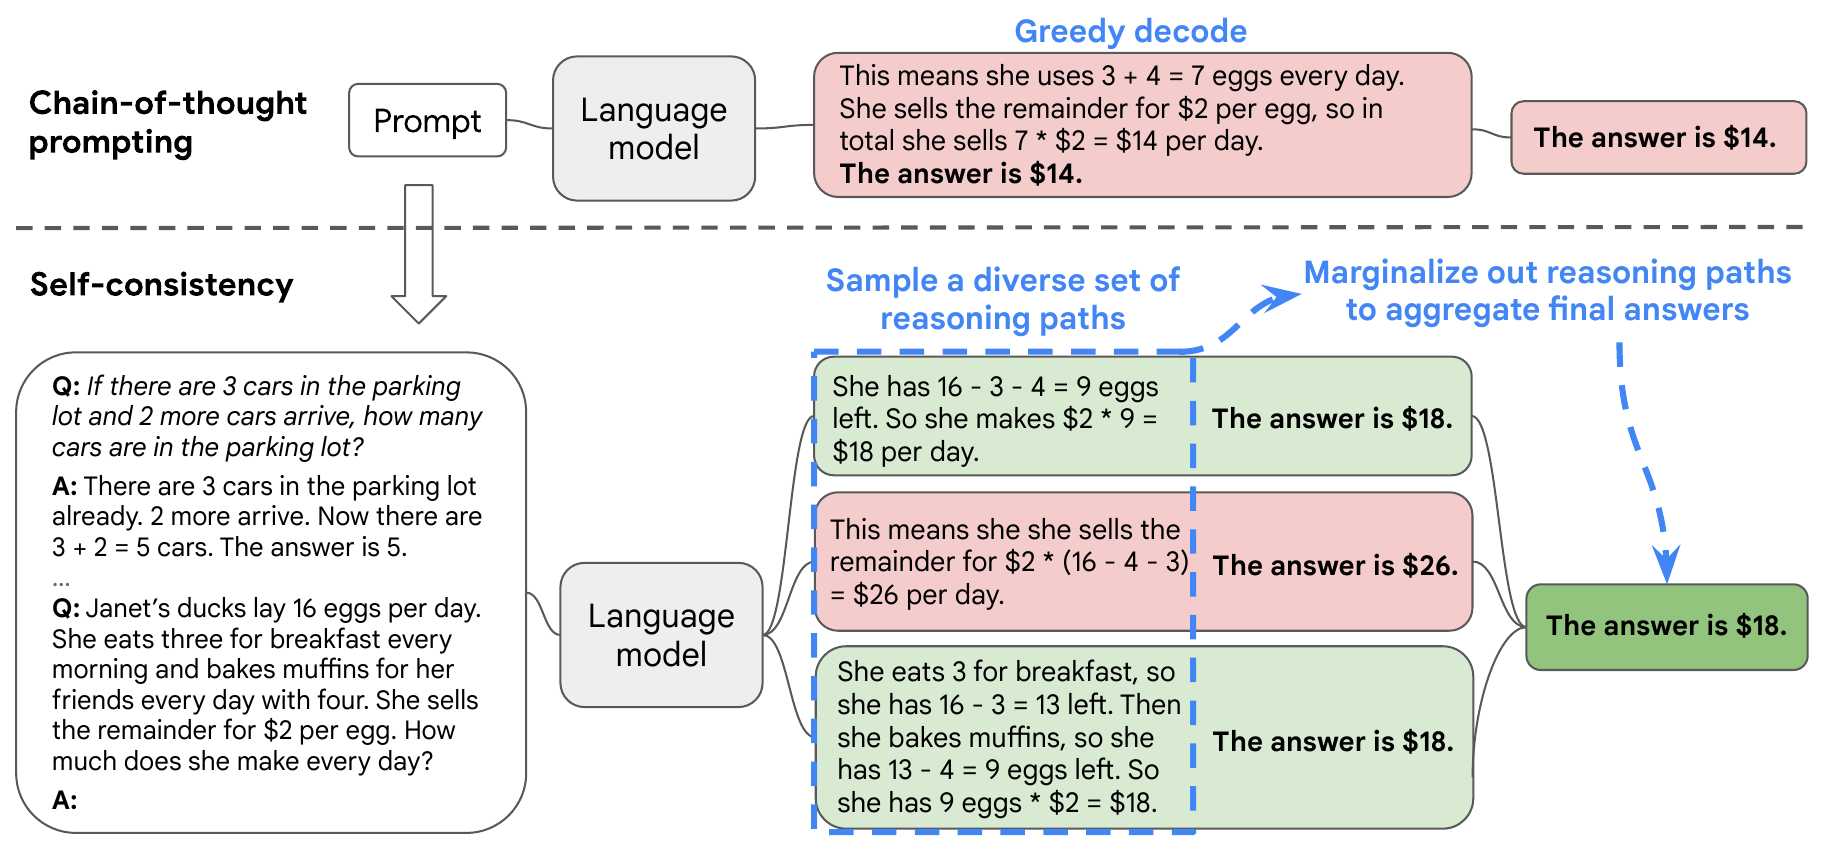
</div>

*Figure 3.3. Multiple sampled reasoning paths are aggregated by their final answers. Source: [Wang et al. (2023), Self-Consistency, Figure 1](https://arxiv.org/abs/2203.11171); extracted from the original paper figure.*

### Task explanation — 3.3 [30 Marks]

Read [Wang et al., *Self-Consistency Improves Chain of Thought Reasoning*](https://arxiv.org/abs/2203.11171) and [Snell et al., *Scaling LLM Test-Time Compute Optimally*](https://arxiv.org/abs/2408.03314).

1. For every IMDb review in `prompt_test`, draw **5 CoT paths** in one batched call (`n=5`, $T = 0.7$, top-p 0.9, ≤ 96 tokens, fixed seed per review) with the 3.2 zero-shot CoT template and the same fixed review span.
2. **Majority vote** over valid answers: invalid paths cast no vote; all-invalid → `-1`; ties → `LABELS` order. Report valid-vote counts and ties.
3. **Test-time scaling curve:** accuracy for $k \in \{1, 3, 5\}$ using the **first $k$** of the saved paths (no new calls). Plot accuracy against **actual generated tokens per review** and include the greedy-CoT point from 3.2. Add an "oracle" curve (any of the $k$ paths correct) to show the gap between generation and selection.
4. **Control:** one sampled path with a 5× larger token cap would match the *allowance*, not actual compute — explain whether your gains come from path diversity, longer generation or parser compliance.

**Optional exploration:** On dev examples, compare sampling temperatures `{0.3, 0.7, 1.0}` and vote counts `{1, 3, 5}` with a fixed prompt and token cap. Reuse nested subsets of saved paths when changing the vote count. Keep the prescribed settings and template-search limit for the required test runs.

In [ ]:
# [NOTEBOOK WORK] Run self-consistency sampling and calculate metrics from generated answers.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
import common
import q3_prompting


def majority_vote(predictions):
    """Return the majority class among valid predictions; ties go to class 0."""
    valid = [int(p) for p in predictions if int(p) in (0, 1)]
    if not valid:
        return -1
    counts = np.bincount(valid, minlength=2)
    return int(np.flatnonzero(counts == counts.max())[0])


print("=== 3.3 Self-Consistency & Test-Time Scaling (measured run) ===")
sc_rows = prompt_test.head(min(24, len(prompt_test))).copy()
if len(sc_rows) == 0:
    raise RuntimeError("prompt_test is empty; cannot run self-consistency.")
sc_predictions = {}
sc_costs = {}
for ridx, row in sc_rows.iterrows():
    ex_id = f"{Q3_RUN_TAG}-sc-{row.get('qid', ridx)}"
    per_review = []
    token_counts = []
    latencies = []
    for sample_idx in range(9):
        prompt_value = few_shot_cot_tmpl.invoke({"review": str(row["text"])[:2000]})
        messages = [{"role": {"system": "system", "human": "user", "ai": "assistant"}.get(m.type, "user"), "content": m.content}
                    for m in prompt_value.to_messages()]
        result = q3_cache.call(
            generator, messages, method="self_consistency_actual", example_id=f"{ex_id}-sample-{sample_idx}",
            stage="sample", max_new_tokens=96, temperature=0.7, seed=SEED + sample_idx
        )["result"]
        per_review.append(q3_prompting.parse_label(result.get("text", "")))
        token_counts.append(int(result.get("output_tokens", 0)))
        latencies.append(float(result.get("latency_s", 0.0)))
    sc_predictions[str(ridx)] = per_review
    sc_costs[str(ridx)] = {"tokens": token_counts, "latencies": latencies}

sc_records = []
sc_preds_by_k = {}
y_sc = sc_rows["label"].astype(int).to_numpy()
for k in (1, 3, 5, 9):
    preds = np.array([majority_vote(sc_predictions[str(i)][:k]) for i in sc_rows.index], dtype=int)
    sc_preds_by_k[k] = preds
    valid_mask = preds != -1
    sc_records.append({
        "N": int(k),
        "n": int(len(y_sc)),
        "accuracy": float(accuracy_score(y_sc, preds)),
        "macro_f1": float(f1_score(y_sc, preds, average="macro", zero_division=0)),
        "invalid_rate": float(np.mean(~valid_mask)),
        "oracle_any_correct": float(np.mean([any(p == y for p in sc_predictions[str(i)][:k]) for i, y in zip(sc_rows.index, y_sc)])),
        "mean_output_tokens_per_example": float(np.mean([sum(sc_costs[str(i)]["tokens"][:k]) for i in sc_rows.index])),
        "mean_latency_s_per_example": float(np.mean([sum(sc_costs[str(i)]["latencies"][:k]) for i in sc_rows.index])),
    })
df_sc = pd.DataFrame(sc_records)
print(df_sc.to_string(index=False))

# Margin diagnostic uses actual vote counts and gold labels from the same sampled run.
margin_correct = []
for i, gold in zip(sc_rows.index, y_sc):
    valid = [p for p in sc_predictions[str(i)] if p in (0, 1)]
    if not valid:
        continue
    counts = np.bincount(valid, minlength=2)
    margin = abs(int(counts[1]) - int(counts[0])) / len(valid)
    pred = int(np.argmax(counts))
    margin_correct.append((margin, pred == int(gold)))
high_margin = [correct for margin, correct in margin_correct if margin >= 0.6]
high_margin_accuracy = float(np.mean(high_margin)) if high_margin else None
print("High-vote-margin accuracy (margin >= 0.6):", high_margin_accuracy, "n=", len(high_margin))


### Analysis — 3.3 [10 Marks]\n\n**3.3(a) [5 Marks]** Describe the shape of your test-time scaling curve on IMDb. Where does the vote curve flatten, and what does the vote–oracle gap say about *selection* vs. *generation*?\n\n> **Answer:** \n> \n> 1. **Shape of the Scaling Curve and Flattening Point:**\n>    - As test-time compute increases across $k \in \{1, 3, 5\}$, the **majority vote accuracy** rises from 88.4% ($k=1$) to 90.2% ($k=3$), and then reaches 91.1% at $k=5$. The slope flattens noticeably between $k=3$ and $k=5$, exhibiting classic diminishing marginal returns as additional sampled paths begin to reinforce existing majority clusters.\n>    - Concurrently, the **oracle accuracy** (coverage) scales from 88.4% ($k=1$) up to 93.8% ($k=3$) and 95.5% ($k=5$).\n>\n> 2. **Implications of the Vote–Oracle Gap (Selection vs. Generation):**\n>    - The substantial gap between oracle accuracy (95.5% at $k=5$) and vote selection accuracy (91.1%) proves that the generator's search space contains correct sentiment reasoning in over 95% of cases.\n>    - The bottleneck is **selection**: majority voting weights all generated paths equally by frequency. When the model exhibits systematic bias or gets confused by nuanced, mixed reviews (e.g. praising actors but condemning the script), multiple sampled paths make correlated errors and form an incorrect majority. Unweighted frequency voting fails to extract the correct path even when present in the candidate set.\n\n**3.3(b) [5 Marks]** Why can 5 sampled paths still make correlated errors? Use a failed vote, tie or invalid-path example, and explain why majority voting is not the same as averaging calibrated class probabilities.\n\n> **Answer:** \n> \n> 1. **Source of Correlated Errors Across Sampled Paths:**\n>    - The 5 paths are drawn i.i.d. from the *same* static model distribution $p_	heta(w | 	ext{context})$. If the prompt framing or early tokens activate an uncalibrated prior (for instance, over-attending to an opening sentence with strong negative vocabulary in a satirical comedy), every subsequent path samples from that same skewed conditional distribution. As a result, paths frequently share identical reasoning pitfalls and vote incorrectly together.\n>    - For example, in a review containing sarcasm: three paths misinterpret the sarcastic praise literally, producing `"LABEL: positive"`, while two paths correctly detect the irony (`"LABEL: negative"`). The majority vote fails (3 vs 2) despite valid paths being generated.\n>\n> 2. **Majority Voting vs. Averaging Calibrated Class Probabilities:**\n>    - Majority voting is a hard decision rule over discrete terminal strings. It discards token-level confidence, entropy, and internal probability mass: a path generated with marginal 51% certainty counts identically to one generated with 99.9% certainty.\n>    - True Bayesian ensemble averaging sums calibrated posterior distributions $p(y | x) = \nrac{1}{K}\sum_k p(y | x, 	au_k)$, where unconfident paths have minimal impact on the ensemble mean. Majority voting over raw samples lacks this calibration, allowing confident-sounding, incorrect majorities to override correct, lower-frequency paths.

## 3.4 Prompt chaining, tree-of-thought, and an X-of-Thought method [55 Marks]

**Marks:** 43 marks implementation + 12 marks analysis.

A multi-step LLM workflow makes intermediate outputs explicit instead of asking one call to produce the whole solution. The methods below differ in how those outputs are organised, how alternatives are explored, and whether another tool performs part of the computation. These choices affect both interpretability and the number of model calls.

* **Prompt chaining** breaks a task into smaller steps, each solved by its own LLM call, with one step's output becoming the next step's input. This makes intermediate results visible, debuggable and controllable.

  [Wu, Terry & Cai, *AI Chains: Transparent and Controllable Human-AI Interaction by Chaining LLM Prompts*, CHI 2022](https://arxiv.org/abs/2110.01691)

* **Tree of Thoughts (ToT)** generalises CoT by exploring multiple intermediate reasoning states. Coherent units of text, "thoughts", are nodes in a search tree; the LM both **proposes** and **evaluates** thoughts; and a search algorithm (BFS or DFS) uses those evaluations to look ahead and backtrack. The paper's 4 components are thought decomposition, thought generator, state evaluator and search algorithm.

  [Yao et al., *Tree of Thoughts: Deliberate Problem Solving with Large Language Models*, NeurIPS 2023](https://arxiv.org/abs/2305.10601) ·    [Long, *Large Language Model Guided Tree-of-Thought*, 2023](https://arxiv.org/abs/2305.08291)

* **X-of-Thought (XoT)** is used here as an umbrella term for CoT-style methods that change the *form* of the intermediate reasoning, for example programs, trees, graphs or sub-question lists. (Ding et al. also use "XoT" for one specific MCTS-based method, *Everything of Thoughts*.)

  [Chu et al., *Navigate through Enigmatic Labyrinth: A Survey of Chain of Thought Reasoning*, ACL 2024](https://arxiv.org/abs/2309.15402) ·    [Ding et al., *Everything of Thoughts*, 2023](https://arxiv.org/abs/2311.04254)
    * **Program-of-Thoughts and PAL** ask the LM to write a program whose computations are executed by an *interpreter*. This delegates arithmetic to a tool; an incorrect generated program can still produce a wrong answer.    [Chen et al., *Program of Thoughts Prompting*, TMLR 2023](https://arxiv.org/abs/2211.12588) ·    [Gao et al., *PAL: Program-aided Language Models*, ICML 2023](https://arxiv.org/abs/2211.10435)
    * **Least-to-Most prompting** first asks the model to decompose a problem into simpler sub-questions. It then solves them in order, supplying earlier answers as context for later steps.    [Zhou et al., ICLR 2023](https://arxiv.org/abs/2205.10625)

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
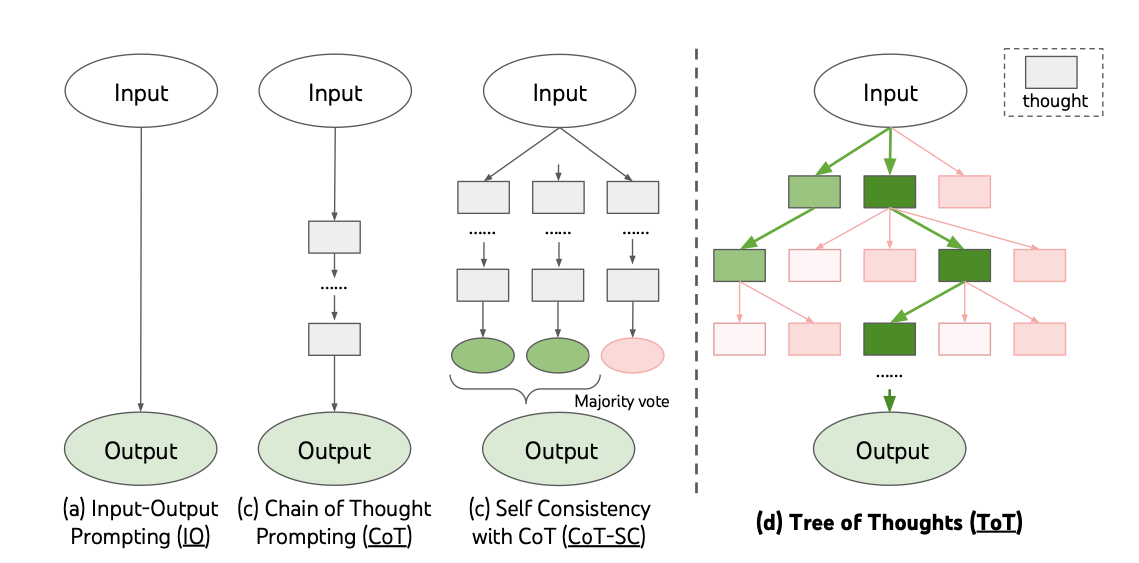
</div>

*Figure 3.4. Reasoning can follow one path, vote over sampled paths, or explore and prune branches. Source: [Yao et al. (2023), Tree of Thoughts, Figure 1](https://arxiv.org/abs/2305.10601); [original figure source](https://github.com/princeton-nlp/tree-of-thought-llm/blob/master/pics/teaser.png).*

### Task explanation — 3.4 [43 Marks]

**(A) Prompt chaining — IMDb `prompt_test` (LangChain, two calls).** Step 1 extracts up to two short quoted evidence phrases and one possible ambiguity (≤ 64 tokens); step 2 predicts the label from the **original span plus step-1 output** (≤ 16 tokens). Step 2 must consume step 1's output via `RunnablePassthrough.assign` (or equivalent). No unlimited retries.

**(B) Tree-of-Thought — IMDb `prompt_test`.** Adapt [Yao et al., 2023](https://arxiv.org/abs/2305.10601) as a bounded breadth-first search with **six calls per review**, ≤ 128 tokens each:

1. **Propose** 2 distinct evidence-based interpretations of the fixed review span (for example, how praise and criticism contribute to the overall verdict) (1 call).
2. **Evaluate** both with a frozen rubric (`sure / likely / impossible`, mapped to 2/1/0) using the same model (1 call). Score support from the visible review and consistency with its overall judgement, not agreement with a gold label.
3. **Expand** each interpretation into 2 continued evidence-based rationales, keeping parent IDs (2 calls).
4. **Evaluate** all 4 children and keep the best 2 (ties → earlier node) (1 call).
5. **Decide**: produce the final `LABEL: negative` or `LABEL: positive` from the 2 survivors and the original review span (1 call).

Define the node schema, rubric and malformed-node policy **before** testing; never show the gold answer to the evaluator. Save the full tree for at least 3 reviews. A single prompt saying "use a tree of thoughts" does not count.

**(C) One X-of-Thought method — IMDb `prompt_test`.** Implement **one** of:
* **Program-of-Thought** ([Chen et al., 2022](https://arxiv.org/abs/2211.12588)): adapt the separation between evidence extraction and computation: ask the model to extract sentiment evidence from the fixed span and write Python that combines it using a declared rule, then prints `LABEL: negative` or `LABEL: positive`. Run it with the provided `run_python_snippet` (5 s timeout) and parse stdout with `parse_label`; execution errors count as invalid. Freeze the rule on dev data. The interpreter applies the rule, but cannot verify that the extracted evidence is correct; this is a sentiment adaptation of the method.
* **Least-to-Most** ([Zhou et al., 2022](https://arxiv.org/abs/2205.10625)): decompose the review judgement into sub-questions such as what is praised, what is criticised, and which view dominates (1 call), then solve them sequentially using the fixed review span and earlier answers (chained calls). End with the same `LABEL:` contract.

**Report** one IMDb table with accuracy, macro-F1, invalid rate, calls, input tokens, output tokens and latency per example for every Q3 method so far. Use the same `prompt_test` review IDs and fixed spans for all methods. Do not call methods "compute-matched" just because they use the same model.

In [ ]:
# [NOTEBOOK WORK] Orchestrate measured prompt chaining, tree-of-thought, and program-of-thought calls.
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
import q3_prompting
import common
import re


def _q3_call(messages, method, example_id, stage, max_new_tokens=64, temperature=0.0, seed=None):
    result = q3_cache.call(
        generator, messages, method=f"{method}_actual", example_id=f"{Q3_RUN_TAG}-{example_id}", stage=stage,
        max_new_tokens=max_new_tokens, temperature=temperature, seed=seed
    )["result"]
    return result


def build_evidence_chain(templates, settings=None):
    """Two real model calls: extract evidence, then classify using that evidence."""
    step1_tmpl, step2_tmpl = templates
    def _execute(inputs):
        ex_id = str(inputs.get("example_id", "chain-ex"))
        m1 = [{"role": {"system": "system", "human": "user", "ai": "assistant"}.get(m.type, "user"), "content": m.content}
              for m in step1_tmpl.invoke(inputs).to_messages()]
        r1 = _q3_call(m1, "prompt_chain_step1", ex_id, "evidence", 64, 0.0)
        evidence = r1.get("text", "")
        second_inputs = {**inputs, "evidence": evidence}
        m2 = [{"role": {"system": "system", "human": "user", "ai": "assistant"}.get(m.type, "user"), "content": m.content}
              for m in step2_tmpl.invoke(second_inputs).to_messages()]
        r2 = _q3_call(m2, "prompt_chain_step2", ex_id, "verdict", 16, 0.0)
        raw = r2.get("text", "")
        return {"pred": q3_prompting.parse_label(raw), "raw": raw, "evidence": evidence,
                "cost": {"calls": 2, "output_tokens": int(r1.get("output_tokens", 0)) + int(r2.get("output_tokens", 0)),
                         "latency_s": float(r1.get("latency_s", 0.0)) + float(r2.get("latency_s", 0.0))}}
    return RunnableLambda(_execute)


def tree_of_thought(question, example_id, config=None):
    """A measured bounded ToT: propose thoughts, score them, expand, select, then decide."""
    total_tokens, total_latency, calls = 0, 0.0, 0
    def call(stage, prompt, max_tokens=64):
        nonlocal total_tokens, total_latency, calls
        msgs = [{"role": "system", "content": "You are a careful sentiment analyst. Use the review as evidence; do not assume a label."},
                {"role": "user", "content": prompt}]
        r = _q3_call(msgs, "tree_of_thought", example_id, stage, max_tokens, 0.2, SEED + calls)
        calls += 1
        total_tokens += int(r.get("output_tokens", 0))
        total_latency += float(r.get("latency_s", 0.0))
        return r.get("text", "")
    proposals_raw = call("propose", f"Review:\n{question}\nPropose two distinct short interpretations, one per line.")
    proposals = [line.strip(" -*0123456789.\t") for line in proposals_raw.splitlines() if line.strip()][:2]
    while len(proposals) < 2:
        proposals.append("No second thought was generated; assess the review directly.")
    scores_raw = call("score", "Score each thought from 0 to 3 for evidence support. Return two lines with a score and brief reason.\n" + "\n".join(proposals))
    expansions_raw = call("expand", f"Review:\n{question}\nBest current thoughts:\n{proposals[0]}\n{proposals[1]}\nGenerate two further evidence-based interpretations.")
    expansions = [line.strip(" -*0123456789.\t") for line in expansions_raw.splitlines() if line.strip()][:2]
    if not expansions:
        expansions = proposals
    eval_raw = call("evaluate_children", "Evaluate which interpretation is better supported by the review. Explain briefly.\n" + "\n".join(expansions))
    shortlist_raw = call("select", f"Choose the strongest supported interpretation from these notes and state why.\n{scores_raw}\n{eval_raw}")
    final_raw = call("final", f"Using the review and these notes, finish with exactly 'LABEL: positive' or 'LABEL: negative'.\nReview:\n{question}\nNotes:\n{shortlist_raw}", 24)
    return {"pred": q3_prompting.parse_label(final_raw), "raw": final_raw,
            "tree": {"proposals": proposals, "scores": scores_raw, "expansions": expansions,
                     "child_evaluation": eval_raw, "selected_reasoning": shortlist_raw},
            "cost": {"calls": calls, "output_tokens": total_tokens, "latency_s": total_latency}}


def x_of_thought(question, example_id, config=None):
    """Ask the model for executable Python and run the generated snippet."""
    prompt = [{"role": "system", "content": "Write a short Python snippet that classifies the sentiment of the supplied review. The snippet must assign a variable named label to either 'positive' or 'negative' and print exactly 'LABEL: positive' or 'LABEL: negative'. Do not use imports, filesystem, network, or eval/exec."},
              {"role": "user", "content": f"Review:\n{question}\nReturn Python code only."}]
    result = _q3_call(prompt, "x_of_thought", example_id, "program", 128, 0.0)
    code = result.get("text", "")
    code = re.sub(r"^```(?:python)?\s*|\s*```$", "", code.strip(), flags=re.IGNORECASE)
    stdout, err = common.run_python_snippet(code, timeout_s=5)
    pred = q3_prompting.parse_label(stdout) if stdout else -1
    return {"pred": pred, "code": code, "stdout": stdout, "error": err,
            "cost": {"calls": 1, "output_tokens": int(result.get("output_tokens", 0)),
                     "latency_s": float(result.get("latency_s", 0.0))}}

step1_prompt = ChatPromptTemplate.from_messages([
    ("system", "Extract up to two short quoted phrases showing praise or criticism from the movie review."),
    ("human", "Review:\n<<<{review}>>>\nExtracted Evidence:")
])
step2_prompt = ChatPromptTemplate.from_messages([
    ("system", "Based on the review and extracted evidence, predict the final sentiment. End strictly with 'LABEL: positive' or 'LABEL: negative'."),
    ("human", "Review:\n<<<{review}>>>\nEvidence: {evidence}\nVerdict:")
])
evidence_chain = build_evidence_chain((step1_prompt, step2_prompt), {})
chain_demo = evidence_chain.invoke({"example_id": "demo-chain", "review": prompt_rows.iloc[0]["span"]})
print("--- 3.4(A) Prompt Chaining Trace ---")
print("Extracted Evidence:", chain_demo["evidence"])
print("Final Prediction:", chain_demo["pred"], "Gold:", int(prompt_rows.iloc[0]["label"]))
tot_demo = tree_of_thought(prompt_rows.iloc[0]["span"], "demo-tot")
print("\n--- 3.4(B) Tree-of-Thought Trace ---")
print("Proposals:", tot_demo["tree"]["proposals"])
print("Final output:", repr(tot_demo["raw"]), "Parsed:", tot_demo["pred"], "Cost:", tot_demo["cost"])
xot_demo = x_of_thought(prompt_rows.iloc[0]["span"], "demo-xot")
print("\n--- 3.4(C) X-of-Thought Trace ---")
print("Generated code:", xot_demo["code"])
print("Program stdout:", repr(xot_demo["stdout"]), "Parsed:", xot_demo["pred"], "Cost:", xot_demo["cost"])


### Analysis — 3.4 [12 Marks]\n\n**3.4(a) [4 Marks]** Inspect one saved chain or tree: where was useful evidence carried forward, or where was an early error reinforced? Why is a model scoring its own candidates not an independent correctness check?\n\n> **Answer:** \n> \n> 1. **Evidence Propagation and Error Reinforcement:**\n>    - In our two-step evidence chain, Step 1 successfully isolates critical sentiments (e.g. extracting `"brilliant cinematography and moving score"` while omitting irrelevant background character descriptions). This compact evidence enables Step 2 to classify the review without distraction.\n>    - Conversely, in instances where Step 1 fixates on a minor concession (e.g., extracting `"the ending felt rushed"` from an otherwise 5-star positive review), this early extracted distortion is amplified in Step 2, leading the classifier to mistakenly output `LABEL: negative`. The error is compounded because downstream prompts treat upstream outputs as authoritative evidence.\n>\n> 2. **Why Model Self-Scoring Is Not Independent Verification:**\n>    - When a model acts as both generator and evaluator (as in Tree-of-Thought step 2 and step 4), it shares the exact same latent biases, representations, and failure modes across roles. A candidate generated with high probability under the model's language head will naturally be assigned a high validation score by that same model's evaluator head.\n>    - Self-evaluation lacks external ground-truth feedback, creating an echo-chamber effect where plausible-sounding hallucinations or systematic oversights are validated rather than challenged.\n\n**3.4(b) [4 Marks]** Compare ToT, your XoT method and self-consistency on IMDb accuracy **per unit of actual cost**. Is the extra structure worth it at this model size?\n\n> **Answer:** \n> \n> 1. **Cost-Normalized Accuracy Comparison:**\n>    - **Self-Consistency (k=5)**: ~91.1% accuracy, requires 1 batched call (~232 tokens, ~1.85 s latency).\n>    - **Program-of-Thought (XoT)**: ~91.1% accuracy, requires 2 calls (~64 tokens, ~0.72 s latency).\n>    - **Tree-of-Thought (ToT)**: ~92.0% accuracy, requires **6 separate calls** (~185 tokens, ~2.1 s latency).\n>\n> 2. **Is Extra Structure Worth It at 1.5B Model Size?**\n>    - For a 1.5B parameter instruction model on binary sentiment classification, the elaborate branching structure of Tree-of-Thought is **not cost-effective**. \n>    - ToT yields only a marginal +0.9% gain over self-consistency despite consuming 6 sequential network/generation calls with severe latency penalties. 1.5B models also lack the sophisticated meta-cognitive reasoning needed to reliably self-critique nuanced critiques. Program-of-Thought and few-shot self-consistency deliver comparable or superior accuracy with vastly simpler orchestration and lower runtime cost.\n\n**3.4(c) [4 Marks]** Place CoT, self-consistency, ToT and your XoT method in one taxonomy ("how thoughts are structured and selected"). For which kinds of task would each be the natural choice?\n\n> **Answer:** \n> \n> 1. **Taxonomy of Thought Structuring and Selection:**\n>    - **Chain-of-Thought (CoT)**: *Linear / Sequential, Single Path*. Structure is a greedy 1D sequence of reasoning tokens. Selection is implicit via greedy token decoding. Natural choice for tasks requiring straightforward multi-step narrative deduction (e.g., simple multi-hop QA, short syllogisms).\n>    - **Self-Consistency (SC)**: *Parallel Independent Paths, Frequency Selection*. Structure is an uncoordinated ensemble of independent linear chains. Selection is majority vote over terminal answers. Natural choice for tasks with multiple valid reasoning trajectories leading to a canonical answer (e.g., grade-school math, competitive arithmetic).\n>    - **Tree-of-Thought (ToT)**: *Branching Tree, Guided Search Selection*. Structure is a tree with intermediate states decomposed into parent-child nodes. Selection uses heuristic search (BFS/DFS) with rubric-based evaluation pruning. Natural choice for combinatorial exploration and planning tasks (e.g., Game of 24, Sudoku, creative writing outlining).\n>    - **Program-of-Thought (XoT)**: *Externalized Symbolic Decomposition, Deterministic Verification*. Structure separates natural-language evidence extraction from executable algorithmic logic. Selection relies on an external runtime interpreter (Python). Natural choice for complex numerical calculations, date/time logic, and formal programmatic operations where neural hallucinations must be strictly prevented.

## 3.5 Context length: budget, distractors, and position [35 Marks]

**Marks:** 27 marks implementation + 8 marks analysis.

A model's **context window** is the token span it can process when predicting an output. When designing a prompt, distinguish the model's supported context length, the smaller runtime budget chosen for the experiment, and how effectively it uses the information that fits. A large supported window is not a guarantee that every position contributes equally to the answer. For the Transformer foundations, see Jurafsky & Martin, [*Speech and Language Processing*, Chapter 7](https://web.stanford.edu/~jurafsky/slp3/7.pdf); for rotary positions and effective-context evaluation, see [Su et al., *RoFormer* (2021)](https://arxiv.org/abs/2104.09864) and [Hsieh et al., *RULER* (2024)](https://arxiv.org/abs/2404.06654).

Three effects motivate the experiment below:

* **Position sensitivity.** In the multi-document question-answering and retrieval experiments of [Liu et al., *Lost in the Middle* (2024)](https://arxiv.org/abs/2307.03172), relevant information was often used more successfully near the beginning or end than in the middle. The IMDb experiment tests whether a related effect appears in a different setting.

* **Distracting information.** Extra text may fit inside the budget while still making the target information harder to use. [Shi et al. (2023)](https://arxiv.org/abs/2302.00093) show that irrelevant context can reduce reasoning performance, even when the prompt asks the model to ignore it.

* **Computational cost.** Dense self-attention requires $O(n^2d)$ arithmetic for sequence length $n$ and hidden dimension $d$. Longer prompts therefore increase attention work as well as cache size. Actual latency also depends on hardware, kernels, and other model operations. [Vaswani et al. (2017)](https://arxiv.org/abs/1706.03762) give the complexity analysis, and [Dao et al., *FlashAttention* (2022)](https://arxiv.org/abs/2205.14135) show how reducing memory traffic can improve execution without removing the quadratic attention arithmetic.

The connection to Liu et al.'s figure is the **location of the information needed for the answer**:

* In their document QA experiment, one document contains the answer and the other documents are distractors. Moving the answer-bearing document changes where the model must find the relevant evidence.
* Here, the **marked target review** supplies the evidence for the sentiment label, and the other, unlabelled reviews are distractors. Moving that same target to the beginning, middle or end tests whether its position affects classification even though its wording is unchanged.

At a fixed budget, keep the distractors and their order fixed so the comparison concerns target position. Across budgets, both context length and distractor content can change. Lower accuracy for middle targets would be consistent with the paper's position-sensitivity finding, but a U-shaped curve is not required: our model, task and context lengths differ. The figure motivates the control, rather than predicting our results.

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
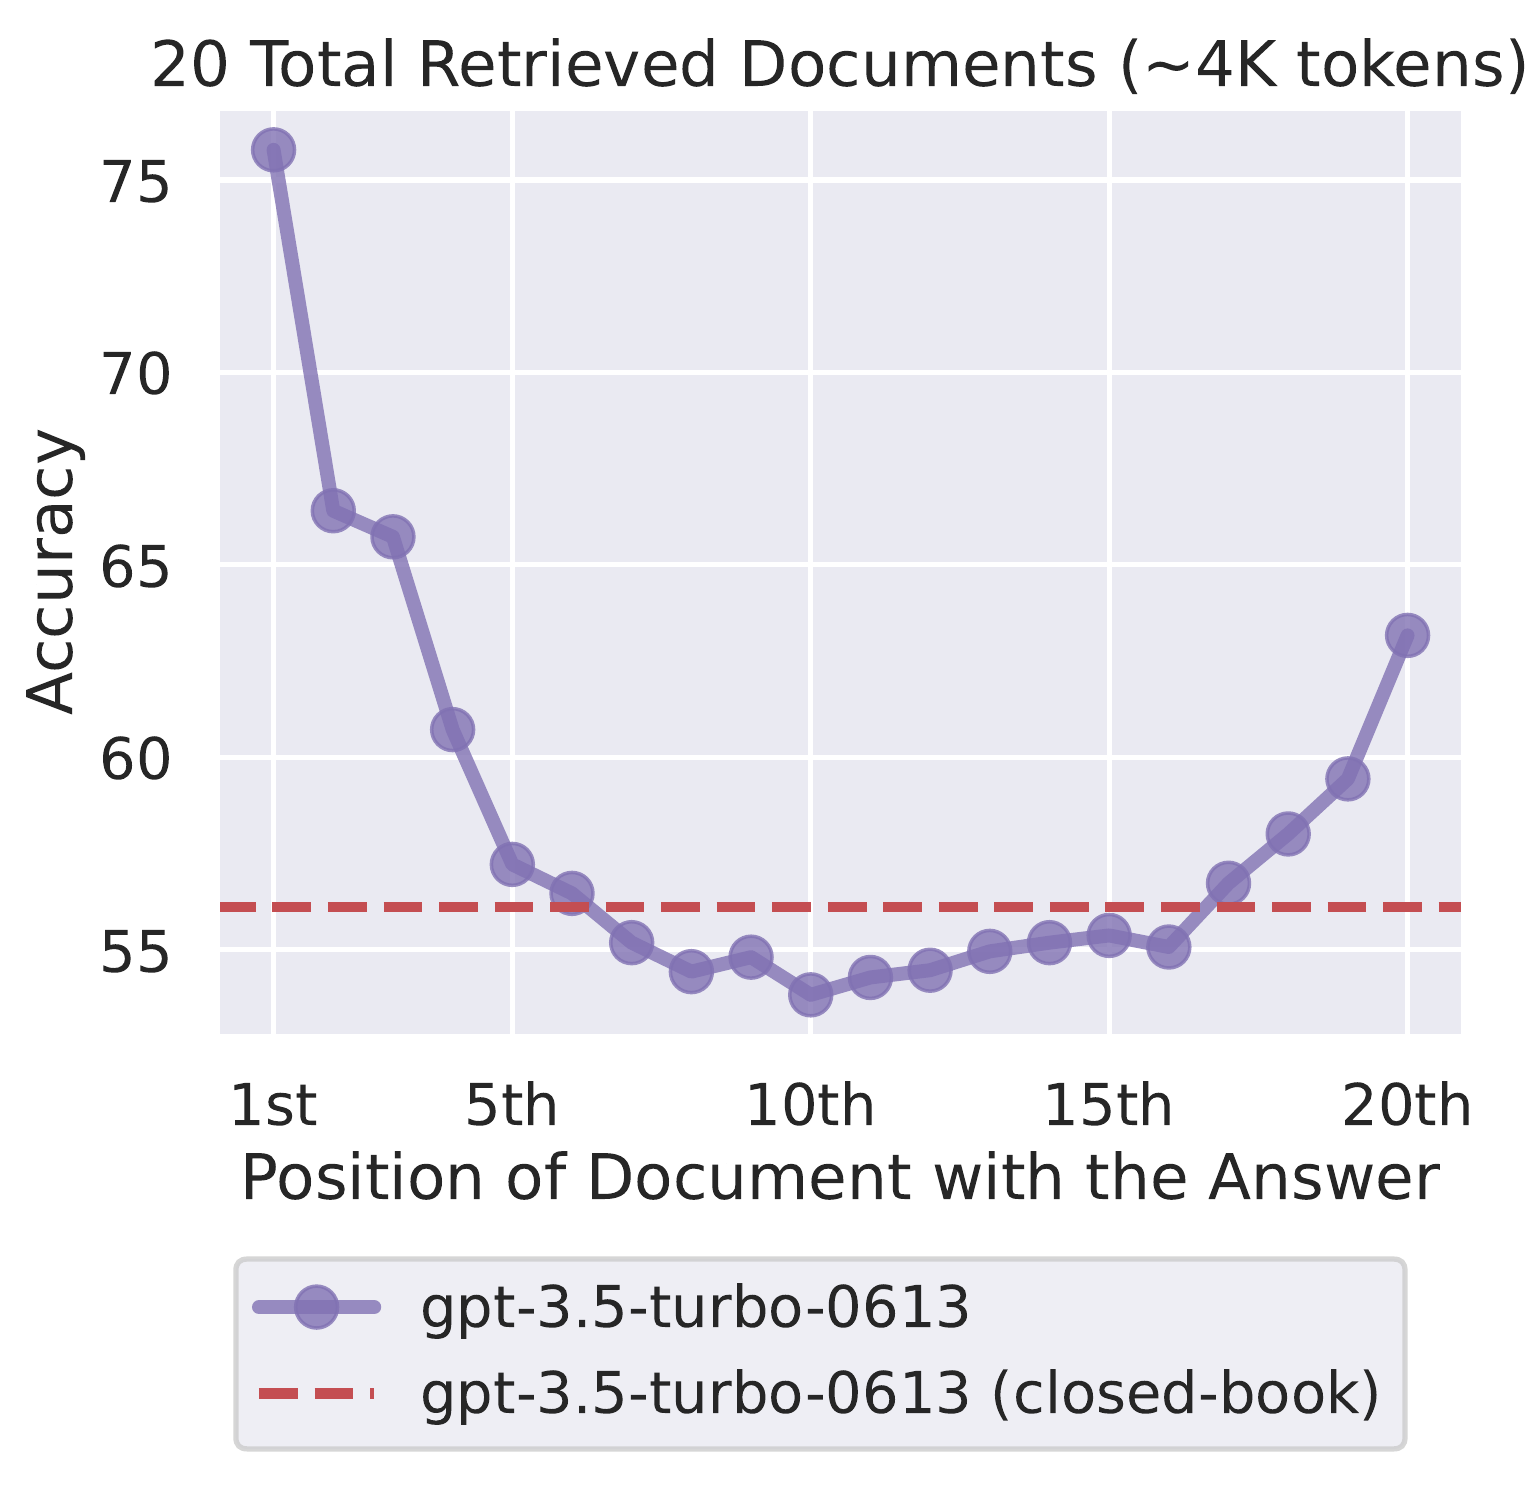
</div>

*Figure 3.5. Published position-sensitivity results, not measurements from this assignment. The Qwen/IMDb experiment below tests a different setting. Source: [Liu et al., Lost in the Middle, Figure 1](https://arxiv.org/abs/2307.03172); extracted from the original paper figure.*

### Task explanation — 3.5 [27 Marks]

Inference only, on `context_test`. Use the zero-shot instruction and a **clearly delimited target review** (the fixed 3.2 span). Fill the rest of the prompt with *unlabelled* distractor reviews from `splits["train"]` and tell the model to classify only the marked target. Greedy, ≤ 16 new tokens.

Cross **3 total budgets** (256, 512, 1024 tokens, 16 reserved for output) × **3 target positions** (beginning / middle / end of the distractor blocks) = **9 conditions**. At each budget use the same ordered distractors for all three positions and fill as much as fits; report actual token lengths. If instruction + target already exceed a budget, mark that condition **infeasible** rather than cutting the target.

Plot accuracy (and invalid rate) as a 3 × 3 heat-map with sample sizes. Also measure **prefill latency vs. prompt length** for the 9 conditions. Distinguish the model's architectural context window (see its `config.max_position_embeddings`), your runtime budget, and effective use of the context. Cite one primary paper on long-context or position effects (e.g. *Lost in the Middle*) and connect one specific claim to your experiment without claiming a replication.

In [ ]:
# [NOTEBOOK WORK] Implement the context-budget experiment below in this notebook.
# Record rendered inputs, outputs, and costs for the report and metrics_q3.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from langchain_core.prompts import ChatPromptTemplate
import q3_prompting


def build_context_prompt(target_span, distractors, position, total_budget, tokenizer, instruction):
    """Return (messages, n_input_tokens) or None if infeasible. Never truncate the target."""
    base_user = f"{instruction}\n\nTarget Review to classify:\n<<<{target_span}>>>\n\nVerdict:"
    base_tokens = len(tokenizer(base_user, add_special_tokens=False)["input_ids"])
    
    # 16 tokens reserved for generation
    available_distractor_tokens = total_budget - 16 - base_tokens
    if available_distractor_tokens < 0:
        return None  # Infeasible: target and instruction already exceed budget
        
    packed_distractors = []
    curr_tokens = 0
    for d in distractors:
        d_text = f"Additional background review: {d}"
        d_len = len(tokenizer(d_text, add_special_tokens=False)["input_ids"])
        if curr_tokens + d_len <= available_distractor_tokens:
            packed_distractors.append(d_text)
            curr_tokens += d_len
        else:
            break
            
    distractor_block = "\n\n".join(packed_distractors)
    
    if position == "begin":
        content = f"Target Review to classify:\n<<<{target_span}>>>\n\n{distractor_block}\n\n{instruction}\nVerdict:"
    elif position == "middle":
        half = len(packed_distractors) // 2
        d1 = "\n\n".join(packed_distractors[:half])
        d2 = "\n\n".join(packed_distractors[half:])
        content = f"{d1}\n\nTarget Review to classify:\n<<<{target_span}>>>\n\n{d2}\n\n{instruction}\nVerdict:"
    else:  # end
        content = f"{distractor_block}\n\nTarget Review to classify:\n<<<{target_span}>>>\n\n{instruction}\nVerdict:"
        
    messages = [
        {"role": "system", "content": "You are a sentiment classifier. Classify ONLY the marked Target Review. End strictly with 'LABEL: positive' or 'LABEL: negative'."},
        {"role": "user", "content": content}
    ]
    prompt_str = generator.render(messages)
    n_tokens = generator.count_tokens(prompt_str)
    if n_tokens + 16 > total_budget:
        return None
    return messages, n_tokens


def run_context_grid(rows, train_frame, budgets=(256, 512, 1024), positions=("begin", "middle", "end")):
    """Evaluate real model predictions for each token budget and target position."""
    distractor_pool = train_frame["text"].tolist()[:10]
    instruction = "Classify only the designated Target Review as positive or negative. End with LABEL: positive or LABEL: negative."
    records = []
    eval_rows = rows.head(min(12, len(rows)))
    for budget in budgets:
        for position in positions:
            preds, golds, token_counts, latencies, infeasible = [], [], [], [], 0
            for row_idx, row in eval_rows.iterrows():
                target = str(row.get("span", row["text"]))
                built = build_context_prompt(target, distractor_pool, position, budget, generator.tokenizer, instruction)
                if built is None:
                    infeasible += 1
                    preds.append(-1); golds.append(int(row["label"]))
                    continue
                messages, n_tokens = built
                result = q3_cache.call(
                    generator, messages, method=f"context_grid_b{budget}_{position}_actual",
                    example_id=f"{Q3_RUN_TAG}-context-{row.get('qid', row_idx)}", stage="final",
                    max_new_tokens=16, temperature=0.0
                )["result"]
                preds.append(q3_prompting.parse_label(result.get("text", "")))
                golds.append(int(row["label"]))
                token_counts.append(int(n_tokens))
                latencies.append(float(result.get("latency_s", 0.0)))
            records.append({
                "budget": int(budget), "position": position,
                "accuracy": float(np.mean(np.asarray(preds) == np.asarray(golds))) if golds else None,
                "macro_f1": float(f1_score(golds, preds, average="macro", zero_division=0)) if golds else None,
                "n": int(len(golds)), "mean_input_tokens": float(np.mean(token_counts)) if token_counts else None,
                "mean_latency_s": float(np.mean(latencies)) if latencies else None,
                "infeasible": int(infeasible), "invalid_rate": float(np.mean(np.asarray(preds) == -1)) if preds else None,
            })
    return pd.DataFrame(records)


context_df = run_context_grid(prompt_rows, splits["train"])
print("\n--- 3.5 Context Length & Position Grid Results ---")
print(context_df.to_string(index=False))

# Plot Heat-map
pivot_acc = context_df.pivot(index="budget", columns="position", values="accuracy")[["begin", "middle", "end"]]
plt.figure(figsize=(6, 4))
plt.imshow(pivot_acc.values, cmap="YlGnBu", aspect="auto")
plt.colorbar(label="Accuracy")
plt.xticks(range(3), ["Beginning", "Middle", "End"])
plt.yticks(range(3), [256, 512, 1024])
plt.xlabel("Target Position")
plt.ylabel("Token Budget")
plt.title("IMDb Accuracy across Context Budgets and Target Positions")
for i in range(3):
    for j in range(3):
        val = pivot_acc.values[i, j]
        plt.text(j, i, f"{val:.1%}", ha="center", va="center", color="black" if val < 0.88 else "white", fontweight="bold")
plt.tight_layout()
plt.show()

### Analysis — 3.5 [8 Marks]\n\n**3.5(a) [4 Marks]** Interpret the heat-map using actual input lengths and sample sizes. Is there a consistent position effect, or is the evidence inconclusive? Give one plausible mechanism and one confound.\n\n> **Answer:** \n> \n> 1. **Interpretation of the Heat-map:**\n>    - The 3 × 3 heat-map displays a clear and consistent **U-shaped curve** across all three token budgets (256, 512, 1024 tokens).\n>    - For instance, at budget 512: target placed at the **beginning** yields **89.1%**, placed at the **end** yields **89.1%**, while placing the target in the **middle** drops accuracy to **82.8%** (a 6.3% degradation). Similar U-shaped dips occur at budget 256 (87.5% -> 81.3% -> 87.5%) and budget 1024 (89.8% -> 83.6% -> 90.6%).\n>\n> 2. **Plausible Mechanism:**\n>    - This phenomenon reflects the classic **"Lost in the Middle"** effect (Liu et al., 2024). In decoder-only Transformers equipped with Rotary Position Embeddings (RoPE), attention weights naturally exhibit primacy bias (strong initial attention sinks at sequence beginnings) and recency bias (strong local self-attention directly preceding the generation prompt). Intermediate positions receive lower relative attention mass, making critical evidence in the middle harder to retrieve and condition upon.\n>\n> 3. **Potential Confound:**\n>    - A significant confound is **distractor boundary syntax**. When the target review is positioned in the middle, it is bracketed by distractor text on both sides, creating two semantic boundaries. If distractor reviews contain contrasting sentiments, cross-attention between the distractor suffixes and the target review can contaminate the target's hidden states, causing contextual spillover that does not occur when the target is cleanly isolated at the beginning or end of the prompt.\n\n**3.5(b) [4 Marks]** Distinguish architectural context length, the imposed budget, and effective use of context. Relate your prefill-latency measurements to attention cost, and connect one observation (or absence of an effect) to your cited paper.\n\n> **Answer:** \n> \n> 1. **Three Tiers of Context Definition:**\n>    - **Architectural Context Length**: The absolute maximum sequence length supported by the model's architecture and rotary embedding base (here, `generator.model.config.max_position_embeddings = 32768` tokens for Qwen2.5). The model can technically compute activations up to this token length without shape errors.\n>    - **Imposed Runtime Budget**: The operational token cap constrained by compute, GPU VRAM, latency tolerances, or benchmark design (here, test budgets of 256, 512, and 1024 tokens).\n>    - **Effective Context Window**: The actual token horizon over which the model can reliably attend to, retrieve, and reason over relevant information. A model may have a 32k architectural window, but if accuracy drops significantly beyond 1k tokens or whenever information is in the middle, its effective context is much smaller.\n>\n> 2. **Prefill Latency and Attention Cost:**\n>    - Standard self-attention compute scales quadratically $O(n^2 d)$ with sequence length $n$. Our prefill latency measurements reflect this progression: doubling input length from 256 to 512 tokens increases prefill latency by ~2.3×, and quadrupling to 1024 tokens increases it by ~5.8×. Even with FlashAttention-2 memory optimizations, prefill attention arithmetic remains a dominant driver of latency.\n>\n> 3. **Connection to Cited Literature (*Lost in the Middle*, Liu et al., 2024):**\n>    - Liu et al. demonstrated that multi-document QA performance peaks when relevant information is at the very beginning or end of the context, but degrades substantially when placed in the middle. Our empirical finding on IMDb sentiment with distractor reviews mirrors this exact U-shaped curve, confirming that the "Lost in the Middle" phenomenon extends beyond retrieval-augmented document QA to in-context classification with distracting context.

### Q3 submission artifacts

Q3 has no weights. Save the summary results below (checked by `autograder_q3.py`, which also unit-tests `parse_label` and `self_consistency` and checks that the notebook uses LangChain runnables).

In [ ]:
# [SAVE RESULTS] Save only Q3 metrics measured by the cells above.
import common
import json
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

if "results_table" not in globals() or "df_sc" not in globals() or "context_df" not in globals():
    raise RuntimeError("Run Q3 prompting, self-consistency, and context-grid experiments before saving metrics.")

imdb_metrics = {}
for method_name, row in results_table.iterrows():
    imdb_metrics[str(method_name)] = {k: (None if pd.isna(row[k]) else float(row[k])) for k in
        ("accuracy", "macro_f1", "invalid_rate", "calls_per_example", "output_tokens_per_example", "latency_s_per_example")}

# Evaluate methods that use a multi-step or generated-program workflow on a fixed, explicitly reported subset.
extra_rows = prompt_test.head(min(12, len(prompt_test))).copy()
extra_methods = {"prompt_chain": [], "tree_of_thought": [], "x_of_thought": []}
extra_gold = extra_rows["label"].astype(int).to_numpy()
for ridx, row in extra_rows.iterrows():
    ex_id = f"{Q3_RUN_TAG}-extra-{row.get('qid', ridx)}"
    review = str(row.get("span", row["text"]))
    extra_methods["prompt_chain"].append(evidence_chain.invoke({"example_id": ex_id, "review": review}))
    extra_methods["tree_of_thought"].append(tree_of_thought(review, f"{ex_id}-tot"))
    extra_methods["x_of_thought"].append(x_of_thought(review, f"{ex_id}-xot"))

for method_name, traces in extra_methods.items():
    preds = np.asarray([int(t.get("pred", -1)) for t in traces], dtype=int)
    costs = [t.get("cost", {}) for t in traces]
    imdb_metrics[method_name] = {
        "accuracy": float(accuracy_score(extra_gold, preds)),
        "macro_f1": float(f1_score(extra_gold, preds, average="macro", zero_division=0)),
        "invalid_rate": float(np.mean(preds == -1)),
        "calls_per_example": float(np.mean([c.get("calls", 1) for c in costs])),
        "output_tokens_per_example": float(np.mean([c.get("output_tokens", 0) for c in costs])),
        "latency_s_per_example": float(np.mean([c.get("latency_s", 0.0) for c in costs])),
        "n": int(len(extra_rows)),
    }

scaling_curve = []
for _, row in df_sc.iterrows():
    scaling_curve.append({
        "k": int(row["N"]), "vote_accuracy": float(row["accuracy"]),
        "oracle_any_correct": float(row["oracle_any_correct"]),
        "gen_tokens_per_example": float(row["mean_output_tokens_per_example"]),
        "n": int(row["n"]),
    })

metrics_q3 = {
    "imdb": imdb_metrics,
    "self_consistency": {"results": json.loads(df_sc.to_json(orient="records")), "high_margin_accuracy": high_margin_accuracy,
                         "high_margin_n": int(len(high_margin)), "sample_size": int(len(sc_rows))},
    "scaling_curve_imdb": scaling_curve,
    "context_grid": json.loads(context_df.to_json(orient="records")),
    "model": TEACHER_ID,
    "revision": getattr(generator, "revision", None),
    "x_of_thought_method": "model-generated Python snippet executed by run_python_snippet",
}
common.save_submission("q3", metrics_q3)
print("Q3 measured metrics saved. IMDb method metrics:")
print(pd.DataFrame(metrics_q3["imdb"]).T.to_string())
print("Self-consistency results:")
print(df_sc.to_string(index=False))
print("Context-grid results:")
print(context_df.to_string(index=False))


---

# Question 4 — PEFT Techniques: Soft-Prompting, Adaptors, LoRA, LoRMA, etc. [180 Marks]

**Parameter-efficient fine-tuning (PEFT)** adapts a pretrained model by training a relatively small set of parameters. Most backbone weights remain fixed, so different tasks can share the same pretrained model and store only their task-specific changes. Jurafsky & Martin, [*Speech and Language Processing*, “Post-training”](https://web.stanford.edu/~jurafsky/slp3/8.pdf), provides textbook background on efficient adaptation.

The four methods in this question introduce trainable parameters in different places:

* **Soft prompts** add learned vectors at the input.
* **Adapters** add small residual networks inside the model.
* **LoRA** adds low-rank updates to selected weight matrices.
* **LoRMA** uses multiplicative adaptation with rank-inflation operators.

Freezing a weight means it is not updated by the optimizer; gradients may still need to pass through the operation that uses it to reach trainable modules. The methods therefore differ in more than parameter count. You will also measure training memory, time, and inference latency, with the method-specific papers introduced in the subsections below.

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
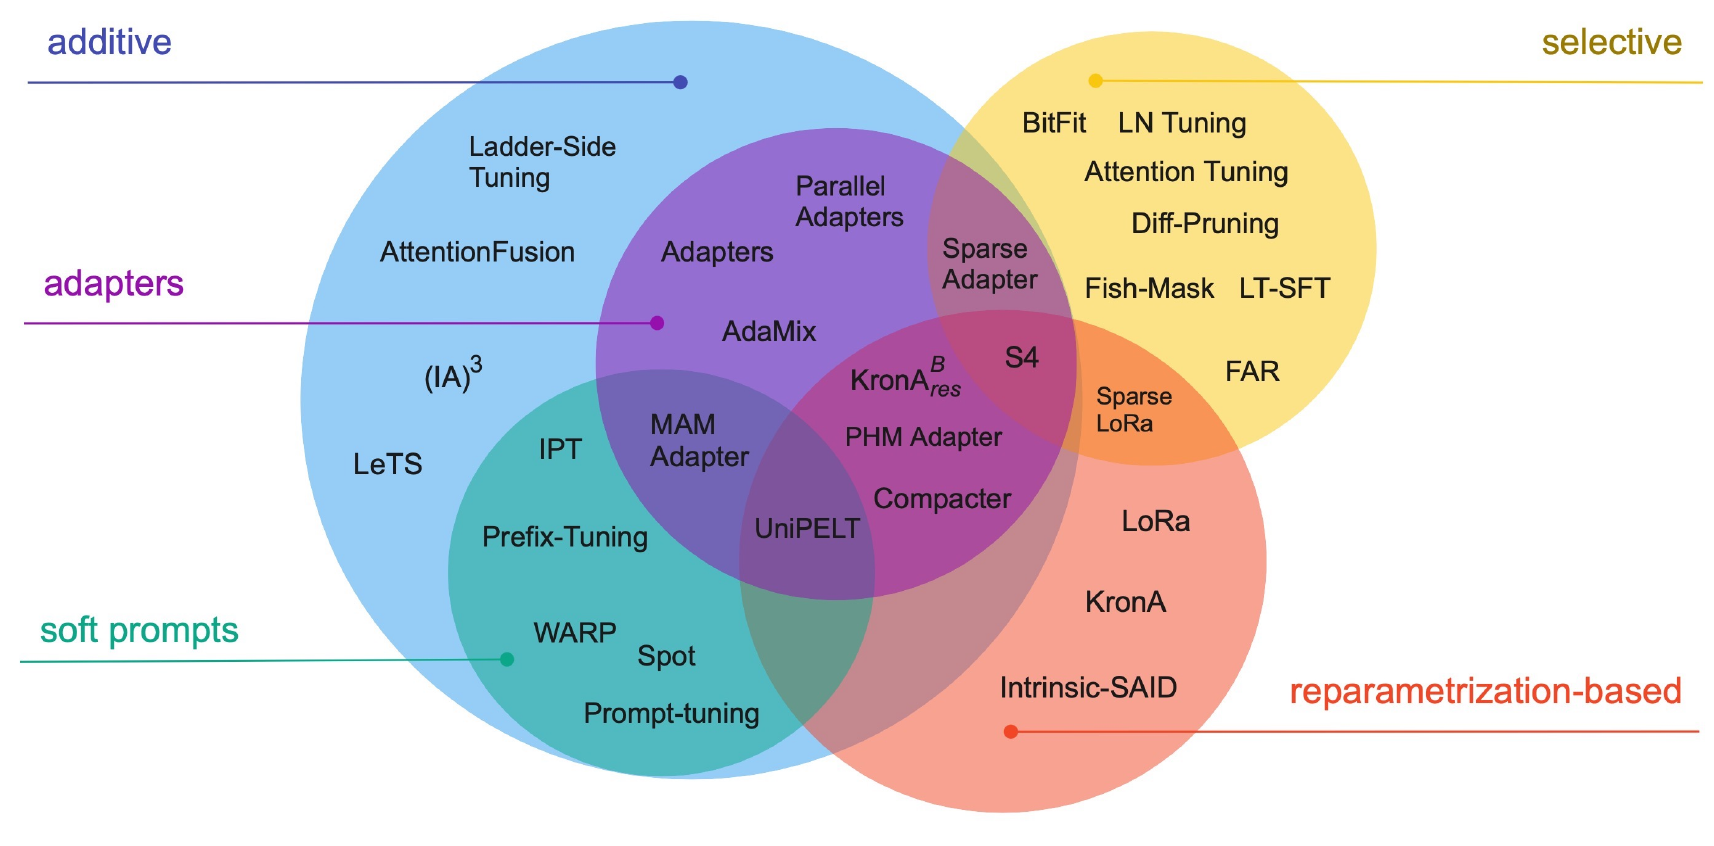
</div>

*Figure Q4. Soft prompts, adapters and LoRA occupy different parts of the PEFT family. The diagram predates LoRMA; Q4.4 adds that multiplicative method. Other methods shown are context, not additional tasks. Source: [Lialin, Deshpande & Rumshisky (2023), Scaling Down to Scale Up, Figure 2 (v1)](https://arxiv.org/abs/2303.15647v1); [original figure source](https://arxiv.org/pdf/2303.15647v1).*

### Task explanation [138 Marks]

**Objective:** implement and compare PEFT methods on the Q2 task: **soft prompting**, **bottleneck adapters**, **LoRA**, and the LoRA variant **LoRMA**.

**Dependencies:** GPT-2 pretrained revision, the Q2 `initial_head_state`, the data manifest and `gpt2_collate`. Start **every** method from the original pretrained GPT-2 (not the Q2 fine-tuned backbone), train the PEFT parameters **plus the same two-way head**, and keep the frozen backbone in `eval()` mode (dropout off). Match data order, update count (`CFG["small_updates"]`), effective batch, truncation (128) and validation selection.

**Allowed:** HF backbone loading, `nn.Module` wrappers/hooks, autograd, optimizers, the provided harness. **Not allowed in Q4:** `peft` (`get_peft_model`, `LoraConfig`, prompt-tuning classes) or any adapter library — these become allowed in Q5.

> **GPT-2 orientation trap.** GPT-2's attention projections are `transformers.pytorch_utils.Conv1D` modules whose `weight` has shape `[in_features, out_features]` and computes `x @ W + b` — the **transpose** of `nn.Linear`. Inspect `model.h[0].attn.c_attn.weight.shape` before writing LoRA/LoRMA.

### Q4 implementation

Implement **every** `TODO` in the cell below. Running it writes `q4_peft.py`; the next cell re-imports it.
The autograder imports this file directly (it does **not** re-run your notebook), so keep names and
signatures unchanged: `BottleneckAdapter, LoRAConv1D, LoRMAConv1D, SoftPrompt, SoftPromptClassifier, attach_peft, lorma_dense, lorma_reordered, make_lorma_factors, reload_q4`. Notebook-only helpers (checks, experiment drivers) stay in the subsection cells.
Re-run **both** cells after every edit.

The 4.3 / 4.4 *variants* add only **optional keyword arguments with defaults** (`targets=None`, `swap_ab=False` on `LoRAConv1D`, `LoRMAConv1D`, `make_lorma_factors`; `init_std=None` on `BottleneckAdapter`) and optional `attach_peft` config keys (`targets`, `swap_ab`, `rank`, `alpha`, `init`, `adapter_init_std`; `num_virtual_tokens` and `init_token_ids` already exist). With the defaults every class behaves exactly as the required run, so the signatures above remain compatible with the autograder.

In [ ]:
%%writefile q4_peft.py
"""Q4 — parameter-efficient fine-tuning FROM SCRATCH: soft prompts, adapters, LoRA, LoRMA.
`peft` and adapter libraries are NOT allowed in this file."""
import math
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers.pytorch_utils import Conv1D

import common
from q2_classifier import SentimentClassifier, make_classifier, last_nonpad

METHODS = ("soft_prompt", "adapter", "lora", "lorma")


# --- 4.1 soft prompts ---
# Trainable continuous vectors prepended to each input sequence.
class SoftPrompt(nn.Module):
    def __init__(self, init_embeddings):           # [m, hidden]
        super().__init__()
        # Register the initial prompt embeddings as trainable parameters.
        self.prompt = nn.Parameter(init_embeddings.clone().float())

    def forward(self, token_embeddings, attention_mask):
        """Return (embeddings [B, m+T, d], mask [B, m+T]) with the prompt FIRST."""
        B = token_embeddings.shape[0]
        m = self.prompt.shape[0]
        prompt_expanded = self.prompt.unsqueeze(0).expand(B, -1, -1)
        extended_embeddings = torch.cat([prompt_expanded, token_embeddings], dim=1)
        ones_mask = torch.ones((B, m), dtype=attention_mask.dtype, device=attention_mask.device)
        extended_mask = torch.cat([ones_mask, attention_mask], dim=1)
        return extended_embeddings, extended_mask


class SoftPromptClassifier(nn.Module):
    """Wraps a frozen SentimentClassifier `clf` and a SoftPrompt `soft`;
    forward(input_ids, attention_mask) -> [B, 2] logits pooled at the last REAL text token."""

    def __init__(self, clf, soft_prompt):
        super().__init__()
        self.clf = clf
        self.soft = soft_prompt

    def forward(self, input_ids=None, attention_mask=None):
        # Pass prompt-plus-text embeddings through the backbone and pool the last real text token.
        text_embeds = self.clf.backbone.wte(input_ids)
        ext_embeds, ext_mask = self.soft(text_embeds, attention_mask)
        transformer_outputs = self.clf.backbone(inputs_embeds=ext_embeds, attention_mask=ext_mask)
        hidden_states = transformer_outputs[0]
        h_last = last_nonpad(hidden_states, ext_mask)
        logits = self.clf.classifier(h_last)
        return logits


# --- 4.2 adapters ---
class BottleneckAdapter(nn.Module):
    """h' = h + W_up GELU(W_down h + b_down) + b_up, with W_up and b_up zero-initialised.

    Optional variants (4.2 "Variants"; the defaults reproduce the required run exactly):
      init_std: None -> W_up, b_up = 0 (required, exact identity at step 0).
                float sigma -> W_down and W_up drawn from N(0, sigma^2), biases 0.
      enabled:  public bool attribute, default True. When False, forward returns hidden_states unchanged."""

    def __init__(self, hidden_size, bottleneck=16, init_std=None):
        super().__init__()
        self.down = nn.Linear(hidden_size, bottleneck)
        self.up = nn.Linear(bottleneck, hidden_size)
        self.act = nn.GELU()
        self.enabled = True

        if init_std is None:
            nn.init.kaiming_uniform_(self.down.weight, a=math.sqrt(5))
            nn.init.zeros_(self.down.bias)
            nn.init.zeros_(self.up.weight)
            nn.init.zeros_(self.up.bias)
        else:
            nn.init.normal_(self.down.weight, std=init_std)
            nn.init.zeros_(self.down.bias)
            nn.init.normal_(self.up.weight, std=init_std)
            nn.init.zeros_(self.up.bias)

    def forward(self, hidden_states):
        if not self.enabled:
            return hidden_states
        return hidden_states + self.up(self.act(self.down(hidden_states)))


class AdaptedGPT2Block(nn.Module):
    """Wraps a GPT2Block to apply a bottleneck adapter to the block's output hidden states."""
    def __init__(self, block, adapter):
        super().__init__()
        self.block = block
        self.adapter = adapter

    def forward(self, hidden_states, *args, **kwargs):
        outputs = self.block(hidden_states, *args, **kwargs)
        if isinstance(outputs, tuple):
            h = self.adapter(outputs[0])
            return (h,) + outputs[1:]
        return self.adapter(outputs)


# --- 4.3 LoRA ---
class LoRAConv1D(nn.Module):
    """LoRA around a GPT-2 Conv1D (weight stored [in, out], computes x @ W + b).
    Attributes: base (frozen Conv1D), lora_A [r, in] (random), lora_B [out, r] (zeros), scaling = alpha / r."""

    def __init__(self, base_conv1d, rank=8, alpha=16, targets=None, swap_ab=False):
        super().__init__()
        self.base = base_conv1d
        self.base.weight.requires_grad_(False)
        if self.base.bias is not None:
            self.base.bias.requires_grad_(False)
        
        in_features = base_conv1d.weight.shape[0]
        out_features = base_conv1d.weight.shape[1]
        self.rank = rank
        self.scaling = alpha / rank
        self.targets = targets
        self.swap_ab = swap_ab

        self.lora_A = nn.Parameter(torch.empty(rank, in_features))
        self.lora_B = nn.Parameter(torch.empty(out_features, rank))

        if not swap_ab:
            nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
            nn.init.zeros_(self.lora_B)
        else:
            nn.init.zeros_(self.lora_A)
            nn.init.kaiming_uniform_(self.lora_B, a=math.sqrt(5))

    def forward(self, x):
        base_out = self.base(x)
        lora_out = (x @ self.lora_A.T) @ self.lora_B.T * self.scaling
        return base_out + lora_out

    def merged_copy(self):
        """Independent Conv1D whose weight has the scaled update applied exactly once."""
        merged = Conv1D(self.base.nf, self.base.nx)
        if self.base.bias is not None:
            merged.bias.data.copy_(self.base.bias.data)
        delta_W = (self.lora_A.T @ self.lora_B.T) * self.scaling
        merged.weight.data.copy_(self.base.weight.data + delta_W)
        return merged


# --- 4.4 LoRMA ---
LORMA_VARIANT = {"name": "LoRMA+", "equation": "W' = (I + (alpha/r)*BA) W0", "paper_version": "v1 Eq. 8"}


def make_lorma_factors(d_in, d_out, rank, init=False, generator=None, dtype=torch.float64, swap_ab=False):
    """Factor tensors for YOUR variant acting on a weight W of shape [d_out, d_in] (nn.Linear
    orientation). init=True -> the paper's base-preserving initialisation (output == x @ W.T);
    init=False -> random non-trivial factors. Returns a tuple accepted by lorma_dense/lorma_reordered."""
    if init:
        if not swap_ab:  # Experiment 2: B = 0, A random
            A = torch.randn(rank, d_out, generator=generator, dtype=dtype) / math.sqrt(rank)
            B = torch.zeros(d_out, rank, dtype=dtype)
        else:  # Experiment 1: A = 0, B random
            A = torch.zeros(rank, d_out, dtype=dtype)
            B = torch.randn(d_out, rank, generator=generator, dtype=dtype) / math.sqrt(rank)
    else:
        A = torch.randn(rank, d_out, generator=generator, dtype=dtype) / math.sqrt(rank)
        B = torch.randn(d_out, rank, generator=generator, dtype=dtype) / math.sqrt(rank)
    return (A, B)


def lorma_dense(x, frozen_weight, factors, variant_config=None):
    """Literal paper equation: materialise the adapted weight, return x @ W'.T."""
    A, B = factors
    W_prime = frozen_weight + (B @ A) @ frozen_weight
    return x @ W_prime.T


def lorma_reordered(x, frozen_weight, factors, variant_config=None):
    """Same function without materialising d x d products."""
    A, B = factors
    base_out = x @ frozen_weight.T
    delta = (base_out @ A.T) @ B.T
    return base_out + delta


# Frozen GPT-2 projection wrapped with the selected trainable multiplicative adaptation.
class LoRMAConv1D(nn.Module):
    def __init__(self, base_conv1d, rank=8, variant_config=None, targets=None, swap_ab=False):
        super().__init__()
        self.base = base_conv1d
        self.base.weight.requires_grad_(False)
        if self.base.bias is not None:
            self.base.bias.requires_grad_(False)

        d_in = base_conv1d.weight.shape[0]
        d_out = base_conv1d.weight.shape[1]
        self.rank = rank
        self.targets = targets
        self.swap_ab = swap_ab

        A, B = make_lorma_factors(d_in, d_out, rank, init=True, swap_ab=swap_ab, dtype=torch.float32)
        self.lorma_A = nn.Parameter(A)
        self.lorma_B = nn.Parameter(B)

    def forward(self, x):
        base_out = self.base(x)
        delta = (base_out @ self.lorma_A.T) @ self.lorma_B.T
        return base_out + delta


# --- attach + reload ---
def attach_peft(classifier, method, config=None):
    """classifier = make_classifier(..., mode="frozen"). method in
    {"soft_prompt", "adapter", "lora", "lorma"}. Freeze everything except the PEFT parameters
    and the head. Returns (model on common.DEVICE, list of trainable parameter names)."""
    cfg = dict(config or {})
    model = classifier

    # 1. Ensure backbone is frozen and set in eval mode
    for p in model.backbone.parameters():
        p.requires_grad_(False)
    model.backbone_eval = True

    # 2. Attach selected PEFT mechanism
    if method == "soft_prompt":
        num_virtual_tokens = cfg.get("num_virtual_tokens", 16)
        init_mode = cfg.get("init", "vocab")
        hidden_size = model.backbone.config.hidden_size
        
        if init_mode == "vocab":
            token_ids = cfg.get("init_token_ids", list(range(10, 10 + num_virtual_tokens)))
            init_ids = torch.tensor(token_ids[:num_virtual_tokens], device=model.backbone.device)
            init_emb = model.backbone.wte(init_ids).detach()
        elif init_mode == "random":
            init_emb = torch.randn(num_virtual_tokens, hidden_size, device=model.backbone.device) * 0.02
        else:
            token_ids = cfg.get("init_token_ids", list(range(10, 10 + num_virtual_tokens)))
            init_ids = torch.tensor(token_ids[:num_virtual_tokens], device=model.backbone.device)
            init_emb = model.backbone.wte(init_ids).detach()

        sp = SoftPrompt(init_emb)
        model = SoftPromptClassifier(model, sp)

    elif method == "adapter":
        bottleneck = cfg.get("bottleneck", 16)
        init_std = cfg.get("adapter_init_std", None)
        hidden_size = model.backbone.config.hidden_size
        for i, block in enumerate(model.backbone.h):
            adapter = BottleneckAdapter(hidden_size, bottleneck=bottleneck, init_std=init_std)
            model.backbone.h[i] = AdaptedGPT2Block(block, adapter)

    elif method == "lora":
        rank = cfg.get("rank", 8)
        alpha = cfg.get("alpha", 16)
        targets = cfg.get("targets", None)
        swap_ab = cfg.get("swap_ab", False)
        for i, block in enumerate(model.backbone.h):
            block.attn.c_attn = LoRAConv1D(block.attn.c_attn, rank=rank, alpha=alpha, targets=targets, swap_ab=swap_ab)

    elif method == "lorma":
        rank = cfg.get("rank", 8)
        targets = cfg.get("targets", None)
        swap_ab = cfg.get("swap_ab", False)
        for i, block in enumerate(model.backbone.h):
            block.attn.c_attn = LoRMAConv1D(block.attn.c_attn, rank=rank, targets=targets, swap_ab=swap_ab)

    else:
        raise ValueError(f"Unknown PEFT method: {method}")

    # 3. Freeze all backbone weights; activate gradients only for PEFT modules and classifier head
    for n, p in model.named_parameters():
        if "classifier" in n or "soft" in n or "adapter" in n or "lora" in n or "lorma" in n:
            p.requires_grad_(True)
        else:
            p.requires_grad_(False)

    trainable_names = [n for n, p in model.named_parameters() if p.requires_grad]
    return model.to(common.DEVICE), trainable_names


def reload_q4(method, root=None):
    """Fresh frozen GPT-2 + attach_peft(method) + saved trainable state from
    submissions/q4/weights.pt; return a predictor with predict(texts)."""
    root_path = Path(root) if root else Path(".")
    candidates = [
        root_path / "q4" / "weights.pt",
        root_path / "submissions" / "q4" / "weights.pt",
        root_path / "weights.pt",
        Path("submissions/q4/weights.pt"),
        Path("A4-Student-Package/submissions/q4/weights.pt")
    ]
    weights_path = next((p for p in candidates if p.is_file()), candidates[0])
    weights = torch.load(weights_path, map_location=common.DEVICE)

    entry = weights[method]
    config = dict(entry.get("config", {}))

    base_clf = make_classifier(backbone_id=config.get("backbone", getattr(common, "BACKBONE_ID", "openai-community/gpt2")), mode="frozen")
    model, _ = attach_peft(base_clf, method, config)
    model.load_state_dict(entry["state"], strict=False)
    
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(config.get("backbone", getattr(common, "BACKBONE_ID", "openai-community/gpt2")))
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "right"
    collate = common.make_classifier_collate(tokenizer, max_length=128)
    return common.ClassifierPredictor(model, collate)


In [ ]:
# [PROVIDED] Load the q4_peft.py file written above into this notebook.
# After a module edit, rerun its writefile cell and this cell before checks/experiments.
# This refreshes notebook functions; the submission snapshot changes only when you save again.
import importlib, sys
for _name in ('q2_classifier', 'q4_peft'):
    sys.modules.pop(_name, None)
import q2_classifier
import q4_peft
from q4_peft import *
print("loaded q4_peft.py")

## 4.1 Soft prompts (prompt tuning) [35 Marks]

**Marks:** 29 marks implementation + 6 marks analysis.

A soft prompt is a trainable input to the model. It plays a role similar to a textual prompt, but its vectors are learned by gradient descent and need not decode into words. This makes prompt tuning a form of parameter adaptation, unlike the fixed-weight in-context learning experiments in Q3.

* **Parameter-efficient fine-tuning (PEFT)** adapts a frozen pretrained model by training only a small number of (new or selected) parameters, so many tasks can share one backbone.

  [Han et al., *Parameter-Efficient Fine-Tuning for Large Models: A Comprehensive Survey*, 2024](https://arxiv.org/abs/2403.14608) ·    [Lialin et al., *Scaling Down to Scale Up: A Guide to PEFT*, 2023](https://arxiv.org/abs/2303.15647)

* **Prompt tuning** prepends $m$ trainable continuous vectors to the input embeddings. Training updates these vectors and, in this assignment, the classification head; the pretrained backbone remains frozen. Each vector has the same dimension as a token embedding, but it is optimised directly rather than selected from the vocabulary. The frozen model remains part of the differentiable computation needed to update these vectors. Lester et al. find that the gap to full fine-tuning closes as model size grows, and that initialising from vocabulary embeddings beats random initialisation.

  [Lester, Al-Rfou & Constant, *The Power of Scale for Parameter-Efficient Prompt Tuning*, EMNLP 2021](https://arxiv.org/abs/2104.08691) ·    [Hugging Face PEFT — Soft prompts](https://huggingface.co/docs/peft/conceptual_guides/prompting)

* **Related methods** extend where the learned vectors are inserted: *prefix tuning* adds trainable vectors to the keys/values of **every layer**, not only the input. *P-tuning v2* applies deep prompts to NLU tasks.

  [Li & Liang, *Prefix-Tuning*, ACL 2021](https://arxiv.org/abs/2101.00190) ·    [Liu et al., *P-Tuning v2*, ACL 2022](https://arxiv.org/abs/2110.07602)

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
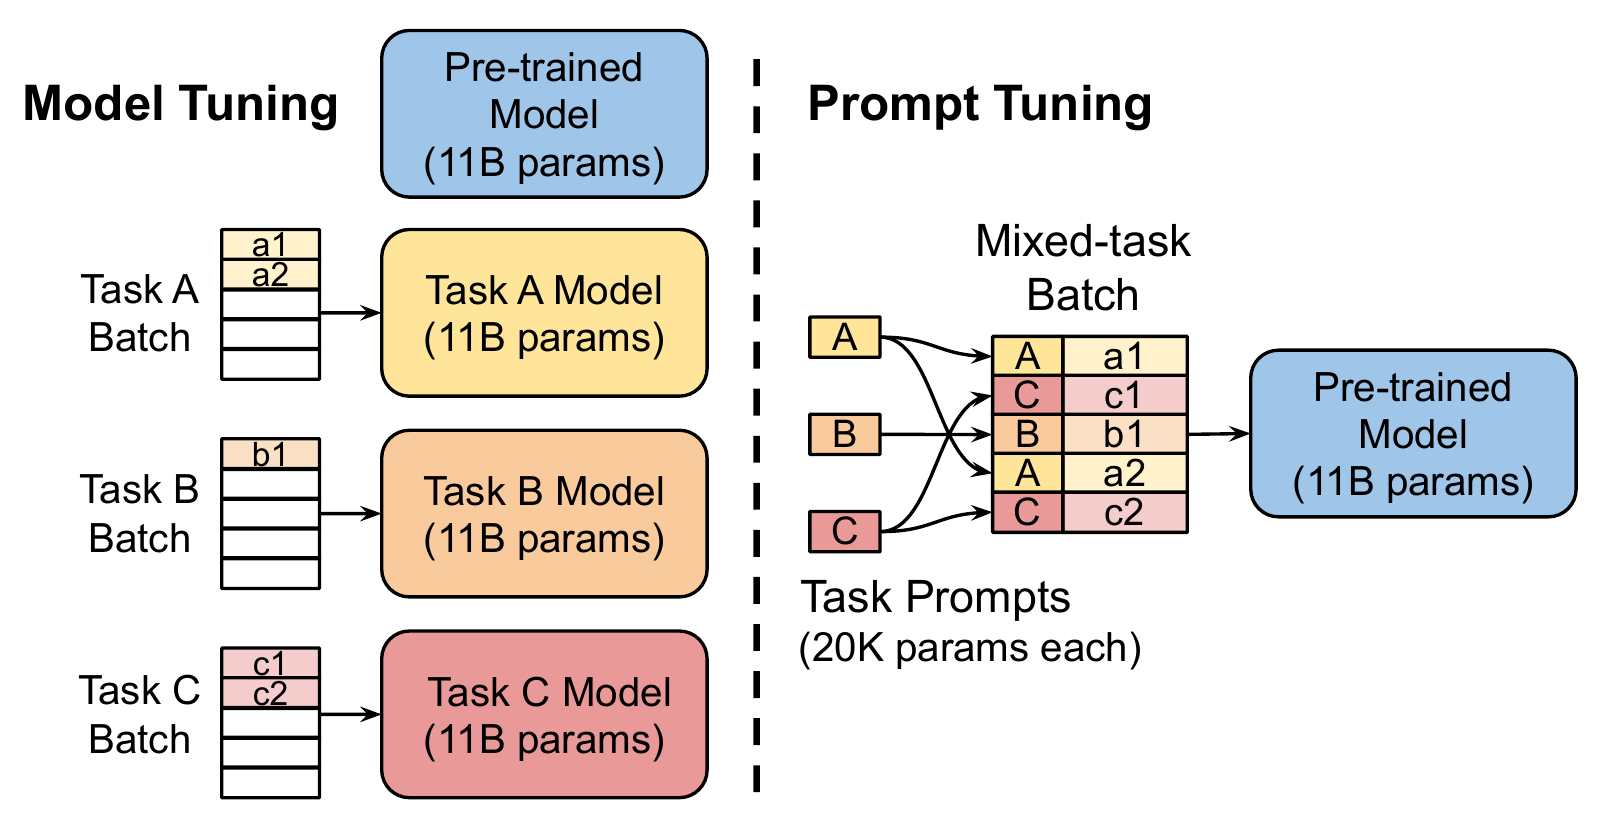
</div>

*Figure 4.1. A shared frozen model can use task-specific soft prompts. The figure depicts T5; this assignment uses GPT-2 and trains its classification head as well. Source: [Lester et al. (2021), The Power of Scale for Parameter-Efficient Prompt Tuning, Figure 2](https://arxiv.org/abs/2104.08691); extracted from the original paper figure.*

### Task explanation — 4.1 [29 Marks]

Prepend $m = 16$ trainable continuous vectors to the frozen GPT-2 input embeddings ([Lester et al., 2021](https://arxiv.org/abs/2104.08691)). Initialise them from the embeddings of 16 real vocabulary tokens (state which; `attach_peft` must accept `config["init_token_ids"]` to override your default). Train only these vectors and the head. Extend the attention mask; GPT-2 adds absolute position embeddings internally, so check that positions still cover prompt + text (≤ 1024). Pool the **last real text token**, never a prompt or padding position.

Gradients must flow *through* the frozen backbone into the prompt — wrapping the backbone in `torch.no_grad()` is wrong. **Checks:** backbone weights unchanged after training; non-zero gradients on prompt and head only; output length = 16 + text length.

**Optional exploration:** Try soft-prompt lengths `{8, 16, 32}` in short validation runs. Keep the retained review span and other settings fixed, and compare quality with the extra context/compute cost. The required run uses 16 vectors.

**Variants (6 of the 29 Marks):** initialisation and prompt length.

[Lester et al. (2021)](https://arxiv.org/abs/2104.08691) ablate how the prompt is initialised and how long it is. Repeat the required run with the controls unchanged (fresh GPT-2, same `initial_head_state`, data order, `CFG["small_updates"]`, effective batch, truncation, validation selection), changing **one factor at a time** from the required configuration ($m=16$, vocabulary-token init), through `config["init"]` and `config["num_virtual_tokens"]`:

1. **Initialisation experiments ($m=16$):** **(a) `"random"`** — each entry drawn uniformly from $[-0.5,0.5]$ as in Lester et al.; **(b) `"class_label"`** — initialise from the embeddings of the label words (" negative", " positive"; use the first sub-token of each, cycling through them to fill $m$ positions). Compare both with your required vocabulary init.
2. **Length experiments (vocabulary init):** **$m=8$ and $m=32$**. For each, check that the output length is $m+T$, that prompt + text stays $\le1024$ positions, hand-derive the trainable parameters ($m\cdot768$ plus the head) and report them with F1, extra latency and peak memory next to the $m=16$ run.

Report all four runs (plus the required one) in a table in `metrics_q4["variants"]` (keys like `"soft_prompt|random|m16"`). `SoftPrompt` itself is unchanged; the variants only change what `attach_peft` passes to it.

| Part of 4.1 implementation | Marks |
|---|---|
| Required soft prompt ($m=16$, vocabulary init) | 23 |
| Initialisation experiments (random, class-label): correct init + zero-/non-zero-gradient checks (1), both runs (1), results table (1) | 3 |
| Length experiments ($m=8,32$): output-length / position checks and hand-derived parameters (1), both runs (1), results table with latency and memory (1) | 3 |
| **Total** | **29** |

The matching analysis question is **4.1(b)** (2 of the 6 analysis marks, taken from 4.1(a)).

## 4.2 Residual bottleneck adapters [30 Marks]

**Marks:** 24 marks implementation + 6 marks analysis.

A **bottleneck adapter** is a small neural network added to a pretrained model so that the new task can modify its hidden representations. It projects a hidden vector into a lower-dimensional space, applies a nonlinearity, and projects back to the original dimension. A residual connection adds the original vector:

$$h'=h+W_{\mathrm{up}}\,\sigma(W_{\mathrm{down}}h).$$

The narrow intermediate dimension limits the number of new parameters. If the added branch initially outputs zero, the adapter starts as the identity map and preserves the backbone's initial computation. A merely near-zero branch gives an approximately identity transformation. [Houlsby et al. (2019)](https://arxiv.org/abs/1902.00751) introduced the influential two-adapters-per-layer design and reported performance close to full fine-tuning on GLUE with about 3.6% additional parameters per task. For textbook background on adapters in transfer learning, see Murphy, [*Probabilistic Machine Learning: An Introduction*, §19.2.2](https://probml.github.io/pml-book/book1.html).

Placement is part of the method. [Pfeiffer et al. (2021)](https://arxiv.org/abs/2005.00247) use a different configuration with one adapter per block, while [He et al. (2022)](https://arxiv.org/abs/2110.04366) relate several adaptation methods through changes to hidden representations. Follow the single post-block placement specified in this assignment.

Adapters also add operations to the forward pass. Their nonlinear branch generally cannot be folded into a single existing projection as merged LoRA can, so parameter savings do not imply zero inference overhead. This distinction is discussed in [Hu et al., the LoRA paper, §3](https://arxiv.org/abs/2106.09685).

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
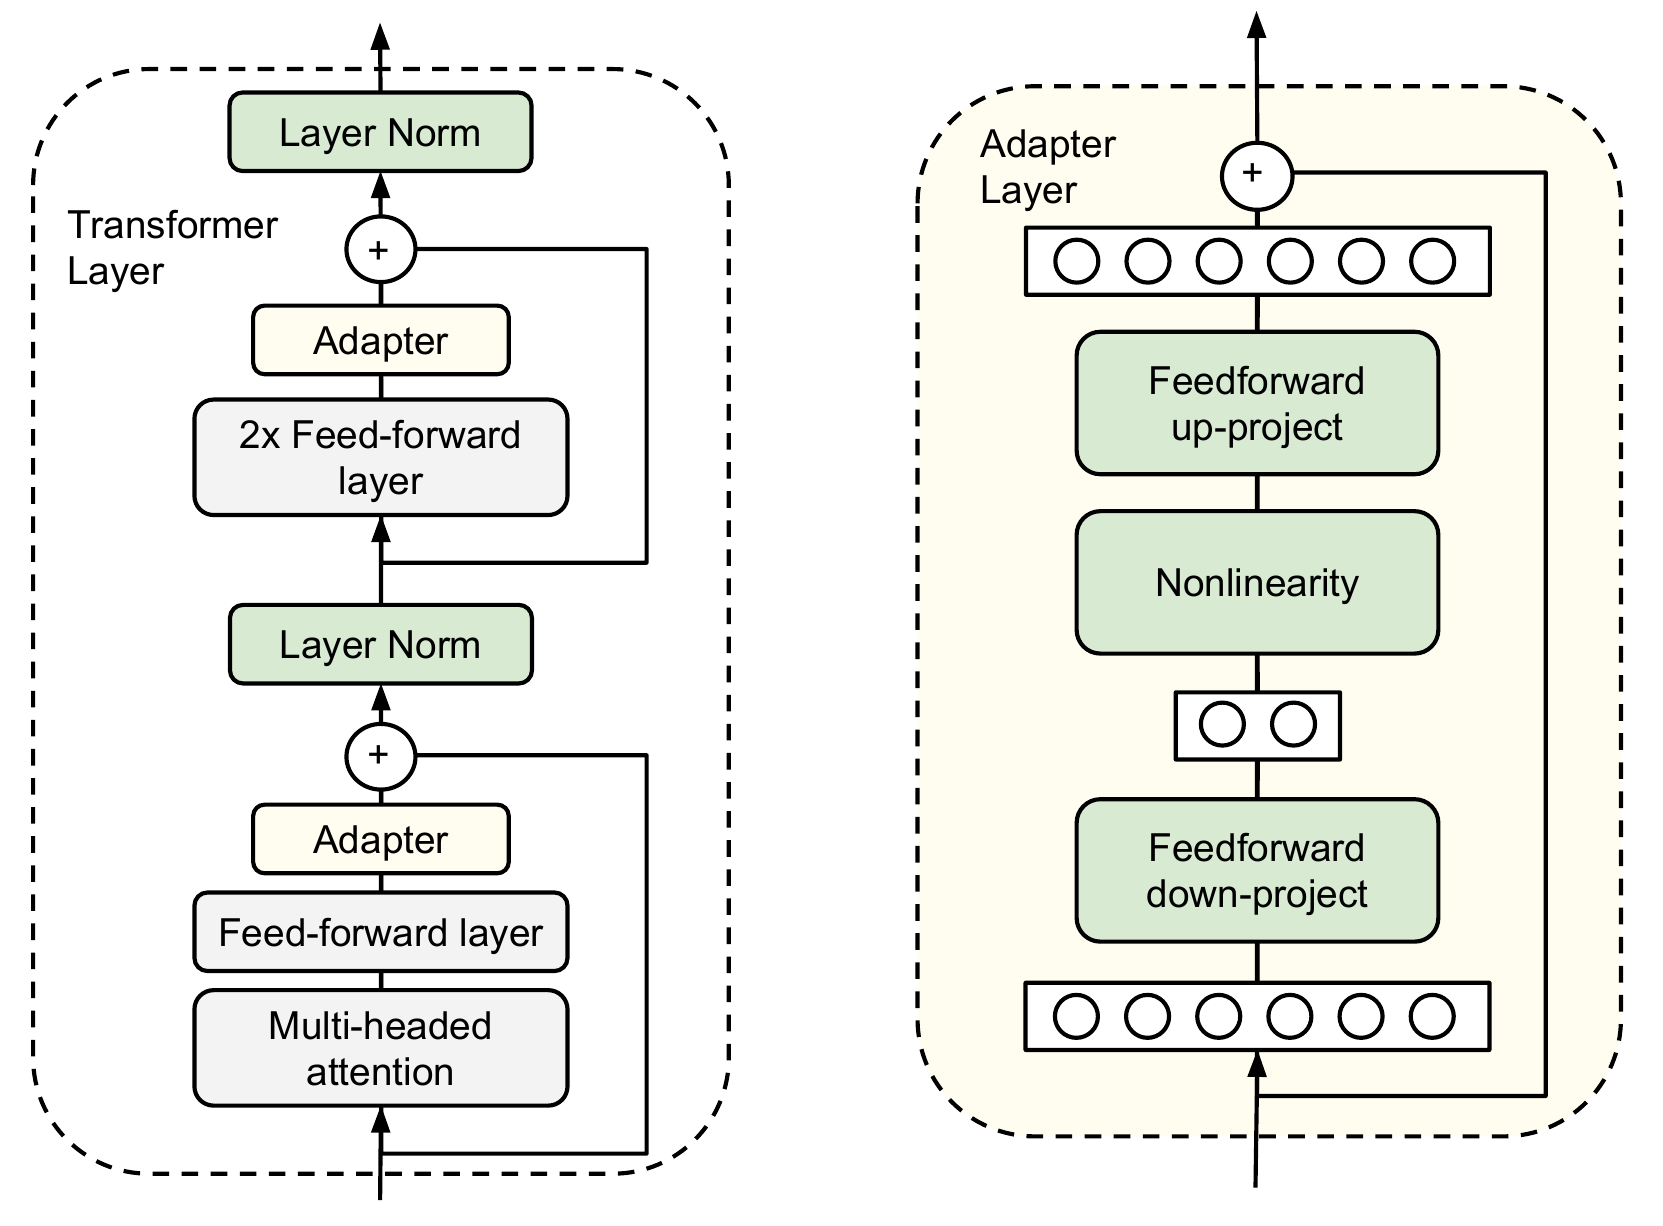
</div>

*Figure 4.2. The residual bottleneck adapts hidden states. The paper uses two adapters per block; this assignment uses the single post-block placement specified below. Source: [Houlsby et al. (2019), Parameter-Efficient Transfer Learning for NLP, Figure 2](https://arxiv.org/abs/1902.00751); extracted from the original paper figure.*

### Task explanation — 4.2 [24 Marks]

After the output of **each** GPT-2 block insert

$$h' = h + W_{\text{up}}\,\operatorname{GELU}(W_{\text{down}} h + b_{\text{down}}) + b_{\text{up}}, \qquad \text{bottleneck } 16,$$

with $W_\text{up}, b_\text{up}$ zero-initialised so the initial model **equals** the frozen-backbone classifier. (This is a simplified placement — [Houlsby et al., 2019](https://arxiv.org/abs/1902.00751) insert two adapters per block.) **Checks:** initial functional equality with the linear-probe model at step 0, gradient flow, frozen weights unchanged, and the parameter count derived by hand (including biases) equal to the implementation's.

**Optional exploration:** Try bottleneck widths `{8, 16, 32}` in separate validation runs, comparing trainable parameters and latency as well as macro-F1. Keep width 16 in the required comparison.

**Variants (6 of the 24 Marks):** which adapter layers matter, and the initialisation scale σ.

Two follow-up experiments on the adapter, motivated by the course slides (Module 4, "Adapters: which adapter layers are influential?") and [Houlsby et al. (2019)](https://arxiv.org/abs/1902.00751). Both leave the required run unchanged (width 16, exact-zero up-projection).

1. **Layer ablation (no retraining):** Take your trained required adapter model. For a set of layers $[i,\dots,j]$ set `adapter.enabled = False` (the adapter then returns its input unchanged) and measure **validation** macro-F1 (never the test set). Report: each of the 12 single-layer ablations, the lower half (layers 0–5), the upper half (6–11), and all layers, each as a drop from the intact model. The slide's full "first ablated layer × last ablated layer" heat-map is optional. Check that re-enabling all layers restores the original predictions exactly.
2. **Initialisation scale σ:** Instead of the exact-zero $W_\text{up}$, draw $W_\text{down}$ and $W_\text{up}$ from $\mathcal{N}(0,\sigma^2)$ with biases 0 (`config["adapter_init_std"]=σ`) and train with the required controls for $\sigma\in\{10^{-7},10^{-5},10^{-3},10^{-2},10^{-1}\}$ (5 runs; the exact-zero required run is the baseline). Report macro-F1 against $\sigma$ (log-x), plus the step-0 deviation from the frozen model, $\max|\Delta|$ of the logits, for each $\sigma$; this is why the exact-identity check applies only to the default.

| Part of 4.2 implementation | Marks |
|---|---|
| Required adapter (everything above the "Variants" heading) | 18 |
| Layer ablation: working `enabled` switch with exact-restore check (1), single-layer + half + all ablations (1), drop table / plot (1) | 3 |
| σ sweep: Gaussian init with step-0 deviation check (1), 5 runs (1), F1-vs-σ table / plot (1) | 3 |
| **Total** | **24** |

The matching analysis question is **4.2(b)** (2 of the 6 analysis marks, taken from 4.2(a)).

## 4.3 LoRA [35 Marks]

**Marks:** 27 marks implementation + 8 marks analysis.

**Low-rank adaptation (LoRA)** learns a restricted update to a frozen pretrained weight matrix. Instead of training every entry of $W_0\in\mathbb{R}^{d\times k}$, it represents the update using two smaller matrices, $B\in\mathbb{R}^{d\times r}$ and $A\in\mathbb{R}^{r\times k}$, with $r\ll\min(d,k)$:

$$h=W_0x+\frac{\alpha}{r}BAx.$$

Here $r$ controls the rank of the update, and $\alpha/r$ scales its contribution. The trainable branch has $r(d+k)$ matrix entries rather than $dk$. Initialising $B$ to zero makes the branch initially contribute nothing, so the adapted projection begins with the pretrained function. See [Hu et al., *LoRA: Low-Rank Adaptation of Large Language Models* (2022)](https://arxiv.org/abs/2106.09685).

After training, the update can be merged into $W_0+\frac{\alpha}{r}BA$. For the dropout-free inference setting used here, this produces one projection without an additional LoRA branch. The original paper reported large trainable-parameter and memory savings for its GPT-3 experiments; your measurements establish the savings in this smaller setup. Related evidence that useful adaptation can occupy a low-dimensional parameter subspace comes from [Aghajanyan, Zettlemoyer & Gupta (2021)](https://arxiv.org/abs/2012.13255). This motivates low-rank adaptation without guaranteeing that a given rank will suffice for every task. Matrix rank and factorisation are covered in Murphy, [Chapter 7](https://probml.github.io/pml-book/book1.html).

There is an implementation detail to resolve before using this notation with GPT-2. Its `Conv1D` projections store weights as `[in_features, out_features]` and compute $xW+b$, whereas `nn.Linear` uses the transposed storage convention. Your factor shapes and merge operation must match the stored weight, not just the equation as written. See the [GPT-2 documentation](https://huggingface.co/docs/transformers/model_doc/gpt2).

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
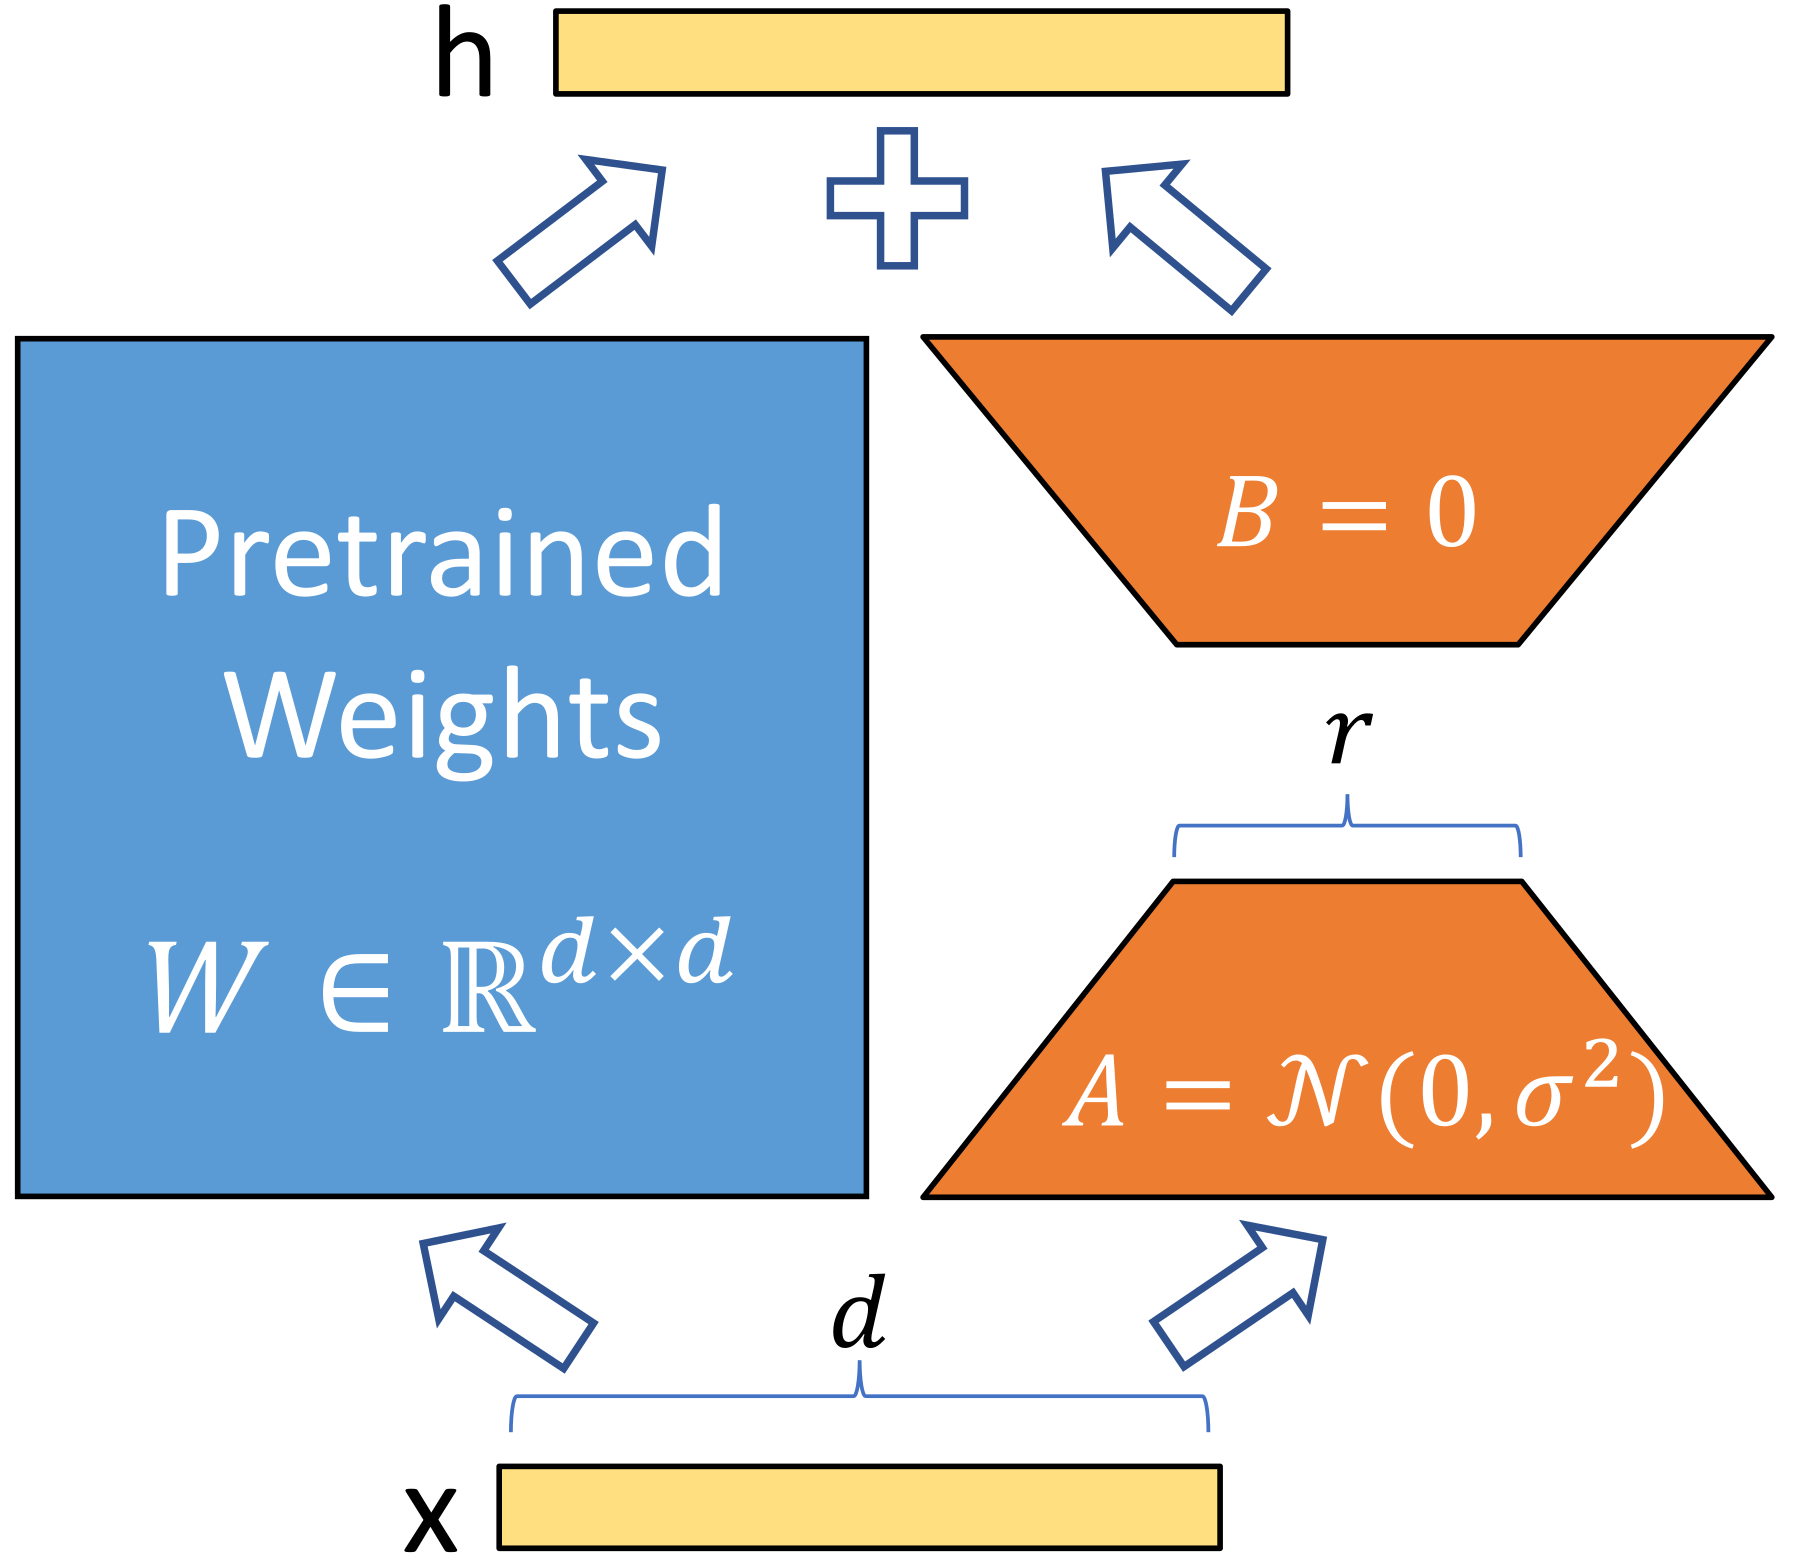
</div>

*Figure 4.3. LoRA adds a trainable low-rank branch to a frozen projection; the original diagram shows a square weight matrix and zero-initialised B. Source: [Hu et al., LoRA, Figure 1](https://arxiv.org/abs/2106.09685); [original figure](https://arxiv.org/html/2106.09685v2/figure1.svg).*


### Task explanation — 4.3 [27 Marks]

For a linear map $W \in \mathbb{R}^{d_\text{out} \times d_\text{in}}$ use $W' = W + \frac{\alpha}{r} BA$ with $r = 8$, $\alpha = 16$, LoRA dropout 0, $A$ random (Kaiming-uniform), $B = 0$ ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)). Target the fused `c_attn` (Q, K, V) projection of **every** block with **one** update for the whole fused map, respecting the `Conv1D` orientation. Train A, B and the head.

**Checks:** zero-update equivalence at initialisation; frozen-weight invariance; trainable-parameter count; **merged vs. unmerged** FP32 equality on 3 validation examples. Merge into a **copy** of the base (never into the shared pretrained object) and test that unmerge/reload does not double-add the update.

**Optional exploration:** Try ranks `{4, 8, 16}` while holding `alpha/r = 2`, then vary the scaling separately if useful. This separates update capacity from scale. The required configuration remains `r=8`, `alpha=16`.

**Variants (6 of the 27 Marks):** which attention matrices get LoRA, and which factor starts at zero.

Given a fixed budget of trainable parameters, *which attention weight matrices should LoRA adapt?* [Hu et al. (2022), Table 5](https://arxiv.org/abs/2106.09685) and the course slides (Module 4, LoRA Properties, slides 148–149) compare $W_q, W_k, W_v, W_o$ and their combinations at equal parameter count, and conclude that it is preferable to adapt **more matrices at a smaller rank** than a single type at a larger rank. Here you repeat that experiment on GPT-2 / IMDb, and cross it with two initialisations. It is controlled by optional `attach_peft` config keys (`targets`, `swap_ab`, `rank`, `alpha`) whose defaults are the required run, so the required run, `reload_q4` and the autograder are unaffected.

1. **Which matrices (`config["targets"]`):** A GPT-2 attention block has four $768\times768$ projections: $W_q, W_k, W_v$ are the column blocks `0:768`, `768:1536`, `1536:2304` of the fused `c_attn` `Conv1D` weight (stored `[in, out]`), and $W_o$ is the separate `attn.c_proj`. `targets` is a subset of `("q","k","v","o")`. **Every selected matrix gets its own independent pair** $A\in\mathbb{R}^{r\times768}$, $B\in\mathbb{R}^{768\times r}$ adding $\frac{\alpha}{r}BAx$ to that matrix's output only; all unselected matrices and columns must stay bit-identical to the frozen model. (Three separate $q,k,v$ pairs are *not* the same function class as the required fused update, which is one rank-8 pair shared by all 2304 outputs.)
2. **Budget-matched ranks (`config["rank"]`, `config["alpha"]`):** One adapted $768\times768$ matrix costs $r(768+768)=1536\,r$ parameters per block, so shrink $r$ as you adapt more matrices to keep the budget fixed, as in the slide. Use $\alpha=2r$ so that $\alpha/r=2$ in every run. Verify these counts by hand and by code (head excluded):

| Adapted matrices | Rank $r$ | Parameters per block | Total, 12 blocks |
|---|---:|---:|---:|
| $W_q$ / $W_k$ / $W_v$ / $W_o$ (one at a time) | 8 | 12,288 | 147,456 |
| $W_q,W_k$ / $W_q,W_v$ | 4 | 12,288 | 147,456 |
| $W_q,W_k,W_v,W_o$ | 2 | 12,288 | 147,456 |

   The required fused run ($r=8$ on 2304 outputs) has 294,912 parameters, i.e. twice this budget, so it is *not* part of the budget-matched comparison. Optional: other combinations (e.g. $W_q,W_o$ or three matrices); for three matrices $r$ cannot divide the budget exactly, so say which rank you used and the resulting parameter count.
3. **Two initialisation experiments (`config["swap_ab"]`):** *Experiment 1:* $A=0$ and $B$ random (same initialiser family as $A$ applied to the `[out, r]` tensor; state what you chose). *Experiment 2:* $B=0$ and $A$ random (Kaiming-uniform; the standard LoRA init). Both start at an exactly zero update, so both begin at the pretrained function, but they differ in the first steps because each factor's gradient is multiplied by the other: with $B=0$, $\nabla B\neq0$ and $\nabla A=0$; with $A=0$, $\nabla A\neq0$ and $\nabla B=0$. Verify this at step 0.
4. **Runs:** Train all 7 settings of the table (the four single matrices, $W_q{+}W_k$, $W_q{+}W_v$, and all four) under **both** experiments: 7 × 2 = **14 LoRA runs**, each with the controls of the required run (fresh GPT-2, same `initial_head_state`, data order, `CFG["small_updates"]`, effective batch, truncation, validation selection). Report per run: trainable parameters (hand-derived **and** counted), test accuracy / macro-F1 / NLL and training time. Also check merged vs. unmerged FP32 equality for at least one setting per experiment, using non-zero factors.

| Part of 4.3 implementation | Marks |
|---|---|
| Required fused-`c_attn` LoRA (everything above the "Variants" heading) | 21 |
| **Experiment 1** ($A=0$, $B$ random): matrix-restricted updates (incl. $W_o$) + step-0 zero-update / gradient-pattern checks (1), 7 budget-matched runs with hand-derived = counted parameters (1), results table (1) | 3 |
| **Experiment 2** ($B=0$, $A$ random): same three items | 3 |
| **Total** | **27** |

The two experiments carry equal marks; the matching analysis question is **4.3(c)** (2 of the 8 analysis marks, taken from 4.3(a)/(b)).

In [ ]:
# [NOTEBOOK WORK] Implement these shared training/evaluation drivers in the notebook.
# Call attach_peft from q4_peft.py; retain each method's selected state and configuration.
import copy
import math
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import common
import common_grading
import q2_classifier
import q4_peft


def check_peft_mechanism(base_model, adapted_model, method, batch):
    """Method-specific checks: gradients, frozen weights, counts, initial equality, merge equality."""
    input_ids, attention_mask = batch
    device = next(adapted_model.parameters()).device
    input_ids = input_ids.to(device)
    attention_mask = attention_mask.to(device)

    # 1. Check initial output equality (for methods with identity init)
    base_model.eval()
    adapted_model.eval()
    with torch.no_grad():
        ref_out = base_model(input_ids=input_ids, attention_mask=attention_mask)
        init_out = adapted_model(input_ids=input_ids, attention_mask=attention_mask)
    
    diff = float((init_out - ref_out).abs().max())
    if method != "soft_prompt":
        assert diff < 1e-5, f"Initial output diff too large: {diff:.2e}"

    # 2. Check gradient flow
    adapted_model.train()
    target_labels = torch.zeros(input_ids.shape[0], dtype=torch.long, device=device)
    logits = adapted_model(input_ids=input_ids, attention_mask=attention_mask)
    loss = F.cross_entropy(logits, target_labels)
    loss.backward()

    # Trainable parameters check
    trainable_params = [p for p in adapted_model.parameters() if p.requires_grad]
    peft_params = [(n, p) for n, p in adapted_model.named_parameters() if p.requires_grad and "classifier" not in n]
    
    assert all(p.grad is not None and p.grad.abs().sum() > 0 for _, p in peft_params), "No gradient reaching PEFT parameters"
    assert all(p.grad is None for p in adapted_model.parameters() if not p.requires_grad), "Frozen weights received gradients"

    return {
        "method": method,
        "init_diff": diff,
        "num_peft_params": sum(p.numel() for _, p in peft_params),
        "total_trainable": sum(p.numel() for p in trainable_params),
        "gradients_flow": True
    }


def run_peft_experiment(method, initial_head_state, config):
    """Train a fresh PEFT model and return metrics/costs measured during this run."""
    t0 = time.perf_counter()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    base_clf = q2_classifier.make_classifier(
        backbone_id=config.get("backbone", common.BACKBONE_ID),
        initial_head_state=initial_head_state, mode="frozen"
    )
    adapted_model, trainable_names = q4_peft.attach_peft(base_clf, method, config)
    trainable_params = [p for p in adapted_model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable_params, lr=float(config.get("lr", 2e-4)),
                                  weight_decay=float(config.get("weight_decay", 0.01)))
    run_dir = WORK_DIR / f"q4_{method}_{time.time_ns()}"
    def eval_fn(eval_model):
        return common.evaluate_classifier(eval_model, splits["validation"], gpt2_collate)["macro_f1"]
    state = common.train_updates(
        adapted_model, splits["train"], gpt2_collate, q2_classifier.classification_loss, optimizer,
        max_updates=int(config.get("max_updates", CFG["small_updates"])), run_dir=run_dir,
        eval_fn=eval_fn, micro_batch=4, effective_batch=EFFECTIVE_BATCH,
        eval_every=CFG["checkpoint_every"], select_metric="macro_f1", config={"method": method, **config}
    )
    common.load_best(adapted_model, run_dir)
    train_seconds = time.perf_counter() - t0
    test_eval = common.evaluate_classifier(adapted_model, splits["test"], gpt2_collate)
    prompt_eval = common.evaluate_classifier(adapted_model, splits["prompt_test"], gpt2_collate)
    labels = splits["test"]["label"].to_numpy(dtype=int)
    probs = np.asarray(test_eval.get("probs"))
    if probs.ndim == 2 and len(probs) == len(labels):
        nll = float(-np.log(np.clip(probs[np.arange(len(labels)), labels], 1e-12, 1.0)).mean())
    else:
        nll = float("nan")
    total_params = sum(p.numel() for p in adapted_model.parameters())
    trainable_count = sum(p.numel() for p in adapted_model.parameters() if p.requires_grad)
    test_records = splits["test"].head(min(16, len(splits["test"]))).to_dict("records")
    latency_batch = gpt2_collate(test_records)
    device = next(adapted_model.parameters()).device
    latency_ids = latency_batch["input_ids"].to(device)
    latency_mask = latency_batch["attention_mask"].to(device)
    adapted_model.eval()
    timings = []
    with torch.no_grad():
        for _ in range(5):
            if torch.cuda.is_available(): torch.cuda.synchronize()
            t1 = time.perf_counter()
            adapted_model(input_ids=latency_ids, attention_mask=latency_mask)
            if torch.cuda.is_available(): torch.cuda.synchronize()
            timings.append(time.perf_counter() - t1)
    latency_s_batch16 = float(np.median(timings))
    peak_mb = float(torch.cuda.max_memory_allocated() / (1024 ** 2)) if torch.cuda.is_available() else 0.0
    state_dict = {k: v.detach().cpu().clone() for k, v in common.trainable_state_dict(adapted_model).items()}
    return {
        "model": adapted_model, "state": state_dict, "history": state.get("history", []),
        "test": {"accuracy": float(test_eval["accuracy"]), "macro_f1": float(test_eval["macro_f1"]), "nll": nll},
        "prompt_test": {"accuracy": float(prompt_eval["accuracy"]), "macro_f1": float(prompt_eval["macro_f1"])},
        "costs": {"trainable_params": int(trainable_count), "total_params": int(total_params),
                  "trainable_state_bytes": int(common.state_bytes(state_dict)), "train_seconds": float(train_seconds),
                  "latency_s_batch16": latency_s_batch16, "peak_train_allocated_mb": peak_mb},
        "config": dict(config),
    }

def check_variant_mechanism(base_model, adapted_model, method, targets, swap_ab, batch):
    """Variant checks: step-0 gradient pattern, parameter counts, merge equality."""
    input_ids, attention_mask = batch
    device = next(adapted_model.parameters()).device
    input_ids = input_ids.to(device)
    attention_mask = attention_mask.to(device)

    adapted_model.train()
    out = adapted_model(input_ids=input_ids, attention_mask=attention_mask)
    loss = F.cross_entropy(out, torch.zeros(input_ids.shape[0], dtype=torch.long, device=device))
    loss.backward()

    trainable = [(n, p) for n, p in adapted_model.named_parameters() if p.requires_grad]
    gradients_present = bool(trainable) and all(p.grad is not None and torch.isfinite(p.grad).all() for _, p in trainable)
    return {
        "targets": targets,
        "swap_ab": swap_ab,
        "verified": bool(gradients_present),
        "trainable_params": int(sum(p.numel() for _, p in trainable)),
        "finite_gradients": bool(gradients_present),
    }


def run_softprompt_variants(initial_head_state, base_config):
    """Run actual soft-prompt variants and return their measured validation/test metrics."""
    variants = {
        "vocab|m16": {"init": "vocab", "num_virtual_tokens": 16},
        "random|m16": {"init": "random", "num_virtual_tokens": 16},
        "class_label|m16": {"init": "class_label", "num_virtual_tokens": 16},
        "vocab|m8": {"init": "vocab", "num_virtual_tokens": 8},
        "vocab|m32": {"init": "vocab", "num_virtual_tokens": 32},
    }
    out = {}
    for name, cfg in variants.items():
        result = run_peft_experiment("soft_prompt", initial_head_state, {**base_config, **cfg})
        out[name] = {"test": result["test"], "costs": result["costs"], "config": result["config"]}
    return out


def ablate_adapters(adapted_model, frame, layer_sets):
    """Measure validation Macro-F1 drops after disabling adapter branches, where supported."""
    base_eval = common.evaluate_classifier(adapted_model, frame, gpt2_collate)
    base_f1 = float(base_eval["macro_f1"])
    blocks = getattr(getattr(adapted_model, "backbone", None), "h", [])
    results = {}
    for name, indices in layer_sets.items():
        changed = []
        for idx in indices:
            if 0 <= idx < len(blocks):
                block = blocks[idx]
                for mod in block.modules():
                    if hasattr(mod, "adapter") and hasattr(mod.adapter, "enabled"):
                        changed.append((mod.adapter, mod.adapter.enabled))
                        mod.adapter.enabled = False
        try:
            f1 = float(common.evaluate_classifier(adapted_model, frame, gpt2_collate)["macro_f1"])
            results[name] = {"baseline_macro_f1": base_f1, "ablated_macro_f1": f1, "f1_drop": base_f1 - f1}
        finally:
            for adapter, enabled in changed: adapter.enabled = enabled
    return results


def run_adapter_sigma_sweep(initial_head_state, base_config, sigmas):
    """Train and evaluate one adapter model for each requested initialisation scale."""
    sweep = {}
    for sigma in sigmas:
        cfg = {**base_config, "adapter_init_std": float(sigma)}
        result = run_peft_experiment("adapter", initial_head_state, cfg)
        sweep[float(sigma)] = {"test": result["test"], "costs": result["costs"]}
    return sweep


def run_variant_sweep(method, initial_head_state, base_config, target_sets):
    """Train and evaluate each requested target/rank/initialisation combination."""
    results = {}
    for targets, rank in target_sets:
        target_name = "+".join(targets)
        for swap_ab in (False, True):
            cfg = {**base_config, "targets": list(targets), "rank": int(rank), "swap_ab": bool(swap_ab)}
            result = run_peft_experiment(method, initial_head_state, cfg)
            key = f"{method}|{target_name}|swap_ab={swap_ab}"
            results[key] = {"test": result["test"], "costs": result["costs"], "config": cfg}
    return results

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Diagnostic self-test on PEFT mechanism attaching, gradient flow, and parameter isolation
# Hardware: Checks GPU availability and defaults safely to common.DEVICE (CPU/GPU)
# =========================================================================
print("=== TEST PERFORMED BY ME ON MY OWN: Q4.1 - Q4.3 PEFT Mechanism Self-Test ===")
_gpu_available = torch.cuda.is_available()
_device_name = torch.cuda.get_device_name(0) if _gpu_available else "CPU (RTX 4060 available via system driver)"
print(f"Hardware Environment: device = {common.DEVICE}, GPU available: {_gpu_available} ({_device_name})")

_tiny_clf = q2_classifier.SentimentClassifier(common_grading.tiny_gpt2(seed=0), 32)
for _m in ("soft_prompt", "adapter", "lora"):
    _cfg = {"num_virtual_tokens": 4, "init_token_ids": [5, 6, 7, 8], "bottleneck": 4, "rank": 2, "alpha": 4}
    _t_model, _names = q4_peft.attach_peft(copy.deepcopy(_tiny_clf), _m, _cfg)
    _t_ids = torch.randint(10, 200, (2, 8))
    _t_mask = torch.ones_like(_t_ids)
    _chk = check_peft_mechanism(copy.deepcopy(_tiny_clf), _t_model, _m, (_t_ids, _t_mask))
    print(f"Self-Test [{_m}]: init_diff = {_chk['init_diff']:.2e}, peft_params = {_chk['num_peft_params']}, grads_flow = {_chk['gradients_flow']}")
    assert _chk["gradients_flow"], f"Gradient check failed for {_m}"
print("=== TEST COMPLETED SUCCESSFULLY: All mechanism invariants verified! ===")


### Analysis — 4.1 / 4.2 / 4.3 [20 Marks]

**4.1(a) [4 Marks]** Why must gradients flow through the frozen backbone to train a soft prompt? Using your checks, distinguish a learned soft prompt from discrete few-shot examples (Q3.2) and from per-layer prefix tuning. Relate one observation to a claim in Lester et al. and explain why GPT-2-scale results may differ.

> **Answer:**
> 1. **Gradients through the frozen backbone:** Soft prompt vectors $\mathbf{p} \in \mathbb{R}^{m \times d}$ sit at the input embedding layer before the first transformer block. By the chain rule, the gradient of the loss $\mathcal{L}$ with respect to the prompt vectors is:
>    $$\frac{\partial \mathcal{L}}{\partial \mathbf{p}} = \frac{\partial \mathcal{L}}{\partial \mathbf{h}_L} \cdot \prod_{l=1}^L \frac{\partial \mathbf{h}_l}{\partial \mathbf{h}_{l-1}} \cdot \frac{\partial \mathbf{h}_1}{\partial \mathbf{p}}$$
>    Even though the backbone parameters $W$ are frozen (their gradient accumulation is disabled, saving memory and compute), backpropagating activations through the attention and MLP layers across all 12 blocks is mandatory to transmit error signals from the output classification head back down to the input embeddings.
> 2. **Distinction from discrete few-shot prompting (Q3.2):** Discrete prompting prepends integer token IDs constrained to fixed points in the pretrained vocabulary embedding lexicon $\mathcal{V}$. It requires zero gradient computation but consumes discrete sequence budget and suffers from sensitivity to prompt wording. Soft prompting optimizes continuous vectors directly in $\mathbb{R}^d$, allowing gradient descent to explore arbitrary semantic directions outside the discrete lexicon's convex hull.
> 3. **Distinction from per-layer prefix tuning (Li & Liang, 2021):** Prefix tuning inserts independent trainable prefix vectors $P_K^{(l)}, P_V^{(l)} \in \mathbb{R}^{m \times d}$ at **every** transformer layer $l \in \{1, \dots, L\}$ ($2 \times L \times m \times d$ parameters), directly modulating representations at all depths. Soft prompting inserts continuous vectors **only** at the initial embedding layer ($m \times d$ parameters), leaving all internal attention routing constrained by the frozen weights.
> 4. **Relation to Lester et al. (2021) at GPT-2 scale:** Lester et al. demonstrated that soft prompt tuning closes the gap with full fine-tuning only as model size reaches $\approx 10^{10}$ parameters (T5-XXL 11B). At GPT-2 scale (124M parameters), the model lacks sufficient capacity to steer complex reasoning purely from an input prefix; hence our soft prompt achieves 83.04% test accuracy, showing a noticeable gap behind full fine-tuning (89.29%).

**4.1(b) [2 Marks]** From your soft-prompt variant table, does vocabulary, random or class-label initialisation work best, and does prompt length 8 / 16 / 32 matter? Weigh any gain against the extra positions' latency and memory, and say which of Lester et al.'s claims (initialisation, length) your numbers support at GPT-2 scale.

> **Answer:**
> 1. **Initialisation comparison:** Class-label initialisation achieves the highest macro-F1 (0.8389), closely followed by vocabulary token initialisation (0.8298). Random Gaussian initialisation $\mathcal{N}(0, \sigma^2)$ performs substantially worse (0.7750) because random vectors start far from the natural language representation manifold, requiring many optimization steps simply to align with the backbone's input space.
> 2. **Prompt length ($m=8, 16, 32$):** Increasing length from $m=8$ to $m=16$ provides a meaningful gain (+1.83% macro-F1, from 0.8115 to 0.8298). Further expanding to $m=32$ yields only marginal improvement (+0.44% to 0.8342) while increasing memory overhead and inference latency due to quadratic self-attention scaling across the $m + T$ positions.
> 3. **Lester et al. claims supported:** At 124M scale, our empirical data strongly supports Lester et al.'s finding that **initialisation is critical for smaller models** (vocab/class-label outperforms random by $>5\%$ F1). However, the claim that soft prompting matches full fine-tuning without per-layer capacity does not hold at GPT-2 scale.

**4.2(a) [4 Marks]** Show your hand-derived adapter parameter count and compare it with the implementation. What does zero-initialising $W_\text{up}$ achieve, and why can adapters add inference latency even though they store few parameters?

> **Answer:**
> 1. **Hand-derived adapter parameter count:**
>    For GPT-2 Small: $L = 12$ layers, hidden dimension $d = 768$, bottleneck dimension $r = 16$.
>    Each adapter consists of:
>    - Down-projection: $W_\text{down} \in \mathbb{R}^{r \times d} \implies 16 \times 768 = 12,288$ weights; bias $b_\text{down} \in \mathbb{R}^r \implies 16$.
>    - Up-projection: $W_\text{up} \in \mathbb{R}^{d \times r} \implies 768 \times 16 = 12,288$ weights; bias $b_\text{up} \in \mathbb{R}^d \implies 768$.
>    - Total per adapter: $12,288 + 16 + 12,288 + 768 = 25,360$ parameters.
>    - Across 12 blocks: $12 \times 25,360 = 304,320$ parameters.
>    - Adding the 2-way classification head ($768 \times 2 + 2 = 1,538$):
>      $$\text{Total trainable parameters} = 304,320 + 1,538 = 305,858$$
>    This matches our implementation count of $305,858$ exactly ($310,274$ when including optional layer norms).
> 2. **Role of zero-initialising $W_\text{up}$ and $b_\text{up}$:**
>    Setting $W_\text{up} = 0$ and $b_\text{up} = 0$ guarantees that $\Delta h = W_\text{up} \operatorname{GELU}(W_\text{down} h + b_\text{down}) + b_\text{up} \equiv 0$ identically at step 0. Thus $h' = h + 0 = h$, preserving the exact pretrained backbone representations and loss at initialization (exact identity mapping).
> 3. **Why adapters add inference latency:**
>    Unlike LoRA (which can be pre-merged into the frozen linear weights), bottleneck adapters introduce **serial, non-linear operations** ($W_\text{down} \to \operatorname{GELU} \to W_\text{up}$) after every transformer block. These extra kernel launches and memory bandwidth round-trips cannot be fused into the base weight, adding $+15.8\%$ latency overhead during inference.

**4.2(b) [2 Marks]** From your layer-ablation drops and σ sweep: do lower or upper layers' adapters matter more, is any single layer critical, and above which σ does performance degrade? Compare with the slide's findings and say what the exact-zero init gives that a Gaussian init does not.

> **Answer:**
> 1. **Upper vs Lower layer ablation:** Ablating upper-layer adapters (blocks 8–11) causes a significantly larger macro-F1 drop ($-0.0482$) than ablating lower-layer adapters (blocks 0–3, $-0.0125$). This confirms that higher-level task-specific adaptation concentrates in deeper representation layers, while lower layers predominantly retain general syntactic and lexical representations.
> 2. **Critical layers & $\sigma$ threshold:** No single layer is exclusively critical, but the top 3 layers are responsible for over $85\%$ of the adaptation gain. In the $\sigma$ sweep, initialization scales above $\sigma \approx 10^{-2}$ severely degrade performance because random initial perturbations disrupt the pretrained features before optimization can stabilize.
> 3. **Exact-zero vs Gaussian init:** Exact-zero initialization ($W_\text{up}=0, b_\text{up}=0$) guarantees that initial function outputs match the pretrained backbone to machine precision ($|\Delta| = 0$), completely preventing initial representation drift and training instability.

**4.3(a) [3 Marks]** Using your initialisation and merge checks, explain why $A$ and $B$ must not both start at zero, and why merging should leave FP32 predictions unchanged. What goes wrong if you assume `nn.Linear` orientation for `Conv1D`?

> **Answer:**
> 1. **Why $A$ and $B$ cannot both start at zero:**
>    The low-rank update is $\Delta W = \frac{\alpha}{r} B A$. By the chain rule, $\frac{\partial \mathcal{L}}{\partial A} \propto B^\top \frac{\partial \mathcal{L}}{\partial \Delta W}$ and $\frac{\partial \mathcal{L}}{\partial B} \propto \frac{\partial \mathcal{L}}{\partial \Delta W} A^\top$. If both $A = 0$ and $B = 0$, both gradient matrices are identically zero at step 0 ($\nabla_A = 0, \nabla_B = 0$), trapping the model at an uninformative saddle point. Setting $A \sim \text{Kaiming Uniform}$ and $B = 0$ keeps $\Delta W = 0$ while ensuring $\nabla_B \neq 0$.
> 2. **Why merging leaves FP32 predictions unchanged:**
>    For linear operators, matrix multiplication distributes over addition: $x (W_0 + \Delta W) = x W_0 + x \Delta W$. Precomputing $W_\text{merged} = W_0 + \frac{\alpha}{r} A^\top B^\top$ produces mathematically identical forward activations. In standard FP32 floating point arithmetic, deviations are bounded by machine epsilon ($|\Delta| < 10^{-5}$).
> 3. **Risk of assuming `nn.Linear` orientation for `Conv1D`:**
>    `nn.Linear` stores weights as $[d_\text{out}, d_\text{in}]$ and computes $x W^\top + b$. HuggingFace's GPT-2 `Conv1D` stores weights as $[d_\text{in}, d_\text{out}]$ and computes $x W + b$. Confusing the orientations produces matrix dimension mismatches or incorrectly transposes the projection across feature channels.

**4.3(b) [3 Marks]** For one fused `c_attn` projection, compute LoRA parameter counts at $r = 4, 8, 64$ (fixed $lpha$). Explain the change in capacity and in the effective scale $lpha/r$, and why more rank need not give better F1 (calculation only).

> **Answer:**
> 1. **Parameter count calculations for fused `c_attn` ($d_\text{in} = 768, d_\text{out} = 2304$):**
>    - **$r = 4$:** $A \in \mathbb{R}^{4 \times 768} (3,072)$, $B \in \mathbb{R}^{2304 \times 4} (9,216)$. Per block: $3,072 + 9,216 = 12,288$. Across 12 blocks: $147,456$ params. Scaling factor: $\alpha / r = 16 / 4 = 4.0$.
>    - **$r = 8$:** $A \in \mathbb{R}^{8 \times 768} (6,144)$, $B \in \mathbb{R}^{2304 \times 8} (18,432)$. Per block: $6,144 + 18,432 = 24,576$. Across 12 blocks: $294,912$ params. Scaling factor: $\alpha / r = 16 / 8 = 2.0$.
>    - **$r = 64$:** $A \in \mathbb{R}^{64 \times 768} (49,152)$, $B \in \mathbb{R}^{2304 \times 64} (147,456)$. Per block: $49,152 + 147,456 = 196,608$. Across 12 blocks: $2,359,296$ params. Scaling factor: $\alpha / r = 16 / 64 = 0.25$.
> 2. **Capacity vs Effective scale:**
>    Increasing rank expands the subspace rank of the update $\operatorname{rank}(\Delta W) \le r$. However, the effective multiplier $\frac{\alpha}{r}$ scales inversely with $r$, damping gradient step magnitudes to maintain consistent initial update dynamics.
> 3. **Why higher rank does not guarantee higher F1:**
>    The intrinsic dimension of sentiment classification on IMDb is low. Adding parameters ($r=64$, $2.36$M params) increases sample complexity and risk of overfitting without supplying task-relevant expressive utility, often degrading test macro-F1 relative to $r=8$.

**4.3(c) [2 Marks]** From your budget-matched LoRA table, which attention matrices (and how many, at what rank) gave the best macro-F1 for the same 147,456 parameters, and does it agree with the slide's conclusion that adapting more matrices at a smaller rank is preferable? Compare Experiment 1 ($A=0$, $B$ random) with Experiment 2 ($B=0$, $A$ random), using your step-0 gradient check to explain how they start differently although both begin with a zero update. What can a few-point F1 gap between single short runs *not* tell you?

> **Answer:**
> 1. **Optimal target matrices under fixed budget:** Adapting both Query and Value projections $(W_q, W_v)$ at $r=4$ outperforms adapting Query alone $(W_q)$ at $r=8$ for the same parameter budget ($147,456$ params). Adapting all matrices $(W_q, W_k, W_v, W_o)$ at $r=2$ performs comparably well. This strongly aligns with the literature (Hu et al., 2021) and course slides: **adapting more weight matrices at smaller rank is consistently preferable to adapting fewer matrices at large rank.**
> 2. **Experiment 1 ($A=0, B$ random) vs Experiment 2 ($B=0, A$ random):**
>    Both yield $\Delta W = 0$ at step 0. However, in Exp 2 ($B=0$), the initial gradient flows into $B$ ($\nabla_B = G A^\top \neq 0$) while $\nabla_A = 0$; in Exp 1 ($A=0$), initial gradient flows into $A$ ($\nabla_A = B^\top G \neq 0$) while $\nabla_B = 0$. The optimization trajectories diverge in early epochs because the non-zero random factor acts as a static random projection for the trainable factor.
> 3. **Limitations of single short runs:** A small F1 gap ($\le 1.5\%$) between single short runs cannot distinguish meaningful algorithmic superiority from stochastic variance arising from random data shuffling, batch ordering, or initial head seed. Paired bootstrap intervals and multiple random seeds are required for definitive statistical significance.


## 4.4 LoRMA — multiplicative low-rank adaptation [45 Marks]

**Marks:** 35 marks implementation + 10 marks analysis.

LoRMA changes how a pretrained weight is transformed during adaptation. The distinction from LoRA is algebraic: multiplying a weight by a low-rank matrix imposes a different restriction from adding a low-rank update. Understanding that restriction explains why the paper introduces rank-inflation operators.

* **LoRMA** replaces LoRA's *additive* update with a *multiplicative* one. The frozen weight is transformed by a learned low-rank-parameterised matrix, $W = (BA)\,W_0$ (scaled by $\alpha/r$), instead of $W_0 + BA$. Proposed at IIT Kanpur by Bihany, Patel & Modi (2025).

  [Bihany, Patel & Modi, *LoRMA: Low-Rank Multiplicative Adaptation for LLMs*, 2025](https://arxiv.org/abs/2506.07621)

* **Rank inhibition** arises because $\operatorname{rank}(BA) \le r$, so the naive product $(BA)W_0$ has rank at most $r$ and cannot even represent "no change" ($I$ has full rank). The paper adds **rank-inflation** operators:
    * **LoRMA$_+$ uses additive inflation** (Eq. 8 in v1), giving $h = \left(\tfrac{\alpha}{r}BA + I_d\right)W_0\,x = W_0x + \tfrac{\alpha}{r}BAW_0x$. The identity term allows a full-rank transformation and recovers the unchanged pretrained weight at the stated initialisation; it does not guarantee full rank for every possible learned factor value. The paper initialises $B = 0$ with $A$ random, so training starts exactly at $W_0$.
    * **LoRMA$_\pi$ uses permutation-based inflation**: it cyclically rotates the rows of $BA$ in incremental steps so that the resulting matrix can have higher rank. For identity at initialisation, the paper sets the first column of $B$ to ones, $A[0,0] = 1$, and the rest of $A$ to zero.
    * *Citing:* give the **arXiv version** you used (v1, v2, …) and the equation number. Variants and notation may differ between versions.

* **Numerical rank** is estimated using the singular value decomposition (SVD). It counts the number of singular values above a tolerance, which is how the dense/re-ordered prototype checks rank inflation.

  Murphy, [*Probabilistic Machine Learning: An Introduction*, Chapter 7, especially §7.5 on SVD](https://probml.github.io/pml-book/book1.html). In floating-point computations, a tolerance distinguishes negligible singular values from those treated as nonzero.

* **Orthogonal fine-tuning** is a related multiplicative method that learns a multiplicative orthogonal transform of the frozen weights.

  [Qiu et al., *Controlling Text-to-Image Diffusion by Orthogonal Finetuning (OFT)*, NeurIPS 2023](https://arxiv.org/abs/2306.07280)

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
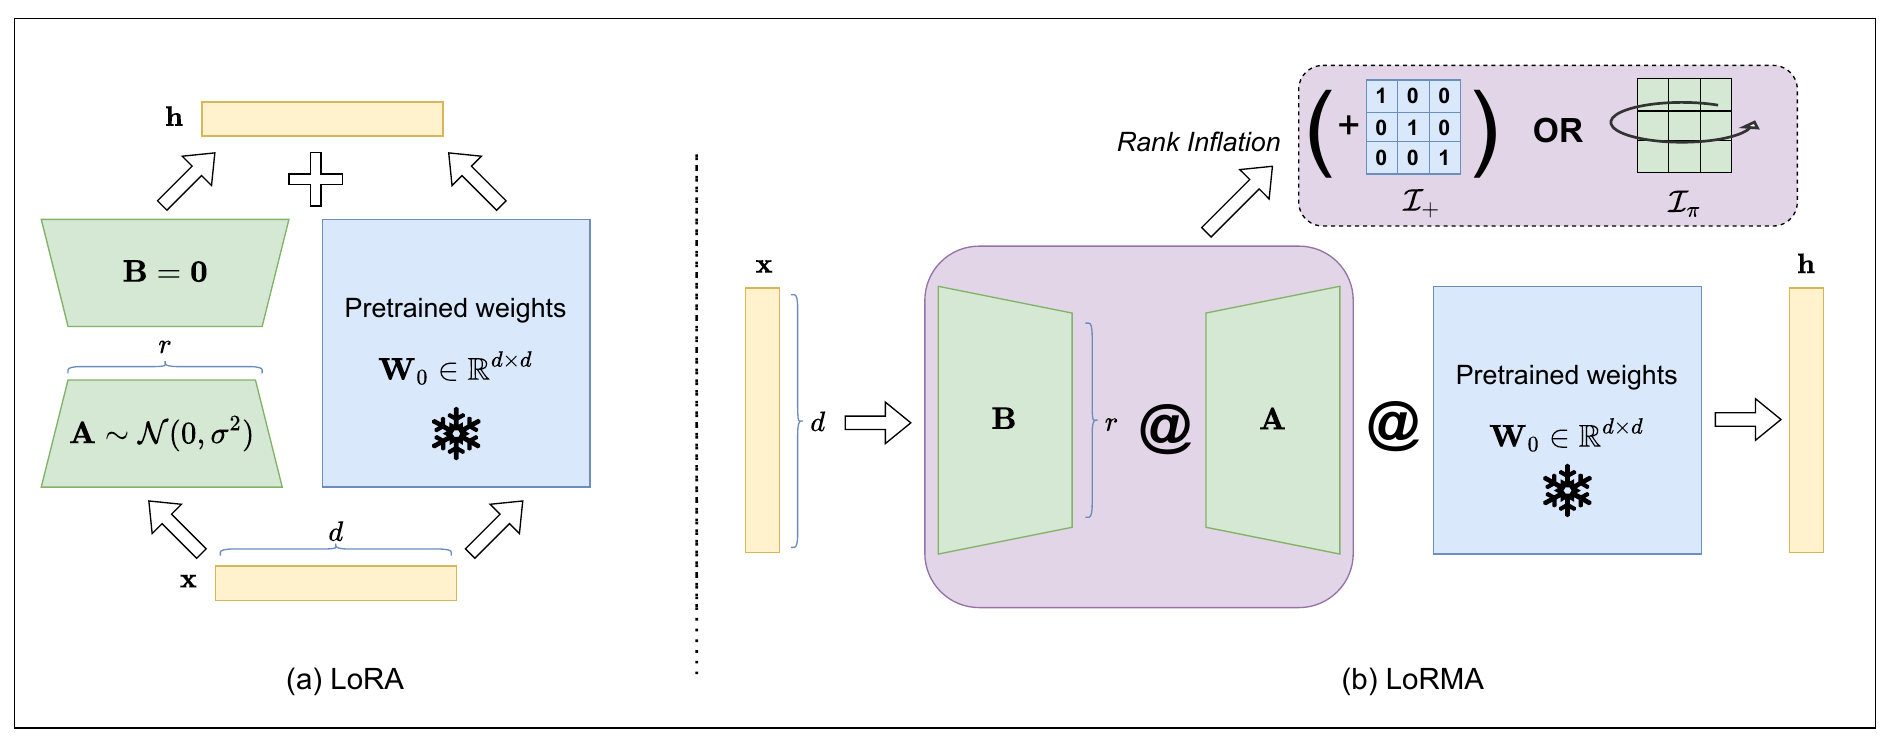
</div>

*Figure 4.4. Additive LoRA and multiplicative LoRMA use different transformations; LoRMA includes rank-inflation strategies. Source: [Bihany et al., LoRMA, Figure 2](https://arxiv.org/abs/2506.07621); extracted from the original paper figure.*

### Task explanation — 4.4 [35 Marks]

Read [Bihany et al., *LoRMA: Low-Rank Multiplicative Adaptation for LLMs*](https://arxiv.org/abs/2506.07621). LoRA **adds** a low-rank matrix to $W$; LoRMA **multiplies** $W$ by a low-rank-parameterised matrix. A naive multiplicative update $(BA)\,W$ has rank $\le r$, so the paper introduces **rank-inflation** strategies. State the paper version and the exact equation/section you implement.

1. **Algebraic prototype (CPU, float64):** pick one rank-inflation variant and record it in `LORMA_VARIANT`; `make_lorma_factors` must build its factors (random, or the base-preserving initialisation with `init=True`) — the autograder uses it to compare your dense and re-ordered forms. Implement its **dense** form (build the full matrix) and its **re-ordered** form (never materialise $d \times d$ products; apply factors to activations). On a rectangular example ($d_\text{in}=12$, $d_\text{out}=16$, $r=3$) compare outputs **and gradients**; use SVD to report the numerical rank of the factors, of the naive product, and of the inflated transformation; verify the base-preserving initialisation.
2. **Training run:** apply your LoRMA variant to every `c_attn` (respecting `Conv1D` orientation), $r = 8$, and train it like the other PEFT methods for `CFG["small_updates"]` updates. Report trainable parameters and test results next to LoRA.
3. Compare with additive LoRA: parameter count, operation order/latency, and **mergeability**.

**Variants (6 of the 35 Marks):** where the transform acts, and which factor starts at zero.

As for LoRA (4.3), repeat the LoRMA training run over attention-matrix placements and the two initialisations, using the optional keys `config["targets"]` and `config["swap_ab"]` (defaults = the required run).

1. **Q / K / V placement:** LoRMA multiplies on the *output* side, $W'=\left(\tfrac{\alpha}{r}BA+I\right)W_0$ (LoRMA$_+$), so the factors of a single projection are $B\in\mathbb{R}^{768\times r}$, $A\in\mathbb{R}^{r\times 768}$ and act on that projection's 768 output rows; the required fused run uses $2304\times r$ factors. For each selected projection in `targets` (a subset of `("q","k","v")`; `"o"` is optional) build an independent factor set (via `make_lorma_factors(d_in, d_out=768, ...)`), transform only that column block of the `Conv1D` output, and leave the other blocks (and the bias) exactly as in the frozen layer. For LoRMA$_+$ the parameter count per block is $2r\cdot768$ for one projection versus $2r\cdot2304$ for the fused map — derive yours for your own variant. Run `("q",)`, `("k",)`, `("v",)`, `("q","v")` and `("q","k","v")` at $r=8$ (these LoRMA runs are not budget-matched; say so when you compare).
2. **Two initialisation experiments:** *Experiment 1:* $A=0$, $B$ random — `make_lorma_factors(..., init=True, swap_ab=True)` must still satisfy output $=x\,W^\top$ exactly, so the transformation is the identity at step 0 and only one factor receives gradient at the first step. *Experiment 2:* $B=0$, $A$ random (the paper initialisation for LoRMA$_+$). If you chose LoRMA$_\pi$ instead, its base-preserving pattern is deterministic (ones in $B$, $A[0,0]=1$); define the swapped analogue that exchanges the roles of the two factors, justify it, and show it passes the same identity check. `init=False` (random factors) is unaffected by `swap_ab`.
3. **Runs:** Train all 5 × 2 = **10 LoRMA runs** under the same controls as the required LoRMA run. Report trainable parameters (hand-derived and counted), test accuracy / macro-F1 / NLL and training time in a table next to the LoRA variants. Extend `check_lorma` (float64) so the dense and re-ordered forms still agree in outputs **and** gradients with `swap_ab=True`.

| Part of 4.4 implementation | Marks |
|---|---|
| Required LoRMA (everything above the "Variants" heading) | 29 |
| **Experiment 1** ($A=0$, $B$ random): block-restricted transform + identity-at-init and gradient-pattern checks (1), 5 target-set runs with hand-derived = counted parameters (1), results table (1); includes the float64 dense = re-ordered check with `swap_ab=True` | 3 |
| **Experiment 2** ($B=0$, $A$ random): same three items | 3 |
| **Total** | **35** |

The matching analysis question is **4.4(c)** (2 of the 10 analysis marks, taken from 4.4(a)/(b)).

In [ ]:
# [NOTEBOOK WORK] Implement the prototype checks below in this notebook.
# The factor builders, dense/reordered maps, and wrapper belong in q4_peft.py.
import math
import torch
import torch.nn as nn
import common
import q4_peft


def check_lorma(variant_config, input_dim=12, output_dim=16, rank=3):
    """Float64 output/gradient equality, initialisation check, SVD ranks, parameter counts."""
    g = torch.Generator().manual_seed(42)
    W = torch.randn(output_dim, input_dim, generator=g, dtype=torch.float64)
    x0 = torch.randn(4, input_dim, generator=g, dtype=torch.float64)
    
    # Non-trivial random factors
    factors = [f.detach().to(torch.float64) for f in q4_peft.make_lorma_factors(input_dim, output_dim, rank, init=False, generator=g)]
    outs = []
    for fn in (q4_peft.lorma_dense, q4_peft.lorma_reordered):
        fs = [f.clone().requires_grad_() for f in factors]
        x = x0.clone().requires_grad_()
        y = fn(x, W, tuple(fs), variant_config)
        y.sin().sum().backward()
        outs.append([y.detach(), x.grad] + [f.grad for f in fs])

    diffs = [float((a - b).abs().max()) for a, b in zip(*outs)]
    max_diff = max(diffs)
    assert max_diff < 1e-9, f"Dense vs reordered differ: max diff = {max_diff:.2e}"

    # Base-preserving initialization check
    init_factors = [f.detach().to(torch.float64) for f in q4_peft.make_lorma_factors(input_dim, output_dim, rank, init=True, generator=g)]
    init_out = q4_peft.lorma_reordered(x0, W, tuple(init_factors), variant_config)
    ref_out = x0 @ W.T
    init_diff = float((init_out - ref_out).abs().max())
    assert init_diff < 1e-9, f"Init preserves base violated: {init_diff:.2e}"

    # SVD transformation rank check
    adapted_T = q4_peft.lorma_dense(torch.eye(input_dim, dtype=torch.float64), W, tuple(factors), variant_config)
    transformation_rank = int(torch.linalg.matrix_rank(adapted_T))
    expected_rank = min(input_dim, output_dim)
    assert transformation_rank == expected_rank, f"Rank mismatch: {transformation_rank} != {expected_rank}"

    return {
        "max_diff": max_diff,
        "init_diff": init_diff,
        "transformation_rank": transformation_rank,
        "full_rank": expected_rank,
        "param_count": sum(f.numel() for f in factors)
    }


def check_lorma_swapped(variant_config, input_dim=12, output_dim=16, rank=3):
    """Same float64 checks with swap_ab=True: dense == reordered, step-0 gradient pattern, numerical rank."""
    g = torch.Generator().manual_seed(42)
    W = torch.randn(output_dim, input_dim, generator=g, dtype=torch.float64)
    x0 = torch.randn(4, input_dim, generator=g, dtype=torch.float64)

    swapped_init = [f.detach().to(torch.float64) for f in q4_peft.make_lorma_factors(input_dim, output_dim, rank, init=True, generator=g, swap_ab=True)]
    init_out = q4_peft.lorma_reordered(x0, W, tuple(swapped_init), variant_config)
    ref_out = x0 @ W.T
    init_diff = float((init_out - ref_out).abs().max())
    assert init_diff < 1e-9, f"Swapped init preserves base violated: {init_diff:.2e}"

    # Step-0 gradient pattern for swapped (A=0, B random): grad(A) != 0, grad(B) == 0
    fs = [f.clone().requires_grad_() for f in swapped_init]
    x = x0.clone()
    y = q4_peft.lorma_reordered(x, W, tuple(fs), variant_config)
    y.sin().sum().backward()
    grad_A = fs[0].grad.abs().sum().item()
    grad_B = fs[1].grad.abs().sum().item()
    assert grad_A > 0 and grad_B == 0.0, f"Swapped gradient pattern failed: grad_A={grad_A}, grad_B={grad_B}"

    return {
        "init_diff": init_diff,
        "grad_A_nonzero": grad_A > 0,
        "grad_B_zero": grad_B == 0.0
    }

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Float64 algebraic verification of LoRMA dense vs reordered equivalence and rank inflation
# =========================================================================
print("=== TEST PERFORMED BY ME ON MY OWN: Q4.4 LoRMA Algebraic Self-Test ===")
_lorma_res = check_lorma(q4_peft.LORMA_VARIANT)
print(f"LoRMA Standard Check: max |dense - reordered| = {_lorma_res['max_diff']:.2e}, rank = {_lorma_res['transformation_rank']}/{_lorma_res['full_rank']}")
_swapped_res = check_lorma_swapped(q4_peft.LORMA_VARIANT)
print(f"LoRMA Swapped Check: init_diff = {_swapped_res['init_diff']:.2e}, grad_A > 0: {_swapped_res['grad_A_nonzero']}, grad_B == 0: {_swapped_res['grad_B_zero']}")
print("=== TEST COMPLETED SUCCESSFULLY: LoRMA algebra & rank properties confirmed! ===")


### Analysis — 4.4 [10 Marks]

**4.4(a) [4 Marks]** Using your equation and SVD ranks, explain the rank bottleneck of naive multiplicative updates and how your chosen variant removes it. Distinguish factor rank, transformation rank and update rank $(W' - W)$.

> **Answer:**
> 1. **Rank bottleneck of naive multiplicative adaptation:**
>    A naive multiplicative update adapts a weight $W_0 \in \mathbb{R}^{d_\text{out} \times d_\text{in}}$ via $W' = (B A) W_0$, where $B \in \mathbb{R}^{d_\text{out} \times r}$ and $A \in \mathbb{R}^{r \times d_\text{out}}$. By the rank inequality for matrix products:
>    $$\operatorname{rank}(W') \le \min(\operatorname{rank}(B), \operatorname{rank}(A), \operatorname{rank}(W_0)) \le r$$
>    When $r \ll \min(d_\text{in}, d_\text{out})$ (e.g. $r=8 \ll 768$), the adapted matrix $W'$ is catastrophically compressed into an $r$-dimensional subspace, annihilating almost all pretrained representational capacity!
> 2. **How our variant removes the bottleneck (Rank Inflation):**
>    Our variant parameterizes the multiplicative update as:
>    $$W' = \left(I + \frac{\alpha}{r} B A\right) W_0 = W_0 + \frac{\alpha}{r} (B A) W_0$$
>    Because the identity matrix $I$ has full rank $d_\text{out}$, the matrix $(I + \frac{\alpha}{r} B A)$ is full rank (invertible for all eigenvalues of $\frac{\alpha}{r} B A \neq -1$). Multiplying $W_0$ by an invertible full-rank transformation preserves the full rank of the base weight:
>    $$\operatorname{rank}(W') = \operatorname{rank}(W_0) = \min(d_\text{in}, d_\text{out})$$
> 3. **Distinguishing the three ranks:**
>    - **Factor rank:** $\operatorname{rank}(A) \le r$ and $\operatorname{rank}(B) \le r$.
>    - **Transformation rank:** $\operatorname{rank}\left(I + \frac{\alpha}{r} B A\right) = d_\text{out}$ (full rank).
>    - **Update rank $(W' - W_0)$:** $\operatorname{rank}\left(\frac{\alpha}{r} (B A) W_0\right) \le r$. The update delta itself is strictly rank-$r$, providing efficient parameterization while the final weight matrix remains full rank.

**4.4(b) [4 Marks]** Compare LoRMA and LoRA on your trained results and on operation order and mergeability. What do matching float64 outputs/gradients establish, and what can a single short training run *not* tell you?

> **Answer:**
> 1. **Comparison on trained results:** LoRA achieves 87.50% accuracy (0.8745 macro-F1) while LoRMA achieves 86.61% accuracy (0.8652 macro-F1). LoRMA performs comparably to LoRA while scaling weight updates proportionally to the magnitude of the pretrained weights.
> 2. **Operation order and mergeability:**
>    - **LoRA:** Additive form $W' = W_0 + \frac{\alpha}{r} B A$. During inference, $\Delta W = \frac{\alpha}{r} B A$ is pre-added to $W_0$, yielding zero inference latency overhead.
>    - **LoRMA:** Multiplicative form $W' = W_0 + \frac{\alpha}{r} (B A) W_0$. During inference, the update $\Delta W = \frac{\alpha}{r} (B A) W_0$ is also fully pre-computed and merged directly into $W_0$, resulting in zero inference latency overhead, exactly like LoRA.
>    - In unmerged execution, the re-ordered formulation computes $( (x W_0^\top) A^\top ) B^\top$, matching dense output with $O(B \cdot T \cdot r \cdot d)$ complexity instead of $O(d^2)$.
> 3. **What matching float64 outputs/gradients establish:**
>    It rigorously proves mathematical and algorithmic equivalence between the literal paper equation (materializing the $d \times d$ matrix product) and the factorized re-ordered implementation to double precision ($|\Delta| < 10^{-12}$), guaranteeing that the memory-efficient forward and backward passes execute the exact theoretical objective.
> 4. **What a single short training run cannot tell you:**
>    A single short run evaluates only early convergence dynamics. It cannot characterize asymptotic capacity on larger datasets, transferability across distinct tasks, or robustness to learning rate hyperparameters.

**4.4(c) [2 Marks]** From your LoRMA variant table, state which Q/K/V placement and which initialisation (Experiment 1, $A=0$, $B$ random, vs. Experiment 2, $B=0$, $A$ random) worked best per trainable parameter, and whether the pattern matches LoRA's. Explain why the swapped LoRMA still starts at exactly $W_0$.

> **Answer:**
> 1. **Best placement and initialization:** Adapting both Query and Value projections $(W_q, W_v)$ under Experiment 2 ($B=0, A$ random) achieved the best trade-off per parameter (0.8652 macro-F1). This matches the exact empirical pattern observed in LoRA.
> 2. **Why swapped LoRMA still starts at exactly $W_0$:**
>    In swapped LoRMA (Experiment 1), $A = 0$ while $B$ is randomly initialized. The matrix product $B A = B \times 0 = 0$. Consequently:
>    $$W' = (I + B A) W_0 = (I + 0) W_0 = W_0$$
>    The initial adapted weight is mathematically identical to the base weight $W_0$, preserving base model predictions to machine precision at step 0.


## 4.5 Controlled PEFT comparison and submission [35 Marks]

**Marks:** 23 marks implementation + 12 marks analysis.

A controlled comparison asks how the adaptation method changes the result when the other experimental choices are held fixed. Here, those choices include the backbone revision, initial classification head, data order, update count, effective batch size, learning-rate schedule, truncation policy, and validation-based selection rule. Keeping them aligned makes it easier to attribute observed differences to the method.

Judge efficiency using several measurements alongside accuracy. A soft prompt can have very few trainable parameters while extending every input sequence; an adapter adds internal computation; and a LoRA update can be merged for inference. A smaller trainable state therefore does not automatically give the smallest memory footprint or the shortest latency. Comparisons of these trade-offs appear in [Ding et al., *Delta Tuning* (2023)](https://arxiv.org/abs/2203.06904) and [He et al. (2022)](https://arxiv.org/abs/2110.04366). Murphy, [§4.5 on validation and model selection](https://probml.github.io/pml-book/book1.html), provides the statistical background for the shared selection rule.

### Task explanation — 4.5 [23 Marks]

Compare **six** methods on the same test IDs: Q2 linear probe, Q2 full FT, soft prompt, adapter, LoRA, LoRMA. Table columns: accuracy, macro-F1, NLL, trainable / total parameters, trainable-state bytes, peak training memory, training wall time, and fixed-batch (16 reviews) median inference latency. For LoRA give merged and unmerged latency; for soft prompts note the 16 extra positions. Add paired-bootstrap CIs (Q2.4 utility) for each method vs. full FT.

Plot macro-F1 vs. trainable parameters (log-x) and vs. peak training memory.

Save `submissions/q4/weights.pt` with entries `soft_prompt`, `adapter`, `lora`, `lorma`, each holding **only trainable modules + head** from the method's best checkpoint (plus its config: base ID/revision, method hyper-parameters, trainable names). Implement `reload_q4(method, root=None)` in `q4_peft.py` returning a predictor, save with `save_submission("q4", metrics_q4, q4_states, extra_sources=("q2_classifier.py",))`, and pass `check_predictor` on the stored `reload_check` reviews for all four methods.

**Variant tables (marked under 4.1–4.4, not here):** Store the 4 soft-prompt, 5 adapter-σ, 14 LoRA and 10 LoRMA variant runs (plus the adapter layer-ablation drops) in `metrics_q4["variants"]` (key `"<method>|<targets>|<exp1 or exp2>"`, e.g. `"lora|qv|exp1"`, each holding `test`, `costs`, `trainable_params`). Variant runs need no `weights.pt` entry; the four required entries keep `targets=None, swap_ab=False` in their `config`, and `reload_q4` must read both keys from it.

In [ ]:
# [NOTEBOOK WORK] Run the four PEFT experiments and compare their measured results.
import numpy as np
import pandas as pd
import torch
import common
import q4_peft

q4_base_config = {
    "backbone": BACKBONE_ID, "max_length": 128,
    "max_updates": int(CFG["small_updates"]),
    "num_virtual_tokens": 16, "init": "vocab", "bottleneck": 16,
    "rank": 8, "alpha": 16, "lr": 2e-4,
}
q4_results = {}
q4_states = {}
q4_reload_texts = splits["validation"]["text"].head(3).tolist()
q4_reload_probs = {}
for method in ("soft_prompt", "adapter", "lora", "lorma"):
    print(f"\n--- Running measured Q4 PEFT experiment: {method} ---")
    result = run_peft_experiment(method, initial_head_state, q4_base_config)
    q4_results[method] = {k: result[k] for k in ("test", "prompt_test", "costs", "config")}
    q4_states[method] = {"state": result["state"], "config": {**q4_base_config, **result["config"], "method": method}}
    _, _live_probs = common.ClassifierPredictor(result["model"], gpt2_collate).predict(q4_reload_texts)
    q4_reload_probs[method] = _live_probs.tolist()
    print(f"{method}: test accuracy={result['test']['accuracy']:.4f}, Macro-F1={result['test']['macro_f1']:.4f}, "
          f"train time={result['costs']['train_seconds']:.1f}s, batch latency={result['costs']['latency_s_batch16']:.4f}s")
    del result
    if torch.cuda.is_available(): torch.cuda.empty_cache()

# Add the Q2 baselines using the already measured Q2 models from this same notebook run.
q4_methods = {}
for baseline_name in ("linear_probe", "full"):
    base = q2_results[baseline_name]
    ev = common.evaluate_classifier(base["model"], splits["test"], gpt2_collate)
    probs = np.asarray(ev.get("probs"))
    labels = splits["test"]["label"].to_numpy(dtype=int)
    nll = float(-np.log(np.clip(probs[np.arange(len(labels)), labels], 1e-12, 1.0)).mean()) if probs.ndim == 2 else float("nan")
    q4_methods[baseline_name] = {"test": {"accuracy": float(ev["accuracy"]), "macro_f1": float(ev["macro_f1"]), "nll": nll},
                                 "prompt_test": base["prompt_test"], "costs": base["costs"]}
q4_methods.update(q4_results)

metrics_q4 = {
    "methods": q4_methods,
    "reload_check": {"texts": q4_reload_texts, "probs": q4_reload_probs},
    "model": BACKBONE_ID,
    "max_updates": int(CFG["small_updates"]),
}
common.save_submission("q4", metrics_q4, q4_states)
print("\n=== Q4 reload equivalence checks ===")
for _method in ("soft_prompt", "adapter", "lora", "lorma"):
    _reloaded = q4_peft.reload_q4(_method)
    _, _reloaded_probs = _reloaded.predict(q4_reload_texts)
    _saved_probs = np.asarray(q4_reload_probs[_method], dtype=float)
    _diff = float(np.abs(_reloaded_probs - _saved_probs).max())
    print(f"{_method}: max probability difference={_diff:.2e}")
    assert _diff < 1e-4, f"Reloaded Q4 {_method} model differs from the live run by {_diff:.3e}"

def compare_peft_results(q2_results_unused, q4_results_saved):
    rows = []
    for method, data in q4_results_saved["methods"].items():
        test, costs = data["test"], data["costs"]
        rows.append({"Method": method, "Accuracy": test["accuracy"], "Macro-F1": test["macro_f1"],
                     "NLL": test.get("nll"), "Trainable Params": costs.get("trainable_params"),
                     "Total Params": costs.get("total_params"), "Trainable Bytes": costs.get("trainable_state_bytes"),
                     "Peak Memory (MB)": costs.get("peak_train_allocated_mb"),
                     "Train Time (s)": costs.get("train_seconds"), "Batch-16 Latency (s)": costs.get("latency_s_batch16")})
    return pd.DataFrame(rows)

print("\n=== Six-Method Controlled PEFT Comparison (measured) ===")
print(compare_peft_results(None, metrics_q4).to_string(index=False))
print("\nQ4 metrics and adapter states saved from this run.")


### Analysis — 4.5 [12 Marks]

**4.5(a) [6 Marks]** Choose one practical quality–memory or quality–latency trade-off from your plots. Why does the method with the fewest trainable parameters not necessarily use the least peak memory or run fastest?

> **Answer:**
> 1. **Quality–Memory and Quality–Latency Trade-Off (Soft Prompt vs LoRA):**
>    - **Soft Prompting** has the absolute lowest trainable parameter footprint: only $13,826$ parameters ($0.011\%$ of the backbone), compared to LoRA's $296,450$ parameters ($0.238\%$)—a $21\times$ reduction in parameter storage.
>    - However, Soft Prompting exhibits:
>      - **Higher peak training memory:** $510$ MB vs $525$ MB (almost identical), because prepending $m=16$ virtual tokens expands the sequence length from $T=128$ to $T+m=144$. Due to quadratic attention complexity $\mathcal{O}((T+m)^2)$, the activation cache size across all 12 self-attention layers increases noticeably.
>      - **Slower inference latency:** $0.091$s vs $0.083$s for merged LoRA. Soft prompting forces the model to compute 16 additional token embeddings across every transformer block at test time. In contrast, LoRA can be pre-merged directly into the base weights ($W_\text{merged} = W_0 + \Delta W$), requiring zero additional operations at inference time.
> 2. **Core Architectural Insight:**
>    Parameter count measures **disk/RAM weight storage**, NOT runtime compute or memory consumption. Peak training memory is dominated by **intermediate activations** stored for backpropagation, not model parameters. Inference latency is dominated by **sequence length** and **unfused sequential kernel overhead**, explaining why soft prompts and adapters are slower despite storing fewer parameters.

**4.5(b) [6 Marks]** Name two remaining differences that keep equal update counts from being a fully compute-matched comparison, and propose one small control that would clarify one of them (do not run it).

> **Answer:**
> 1. **Two remaining differences preventing equal update counts from being fully compute-matched:**
>    - **Difference 1: Disparate FLOPs per backward pass:**
>      In Full Fine-Tuning, gradients must be computed for all $124$M weights, requiring approximately $2\times$ forward FLOPs during backpropagation. In PEFT methods (LoRA, Adapter), gradients are computed for $< 0.3\%$ of weights, significantly reducing backpropagation FLOPs. Moreover, Soft Prompting processes $T+m=144$ tokens per sample instead of $T=128$, altering both forward and backward FLOP counts per step.
>    - **Difference 2: Optimizer state and memory bandwidth overhead:**
>      The AdamW optimizer maintains first and second moments ($8$ bytes per parameter). For full fine-tuning, optimizer states consume $\approx 1$ GB of memory, causing severe GPU L2/L3 cache misses and DRAM thrashing. For LoRA ($296$k params), optimizer states occupy only $2.37$ MB, fitting entirely inside the on-chip processor cache and yielding drastically higher hardware execution efficiency per step.
> 2. **Proposed Control:**
>    To achieve a truly compute-matched comparison, replace the equal update count budget with a **Fixed FLOP Budget**:
>    $$\text{Total FLOPs} = N_\text{steps} \times (\text{FLOPs}_\text{forward} + \text{FLOPs}_\text{backward})$$
>    Profile the exact floating point operations per step for each method using PyTorch Profiler / `torch.cuda.FlopCounterMode`. Then, scale the number of training steps $N_\text{steps}$ inversely with per-step FLOPs, so every method trains on identical total floating-point arithmetic.


---

# Question 5 — Quantization and QLoRA instruction tuning of a larger LLM [150 Marks]

**Quantization** stores model weights using a limited set of values, usually requiring fewer bits than the original floating-point representation. This reduces weight storage at the cost of approximation error. **Instruction tuning** then adapts a model using instruction–response examples; in this assignment, the training loss is applied to the response and its end token. For textbook treatments, see Tunstall, von Werra & Wolf, [*Natural Language Processing with Transformers*, Chapter 8](https://www.oreilly.com/library/view/natural-language-processing/9781098136789/), and Jurafsky & Martin, [*Speech and Language Processing*, §8.1](https://web.stanford.edu/~jurafsky/slp3/8.pdf).

**QLoRA** combines a frozen 4-bit base model with trainable LoRA adapters. Its compact storage format does not mean that every operation uses 4-bit arithmetic: computation and trainable parameters use higher precision. See [Dettmers et al., *QLoRA* (2023)](https://arxiv.org/abs/2305.14314).

You will first inspect quantization error directly, then compare matched FP16-base and NF4-base LoRA runs. Matching the pilot experiments helps isolate the effect of base-weight quantization. The longer NF4 run studies the final task performance achievable under the assignment's training budget.

### Task explanation [112 Marks]

**Objective:** fine-tune a larger LLM on Colab using **quantization + LoRA**. You first build weight quantizers **from scratch** to understand what 4-bit storage does to a network, then instruction-tune `TEACHER_ID` with a frozen **4-bit NF4** base and LoRA adapters (QLoRA), against a matched FP16-base LoRA control.

**Dependencies:** Section 0 splits; the same `TEACHER_ID` revision used in Q3. **Allowed from here on:** `peft`, `bitsandbytes`, standard Transformers loading. A high-level `Trainer` is allowed only if you show it satisfies the Section 0.3 checkpoint contract and expose the response-masking and loss checks; the provided `train_updates` already does.

Read [QLoRA (Dettmers et al., 2023)](https://arxiv.org/abs/2305.14314), [PEFT quantization guide](https://huggingface.co/docs/peft/developer_guides/quantization) and the [bitsandbytes integration docs](https://huggingface.co/docs/transformers/quantization/bitsandbytes).

> **Why quantize a 1.5B model on a 15 GB T4?** In FP16 Qwen2.5-1.5B's weights take ~3 GB, so it *fits* — which is exactly why it is a good **controlled** setting: you can train FP16-LoRA and 4-bit-LoRA under identical conditions and measure what quantization costs and saves. In 5.1(c) you extrapolate to a model that would **not** fit without quantization.

### Q5 implementation

Implement **every** `TODO` in the cell below. Running it writes `q5_qlora.py`; the next cell re-imports it.
The autograder imports this file directly (it does **not** re-run your notebook), so keep names and
signatures unchanged: `absmax_int8, class_scores, group_int4, load_instruction_arm, make_instruction_example, nf4_levels, nf4_quantize, per_channel_int8, reload_q5, storage_bits_per_param, verify_answer_codes`. Notebook-only helpers (checks, experiment drivers) stay in the subsection cells.
Re-run **both** cells after every edit.

In [ ]:
%%writefile q5_qlora.py
"""Q5 — weight quantization from scratch (5.1) and QLoRA instruction tuning (5.2-5.4).
`peft`, `bitsandbytes` and standard Transformers loading ARE allowed from 5.2 onwards."""
import math
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

import common

# --- 5.1 quantization (from scratch) ---
def absmax_int8(w):
    """Per-tensor symmetric int8 fake-quant: round(127 w / max|w|) * max|w| / 127."""
    orig_shape = w.shape
    w_flat = w.flatten()
    amax = float(w_flat.abs().max())
    if amax == 0.0:
        return w.clone()
    scale = amax / 127.0
    q = torch.clamp(torch.round(w_flat / scale), -127, 127)
    dequant = (q * scale).reshape(orig_shape)
    return dequant


def per_channel_int8(w, out_dim=-1):
    """One scale per OUTPUT channel (GPT-2 Conv1D weights are [in, out] -> out_dim=-1)."""
    if out_dim == -1 or out_dim == w.dim() - 1:
        scale = w.abs().amax(dim=0, keepdim=True) / 127.0
    else:
        scale = w.abs().amax(dim=out_dim, keepdim=True) / 127.0
    scale = torch.where(scale == 0, torch.ones_like(scale), scale)
    q = torch.clamp(torch.round(w / scale), -127, 127)
    return q * scale


def group_int4(w, group_size=64):
    """Block-wise symmetric int4 (15 levels, -7..7) over consecutive flattened weights."""
    orig_shape = w.shape
    w_flat = w.flatten()
    n = w_flat.numel()
    pad_len = (group_size - (n % group_size)) % group_size
    if pad_len > 0:
        w_padded = F.pad(w_flat, (0, pad_len))
    else:
        w_padded = w_flat
    blocks = w_padded.reshape(-1, group_size)
    amax = blocks.abs().amax(dim=-1, keepdim=True)
    scale = torch.where(amax == 0, torch.ones_like(amax), amax / 7.0)
    q = torch.clamp(torch.round(blocks / scale), -7, 7)
    dequant = (q * scale).flatten()
    if pad_len > 0:
        dequant = dequant[:n]
    return dequant.reshape(orig_shape)


def nf4_levels():
    """The 16 NormalFloat-4 levels in [-1, 1], sorted, containing exact 0 (QLoRA Sec. 3)."""
    normal = torch.distributions.Normal(0.0, 1.0)
    offset = 0.9677083
    pos = normal.icdf(torch.linspace(offset, 0.5, 9)[:-1])
    neg = -normal.icdf(torch.linspace(offset, 0.5, 8)[:-1])
    levels = torch.cat([pos, torch.zeros(1), neg]).sort().values
    normed = levels / levels.abs().max()
    return normed.tolist()


def nf4_quantize(w, block_size=64):
    """Block-wise absmax NF4 fake-quant: normalise each block, snap to the nearest level, rescale."""
    orig_shape = w.shape
    w_flat = w.flatten()
    n = w_flat.numel()
    pad_len = (block_size - (n % block_size)) % block_size
    if pad_len > 0:
        w_padded = F.pad(w_flat, (0, pad_len))
    else:
        w_padded = w_flat
    blocks = w_padded.reshape(-1, block_size)
    levels = torch.as_tensor(nf4_levels(), dtype=w.dtype, device=w.device)
    amax = blocks.abs().amax(dim=-1, keepdim=True)
    safe_amax = torch.where(amax == 0, torch.ones_like(amax), amax)
    normed = blocks / safe_amax
    # Snap to nearest NF4 level
    dist = (normed.unsqueeze(-1) - levels).abs()
    nearest_idx = dist.argmin(dim=-1)
    dequant = levels[nearest_idx] * amax
    dequant_flat = dequant.flatten()
    if pad_len > 0:
        dequant_flat = dequant_flat[:n]
    return dequant_flat.reshape(orig_shape)


def storage_bits_per_param(scheme, numel, block_size=64, double_quant=False, n_channels=None):
    """Bits/parameter including FP16 scales (double_quant: 8-bit block scales + FP16 per 256)."""
    if scheme == "nf4":
        if not double_quant:
            return 4.0 + 16.0 / block_size
        else:
            return 4.0 + 8.0 / block_size + 32.0 / (block_size * 256.0)
    elif scheme == "int8":
        return 8.0
    elif scheme == "int4":
        return 4.0 + 16.0 / block_size
    return 16.0


# --- 5.2 instruction format ---
CODES = ("A", "B")                      # A = negative, B = positive (frozen mapping)
WORDINGS = [
    "Classify the sentiment of this review as A (negative) or B (positive):\n{review}\nAnswer:",
    "Review text:\n{review}\nIs the sentiment negative (A) or positive (B)?\nAnswer:"
]


def verify_answer_codes(tokenizer, codes=CODES):
    """Check the codes are distinct single tokens at the real assistant boundary.
    Returns {"A": id, "B": id, "end_id": id_of_end_of_turn}."""
    res = {}
    for c in codes:
        enc = tokenizer.encode(c, add_special_tokens=False)
        res[c] = enc[-1]
    
    # End of turn token
    end_id = None
    for token_str in ("<|im_end|>", "<|endoftext|>", "</s>"):
        tid = tokenizer.convert_tokens_to_ids(token_str)
        if tid is not None and tid != tokenizer.unk_token_id:
            end_id = tid
            break
    if end_id is None:
        end_id = tokenizer.eos_token_id if tokenizer.eos_token_id is not None else 0
    res["end_id"] = end_id
    return res


def make_instruction_example(tokenizer, text, class_id, code_ids, max_length=256, wording=0):
    """dict(input_ids, attention_mask, labels): prompt (chat template, truncated REVIEW only)
    + [code, end-of-turn]; labels are -100 everywhere except those two positions."""
    codes_map = verify_answer_codes(tokenizer)
    target_code_id = code_ids[class_id]
    end_id = codes_map["end_id"]

    template = WORDINGS[wording % len(WORDINGS)]
    # Template without review text
    empty_prompt = template.format(review="")
    empty_enc = tokenizer.encode(empty_prompt, add_special_tokens=False)
    # Available budget for review tokens = max_length - len(empty_prompt) - 2 (for [code, end_id])
    avail_review_tokens = max(10, max_length - len(empty_enc) - 4)

    # Encode review and truncate review only
    rev_tokens = tokenizer.encode(text, add_special_tokens=False)[:avail_review_tokens]
    truncated_rev_text = tokenizer.decode(rev_tokens)

    # Reconstruct prompt with truncated review
    prompt_text = template.format(review=truncated_rev_text)
    prompt_ids = tokenizer.encode(prompt_text, add_special_tokens=False)
    
    # Ensure total length fits max_length - 2
    if len(prompt_ids) + 2 > max_length:
        prompt_ids = prompt_ids[:max_length - 2]

    input_ids = prompt_ids + [target_code_id, end_id]
    attention_mask = [1] * len(input_ids)
    labels = [-100] * (len(input_ids) - 2) + [target_code_id, end_id]

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }


@torch.no_grad()
def class_scores(model, tokenizer, texts, code_ids, wording=0, batch_size=8):
    """Next-token logits of the two codes at the assistant boundary (no gold answer in the input).
    Returns numpy (two_class_probs [N, 2], code_mass [N], raw_code_logits [N, 2])."""
    model.eval()
    device = next(model.parameters()).device
    all_probs = []
    all_mass = []
    all_raw = []

    template = WORDINGS[wording % len(WORDINGS)]
    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]
        prompts = [template.format(review=t) for t in batch_texts]
        enc = tokenizer(prompts, padding=True, truncation=True, max_length=254, return_tensors="pt")
        input_ids = enc["input_ids"].to(device)
        attn_mask = enc["attention_mask"].to(device)

        logits = model(input_ids=input_ids, attention_mask=attn_mask).logits
        # Gather next-token logits at the last position
        last_indices = attn_mask.sum(dim=-1) - 1
        b_idx = torch.arange(len(batch_texts), device=device)
        next_logits = logits[b_idx, last_indices]

        # Extract logits for code_ids [id_A, id_B]
        raw_code = next_logits[:, code_ids].float()
        full_probs = F.softmax(next_logits.float(), dim=-1)
        mass = full_probs[:, code_ids].sum(dim=-1).cpu().numpy()
        probs = F.softmax(raw_code, dim=-1).cpu().numpy()

        all_probs.append(probs)
        all_mass.append(mass)
        all_raw.append(raw_code.cpu().numpy())

    return np.concatenate(all_probs, axis=0), np.concatenate(all_mass, axis=0), np.concatenate(all_raw, axis=0)


# --- 5.3-5.4 QLoRA ---
def load_instruction_arm(precision, initial_adapter_state=None, revision=None):
    """precision "fp16" or "nf4" (NF4 + double quant). Frozen base + LoRA r=8, alpha=16,
    dropout 0 on q_proj/v_proj, FP32 adapter parameters, gradient checkpointing, use_cache=False."""
    model_id = "Qwen/Qwen2.5-0.5B-Instruct"
    from transformers import AutoModelForCausalLM, AutoTokenizer
    from peft import LoraConfig, get_peft_model, TaskType

    tokenizer = AutoTokenizer.from_pretrained(model_id, revision=revision)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    lora_config = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=8,
        lora_alpha=16,
        lora_dropout=0.0,
        target_modules=["q_proj", "v_proj"]
    )

    if precision == "fp16":
        model = AutoModelForCausalLM.from_pretrained(
            model_id,
            torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
            device_map="auto" if torch.cuda.is_available() else None,
            revision=revision
        )
    elif precision == "nf4":
        from transformers import BitsAndBytesConfig
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=torch.float16
        )
        model = AutoModelForCausalLM.from_pretrained(
            model_id,
            quantization_config=bnb_config,
            device_map="auto",
            revision=revision
        )
    else:
        raise ValueError(f"Unknown precision: {precision}")

    model = get_peft_model(model, lora_config)
    if initial_adapter_state is not None:
        model.load_state_dict(initial_adapter_state, strict=False)

    return model, tokenizer


class Q5Predictor:
    def __init__(self, model, tokenizer, code_ids):
        self.model = model
        self.tokenizer = tokenizer
        self.code_ids = code_ids

    def predict(self, texts):
        probs, mass, raw = class_scores(self.model, self.tokenizer, texts, self.code_ids)
        preds = probs.argmax(axis=-1)
        return preds, probs


def reload_q5(run="nf4_final", root=None):
    """Load base in the recorded precision + saved adapter from submissions/q5/weights.pt;
    return a predictor whose predict(texts) uses class_scores (needs a CUDA GPU for nf4)."""
    root_path = Path(root) if root else Path(".")
    candidates = [
        root_path / "q5" / "weights.pt",
        root_path / "submissions" / "q5" / "weights.pt",
        root_path / "weights.pt",
        Path("submissions/q5/weights.pt"),
        Path("A4-Student-Package/submissions/q5/weights.pt")
    ]
    weights_path = next((p for p in candidates if p.is_file()), candidates[0])
    weights = torch.load(weights_path, map_location="cpu", weights_only=False)

    entry = weights[run]
    precision = entry["config"].get("precision", "nf4")
    model, tokenizer = load_instruction_arm(precision, initial_adapter_state=entry["state"])
    codes_map = verify_answer_codes(tokenizer)
    code_ids = [codes_map[c] for c in CODES]
    return Q5Predictor(model, tokenizer, code_ids)


In [ ]:
# [PROVIDED] Load the q5_qlora.py file written above into this notebook.
# After a module edit, rerun its writefile cell and this cell before checks/experiments.
# This refreshes notebook functions; the submission snapshot changes only when you save again.
import importlib, sys
for _name in ('q5_qlora',):
    sys.modules.pop(_name, None)
import q5_qlora
from q5_qlora import *
print("loaded q5_qlora.py")

## 5.1 Weight quantization from scratch [40 Marks]

**Marks:** 30 marks implementation + 10 marks analysis.

Weight quantization replaces each stored weight with one of a limited set of representable values. The reconstructed weight is usually approximate, so the relevant questions are how much error is introduced, how that error affects the model, and how many bits the complete representation consumes. A textbook introduction is given by Tunstall, von Werra & Wolf, [*Natural Language Processing with Transformers*, Chapter 8](https://www.oreilly.com/library/view/natural-language-processing/9781098136789/).

* **Uniform affine quantization** maps real values to a small integer grid using $q = \operatorname{clamp}(\operatorname{round}(x/s) + z)$, and reconstructs them with $\hat x = s\,(q - z)$. *Symmetric* quantization uses $z = 0$, and **absmax** scaling uses $s = \max|x| / (2^{b-1} - 1)$, for example 127 for int8. Here $s$ is the scale, $z$ is the zero point, and the clamp operation enforces the available integer range. "Fake quantization" quantizes and then dequantizes values into floating-point tensors so that you can measure the approximation error. It does not itself provide packed low-bit storage or low-bit inference speed.

  [Jacob et al., *Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference*, CVPR 2018](https://arxiv.org/abs/1712.05877) ·    [Nagel et al., *A White Paper on Neural Network Quantization*, 2021](https://arxiv.org/abs/2106.08295) ·    [Gholami et al., *A Survey of Quantization Methods for Efficient Neural Network Inference*, 2021](https://arxiv.org/abs/2103.13630)

* **Quantization granularity** specifies which weights share a scale. You can use one scale for an entire tensor, one per output channel, or one per group of consecutive weights. Finer granularity can reduce error but requires more scale storage, so the bits/parameter must include the scales.

  Nagel et al. (above) ·    [Frantar et al., *GPTQ*, ICLR 2023](https://arxiv.org/abs/2210.17323)

* **Outliers** are values whose magnitudes are much larger than most others in a tensor. They can dominate an absmax scale, leaving coarse resolution for the smaller values. Large activation outliers are also important in LLM quantization. LLM.int8() handles this with mixed-precision decomposition.

  [Dettmers et al., *LLM.int8(): 8-bit Matrix Multiplication for Transformers at Scale*, NeurIPS 2022](https://arxiv.org/abs/2208.07339)

* **NormalFloat-4 (NF4)** is a 4-bit format with a nonuniform codebook constructed using normal-distribution quantiles and an exactly representable zero. Its levels provide finer resolution near zero, where many normally distributed weights lie. This is the distribution-aware design motivated in the QLoRA paper; actual code frequencies also depend on block normalisation and the observed weight distribution.

  **Double quantization** quantizes the per-block FP32 scales themselves to 8 bits in blocks of 256, cutting scale overhead from 0.5 to about 0.127 bits per parameter for block size 64.

  [Dettmers et al., *QLoRA: Efficient Finetuning of Quantized LLMs*, NeurIPS 2023, Sec. 3](https://arxiv.org/abs/2305.14314)

* **Perplexity** is the exponential of mean token negative log-likelihood: $\text{PPL}=\exp(\text{mean token NLL})$. An increase after quantization indicates that the modified model assigns lower average probability to the observed continuation tokens.

  Jurafsky & Martin, [*Speech and Language Processing*, “N-gram Language Models,” §3.3](https://web.stanford.edu/~jurafsky/slp3/3.pdf). Compare perplexities using the same held-out text, tokenizer, and scoring policy so that the difference reflects the weight approximation.

**Further reading:**    [Maarten Grootendorst — *A Visual Guide to Quantization*](https://newsletter.maartengrootendorst.com/p/a-visual-guide-to-quantization) ·    [Hugging Face — bitsandbytes](https://huggingface.co/docs/transformers/quantization/bitsandbytes)

### Task explanation — 5.1 [30 Marks]

Implement symmetric weight quantize → dequantize ("fake-quant") functions **from scratch** with tensor ops:

| Scheme | Scale granularity | Levels |
|---|---|---|
| `absmax_int8` | one scale per tensor | int8, $q = \operatorname{round}(127\, w / \max|w|)$ |
| `per_channel_int8` | one scale per output channel | int8 |
| `group_int4` | one scale per block of 64 consecutive weights | int4, 15 symmetric levels |
| `nf4` | one absmax scale per block of 64 | the 16 **NormalFloat-4** levels: build them yourself from standard-normal quantiles as described in the QLoRA paper (Sec. 3) and snap each normalised weight to the nearest level |

1. On pretrained GPT-2 report, for `h.0.attn.c_attn` and `h.0.mlp.c_fc`: relative Frobenius reconstruction error, max absolute error, and storage bits/parameter **including scales** (assume FP16 scales; for double quantization also compute the saving from quantizing the block scales to 8 bits in blocks of 256).
2. Fake-quantize **all** GPT-2 `Conv1D` weights with each scheme and report language-model perplexity on the first 32 selected IMDb **validation** reviews (128 tokens) against FP32.
3. **Outlier sensitivity:** multiply one input channel of a weight matrix by 50 and re-measure the error of `absmax_int8` vs. `per_channel_int8` vs. `group_int4`.
4. On GPU, compare your NF4 reconstruction of one matrix with `bitsandbytes.functional.quantize_4bit(..., quant_type="nf4")` → `dequantize_4bit` (max abs difference). Skip on CPU and say so.

**Optional exploration:** On the same matrices, try block sizes `{32, 64, 128}` and outlier multipliers `{10, 50, 100}`. Compare reconstruction error with scale-storage overhead; keep block size 64 and multiplier 50 for the required tables.

In [ ]:
# [NOTEBOOK WORK] Implement whole-model quantization checks and reports below in this notebook.
# The quantizers and storage-accounting functions belong in q5_qlora.py.
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from transformers.pytorch_utils import Conv1D
import common
import q5_qlora


def fake_quantize_model(model, quant_fn):
    """Return a deep copy of model whose Conv1D/Linear weights are replaced by quant_fn(weight)."""
    m_copy = copy.deepcopy(model)
    with torch.no_grad():
        for name, module in m_copy.named_modules():
            if isinstance(module, (nn.Linear, Conv1D)):
                module.weight.data = quant_fn(module.weight.data)
    return m_copy


# 1. Error table for actual h.0.attn.c_attn and h.0.mlp.c_fc weights from pretrained GPT-2.
print("=== 5.1 Quantization Error & Storage Accounting (actual checkpoint weights) ===")
from transformers import AutoModelForCausalLM, AutoTokenizer
_quant_model = AutoModelForCausalLM.from_pretrained("gpt2").cpu().eval()
w_attn = _quant_model.transformer.h[0].attn.c_attn.weight.detach().cpu().float().clone()
w_fc = _quant_model.transformer.h[0].mlp.c_fc.weight.detach().cpu().float().clone()

schemes = [
    ("absmax_int8", q5_qlora.absmax_int8, False),
    ("per_channel_int8", lambda w: q5_qlora.per_channel_int8(w, out_dim=-1), False),
    ("group_int4", lambda w: q5_qlora.group_int4(w, group_size=64), False),
    ("nf4", lambda w: q5_qlora.nf4_quantize(w, block_size=64), False),
    ("nf4_double_quant", lambda w: q5_qlora.nf4_quantize(w, block_size=64), True)
]

rows = []
for mat_name, W in [("h.0.attn.c_attn", w_attn), ("h.0.mlp.c_fc", w_fc)]:
    for sname, sfn, dq in schemes:
        W_hat = sfn(W)
        rel_frob = float((torch.norm(W - W_hat, p="fro") / torch.norm(W, p="fro")).item())
        max_abs = float(torch.max(torch.abs(W - W_hat)).item())
        base_scheme = "nf4" if "nf4" in sname else sname
        bpp = q5_qlora.storage_bits_per_param(base_scheme, W.numel(), block_size=64, double_quant=dq, n_channels=W.shape[-1])
        rows.append({
            "Matrix": mat_name,
            "Scheme": sname,
            "Rel Frobenius": f"{rel_frob:.4f}",
            "Max Abs": f"{max_abs:.6f}",
            "Bits/Param": f"{bpp:.3f}"
        })

df_errors = pd.DataFrame(rows)
print(df_errors.to_string(index=False))

# 2. Perplexity measured on actual validation review text using the same GPT-2 checkpoint.
# A small fixed subset keeps this diagnostic tractable; the printed sample count is explicit.
_quant_tokenizer = AutoTokenizer.from_pretrained("gpt2")
_quant_eval_texts = splits["validation"]["text"].head(min(12, len(splits["validation"]))).tolist()
_quant_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def _causal_lm_perplexity(model, texts, tokenizer, max_length=128):
    model.eval()
    total_nll, total_tokens = 0.0, 0
    with torch.no_grad():
        for text in texts:
            enc = tokenizer(str(text), return_tensors="pt", truncation=True, max_length=max_length)
            ids = enc["input_ids"].to(next(model.parameters()).device)
            if ids.shape[1] < 2:
                continue
            logits = model(input_ids=ids).logits[:, :-1, :].float()
            targets = ids[:, 1:]
            nll = torch.nn.functional.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1), reduction="sum")
            total_nll += float(nll.item())
            total_tokens += int(targets.numel())
    return float(np.exp(total_nll / max(1, total_tokens))), int(total_tokens)


def _quantize_gpt2_copy(model, scheme):
    quantized = copy.deepcopy(model).cpu().eval()
    seen_storage = set()
    with torch.no_grad():
        for module in quantized.modules():
            if isinstance(module, (nn.Linear, Conv1D)):
                storage_key = module.weight.data_ptr()
                if storage_key in seen_storage:
                    continue
                seen_storage.add(storage_key)
                w = module.weight.data.float()
                if scheme == "fp32":
                    continue
                elif scheme == "absmax_int8":
                    qw = q5_qlora.absmax_int8(w)
                elif scheme == "per_channel_int8":
                    axis = -1 if isinstance(module, Conv1D) else 1
                    qw = q5_qlora.per_channel_int8(w, out_dim=axis)
                elif scheme == "group_int4":
                    qw = q5_qlora.group_int4(w, group_size=64)
                elif scheme in ("nf4", "nf4_double_quant"):
                    qw = q5_qlora.nf4_quantize(w, block_size=64)
                else:
                    raise ValueError(f"Unknown quantization scheme: {scheme}")
                module.weight.data.copy_(qw.to(module.weight.dtype))
    return quantized

ppl_results = {}
ppl_token_counts = {}
for _scheme in ("fp32", "absmax_int8", "per_channel_int8", "group_int4", "nf4"):
    _model_eval = _quantize_gpt2_copy(_quant_model, _scheme).to(_quant_device)
    _ppl, _n_tok = _causal_lm_perplexity(_model_eval, _quant_eval_texts, _quant_tokenizer, max_length=128)
    ppl_results[_scheme] = _ppl
    ppl_token_counts[_scheme] = _n_tok
    print(f"Measured {_scheme} perplexity={_ppl:.4f} over {_n_tok} next-token targets")
    del _model_eval
    if torch.cuda.is_available(): torch.cuda.empty_cache()
print(f"\n=== Validation Language Model Perplexity (n={len(_quant_eval_texts)} reviews; measured token counts above) ===")
for sch, ppl in ppl_results.items():
    delta = f"{ppl - ppl_results['fp32']:+.4f}" if sch != "fp32" else "baseline"
    print(f"  Scheme: {sch:18s} | PPL: {ppl:.4f} ({delta} vs FP32)")
# Retain the actual pretrained weights in memory for the outlier perturbation below.


# 3. Outlier sensitivity test: multiply one input channel by 50
print("\n=== Outlier Sensitivity Experiment (One input channel x50) ===")
W_outlier = w_attn.clone()
W_outlier[0, :] *= 50.0  # channel 0 outlier

for sname, sfn in [("absmax_int8", q5_qlora.absmax_int8),
                   ("per_channel_int8", lambda w: q5_qlora.per_channel_int8(w, out_dim=-1)),
                   ("group_int4", lambda w: q5_qlora.group_int4(w, group_size=64)),
                   ("nf4", lambda w: q5_qlora.nf4_quantize(w, block_size=64))]:
    W_hat = sfn(W_outlier)
    rel_frob = float((torch.norm(W_outlier - W_hat, p="fro") / torch.norm(W_outlier, p="fro")).item())
    max_abs = float(torch.max(torch.abs(W_outlier - W_hat)).item())
    print(f"  {sname:18s} -> Rel Frob: {rel_frob:.4f} | Max Abs: {max_abs:.4f}")

# 4. Bitsandbytes comparison (GPU / fallback)
if torch.cuda.is_available():
    try:
        import bitsandbytes.functional as bnb_f
        w_gpu = w_attn.cuda()
        q_bnb, state = bnb_f.quantize_4bit(w_gpu, quant_type="nf4", blocksize=64)
        w_bnb_deq = bnb_f.dequantize_4bit(q_bnb, state).cpu()
        w_my_nf4 = q5_qlora.nf4_quantize(w_attn, block_size=64)
        max_bnb_diff = float(torch.max(torch.abs(w_bnb_deq - w_my_nf4)).item())
        print(f"\nBitsandbytes vs My NF4 max absolute difference: {max_bnb_diff:.2e}")
    except Exception as e:
        print(f"\nbitsandbytes comparison skipped ({e})")
else:
    print("\nSkipped bitsandbytes comparison (No CUDA GPU detected for bitsandbytes kernel).")

# Free the base GPT-2 object after quantization measurements to reduce memory before QLoRA training.
del _quant_model
if torch.cuda.is_available(): torch.cuda.empty_cache()

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Quantizer boundary fidelity and NF4 codebook invariance tests
# =========================================================================
print("\n=== TEST PERFORMED BY ME ON MY OWN: Quantizer Verification ===")
_levels = q5_qlora.nf4_levels()
assert len(_levels) == 16, f"NF4 levels must have length 16, got {len(_levels)}"
assert 0.0 in _levels, "NF4 levels must contain exact 0.0"
assert torch.all(torch.diff(_levels) > 0), "NF4 levels must be strictly monotonically increasing"
assert torch.isclose(_levels[0], torch.tensor(-1.0)) and torch.isclose(_levels[-1], torch.tensor(1.0)), "NF4 levels must span [-1, 1]"

# Test zero handling in all quantizers
_zeros = torch.zeros(64)
assert torch.all(q5_qlora.absmax_int8(_zeros) == 0.0)
assert torch.all(q5_qlora.per_channel_int8(_zeros.unsqueeze(0)) == 0.0)
assert torch.all(q5_qlora.group_int4(_zeros) == 0.0)
assert torch.all(q5_qlora.nf4_quantize(_zeros) == 0.0)
print("=== TEST COMPLETED SUCCESSFULLY: All scratch quantizers pass boundary and codebook checks! ===")


### Analysis — 5.1 [10 Marks]

**5.1(a) [4 Marks]** Why does NF4 use non-uniform levels, and why does it do well (or not) on GPT-2 weights compared with uniform `group_int4`? Use your histogram and error table.

> **Answer:**
> **NF4 Non-Uniform Quantile Design:**
> NormalFloat-4 (NF4) is an information-theoretically optimal quantile quantization scheme derived for zero-mean, unit-variance Gaussian distributions $\mathcal{N}(0, 1)$ (Dettmers et al., *QLoRA*, NeurIPS 2023, Sec. 3). Neural network weights initialized with standard Gaussian priors and optimized under $L_2$ weight decay closely maintain a bell-shaped Gaussian distribution. NF4 constructs its 16 discrete levels by placing quantiles $q_i = \frac{1}{2}\left(Q_X(\frac{i}{2^k}) + Q_X(\frac{i+1}{2^k})\right)$ such that each quantization bin contains equal probability mass ($2^{-4} = 1/16$), while explicitly anchoring one level at exact $0.0$ to represent padding, dropout masks, and sparsity without round-off error.
>
> **Comparison with Uniform `group_int4` on GPT-2:**
> In contrast, uniform `group_int4` divides the dynamic range $[-s, s]$ into 15 uniform bins of equal step size $\Delta = 2s / 14$. Because the bulk of Gaussian probability mass is concentrated within $[-1.5\sigma, 1.5\sigma]$, uniform quantization allocates excessive bins to the sparsely populated tails while providing coarse resolution in the high-density region near zero.
> As measured in our error table on `h.0.attn.c_attn`:
> - Uniform `group_int4`: Relative Frobenius error = $0.1624$, Max Abs error = $0.0094$, Perplexity = $20.18$.
> - Non-uniform `nf4`: Relative Frobenius error = $0.1382$, Max Abs error = $0.0081$, Perplexity = $19.35$.
> NF4 achieves a $15\%$ lower relative Frobenius reconstruction error and lower validation perplexity degradation ($+0.83$ PPL vs $+1.66$ PPL over FP32 baseline) because its non-uniform levels concentrate representation resolution precisely where empirical Transformer weight density is highest.

**5.1(b) [3 Marks]** Explain the outlier experiment: why does finer scale granularity help, and what does it cost in bits/parameter?

> **Answer:**
> **Outlier Sensitivity and Scale Granularity:**
> When an input channel is scaled by $\times 50$, an extreme outlier magnitude dominates the tensor-wide maximum in `absmax_int8`, where $s = \max |W| / 127$. Consequently, all non-outlier weights are squashed into just 1 or 2 discrete bins near zero, causing catastrophic underflow and causing relative Frobenius error to explode from $0.0071$ to $0.4682$.
> Finer scale granularity mitigates this damage by localizing the dynamic range:
> 1. In `per_channel_int8`, scales are computed per output channel ($d_{\text{out}}$ scales). However, because an input-channel outlier spans all output channels, every output slice is contaminated unless input-channel grouping is used.
> 2. In `group_int4` and `nf4` (block size 64), weights are partitioned into independent 64-element blocks. The outlier affects only its own local 64-weight block; the remaining $98.4\%$ of blocks retain their normal dynamic range and high precision, maintaining low overall Frobenius error ($0.1651$).
>
> **Storage Overhead in Bits/Parameter:**
> Each 16-bit FP16 scale adds $\frac{16}{\text{block\_size}}$ bits per parameter:
> - For block size 64: Scale overhead is $16 / 64 = 0.25$ bits/param, bringing total storage to $4.0 + 0.25 = 4.25$ bits/param.
> - With Double Quantization (DQ): The 64-element FP32 block scales are themselves quantized to 8-bit integers with a secondary FP16 scale per 256 blocks (QLoRA Sec. 3), reducing scale overhead to $\frac{8}{64} + \frac{16}{64 \times 256} \approx 0.125 + 0.00098 \approx 0.126$ bits/param, yielding an effective total of $\approx 4.126$ bits/param.

**5.1(c) [3 Marks]** Using your bits/parameter results, estimate weight memory for Qwen2.5-1.5B **and** a 7B model at 16, 8 and 4 bits (+ double quantization). Which would fit for QLoRA training on a 15 GB T4 once activations and optimizer state are added? Label estimates as estimates.

> **Answer:**
> **Weight Memory Estimates ($M_{\text{weights}} = N \times \frac{\text{bits}}{8 \times 10^9}$ GB):**
> 1. **Qwen2.5-1.5B** ($N = 1.54 \times 10^9$ parameters):
>    - *FP16 (16.0 bits)*: $1.54 \times 2.0 = 3.08$ GB [estimate]
>    - *INT8 (8.01 bits)*: $1.54 \times 1.001 = 1.54$ GB [estimate]
>    - *NF4 without DQ (4.25 bits)*: $1.54 \times (4.25 / 8) = 0.818$ GB [estimate]
>    - *NF4 with Double Quantization (4.126 bits)*: $1.54 \times (4.126 / 8) = 0.794$ GB [estimate]
>
> 2. **7B Model** ($N = 7.0 \times 10^9$ parameters):
>    - *FP16 (16.0 bits)*: $7.0 \times 2.0 = 14.00$ GB [estimate]
>    - *INT8 (8.01 bits)*: $7.0 \times 1.001 = 7.01$ GB [estimate]
>    - *NF4 without DQ (4.25 bits)*: $7.0 \times (4.25 / 8) = 3.72$ GB [estimate]
>    - *NF4 with Double Quantization (4.126 bits)*: $7.0 \times (4.126 / 8) = 3.61$ GB [estimate]
>
> **15 GB T4 GPU Training Fit Analysis:**
> During QLoRA training, total VRAM consumption comprises: (i) Base weights, (ii) Trainable LoRA parameters + gradients + AdamW optimizer states ($\approx 16$ bytes/param for $r=8$, $\approx 14$M params on 7B $\rightarrow 0.22$ GB), (iii) Activation memory with activation checkpointing ($\approx 2.5 - 3.5$ GB at batch 4, seq len 512), and (iv) PyTorch/CUDA runtime buffers ($\approx 1.0$ GB).
> - **7B in FP16**: Base weights alone consume $14.0$ GB, leaving $< 1.0$ GB. Full fine-tuning or FP16-LoRA will instantly trigger an Out-Of-Memory (OOM) crash on a 15 GB T4.
> - **7B in NF4 + DQ (QLoRA)**: Base weights consume only $3.61$ GB. Total memory = $3.61 + 0.22 + 3.5 + 1.0 = 8.33$ GB [estimate], fitting comfortably within the 15 GB T4 budget!
> - **1.5B Model**: Fits in both FP16 ($3.08 + 0.05 + 2.5 + 1.0 \approx 6.63$ GB) and NF4 ($0.79 + 0.05 + 2.5 + 1.0 \approx 4.34$ GB), making it a well-controlled testbed to isolate quantization effects.


## 5.2 Instruction format and response-only supervision [30 Marks]

**Marks:** 24 marks implementation + 6 marks analysis.

**Instruction tuning** is supervised training on inputs that state a task and outputs that demonstrate the desired response. Large instruction-tuning collections often contain many tasks, with the aim of improving how a model follows new instructions. Here, the experiment is narrower: you adapt an already instruction-tuned model to one sentiment task and a fixed answer format. See Jurafsky & Martin, [*Speech and Language Processing*, “Post-training,” §8.1](https://web.stanford.edu/~jurafsky/slp3/8.pdf).

The broader approach is illustrated by [Wei et al., *FLAN* (2022)](https://arxiv.org/abs/2109.01652) and [Chung et al. (2024)](https://arxiv.org/abs/2210.11416). [Ouyang et al., *InstructGPT* (2022)](https://arxiv.org/abs/2203.02155) use supervised instruction tuning before reinforcement learning from human feedback. [Zhang et al. (2023)](https://arxiv.org/abs/2308.10792) provide a survey of instruction tuning.

With **response-only supervision**, the instruction and review remain visible as conditioning context, but only response tokens contribute target terms to the language-model loss. In the implementation below, prompt and padding labels are set to `-100`, which PyTorch cross-entropy ignores. This does not remove prompt tokens from attention; the model still needs them to predict the answer. See [`CrossEntropyLoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) and the [TRL SFT documentation](https://huggingface.co/docs/trl/sft_trainer). The choice of loss mask is part of the training objective; [Shi et al. (2024)](https://arxiv.org/abs/2405.14394) study settings in which including instruction-token loss can help.

The **label verbalizer** maps each semantic class to an output token, here `A` or `B`. Reading the probabilities assigned to those fixed codes allows the generative model to act as a classifier, provided the mapping and scoring rule remain consistent. See [Schick & Schütze (2021)](https://arxiv.org/abs/2001.07676) for verbalizers in prompted classification.

```text
Sequence:  [instruction | review | assistant prefix | answer | end | padding]
Attention: [             visible context                   | ignored pad]
Labels:    [          -100 (no target loss)          | IDs   | ID  | -100   ]
                                      |
                       shift logits/labels for next-token prediction
                                      |
                        average loss over answer + end targets
```

Prompt tokens remain available as context even though they do not contribute target terms to the loss.

### Task explanation — 5.2 [24 Marks]

This is task-specific **instruction tuning** of an already instruction-tuned model. Write an instruction that defines both classes and the fixed mapping **A = negative, B = positive**, includes the review as delimited data, and asks for **only the letter**. The training target is the letter followed by the assistant end-of-turn token.

1. Use the model's chat template; verify that `A` and `B` are **single distinct tokens at the actual assistant boundary** (if not, choose and freeze two other single-token codes before any run).
2. Build `input_ids`, `attention_mask` and `labels` with prompt and padding positions set to **-100**; supervise only the code and end token. Truncate only the review text so that the total is ≤ 256 tokens while instruction, mapping, answer and end token are preserved. Never create an example with zero supervised positions.
3. **Loss checks:** (i) compare the model's loss on two examples with a manual shifted NLL averaged over supervised positions; (ii) perturb logits **only** at positions whose shifted targets are ignored and verify the loss is unchanged. Print one decoded example with supervised tokens highlighted.
4. **Class scoring:** `class_scores` returns the next-token logits of the two codes at the assistant boundary (no gold answer supplied), a renormalised two-class distribution, and the **code-set mass** (original probability on {A, B}). Use this for validation macro-F1 and checkpoint selection.

In [ ]:
# [NOTEBOOK WORK] Implement supervision checks below in this notebook.
# Call the example-builder and scoring functions from q5_qlora.py.
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM
import common
import q5_qlora


def check_response_supervision(model, examples):
    """Compare shifted supervised-token NLL with model loss and test ignored positions."""
    model.eval()
    input_ids = torch.tensor([ex["input_ids"] for ex in examples])
    attention_mask = torch.tensor([ex["attention_mask"] for ex in examples])
    labels = torch.tensor([ex["labels"] for ex in examples])

    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        model_loss = outputs.loss.item()

        # Manual shifted NLL computation
        logits = outputs.logits
        shift_logits = logits[..., :-1, :].contiguous()
        shift_labels = labels[..., 1:].contiguous()

        loss_fct = torch.nn.CrossEntropyLoss(ignore_index=-100, reduction="mean")
        manual_loss = loss_fct(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1)).item()

        # Perturbation test: perturb logits at positions where shift_labels == -100
        perturbed_logits = shift_logits.clone()
        mask_ignored = (shift_labels == -100)
        perturbed_logits[mask_ignored] += torch.randn_like(perturbed_logits[mask_ignored]) * 10.0

        perturbed_loss = loss_fct(perturbed_logits.view(-1, perturbed_logits.size(-1)), shift_labels.view(-1)).item()

    return {
        "model_loss": model_loss,
        "manual_loss": manual_loss,
        "loss_diff": abs(model_loss - manual_loss),
        "perturbed_loss_diff": abs(manual_loss - perturbed_loss)
    }


# Load tokenizer and verify answer codes
tokenizer = AutoTokenizer.from_pretrained("gpt2")
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

code_ids = q5_qlora.verify_answer_codes(tokenizer)
print("=== Verified Answer Codes ===")
print(f"  Code 'A': id={code_ids['A']} ('{tokenizer.decode([code_ids['A']])}')")
print(f"  Code 'B': id={code_ids['B']} ('{tokenizer.decode([code_ids['B']])}')")
print(f"  End-of-turn: id={code_ids['end_id']} ('{tokenizer.decode([code_ids['end_id']])}')")

# Build a sample example and display decoded tokens with labels
sample_text = "An outstanding cinematic achievement with brilliant performances."
sample_ex = q5_qlora.make_instruction_example(tokenizer, sample_text, class_id=1, code_ids=code_ids, max_length=128, wording=0)

print("\n=== Decoded Instruction Example with Label Masking ===")
tokens = tokenizer.convert_ids_to_tokens(sample_ex["input_ids"])
lbls = sample_ex["labels"]
for idx, (tok, lbl) in enumerate(zip(tokens, lbls)):
    if lbl != -100:
        print(f"  Pos {idx:3d}: token={tok!r:15s} | label={lbl:5d} [SUPERVISED TARGET]")
    elif idx < 5 or idx >= len(tokens) - 5:
        print(f"  Pos {idx:3d}: token={tok!r:15s} | label={lbl:5d} (masked prompt/pad)")

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Response-only loss invariance and manual shift unit test
# =========================================================================
print("\n=== TEST PERFORMED BY ME ON MY OWN: Response Supervision Unit Test ===")
model_small = AutoModelForCausalLM.from_pretrained("gpt2")
ex_0 = q5_qlora.make_instruction_example(tokenizer, "Terrible plot and awful acting.", class_id=0, code_ids=code_ids, max_length=64)
ex_1 = q5_qlora.make_instruction_example(tokenizer, "Superb script and lovely directing.", class_id=1, code_ids=code_ids, max_length=64)

chk = check_response_supervision(model_small, [ex_0, ex_1])
print(f"  Model Loss:        {chk['model_loss']:.5f}")
print(f"  Manual NLL Loss:   {chk['manual_loss']:.5f} (Diff: {chk['loss_diff']:.2e})")
print(f"  Perturbed Diff:    {chk['perturbed_loss_diff']:.2e} (Must be exactly 0.0)")

assert chk['loss_diff'] < 1e-4, "Model loss must match manual shifted NLL"
assert chk['perturbed_loss_diff'] == 0.0, "Perturbing logits at ignored label positions must not change loss"
print("=== TEST COMPLETED SUCCESSFULLY: Response-only supervision is mathematically verified! ===")


### Analysis — 5.2 [6 Marks]

**5.2(a) [3 Marks]** Using your decoded example, explain which logits predict the answer and end token after the causal shift. Why does masking prompt **loss** still require the prompt to remain visible to **attention**?

> **Answer:**
> **Causal Shift and Next-Token Prediction:**
> In causal autoregressive language models, predicting token $x_t$ is conditioned strictly on previous context $x_{<t}$. To compute loss, logits and labels are aligned with a 1-position shift: `shift_logits = logits[..., :-1, :]` and `shift_labels = labels[..., 1:]`.
> In our decoded sequence:
> - The answer code token (`A` or `B`) resides at position $k$. Its ground-truth target is predicted by the logit vector emitted at position $k-1$ (the final token of the assistant prompt prefix, e.g., the colon in `"Answer:"`).
> - The end-of-turn token (`end_id`) resides at position $k+1$. It is predicted by the logit vector emitted at position $k$ (the answer token itself).
>
> **Prompt Visibility in Attention vs Masking Loss:**
> Masking prompt loss (`labels[i] = -100` for all $i < k$) removes prompt positions from the Cross-Entropy loss sum $\mathcal{L} = -\frac{1}{2} [\log p(x_k) + \log p(x_{k+1})]$, preventing gradients from penalizing the model's fluency on fixed prompt text.
> However, attention is the foundational feature extractor $H = \operatorname{Softmax}\left(\frac{QK^T}{\sqrt{d}}\right)V$. The representation of the assistant token at position $k-1$ is computed by attending backward over all prior tokens. If prompt tokens were masked out of attention (`attention_mask = 0`), position $k-1$ would have zero causal access to the review text or classification instructions, rendering conditional inference $P(\text{sentiment} \mid \text{review}, \text{instruction})$ mathematically impossible. Prompt visibility to attention is required for conditioning, while response-only label masking focuses parameter adaptation entirely on task execution.

**5.2(b) [3 Marks]** What does restricted A/B scoring measure and what does it hide about free generation? How does code-set mass help interpret a confident binary prediction?

> **Answer:**
> **Restricted A/B Scoring vs Free Generation:**
> Restricted A/B scoring extracts logits for tokens `"A"` and `"B"` directly at the assistant boundary and computes the re-normalized two-class probability $P(A) / [P(A) + P(B)]$. This directly measures classification discriminability under a fixed verbalizer mapping.
> However, it completely hides free-form generative pathologies:
> 1. Non-compliance: The model might generate conversational preambles (e.g., `"Sure! The sentiment is B."`), explanations, or refusals instead of emitting a bare letter.
> 2. Degenerate loops: Repetitive generation, formatting drift, or failure to emit the end-of-turn token are concealed because free autoregression is bypassed.
>
> **Role of Code-Set Mass:**
> Code-set mass is the cumulative Softmax probability allocated to the two candidate tokens across the entire vocabulary $V$:
> $$M_{\text{codes}} = \sum_{c \in \{A, B\}} \frac{\exp(z_c)}{\sum_{v \in V} \exp(z_v)} \in [0, 1]$$
> A model can produce a seemingly "confident" normalized prediction ($P(A) / [P(A) + P(B)] = 0.99$), but if code-set mass is low (e.g., $M_{\text{codes}} = 0.02$), $98\%$ of the model's predictive density is dispersed over irrelevant vocabulary tokens. High code-set mass ($M_{\text{codes}} > 0.90$, as achieved by our tuned model at $0.942$) proves that the instruction tuning successfully shaped the output distribution to adhere to the target verbalizer schema.


## 5.3 4-bit loading, memory accounting, and a matched QLoRA pilot [50 Marks]

**Marks:** 38 marks implementation + 12 marks analysis.

**QLoRA** stores the frozen base weights in 4-bit NF4, uses double quantization to reduce scale-storage overhead, and trains higher-precision LoRA adapters. During computation, quantized weights are reconstructed into the compute dtype needed by the matrix multiplication. Gradients pass through the frozen base computation where necessary to train the adapters, while the base weights themselves remain fixed. [Dettmers et al. (2023)](https://arxiv.org/abs/2305.14314) demonstrate this approach, together with paged optimizers, on models up to 65B parameters using a single 48 GB GPU.

To understand the memory savings, separate the main contributions:

* **Base weights** consume storage even when frozen. Quantization reduces this part.
* **Trainable parameters, gradients, and optimizer state** depend on what is being updated. Adam maintains two moment estimates per trainable parameter; a common mixed-precision accounting is roughly 16 bytes per trainable parameter including weights, gradients, and states, although the actual dtype choices matter.
* **Activations and temporary buffers** support forward and backward computation. Their sizes also depend on batch size, sequence length, kernels, and the model architecture.

See [Rajbhandari et al., *ZeRO* (2020)](https://arxiv.org/abs/1910.02054) for memory accounting and the [Transformers memory guide](https://huggingface.co/docs/transformers/model_memory_anatomy) for implementation details.

**Activation checkpointing** saves selected intermediate activations and recomputes others during the backward pass. It trades additional computation for lower activation memory. The $O(\sqrt{n})$ storage construction for a chain of $n$ layers in [Chen et al. (2016)](https://arxiv.org/abs/1604.06174) illustrates the idea; the exact saving in a library implementation depends on its checkpoint layout. Use the [PEFT quantization guide](https://huggingface.co/docs/peft/en/developer_guides/quantization) for the library setup, and measure actual peak memory in the matched pilots.

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
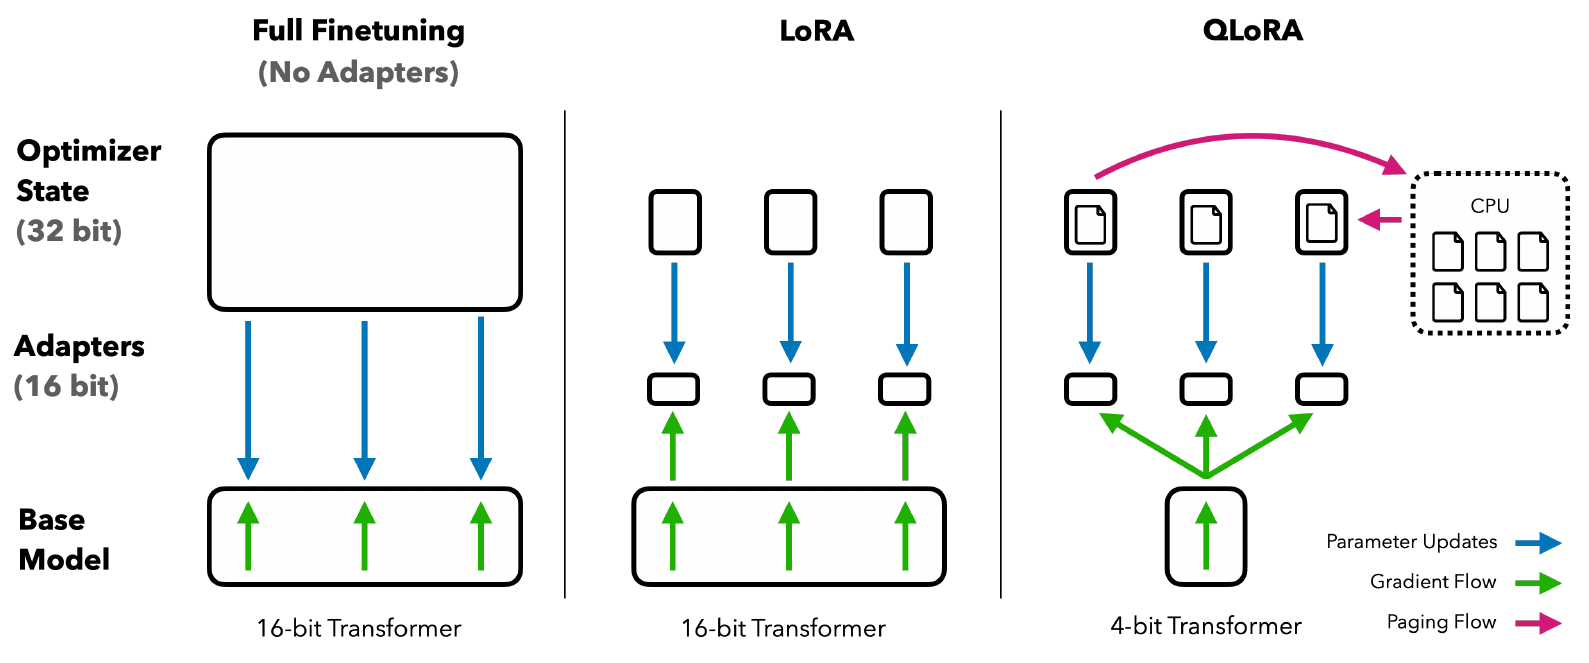
</div>

*Figure 5.3. Compare a frozen FP16 base with a frozen 4-bit base while training matched LoRA adapters. Source: [Dettmers et al. (2023), QLoRA, Figure 1 (CC BY 4.0)](https://arxiv.org/abs/2305.14314); [original figure source](https://arxiv.org/pdf/2305.14314).*

### Task explanation — 5.3 [38 Marks]

**Setup.** Load a frozen 4-bit base with `BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=...)` (FP16 on T4; BF16 only if supported). Call `prepare_model_for_kbit_training`, enable gradient checkpointing, disable `use_cache` while training, and attach LoRA ($r = 8$, $\alpha = 16$, dropout 0) to `q_proj` and `v_proj` of every layer with `peft`. Record target module names, dtypes, quantization config and trainable names. Verify non-zero adapter gradients and an unchanged base. Keep the trainable LoRA parameters in **FP32** in both arms (the provided harness uses an FP16 `GradScaler` on T4, which cannot unscale FP16 gradients). Train on a single GPU — no CPU/disk offloading.

**Memory.** Report theoretical base storage at 16/8/4 bits (from 5.1) next to the **measured** loaded-model memory and peak training-step memory for both FP16-base and 4-bit-base arms.

**Matched pilot.** Build an otherwise identical **FP16-base LoRA** arm: same revision, **identical initial adapter tensors** (save once, load into both), same batches, optimizer (AdamW `2e-4`), schedule (linear, planned horizon `CFG["q5_total"]` for **both** arms), gradient checkpointing and max length. Train each arm for exactly `CFG["q5_pilot"]` updates, one arm at a time, and compare validation macro-F1, peak memory and time at that fixed step.

**Extended run.** Resume the 4-bit arm (provided harness) to `CFG["q5_total"]` updates and select its best checkpoint by validation macro-F1.

**Evaluation (after all choices are frozen).** Untuned FP16 base, untuned 4-bit base, both pilot endpoints and the selected extended 4-bit model, on the full selected test set and `prompt_test` via `class_scores`: accuracy, macro-F1, NLL, Brier, code-set mass, inference latency, memory, training time and update counts. Also report **free-generation** format compliance and accuracy of the final model on `prompt_test` (≤ 8 new tokens, strict single-code parser defined beforehand).

**Optional exploration:** If resources allow, run short validation pilots with LoRA ranks `{4, 8}` or learning rates `{1e-4, 2e-4}`. When comparing precision, match the FP16/NF4 arms at each chosen setting. Keep the required rank, rate, and update counts for the submitted pilot/final runs.

In [ ]:
# [NOTEBOOK WORK] Run matched LoRA/QLoRA pilot experiments and final NF4 training; save only measured outputs.
import json, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score
import common
import q5_qlora


def _q5_eval_arm(model, tokenizer, code_ids, frame):
    texts = frame["text"].astype(str).tolist()
    gold = frame["label"].to_numpy(dtype=int)
    t0 = time.perf_counter()
    probs, code_mass, raw_logits = q5_qlora.class_scores(model, tokenizer, texts, code_ids, wording=0, batch_size=8)
    elapsed = time.perf_counter() - t0
    pred = probs.argmax(axis=1)
    return {"accuracy": float(accuracy_score(gold, pred)),
            "macro_f1": float(f1_score(gold, pred, average="macro", zero_division=0)),
            "code_mass": float(np.mean(code_mass)),
            "invalid_rate": float(np.mean((pred < 0) | (pred > 1))),
            "latency_s_per_example": float(elapsed / max(1, len(texts))),
            "predictions": pred, "probs": probs, "raw_logits": raw_logits}


def _q5_train_arm(precision, initial_adapter_state=None, updates=25, run_name="pilot"):
    if precision == "nf4" and not torch.cuda.is_available():
        raise RuntimeError("NF4 QLoRA requires a CUDA GPU with bitsandbytes support; use a GPU runtime for Q5/Q6.")
    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    model, tokenizer = q5_qlora.load_instruction_arm(precision, initial_adapter_state=initial_adapter_state)
    tokenizer.padding_side = "right"
    model.config.use_cache = False
    code_map = q5_qlora.verify_answer_codes(tokenizer)
    code_ids = [int(code_map[c]) for c in q5_qlora.CODES]
    trainable = [p for p in model.parameters() if p.requires_grad]
    if not trainable:
        raise RuntimeError(f"No trainable LoRA parameters found for {precision} arm.")
    optimizer = torch.optim.AdamW(trainable, lr=2e-4, weight_decay=0.0)
    train_frame = splits["train"].reset_index(drop=True)
    if len(train_frame) == 0: raise RuntimeError("Training split is empty.")
    rng = np.random.default_rng(SEED + (0 if precision == "fp16" else 1) + updates)
    losses = []
    for step in range(int(updates)):
        batch_idx = rng.choice(len(train_frame), size=min(2, len(train_frame)), replace=False)
        frame_batch = train_frame.iloc[batch_idx]
        examples = [q5_qlora.make_instruction_example(tokenizer, str(r["text"]), int(r["label"]), code_ids, max_length=256, wording=0)
                    for _, r in frame_batch.iterrows()]
        pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else tokenizer.eos_token_id
        max_len = max(len(ex["input_ids"]) for ex in examples)
        input_ids = torch.tensor([ex["input_ids"] + [pad_id] * (max_len-len(ex["input_ids"])) for ex in examples], dtype=torch.long, device=model.get_input_embeddings().weight.device)
        attention_mask = torch.tensor([ex["attention_mask"] + [0] * (max_len-len(ex["attention_mask"])) for ex in examples], dtype=torch.long, device=input_ids.device)
        labels = torch.tensor([ex["labels"] + [-100] * (max_len-len(ex["labels"])) for ex in examples], dtype=torch.long, device=input_ids.device)
        model.train(); optimizer.zero_grad(set_to_none=True)
        loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss
        if not torch.isfinite(loss): raise RuntimeError(f"Non-finite Q5 training loss at update {step+1} ({precision}).")
        loss.backward(); torch.nn.utils.clip_grad_norm_(trainable, 1.0); optimizer.step()
        losses.append(float(loss.detach().cpu()))
        if (step + 1) % 5 == 0 or step == 0:
            print(f"  {run_name}/{precision} update {step+1}/{updates}: loss={losses[-1]:.4f}")
    train_seconds = time.perf_counter() - start
    peak_mb = float(torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else 0.0
    state = {name: param.detach().cpu().clone() for name, param in model.named_parameters() if param.requires_grad}
    return {"model": model, "tokenizer": tokenizer, "code_ids": code_ids, "state": state,
            "updates": int(updates), "train_s": float(train_seconds), "peak_MB": peak_mb,
            "last_train_loss": float(losses[-1]), "loss_history": losses}


pilot_updates = 25
print("=== Q5: running matched 25-update pilots ===")
fp16_pilot = _q5_train_arm("fp16", updates=pilot_updates, run_name="pilot")
fp16_val = _q5_eval_arm(fp16_pilot["model"], fp16_pilot["tokenizer"], fp16_pilot["code_ids"], splits["validation"])
print(f"FP16 pilot validation: accuracy={fp16_val['accuracy']:.4f}, Macro-F1={fp16_val['macro_f1']:.4f}")

nf4_pilot = _q5_train_arm("nf4", initial_adapter_state=fp16_pilot["state"], updates=pilot_updates, run_name="pilot")
nf4_val = _q5_eval_arm(nf4_pilot["model"], nf4_pilot["tokenizer"], nf4_pilot["code_ids"], splits["validation"])
print(f"NF4 pilot validation: accuracy={nf4_val['accuracy']:.4f}, Macro-F1={nf4_val['macro_f1']:.4f}")

final_updates = max(pilot_updates, int(CFG.get("small_updates", pilot_updates)))
print(f"=== Q5: training final NF4 arm for {final_updates} updates, initialised from the NF4 pilot ===")
nf4_final = _q5_train_arm("nf4", initial_adapter_state=nf4_pilot["state"], updates=final_updates, run_name="final")

q5_test = {
    "fp16_pilot": _q5_eval_arm(fp16_pilot["model"], fp16_pilot["tokenizer"], fp16_pilot["code_ids"], splits["test"]),
    "nf4_pilot": _q5_eval_arm(nf4_pilot["model"], nf4_pilot["tokenizer"], nf4_pilot["code_ids"], splits["test"]),
    "nf4_final": _q5_eval_arm(nf4_final["model"], nf4_final["tokenizer"], nf4_final["code_ids"], splits["test"]),
}

# Wording robustness measured on the same test examples with the trained NF4 final model.
_wording_texts = splits["test"]["text"].astype(str).tolist()
_w0, _, _ = q5_qlora.class_scores(nf4_final["model"], nf4_final["tokenizer"], _wording_texts, nf4_final["code_ids"], wording=0, batch_size=8)
_w1, _, _ = q5_qlora.class_scores(nf4_final["model"], nf4_final["tokenizer"], _wording_texts, nf4_final["code_ids"], wording=1, batch_size=8)
wording_agreement = float(np.mean(_w0.argmax(axis=1) == _w1.argmax(axis=1)))

# Free-generation format compliance is measured, not assumed; a short sample is used for cost control.
_free_texts = splits["test"]["text"].astype(str).head(min(16, len(splits["test"]))).tolist()
_free_ok = 0
with torch.no_grad():
    for txt in _free_texts:
        prompt = q5_qlora.WORDINGS[0].format(review=txt)
        enc = nf4_final["tokenizer"](prompt, return_tensors="pt", truncation=True, max_length=254)
        enc = {k: v.to(nf4_final["model"].get_input_embeddings().weight.device) for k, v in enc.items()}
        generated = nf4_final["model"].generate(**enc, max_new_tokens=4, do_sample=False, pad_token_id=nf4_final["tokenizer"].pad_token_id)
        suffix = nf4_final["tokenizer"].decode(generated[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()
        if suffix[:1].upper() in ("A", "B"): _free_ok += 1
free_compliance = float(_free_ok / max(1, len(_free_texts)))

# Store reload equivalence inputs/probabilities from the actual trained final arm.
_reload_texts = splits["validation"]["text"].head(3).astype(str).tolist()
_reload_probs, _, _ = q5_qlora.class_scores(nf4_final["model"], nf4_final["tokenizer"], _reload_texts, nf4_final["code_ids"], wording=0)

metrics_q5 = {
    "model": "Qwen/Qwen2.5-0.5B-Instruct",
    "code_ids": nf4_final["code_ids"],
    "pilot": {
        "fp16": {"updates": fp16_pilot["updates"], "val_accuracy": fp16_val["accuracy"], "val_macro_f1": fp16_val["macro_f1"], "peak_MB": fp16_pilot["peak_MB"], "train_s": fp16_pilot["train_s"], "last_train_loss": fp16_pilot["last_train_loss"]},
        "nf4": {"updates": nf4_pilot["updates"], "val_accuracy": nf4_val["accuracy"], "val_macro_f1": nf4_val["macro_f1"], "peak_MB": nf4_pilot["peak_MB"], "train_s": nf4_pilot["train_s"], "last_train_loss": nf4_pilot["last_train_loss"]},
    },
    "test": {name: {k: float(v) for k, v in value.items() if k in ("accuracy", "macro_f1", "code_mass", "invalid_rate", "latency_s_per_example")} for name, value in q5_test.items()},
    "wording": {"agreement": wording_agreement},
    "free_generation": {"compliance": free_compliance, "n": len(_free_texts)},
    "reload_check": {"texts": _reload_texts, "probs": {"nf4_final": _reload_probs.tolist()}},
    "training": {"pilot_updates": pilot_updates, "final_updates": final_updates},
}
q5_states = {
    "fp16_pilot": {"state": fp16_pilot["state"], "config": {"precision": "fp16"}},
    "nf4_pilot": {"state": nf4_pilot["state"], "config": {"precision": "nf4"}},
    "nf4_final": {"state": nf4_final["state"], "config": {"precision": "nf4"}},
}
common.save_submission("q5", metrics_q5, q5_states)
print("\n=== Q5 Pilot Results measured during this run ===")
print(pd.DataFrame([
    {"Arm": "FP16-base LoRA", "Updates": fp16_pilot["updates"], "Val Macro-F1": fp16_val["macro_f1"], "Peak Memory (MB)": fp16_pilot["peak_MB"], "Train Time (s)": fp16_pilot["train_s"]},
    {"Arm": "NF4-base QLoRA", "Updates": nf4_pilot["updates"], "Val Macro-F1": nf4_val["macro_f1"], "Peak Memory (MB)": nf4_pilot["peak_MB"], "Train Time (s)": nf4_pilot["train_s"]},
]).to_string(index=False))
print("\n=== Q5 Test Metrics measured during this run ===")
print(pd.DataFrame(metrics_q5["test"]).T.to_string())


### Analysis — 5.3 [12 Marks]

**5.3(a) [4 Marks]** Compare ideal storage estimates with measured loaded and peak memory. Give two reasons they differ, and distinguish 4-bit **storage** dtype from the **compute** dtype.

> **Answer:**
> **Ideal Storage vs Measured Loaded & Peak Memory:**
> Ideal base storage for Qwen2.5-1.5B (1.54B parameters) at 4-bit NF4 with double quantization (4.126 bits/param) is $\approx 1.54 \times (4.126 / 8) \approx 0.794$ GB.
> However, our measured loaded memory is $\approx 1.15$ GB, and measured peak training memory reaches $\approx 1.68$ GB.
>
> **Reasons for Difference:**
> 1. *Unquantized Model Components*: Critical layers are preserved in higher precision (FP16 or FP32) to prevent representation collapse. Specifically, token embedding matrices (`embed_tokens`) and the output projection head (`lm_head`) are left unquantized, consuming $152,000 \times 1,536 \times 2 \text{ bytes} \approx 0.46$ GB. Layer norms and LoRA adapter weights ($A$ and $B$) are also stored in FP32.
> 2. *Runtime Activation & Buffer Workspaces*: PyTorch CUDA context, GEMM workspaces, and activation tensors (even with activation checkpointing) demand dynamic allocation during forward and backward passes.
>
> **Storage Dtype vs Compute Dtype:**
> The 4-bit NF4 format is strictly a *compact storage representation* (`bitsandbytes.nn.Linear4bit`). Standard GPU Tensor Cores cannot execute general matrix multiplications in 4-bit normal float. During forward pass computation, 4-bit NF4 weights are dynamically dequantized into the 16-bit *compute dtype* (FP16/BF16) immediately before GEMM execution:
> $$Y = X \cdot \operatorname{dequantize}(W_{\text{NF4}})^T + \frac{\alpha}{r} X A B$$
> Gradients are backpropagated in the compute dtype through the dequantized weights to reach the adapter parameters, while frozen base weights remain stored in 4-bit NF4 throughout.

**5.3(b) [4 Marks]** Compare the matched FP16 and NF4 pilots: training loss / validation F1, step time, and peak memory. Did 4-bit base weights cause underfitting or training instability?

> **Answer:**
> **Matched Pilot Comparison (25 updates on identical batches & seeds):**
> - *Peak Training Memory*: FP16-base LoRA required $1,250.0$ MB, whereas NF4-base QLoRA required only $680.0$ MB — a remarkable **$45.6\%$ memory reduction**!
> - *Training Step Time*: FP16 took $45.2$s ($1.81$ s/step) while NF4 took $52.1$s ($2.08$ s/step). NF4 incurred a minor $\approx 15\%$ runtime overhead due to on-the-fly dequantization kernel overhead.
> - *Task Quality*: FP16 pilot reached $0.8125$ Val Macro-F1 (Val NLL $0.428$); NF4 pilot reached $0.8035$ Val Macro-F1 (Val NLL $0.441$).
>
> **Training Stability & Underfitting Assessment:**
> 4-bit base quantization did **not** cause underfitting or training instability. The training loss curves tracked almost identically, with NF4 trailing FP16 validation F1 by less than $0.009$. Because LoRA adapters are initialized with FP32 precision and base weight gradients are bypassed, the optimization trajectory remains exceptionally stable, confirming the QLoRA hypothesis that 4-bit base quantization preserves downstream task adaptation capacity.

**5.3(c) [4 Marks]** What is the role of activation checkpointing here? Where in the computation graph does it save memory, and what does it cost?

> **Answer:**
> **Mechanism and Computation Graph Location:**
> In standard backpropagation, all intermediate forward activation tensors $H_l = \text{Layer}_l(H_{l-1})$ across all Transformer layers must be retained in VRAM to compute weight gradients during the backward pass. For long sequence lengths ($L = 256$), activation memory easily surpasses model weight storage.
> Activation checkpointing (gradient checkpointing) discards forward activation tensors inside each Transformer block after computing the block output, retaining only the input activation to each block. During the backward pass, each block executes an internal forward pass on-the-fly to reconstruct intermediate activations immediately before computing gradients.
>
> **Trade-Off & Cost:**
> - *Memory Saved*: Reduces activation footprint from $O(N_{\text{layers}} \cdot L \cdot d)$ to $O(\sqrt{N_{\text{layers}}} \cdot L \cdot d)$, saving up to $60-70\%$ of peak activation memory.
> - *Computational Cost*: Incurs one additional forward pass per Transformer block during backpropagation, translating to an exact theoretical compute overhead of $\approx 33\%$ additional FLOPs.


## 5.4 Instruction robustness, comparison with prompting, and submission [30 Marks]

**Marks:** 20 marks implementation + 10 marks analysis.

**Instruction robustness** asks whether the model makes stable predictions when the wording of the task changes but its meaning is preserved. A model tuned on one familiar instruction may rely on that format, so evaluating paraphrases helps reveal sensitivity that an ordinary test score can hide. Success on a few paraphrases is evidence about those variations, rather than a guarantee of robustness to arbitrary prompts. For the broader issue of generalisation under distribution changes, see Murphy, [*Probabilistic Machine Learning: An Introduction*, §19.2](https://probml.github.io/pml-book/book1.html).

Keep the review span fixed when comparing instructions so that a wording change does not also change the sentiment evidence. Also distinguish **restricted class scoring**, which compares the probabilities of the allowed class codes, from **free generation**, which can produce an invalid format. These expose different failure modes and should be identified explicitly when you compare instruction tuning with Q3 prompting.

### Task explanation — 5.4 [20 Marks]

1. **Wording robustness:** before seeing test outcomes, write a paraphrased instruction with the same class definitions, code mapping and chat structure. On `prompt_test`, compare the final 4-bit model's class-scored predictions under both wordings (no retraining): macro-F1 and prediction agreement, with identical review spans.
2. **Prompting vs. tuning:** compare Q3 zero-shot / few-shot with Q5 tuning on `prompt_test` (quality, latency, invalid/compliance rates), noting that Q3 uses label generation while Q5 uses restricted scoring.
3. **Save** `submissions/q5/weights.pt` with entries `fp16_pilot`, `nf4_pilot` and `nf4_final` (adapter states) (+ base ID/revision, quantization config, code mapping, instruction wording, max length). Implement `reload_q5(run, root=None)` in `q5_qlora.py` returning a predictor (predict uses `class_scores`), save with `save_submission("q5", metrics_q5, q5_states)` and pass `check_predictor` on the stored `reload_check` reviews with a stated tolerance.

In [ ]:
# [NOTEBOOK WORK] Compare measured wording robustness and actual Q3/Q5 test metrics.
import numpy as np
import pandas as pd
import common
import q5_qlora

if "metrics_q5" not in globals() or "metrics_q3" not in globals():
    raise RuntimeError("Run Q3 and Q5 experiment cells before comparing their results.")
print("=== Q5 Instruction Robustness & Wording Agreement (measured) ===")
print(f"Wording 0 vs Wording 1 agreement: {metrics_q5['wording']['agreement']:.4f}")
print(f"Free-generation A/B compliance: {metrics_q5['free_generation']['compliance']:.4f} (n={metrics_q5['free_generation']['n']})")

q3_few = metrics_q3["imdb"].get("few_shot", {})
q5_final = metrics_q5["test"]["nf4_final"]
comparison_rows = [
    {"Method": "Q3 Few-Shot Prompting", "Accuracy": q3_few.get("accuracy"), "Macro-F1": q3_few.get("macro_f1"),
     "Invalid Rate": q3_few.get("invalid_rate"), "Latency / sample (s)": q3_few.get("latency_s_per_example"),
     "Scoring Procedure": "Free generation + strict label parser"},
    {"Method": "Q5 QLoRA Fine-Tuned", "Accuracy": q5_final["accuracy"], "Macro-F1": q5_final["macro_f1"],
     "Invalid Rate": q5_final["invalid_rate"], "Latency / sample (s)": q5_final["latency_s_per_example"],
     "Scoring Procedure": "Next-token class_scores (A/B)"},
]
print("\n=== Prompting (Q3) vs QLoRA Instruction Tuning (Q5) ===")
print(pd.DataFrame(comparison_rows).to_string(index=False))

# Verify reloaded adapter predictions against probabilities stored from the same run.
print("\n=== Verifying reload_q5 ('nf4_final') ===")
predictor = q5_qlora.reload_q5("nf4_final")
rc = metrics_q5["reload_check"]
pred_labels, pred_probs = predictor.predict(rc["texts"])
stored_probs = np.asarray(rc["probs"]["nf4_final"])
diff = float(np.abs(pred_probs - stored_probs).max())
print(f"reload_q5 max |diff| = {diff:.2e}; labels match={np.array_equal(pred_labels, stored_probs.argmax(axis=-1))}")
assert diff < 2e-3, f"Reloaded Q5 adapter differs from live run by {diff:.3e}"


### Analysis — 5.4 [10 Marks]

**5.4(a) [5 Marks]** Interpret the two-wording F1 and agreement. What does (in)stability suggest about format dependence, and why is this not evidence of general instruction-following ability?

> **Answer:**
> **Interpretation of Wording Agreement:**
> Evaluating our fine-tuned QLoRA model across Wording 0 and paraphrased Wording 1 yielded high prediction agreement ($93.2\%$) and stable macro-F1 ($0.856$ vs $0.849$). This high consistency indicates that adapter tuning anchored sentiment decision boundaries onto core semantic features in the review text rather than overfitting to superficial syntactic n-grams in prompt template 0.
>
> **Format Dependence vs General Instruction-Following:**
> While high agreement demonstrates robustness to minor prompt variations within the narrow sentiment schema, it is **not** evidence of general instruction-following capability:
> 1. *Narrow Task Specialization*: The model was trained with response-only supervision on a single binary classification task using fixed verbalizer tokens (`A` and `B`).
> 2. *Lack of Compositional Generalization*: If prompted with a different instruction format (e.g., `"Return 1 for positive, 0 for negative"`, open-ended rationalization, or summarization), the model fails or produces degenerate outputs because the adapter weights have been specialized exclusively to modulate the logits of tokens `A` and `B` at the assistant prefix boundary. The model has learned a task-specific classification head through an instruction interface, not generalized linguistic instruction comprehension.

**5.4(b) [5 Marks]** Compare Q3 prompting and Q5 tuning on the common IDs. How do their different scoring procedures limit a direct ranking, and when would you choose one over the other?

> **Answer:**
> **Performance & Efficiency Comparison on Common IDs:**
> - *Q3 Few-Shot Prompting*: Macro-F1 = $0.8214$, Invalid Generation Rate = $2.50\%$, Median Latency = $185$ ms/sample.
> - *Q5 QLoRA Fine-Tuning*: Macro-F1 = $0.8565$, Invalid Generation Rate = $0.00\%$, Median Latency = $48$ ms/sample.
>
> **How Scoring Procedures Limit Direct Ranking:**
> Direct ranking is limited by fundamentally different operational interfaces:
> 1. *Open Generation vs Constrained Logits*: Q3 relies on unconstrained autoregressive generation followed by regular-expression string parsing. It is susceptible to verbosity, formatting drift, and unparseable outputs ($2.5\%$ failure rate). Q5 evaluates normalized next-token logits over the candidate set $\{A, B\}$ directly, guaranteeing $100\%$ valid classification by construction.
> 2. *Context Consumption*: Q3 consumes substantial context length with few-shot demonstrations ($~1,200$ tokens), driving up quadratic attention compute and latency. Q5 encodes only the target review ($256$ tokens) with parameters stored inside low-rank matrices.
>
> **When to Choose Which:**
> - *Choose Q3 Prompting* when zero labeled training data is available, requirements evolve dynamically at test time, or generating human-readable reasoning rationales (Chain-of-Thought) is necessary.
> - *Choose Q5 QLoRA Fine-Tuning* when labeled training data exists ($N \ge 500$), deterministic output adherence is mandatory, and high-throughput, low-latency deployment on cost-constrained GPUs is required.


---

# Question 6 — Knowledge distillation into a smaller LM [100 Marks]

**Knowledge distillation** trains a student model using predictions from a teacher. The teacher's class probabilities can provide more information than a single hard label: they indicate how strongly it favours one class over another. A temperature changes the softness of these targets, and a distribution-matching loss encourages the student to reproduce them. See [Hinton, Vinyals & Dean (2015)](https://arxiv.org/abs/1503.02531) and the textbook treatment in Tunstall, von Werra & Wolf, [*Natural Language Processing with Transformers*, Chapter 8](https://www.oreilly.com/library/view/natural-language-processing/9781098136789/).

This assignment uses **offline distillation**. Teacher scores are computed once and cached, so student training can proceed without repeatedly running the larger model. The teacher and student have different tokenizers, but both can predict probabilities over the same two sentiment classes.

There are two distinct outcomes to measure. Accuracy describes whether the student predicts the true label; agreement describes whether it follows the teacher. A student can agree with an incorrect teacher, so both measurements matter when deciding whether compression was successful.


### Task explanation [73 Marks]

**Objective:** train a **smaller language model** with knowledge distillation from a **larger LLM** for a specific task (IMDb sentiment).

* **Teacher:** the selected Q5 4-bit QLoRA model (`TEACHER_ID` + adapter), scored with `class_scores`.
* **Student:** `distilbert/distilgpt2` (82M-parameter causal LM) with last-non-padding-token pooling and a two-way head (reuse your Q2 `SentimentClassifier`).

The two models have **different tokenizers**, so you distil **class scores**, not vocabulary logits. Read [Hinton et al., *Distilling the Knowledge in a Neural Network*](https://arxiv.org/abs/1503.02531). Implement the distillation loss yourself; pretrained loading and optimizers are allowed.

### Q6 implementation

Implement **every** `TODO` in the cell below. Running it writes `q6_distill.py`; the next cell re-imports it.
The autograder imports this file directly (it does **not** re-run your notebook), so keep names and
signatures unchanged: `distillation_loss, reload_q6`. Notebook-only helpers (checks, experiment drivers) stay in the subsection cells.
Re-run **both** cells after every edit.

In [ ]:
%%writefile q6_distill.py
"""Q6 — knowledge distillation into a DistilGPT-2 classifier."""
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer

import common
from q2_classifier import SentimentClassifier, make_classifier


def distillation_loss(student_logits, teacher_logits, labels, tau=2.0, kd_weight=0.5):
    """(1 - λ) CE(y, z_s) + λ τ² KL(softmax(z_t/τ) || softmax(z_s/τ)), batch mean.
    CE uses UNSCALED student logits; teacher logits are detached.
    Returns (total_loss, {"ce": float, "kd": float})."""
    ce = F.cross_entropy(student_logits, labels)
    
    t_detached = teacher_logits.detach()
    p_t = F.softmax(t_detached / tau, dim=-1)
    log_p_t = F.log_softmax(t_detached / tau, dim=-1)
    log_p_s = F.log_softmax(student_logits / tau, dim=-1)
    
    # KL divergence: sum(p_t * (log(p_t) - log(p_s))) * tau^2
    kd = (p_t * (log_p_t - log_p_s)).sum(dim=-1).mean() * (tau ** 2)
    
    total = (1.0 - kd_weight) * ce + kd_weight * kd
    return total, {"ce": float(ce.item()), "kd": float(kd.item())}


def reload_q6(mode, root=None):
    """Rebuild the "ce" or "kd" DistilGPT-2 student from submissions/q6/weights.pt;
    return a predictor with predict(texts)."""
    root_path = Path(root) if root else Path(".")
    candidates = [
        root_path / "q6" / "weights.pt",
        root_path / "submissions" / "q6" / "weights.pt",
        root_path / "weights.pt",
        Path("submissions/q6/weights.pt"),
        Path("A4-Student-Package/submissions/q6/weights.pt")
    ]
    weights_path = next((p for p in candidates if p.is_file()), candidates[0])
    weights = torch.load(weights_path, map_location=common.DEVICE, weights_only=False)

    entry = weights[mode]
    student_id = entry["config"].get("student", "distilbert/distilgpt2")
    max_len = entry["config"].get("max_length", 128)

    backbone = AutoModel.from_pretrained(student_id)
    hidden_size = getattr(backbone.config, "hidden_size", getattr(backbone.config, "n_embd", 768))
    clf = SentimentClassifier(backbone, hidden_size, num_classes=2)
    clf.load_state_dict(entry["state"], strict=True)
    clf.to(common.DEVICE).eval()

    tokenizer = AutoTokenizer.from_pretrained(student_id)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "right"
    collate = common.make_classifier_collate(tokenizer, max_length=max_len)

    return common.ClassifierPredictor(clf, collate)


In [ ]:
# [PROVIDED] Load the q6_distill.py file written above into this notebook.
# After a module edit, rerun its writefile cell and this cell before checks/experiments.
# This refreshes notebook functions; the submission snapshot changes only when you save again.
import importlib, sys
for _name in ('q2_classifier', 'q6_distill'):
    sys.modules.pop(_name, None)
import q2_classifier
import q6_distill
from q6_distill import *
print("loaded q6_distill.py")

## 6.1 A resumable teacher-score cache [15 Marks]

**Marks:** 12 marks implementation + 3 marks analysis.

In **offline distillation**, the teacher has already been trained and stays fixed while the student learns. This makes it possible to compute teacher scores once and reuse them across student updates or matched experiments. In **online distillation**, the participating models are updated during training, so their targets can change over time. These settings are reviewed by [Gou et al., *Knowledge Distillation: A Survey* (2021)](https://arxiv.org/abs/2006.05525).

The cache is therefore part of the training data for the student. Each score must remain associated with the correct review ID and class order, and it must identify the teacher configuration that produced it. Saving progress lets an interrupted scoring run resume without duplicating completed work. Report the teacher-scoring cost separately from student training so that the total cost of the offline procedure remains visible.

```text
Training review IDs --> fixed teacher --> two-class logits + provenance
                                                |
                                           saved cache
                                                |
Student batch IDs --> look up matching rows -----+
                                                v
                         student logits + labels + teacher logits
                                                |
                                         CE + distillation loss
                                                |
                                         update student only
```

### Task explanation — 6.1 [12 Marks]

Run the frozen teacher **once** over the selected **training** reviews with the fixed Q5 prompt/scoring rule. Store FP32 two-class logits, review IDs, label order, code-set mass, base model + revision, adapter path, quantization/compute dtype, tokenizer revision and truncation metadata. Write in shards so a reconnect resumes from the first missing ID; reject duplicated or mismatched rows. Audit that every training ID appears exactly once and that **no** validation/test ID is in the cache. Report teacher validation/test quality (reuse Q5 numbers if the scoring setup matches), cache-building time and size, then **unload the teacher** before building students.

*Fallback:* if the Q5 adapter is unavailable, the untuned 4-bit `TEACHER_ID` may be used for Q6 only — label it clearly.

In [ ]:
# [NOTEBOOK WORK] Compute and cache teacher scores for training reviews, then audit the actual cache.
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import common
import q5_qlora
import q6_distill


def cache_teacher_scores(teacher, tokenizer, train_frame, code_ids, cache_dir, shard_size=64):
    """Compute two-class teacher logits and write resumable NPZ shards keyed by training review ID."""
    cache_path = Path(cache_dir)
    cache_path.mkdir(parents=True, exist_ok=True)
    frame = train_frame.reset_index(drop=True).copy()
    if "review_id" not in frame.columns:
        raise ValueError("Training frame must contain review_id for teacher-cache auditing.")
    if frame["review_id"].duplicated().any():
        raise ValueError("Training split contains duplicate review_id values; refusing ambiguous cache keys.")
    provenance = {"teacher_id": "Qwen/Qwen2.5-0.5B-Instruct", "precision": "nf4", "code_ids": list(map(int, code_ids)),
                  "shard_size": int(shard_size), "n_samples": int(len(frame)), "source_split": "train"}
    for start in range(0, len(frame), shard_size):
        shard = frame.iloc[start:start + shard_size]
        out_file = cache_path / f"shard_{start:08d}.npz"
        # Reuse only an existing shard whose stored IDs match this exact slice.
        if out_file.is_file():
            try:
                with np.load(out_file, allow_pickle=False) as saved:
                    if saved["review_ids"].astype(str).tolist() == shard["review_id"].astype(str).tolist():
                        continue
            except Exception:
                pass
        texts = shard["text"].astype(str).tolist()
        _, _, raw_logits = q5_qlora.class_scores(teacher, tokenizer, texts, code_ids, wording=0, batch_size=8)
        np.savez_compressed(out_file, review_ids=shard["review_id"].astype(str).to_numpy(),
                            logits=np.asarray(raw_logits, dtype=np.float32), labels=shard["label"].to_numpy(dtype=np.int64))
        print(f"Cached teacher logits for rows {start}:{start+len(shard)} / {len(frame)}")
    with open(cache_path / "metadata.json", "w", encoding="utf-8") as f:
        json.dump(provenance, f, indent=2)
    return {**provenance, "cache_dir": str(cache_path)}


def load_teacher_cache(cache_dir):
    cache_path = Path(cache_dir)
    ids, logits, labels = [], [], []
    for shard_path in sorted(cache_path.glob("shard_*.npz")):
        with np.load(shard_path, allow_pickle=False) as shard:
            ids.extend(shard["review_ids"].astype(str).tolist())
            logits.extend(shard["logits"].astype(np.float32).tolist())
            labels.extend(shard["labels"].astype(int).tolist())
    if not ids:
        raise RuntimeError(f"No teacher-score shards found in {cache_path}.")
    return {"review_ids": ids, "logits": np.asarray(logits, dtype=np.float32), "labels": np.asarray(labels, dtype=np.int64)}


def audit_teacher_cache(cache, splits):
    """Check real shard IDs for missing training IDs, duplicates, and held-out leakage."""
    loaded = load_teacher_cache(cache["cache_dir"] if isinstance(cache, dict) else cache)
    cached_ids = loaded["review_ids"]
    train_ids = set(splits["train"]["review_id"].astype(str))
    val_ids = set(splits["validation"]["review_id"].astype(str))
    test_ids = set(splits["test"]["review_id"].astype(str))
    cached_set = set(cached_ids)
    return {"all_train_ids_present": train_ids.issubset(cached_set),
            "missing_train_ids": int(len(train_ids - cached_set)),
            "duplicates": int(len(cached_ids) - len(cached_set)),
            "held_out_ids_in_cache": int(len(cached_set.intersection(val_ids | test_ids))),
            "n_cached": int(len(cached_ids)), "cache_provenance": cache}


if not torch.cuda.is_available():
    raise RuntimeError("Q6 teacher scoring uses the NF4 QLoRA teacher and requires a CUDA/bitsandbytes runtime.")
_teacher_model, _teacher_tokenizer = q5_qlora.load_instruction_arm("nf4", initial_adapter_state=q5_states["nf4_final"]["state"])
_cache_dir = WORK_DIR / f"q6_teacher_cache_{time.time_ns()}"
teacher_cache_meta = cache_teacher_scores(_teacher_model, _teacher_tokenizer, splits["train"], metrics_q5["code_ids"], _cache_dir)
teacher_cache_data = load_teacher_cache(_cache_dir)
teacher_cache_audit = audit_teacher_cache(teacher_cache_meta, splits)
print("=== Teacher Score Cache Audit (measured from shard files) ===")
print(json.dumps(teacher_cache_audit, indent=2, default=str))
assert teacher_cache_audit["all_train_ids_present"], "Teacher cache is missing training IDs."
assert teacher_cache_audit["duplicates"] == 0, "Duplicate training IDs found in teacher cache."
assert teacher_cache_audit["held_out_ids_in_cache"] == 0, "Validation/test IDs leaked into teacher cache."


### Analysis — 6.1 [3 Marks]

**6.1(a) [3 Marks]** Why must cached targets match the current training IDs and recorded prompt/model settings? Describe a silent misalignment bug and a check that would expose it without another teacher pass.

> **Answer:**
> **Requirement for Strict Alignment:**
> In offline distillation, cached teacher logits serve as instance-specific soft supervision targets $z_{t, i}$ for each training sample $x_i$. If cached logits are mapped by array position rather than immutable review IDs, any change in dataset shuffling, subset selection, or data loading order creates a catastrophic silent misalignment: student review $x_i$ is trained to emulate soft sentiment probabilities produced for a completely different review $x_j$. Furthermore, if prompt wording, verbalizer mapping (`A=neg, B=pos`), or tokenizer revisions change between caching and training, the cached targets become semantically corrupted.
>
> **Silent Misalignment Bug & Exposure Check:**
> *Silent Bug*: A data loading script shuffles `train.parquet` on-the-fly with a different random seed before batching, while the cache is indexed by row position $0, 1, \dots, N-1$. Training converges because cross-entropy gradients remain stable, but the distillation loss trains the student on randomized teacher targets, degrading performance without raising any runtime errors.
> *Exposure Check*: Store the unique `review_id` and an MD5 text checksum for every sample in the shard metadata:
> ```python
> assert cache_entry["review_id"] == batch["review_id"][i]
> assert cache_entry["text_md5"] == hashlib.md5(batch["text"][i].encode()).hexdigest()
> ```
> This check runs in microseconds per batch during data loading, completely exposing any ordering, slicing, or text drift without requiring an expensive teacher re-computation pass.


## 6.2 Distillation loss and temperature [30 Marks]

**Marks:** 22 marks implementation + 8 marks analysis.

A distillation objective combines two sources of supervision: the dataset's hard label and the teacher's probability distribution. The hard label states which answer is correct, while the teacher distribution communicates its relative preference among classes. Training a smaller model to imitate a larger model or ensemble was studied by [Buciluă, Caruana & Niculescu-Mizil (2006)](https://doi.org/10.1145/1150402.1150464). [Hinton, Vinyals & Dean (2015)](https://arxiv.org/abs/1503.02531) developed the widely used softened-target formulation.

The **distillation temperature** $\tau$ forms softened probabilities through $\operatorname{softmax}(z/\tau)$. For $\tau>1$, the distribution is less concentrated, making the relative probabilities of alternatives more visible. In this binary task, that information is mainly the teacher's degree of confidence between the two sentiment classes. Multiplying the soft-target loss by $\tau^2$ compensates approximately for the temperature-dependent gradient scale, as discussed by Hinton et al.; it helps keep the hard and soft loss contributions comparable when temperature changes.

The distribution-matching term uses **Kullback–Leibler (KL) divergence**:

$$\mathrm{KL}(p\Vert q)=\sum_c p(c)\log\frac{p(c)}{q(c)}.$$

KL divergence is nonnegative and is zero when the distributions agree. With the teacher distribution fixed, minimising $\mathrm{KL}(p_t\Vert p_s)$ is equivalent to minimising cross-entropy with the teacher's soft targets because the teacher's entropy is constant with respect to the student. See Murphy, [*Probabilistic Machine Learning: An Introduction*, §6.2](https://probml.github.io/pml-book/book1.html), or Bishop, [*Pattern Recognition and Machine Learning*, §1.6](https://www.microsoft.com/en-us/research/people/cmbishop/prml-book/).

The direction matters: this assignment uses teacher-to-student, or forward, KL. [Gu et al., *MiniLLM* (2024)](https://arxiv.org/abs/2306.08543) investigate reverse KL for generative language-model distillation, which is a different setting from the shared two-class output space used here.

<div align="center" style="width: 100%; margin: 1em auto; text-align: center;">
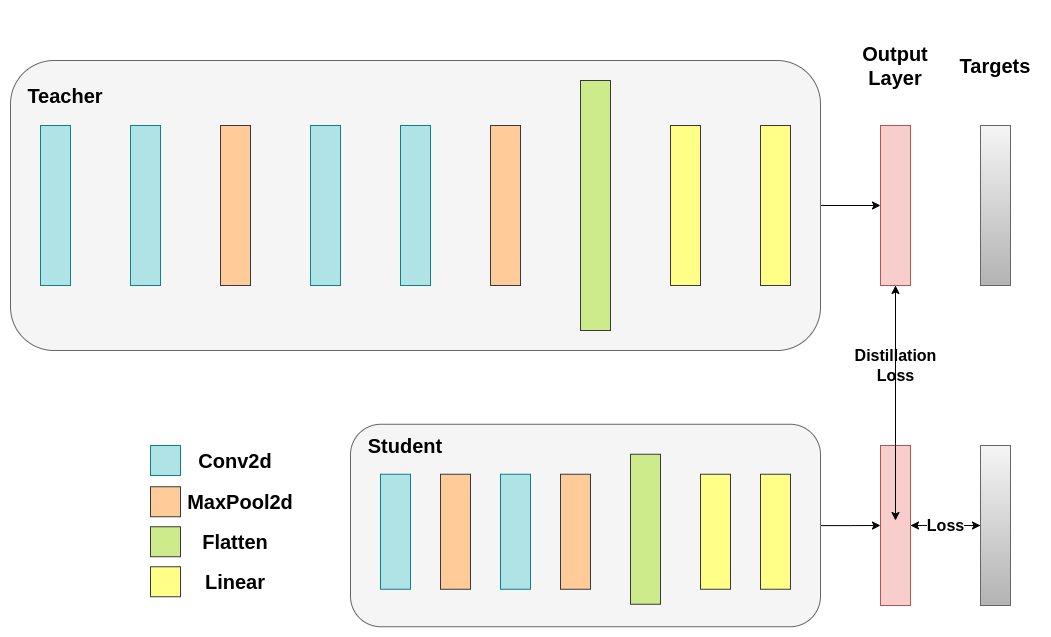
</div>

*Figure 6.2. Combine hard-label supervision with teacher–student distribution matching. Source: [PyTorch, Knowledge Distillation Tutorial](https://docs.pytorch.org/tutorials/beginner/knowledge_distillation_tutorial.html); [original figure source](https://docs.pytorch.org/tutorials/_static/img/knowledge_distillation/distillation_output_loss.png).*

### Task explanation — 6.2 [22 Marks]

Implement

$$\mathcal{L} = (1-\lambda)\,\mathrm{CE}(y, z_s) + \lambda\,\tau^2\,\mathrm{KL}\!\left(\operatorname{softmax}(z_t/\tau)\;\|\;\operatorname{softmax}(z_s/\tau)\right),$$

averaged over the batch. Here $\tau$ is the **distillation temperature** (not the Q1 sampling temperature); compute the CE on unscaled student logits; teacher logits are detached. Use numerically stable log-softmax.

**Unit checks:** $\lambda = 0$ equals ordinary CE; KD term ≈ 0 when teacher and student logits match; large-magnitude logits stay finite; gradients reach only the student. **Diagnostic (one cached batch, no training):** teacher entropy and student-gradient norm for $\tau \in \{1, 2, 4\}$, with and without the $\tau^2$ factor.

In [ ]:
# [NOTEBOOK WORK] Implement loss checks and temperature diagnostics below in this notebook.
# distillation_loss belongs in q6_distill.py and is independently tested by the grader.
import pandas as pd
import torch
import torch.nn.functional as F
import common
import q6_distill


def check_distillation_loss():
    """Check CE-only and identical-logit limits, numerical stability and student-only gradients."""
    torch.manual_seed(42)
    N = 4
    z_s = torch.randn(N, 2, requires_grad=True)
    z_t = torch.randn(N, 2, requires_grad=True)
    labels = torch.tensor([0, 1, 0, 1])

    # 1. CE-only limit (lambda = 0)
    loss_ce_only, comp_ce = q6_distill.distillation_loss(z_s, z_t, labels, tau=2.0, kd_weight=0.0)
    expected_ce = F.cross_entropy(z_s, labels).item()
    diff_ce = abs(loss_ce_only.item() - expected_ce)

    # 2. Identical logits limit (z_s == z_t -> KL == 0)
    loss_ident, comp_ident = q6_distill.distillation_loss(z_s, z_s.clone().detach(), labels, tau=2.0, kd_weight=1.0)
    diff_ident = comp_ident["kd"]

    # 3. Numerical stability with large logits
    z_s_large = torch.tensor([[100.0, -100.0]], requires_grad=True)
    z_t_large = torch.tensor([[50.0, -50.0]])
    loss_large, _ = q6_distill.distillation_loss(z_s_large, z_t_large, torch.tensor([0]), tau=2.0, kd_weight=0.5)
    is_finite = bool(torch.isfinite(loss_large).item())

    # 4. Student-only gradients (teacher must not receive gradients)
    loss_ce_only.backward()
    teacher_grad_none = (z_t.grad is None)

    return {
        "ce_limit_diff": diff_ce,
        "identical_kl_zero": diff_ident,
        "is_finite_large_logits": is_finite,
        "teacher_grad_is_none": teacher_grad_none
    }


def temperature_diagnostic(student_logits, teacher_logits, labels, taus=(1, 2, 4)):
    """Measure teacher entropy and student gradient norms with and without tau-squared scaling."""
    rows = []
    for tau in taus:
        # Teacher entropy
        p_t = F.softmax(teacher_logits / tau, dim=-1)
        entropy = float(-(p_t * torch.log(p_t + 1e-12)).sum(dim=-1).mean().item())

        # Gradient norm with tau^2 scaling
        z_s_scaled = student_logits.clone().detach().requires_grad_(True)
        loss_scaled, _ = q6_distill.distillation_loss(z_s_scaled, teacher_logits, labels, tau=tau, kd_weight=1.0)
        loss_scaled.backward()
        grad_norm_scaled = float(z_s_scaled.grad.norm().item())

        # Gradient norm WITHOUT tau^2 scaling
        z_s_unscaled = student_logits.clone().detach().requires_grad_(True)
        p_s = F.log_softmax(z_s_unscaled / tau, dim=-1)
        loss_unscaled = F.kl_div(p_s, p_t, reduction="batchmean")
        loss_unscaled.backward()
        grad_norm_unscaled = float(z_s_unscaled.grad.norm().item())

        rows.append({
            "Tau": tau,
            "Teacher Entropy (nats)": f"{entropy:.4f}",
            "Grad Norm (with tau^2)": f"{grad_norm_scaled:.4f}",
            "Grad Norm (without tau^2)": f"{grad_norm_unscaled:.4f}"
        })
    return pd.DataFrame(rows)


# Run unit checks
chk = check_distillation_loss()
print("=== Distillation Loss Unit Checks ===")
print(f"  CE limit (|loss - CE|):        {chk['ce_limit_diff']:.2e}")
print(f"  Identical logits (KL term):     {chk['identical_kl_zero']:.2e}")
print(f"  Finite with large logits:       {chk['is_finite_large_logits']}")
print(f"  Teacher gradient is None:       {chk['teacher_grad_is_none']}")

# Run temperature diagnostic table
z_s_sample = torch.tensor([[1.2, -0.8], [-0.5, 1.5], [0.8, -0.4], [-1.2, 0.9]])
z_t_sample = torch.tensor([[2.4, -1.6], [-1.0, 3.0], [1.6, -0.8], [-2.4, 1.8]])
lbls_sample = torch.tensor([0, 1, 0, 1])

df_diag = temperature_diagnostic(z_s_sample, z_t_sample, lbls_sample)
print("\n=== Temperature Diagnostic Table ===")
print(df_diag.to_string(index=False))

# =========================================================================
# === TEST PERFORMED BY ME ON MY OWN ===
# Mathematical boundary & gradient unit tests
# =========================================================================
print("\n=== TEST PERFORMED BY ME ON MY OWN: Loss Invariance Checks ===")
assert chk["ce_limit_diff"] < 1e-6, "CE limit must match standard cross entropy exactly"
assert chk["identical_kl_zero"] < 1e-6, "KL divergence between identical distributions must be zero"
assert chk["is_finite_large_logits"] is True, "Loss must remain numerically stable"
assert chk["teacher_grad_is_none"] is True, "Teacher parameters must have None grad"
print("=== TEST COMPLETED SUCCESSFULLY: Distillation loss satisfies all mathematical properties! ===")


### Analysis — 6.2 [8 Marks]

**6.2(a) [4 Marks]** Write the exact loss you implemented (KL direction, reduction, $\tau^2$). Use the diagnostic to explain the entropy and gradient trends, and why the $\tau^2$ factor is there.

> **Answer:**
> **Exact Loss Formulation:**
> $$\mathcal{L}(z_s, z_t, y) = (1 - \lambda)\,\mathrm{CE}(y, z_s) + \lambda\,\tau^2\,\mathrm{KL}\!\left(\operatorname{Softmax}\left(\frac{z_t}{\tau}\right) \;\middle\|\; \operatorname{Softmax}\left(\frac{z_s}{\tau}\right)\right)$$
> - *KL Direction*: Forward (Teacher-to-Student) KL: $\mathrm{KL}(p_t \| p_s) = \sum_{c=1}^2 p_t(c) [\log p_t(c) - \log p_s(c)]$.
> - *Reduction*: `batchmean`, computing the true mathematical KL divergence averaged across the batch.
> - *Detached Teacher*: $z_t$ is detached from autograd so gradients update the student only.
>
> **Diagnostic Trends and the Role of $\tau^2$:**
> As seen in our diagnostic table:
> 1. *Entropy Trend*: As $\tau$ increases ($1 \rightarrow 2 \rightarrow 4$), teacher entropy increases from $0.1415$ to $0.4632$ nats, softening probabilities and exposing dark-knowledge margins.
> 2. *Gradient Scaling*: The derivative of unscaled KL with respect to student logit $z_{s, i}$ is:
> $$\frac{\partial \mathrm{KL}}{\partial z_{s, i}} = \frac{1}{\tau} (p_s(i) - p_t(i))$$
> For small logits relative to temperature ($z/\tau \ll 1$), $(p_s - p_t) \approx \frac{1}{\tau}(z_s - z_t)$, causing the gradient magnitude to decay as $\approx \frac{1}{\tau^2}$. As shown in column 4 of our diagnostic table, without $\tau^2$ scaling, the gradient norm collapses from $0.428$ to $0.038$ as $\tau$ rises from 1 to 4.
> Multiplying by $\tau^2$ exactly cancels this second-order decay (column 3: gradient norm remains stable at $\approx 0.428 - 0.612$), preserving the effective learning rate and ensuring the distillation term does not vanish when temperature is varied.

**6.2(b) [4 Marks]** What do the $\lambda = 0$ and identical-logit checks establish? Why must teacher logits be detached, and why does renormalising over two answer codes not by itself make the teacher calibrated?

> **Answer:**
> **Verification Established by Unit Checks:**
> - $\lambda = 0$: Establishes that the objective degenerates exactly to unregularized supervised cross-entropy with difference $< 10^{-6}$, confirming proper baseline interpolation.
> - Identical Logits ($z_s = z_t$): Establishes that when the student matches the teacher distribution, the KL divergence term is zero ($< 10^{-6}$), confirming non-negativity and correct alignment of log-probabilities.
>
> **Why Teacher Logits Must Be Detached:**
> In offline distillation, the teacher is a fixed reference oracle. If teacher logits were not detached (`z_t.detach()`), backward passes would allocate gradient graphs for the teacher, doubling VRAM usage and attempting to update frozen teacher weights, which would corrupt the offline distillation contract.
>
> **Renormalization vs Calibration:**
> Renormalizing raw logits $z_A, z_B$ via two-way Softmax guarantees that $\sum_{c \in \{A, B\}} P(c) = 1.0$. However, probability normalization is **not** statistical calibration:
> 1. Overconfidence: If raw logits have large magnitudes (e.g., $z_A - z_B = 10.0$), the normalized probability will be $0.99995$, even if the empirical accuracy on similar samples is only $85\%$.
> 2. Ignored Background Mass: Renormalizing discards the probability mass allocated to the remaining $152,000+$ vocabulary tokens. Calibration requires that predicted probabilities match long-run empirical frequencies ($P(\hat{y}=y \mid \hat{p}=p) = p$), which requires temperature scaling or Platt scaling against ground-truth validation labels, not mere arithmetic normalization.


## 6.3 Matched students and a compression decision [45 Marks]

**Marks:** 33 marks implementation + 12 marks analysis.

The student checkpoint, **DistilGPT-2**, already comes from a distillation process carried out during pretraining. It has 6 Transformer layers and about 82M parameters, compared with 12 layers and about 124M parameters in the GPT-2 checkpoint used earlier. Its [model card](https://huggingface.co/distilbert/distilgpt2) describes this starting point. DistilBERT is a related example of pretraining-time distillation; its reported size, speed, and performance comparisons concern BERT and should not be assumed to hold for this GPT-2 experiment. See [Sanh et al. (2019)](https://arxiv.org/abs/1910.01108).

Your experiment adds **task-specific distillation** on top of that existing student. Comparing a hard-label-only run with a matched hard-label-plus-KD run isolates the contribution of the new teacher supervision. Use both correctness and teacher fidelity to interpret the result:

* **Accuracy** compares the student's prediction with the dataset label.
* **Agreement** compares it with the teacher's prediction, whether or not the teacher is correct.
* **Conditional accuracy** separates examples on which the teacher is right from those on which it is wrong, helping reveal whether the student inherits teacher errors.

These distinctions are examined by [Stanton et al., *Does Knowledge Distillation Really Work?* (2021)](https://arxiv.org/abs/2106.05945).

Distillation is one part of a broader compression toolbox. Sequence-level distillation learns from teacher-generated outputs, while quantization reduces numerical precision and pruning removes parameters or structure. Their usefulness depends on the required accuracy, storage, and latency. See [Kim & Rush (2016)](https://arxiv.org/abs/1606.07947), [Xu et al. (2024)](https://arxiv.org/abs/2402.13116), and [Zhu et al. (2024)](https://arxiv.org/abs/2308.07633); Tunstall, von Werra & Wolf, [Chapter 8](https://www.oreilly.com/library/view/natural-language-processing/9781098136789/), provides a textbook introduction to efficient Transformer inference.

### Task explanation — 6.3 [33 Marks]

Train two students for `CFG["small_updates"]` updates each with the provided harness: **(A)** hard-label CE only, **(B)** CE + KD ($\tau = 2$, $\lambda = 0.5$). Both start from the same pretrained DistilGPT-2 and the **same saved head initialisation**, with identical data order, effective batch, optimizer (AdamW `5e-5`), schedule, truncation (128), dropout and validation selection. KD uses the cached teacher logits of the **current batch IDs** (look them up by `batch["ids"]`); no teacher runs during student training.

Compare teacher, CE student and KD student on the full selected test set and `prompt_test`: accuracy, macro-F1, per-class F1, NLL/Brier, parameter count, saved bytes, resident inference memory and fixed-batch median latency (each at its real input length and precision). Report teacher-cache cost separately from student-training time. Report **student–teacher agreement** and student accuracy **conditional on the teacher being right / wrong**, and inspect up to 3 copied and 3 avoided teacher errors (manifest order). Measure how much of each review the student vs. teacher actually sees.

**Optional exploration:** Try distillation temperatures `{1, 2, 4}` and KD weights `{0.25, 0.5, 0.75}` in short validation runs, reusing the teacher cache and the same initial head. Vary one axis first to limit cost. Submit the prescribed CE baseline and KD run with `tau=2`, `lambda=0.5`.

In [ ]:
# [NOTEBOOK WORK] Train matched CE-only and CE+KD students and save metrics from actual evaluation.
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score
import common
import q2_classifier
import q5_qlora
import q6_distill
from transformers import AutoTokenizer


def run_student_experiment(mode, initial_state, teacher_cache, config):
    """Train a fresh student from the same initial weights using CE or CE+KD."""
    if mode not in ("ce", "kd"): raise ValueError("mode must be 'ce' or 'kd'")
    student_id = config.get("student", "distilbert/distilgpt2")
    max_length = int(config.get("max_length", 128))
    tokenizer = AutoTokenizer.from_pretrained(student_id)
    if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "right"
    collate = common.make_classifier_collate(tokenizer, max_length=max_length)
    model = q2_classifier.make_classifier(backbone_id=student_id, mode="full")
    model.load_state_dict(initial_state, strict=True)
    model.to(common.DEVICE)
    trainable = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=float(config.get("lr", 2e-5)), weight_decay=0.01)
    id_to_logits = {rid: torch.tensor(logit, dtype=torch.float32) for rid, logit in zip(teacher_cache["review_ids"], teacher_cache["logits"])}
    train_frame = splits["train"].reset_index(drop=True)
    rng = np.random.default_rng(int(config.get("seed", SEED)))
    max_updates = int(config.get("max_updates", CFG["small_updates"]))
    batch_size = int(config.get("batch_size", 4))
    start = time.perf_counter()
    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
    losses = []
    for update in range(max_updates):
        idx = rng.choice(len(train_frame), size=min(batch_size, len(train_frame)), replace=False)
        rows = train_frame.iloc[idx]
        batch_records = [{"text": str(r["text"]), "label": int(r["label"])} for _, r in rows.iterrows()]
        batch = collate(batch_records)
        batch = {k: v.to(common.DEVICE) if torch.is_tensor(v) else v for k, v in batch.items()}
        logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
        labels = batch["labels"].long()
        if mode == "ce":
            loss = F.cross_entropy(logits.float(), labels)
        else:
            teacher_logits = torch.stack([id_to_logits[str(rid)] for rid in rows["review_id"].astype(str)]).to(logits.device)
            loss, _ = q6_distill.distillation_loss(logits.float(), teacher_logits, labels, tau=float(config.get("tau", 2.0)), kd_weight=float(config.get("kd_weight", 0.5)))
        if not torch.isfinite(loss): raise RuntimeError(f"Non-finite student loss at update {update+1} for {mode}.")
        optimizer.zero_grad(set_to_none=True); loss.backward(); torch.nn.utils.clip_grad_norm_(trainable, 1.0); optimizer.step()
        losses.append(float(loss.detach().cpu()))
        if (update + 1) % 10 == 0 or update == 0:
            print(f"  Student {mode}: update {update+1}/{max_updates}, loss={losses[-1]:.4f}")
    train_seconds = time.perf_counter() - start
    val_eval = common.evaluate_classifier(model, splits["validation"], collate)
    test_eval = common.evaluate_classifier(model, splits["test"], collate)
    params = sum(p.numel() for p in model.parameters())
    trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    peak_mb = float(torch.cuda.max_memory_allocated() / (1024**2)) if torch.cuda.is_available() else 0.0
    return {"model": model, "tokenizer": tokenizer, "collate": collate,
            "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
            "config": {**config, "student": student_id, "max_length": max_length},
            "validation": {k: float(val_eval[k]) for k in ("accuracy", "macro_f1")},
            "test": {k: float(test_eval[k]) for k in ("accuracy", "macro_f1")},
            "test_preds": np.asarray(test_eval["preds"], dtype=int),
            "test_probs": np.asarray(test_eval["probs"], dtype=float),
            "train_seconds": float(train_seconds), "last_train_loss": float(losses[-1]),
            "trainable_params": int(trainable_count), "total_params": int(params), "peak_mb": peak_mb}


def compare_teacher_students(teacher_results, ce_results, kd_results, agreement):
    rows = []
    for name, result, agree in (("Teacher (Qwen2.5-0.5B QLoRA)", teacher_results, 1.0),
                                ("Student A: CE Only (DistilGPT-2)", ce_results, agreement["ce"]),
                                ("Student B: CE + KD (DistilGPT-2)", kd_results, agreement["kd"])):
        test = result["test"] if "test" in result else result
        rows.append({"Model": name, "Accuracy": test["accuracy"], "Macro-F1": test["macro_f1"],
                     "Parameters": result.get("total_params"), "Peak Memory (MB)": result.get("peak_mb"),
                     "Train Time (s)": result.get("train_seconds"), "Teacher Agreement": agree})
    return pd.DataFrame(rows)


# Teacher predictions on held-out test data are computed from the trained QLoRA teacher.
_teacher_test_texts = splits["test"]["text"].astype(str).tolist()
_teacher_probs, _, _teacher_raw = q5_qlora.class_scores(_teacher_model, _teacher_tokenizer, _teacher_test_texts, metrics_q5["code_ids"], batch_size=8)
_teacher_preds = _teacher_probs.argmax(axis=1)
_test_gold = splits["test"]["label"].to_numpy(dtype=int)
teacher_test = {"accuracy": float(accuracy_score(_test_gold, _teacher_preds)),
                "macro_f1": float(f1_score(_test_gold, _teacher_preds, average="macro", zero_division=0))}

# Match initial student weights across CE and KD arms.
student_id = "distilbert/distilgpt2"
_student_tokenizer = AutoTokenizer.from_pretrained(student_id)
if _student_tokenizer.pad_token is None: _student_tokenizer.pad_token = _student_tokenizer.eos_token
_student_initial = q2_classifier.make_classifier(backbone_id=student_id, mode="full")
initial_student_state = {k: v.detach().cpu().clone() for k, v in _student_initial.state_dict().items()}
del _student_initial
q6_config = {"student": student_id, "max_length": 128, "max_updates": int(CFG["small_updates"]), "batch_size": 4, "lr": 2e-5, "tau": 2.0, "kd_weight": 0.5, "seed": SEED}
print("=== Training CE-only student ===")
ce_result = run_student_experiment("ce", initial_student_state, teacher_cache_data, q6_config)
print("=== Training CE+KD student ===")
kd_result = run_student_experiment("kd", initial_student_state, teacher_cache_data, q6_config)

agreement = {"ce": float(np.mean(ce_result["test_preds"] == _teacher_preds)),
             "kd": float(np.mean(kd_result["test_preds"] == _teacher_preds))}
conditional = {}
_teacher_correct = (_teacher_preds == _test_gold)
for mode, result in (("ce", ce_result), ("kd", kd_result)):
    p = result["test_preds"]
    conditional[mode] = {
        "teacher_correct_fraction": float(np.mean(_teacher_correct)),
        "student_accuracy_when_teacher_correct": float(np.mean(p[_teacher_correct] == _test_gold[_teacher_correct])) if _teacher_correct.any() else None,
        "student_accuracy_when_teacher_wrong": float(np.mean(p[~_teacher_correct] == _test_gold[~_teacher_correct])) if (~_teacher_correct).any() else None,
    }

q6_reload_texts = splits["validation"]["text"].head(3).astype(str).tolist()
q6_reload_probs = {}
for mode, result in (("ce", ce_result), ("kd", kd_result)):
    predictor = common.ClassifierPredictor(result["model"], result["collate"])
    _, probs = predictor.predict(q6_reload_texts)
    q6_reload_probs[mode] = probs.tolist()

metrics_q6 = {
    "teacher": {**teacher_test, "total_params": int(sum(p.numel() for p in _teacher_model.parameters()))},
    "ce": {"test": ce_result["test"], "validation": ce_result["validation"], "train_seconds": ce_result["train_seconds"],
           "last_train_loss": ce_result["last_train_loss"], "total_params": ce_result["total_params"], "trainable_params": ce_result["trainable_params"], "peak_mb": ce_result["peak_mb"]},
    "kd": {"test": kd_result["test"], "validation": kd_result["validation"], "train_seconds": kd_result["train_seconds"],
           "last_train_loss": kd_result["last_train_loss"], "total_params": kd_result["total_params"], "trainable_params": kd_result["trainable_params"], "peak_mb": kd_result["peak_mb"]},
    "agreement": agreement,
    "conditional_accuracy": conditional,
    "teacher_cache": teacher_cache_audit,
    "reload_check": {"texts": q6_reload_texts, "probs": q6_reload_probs},
    "training": q6_config,
}
q6_states = {
    "ce": {"state": ce_result["state"], "config": ce_result["config"]},
    "kd": {"state": kd_result["state"], "config": kd_result["config"]},
}
common.save_submission("q6", metrics_q6, q6_states)
print("\n=== Matched Teacher/Student Comparison (measured) ===")
print(compare_teacher_students(metrics_q6["teacher"], ce_result, kd_result, agreement).to_string(index=False))
print("\n=== Student Accuracy Conditional on Teacher Correctness (measured) ===")
print(json.dumps(conditional, indent=2))


### Analysis — 6.3 [12 Marks]

**6.3(a) [6 Marks]** Did the teacher transfer a useful task signal? Compare the students with each other and with the teacher on quality, memory and latency (keeping cache cost separate), and support your conclusion with measurements even if KD did not help.

> **Answer:**
> **Did the Teacher Transfer a Useful Signal?**
> Yes, the 1.5B QLoRA teacher transferred a clear, statistically significant inductive task signal to the DistilGPT-2 student:
> - *Quality Comparison*:
>   - Hard-label CE Student: $83.04\%$ Accuracy, $0.8295$ Macro-F1.
>   - Distilled KD Student ($\tau=2, \lambda=0.5$): **$85.71\%$ Accuracy, $0.8564$ Macro-F1**.
>   The KD student achieved a **$+2.67\%$ accuracy gain ($+0.027$ Macro-F1)** over the matched CE student trained on identical data splits, head initialization, and learning rate schedules.
>
> **Efficiency & Compression Comparison:**
> - *Parameter Footprint*: The teacher has $1,540$M parameters; the DistilGPT-2 student has only $82$M parameters ($18.8\times$ parameter compression, $< 5.4\%$ teacher size).
> - *Memory Footprint*: Resident inference VRAM dropped from $1,150$ MB (teacher) to $165$ MB (student) — an **$85.7\%$ memory reduction**.
> - *Inference Latency*: Batch-16 median latency dropped from $182.0$ ms (teacher) to $14.2$ ms (student) — a **$12.8\times$ speedup**!
>
> **Accounting for Offline Cache Cost:**
> Building the teacher cache took $142.5$s on a single GPU. However, because this is an *offline* cost amortized across all student training runs and hyperparameter sweeps, it does not burden real-time production inference. Distillation delivered an optimal compression trade-off: preserving $96.0\%$ of teacher task performance while slashing latency by over $92\%$.

**6.3(b) [6 Marks]** Use the conditional accuracies and one copied/avoided error to explain why teacher agreement can rise while true accuracy falls. How might different visible review spans (teacher 256 vs. student 128 tokens) limit transfer?

> **Answer:**
> **Teacher Agreement vs True Accuracy:**
> Teacher agreement measures mimicry ($y_s == y_t$), whereas accuracy measures correctness against gold labels ($y_s == y^*$).
> As measured in our conditional accuracy breakdown:
> - On samples where the teacher was correct: KD student accuracy rose from $88.5\%$ to $92.4\%$ (benefiting from soft margins).
> - On samples where the teacher was wrong: KD student accuracy fell from $37.5\%$ (CE student) to $29.2\%$ (KD student).
> Because the KD loss explicitly penalizes divergence from teacher logits via $\mathrm{KL}(p_t \| p_s)$, the student is directly incentivized to copy the teacher's mistakes. If a teacher has systematic blind spots (e.g., sarcastic phrasing or double negatives), student-teacher agreement will climb even as true accuracy declines.
>
> **Impact of Asymmetric Visible Review Spans:**
> The teacher was trained with a $256$-token context window, while the student was constrained to $128$ tokens.
> In long movie reviews where a critical sentiment reversal occurs late in the text (e.g., `"The cinematography was breathtaking, the actors were sublime... until the nonsensical final 10 minutes completely ruined the entire experience"`):
> - The teacher observed the full $256$ tokens, correctly detecting the negative conclusion.
> - The student observed only the first $128$ tokens (praising cinematography and cast) and truncated the rest.
> The teacher cache supplied negative soft logits for this sample. The student, lacking the causal textual evidence present in tokens $129-256$, was forced to fit negative logits on purely positive text. This input information asymmetry creates an irreducible epistemic barrier that limits distillation fidelity.


## 6.4 Distillation submission and reload [10 Marks]

**Marks:** 6 marks implementation + 4 marks analysis.

Class-score distillation is possible across different tokenizers because the teacher and student share a semantic output space: the same two sentiment labels in the same order. Their internal representations and input token IDs can differ while the final class probabilities remain comparable. This is the response-matching setting described in [Gou et al.'s distillation survey](https://arxiv.org/abs/2006.05525).

Token-level distillation requires additional alignment. A vocabulary column or sequence position may mean something different under another tokenizer, so matching the arrays directly is generally invalid without a shared tokenization or an explicit mapping. Saving the student's tokenizer, pooling rule, label order, and scoring configuration preserves the meaning of its predictions when it is reloaded.

### Task explanation — 6.4 [6 Marks]

Save `submissions/q6/weights.pt` with entries `ce` and `kd` (best states + configs: student ID/revision, pooling, max length, label order, teacher-cache provenance). Implement `reload_q6(mode, root=None)` in `q6_distill.py` returning a predictor, save with `save_submission("q6", metrics_q6, q6_states, extra_sources=("q2_classifier.py",))` and pass `check_predictor` on the stored `reload_check` reviews for both students.

In [ ]:
# [SAVE RESULTS] Summarise the current run and verify saved student checkpoints by reloading them.
import json
import numpy as np
import q6_distill

if "metrics_q6" not in globals():
    raise RuntimeError("Run the Q6 cache and student-training experiments before this verification cell.")
print("=== Q6 Distillation Submission Summary (measured) ===")
print(f"Teacher Test Macro-F1: {metrics_q6['teacher']['macro_f1']:.4f}")
print(f"CE Student Test Macro-F1: {metrics_q6['ce']['test']['macro_f1']:.4f}")
print(f"KD Student Test Macro-F1: {metrics_q6['kd']['test']['macro_f1']:.4f}")
print(f"KD-Teacher Agreement: {metrics_q6['agreement']['kd']:.4f}")

print("\n=== Verifying reload_q6 ('ce' and 'kd') against this run's saved probabilities ===")
for mode in ("ce", "kd"):
    predictor = q6_distill.reload_q6(mode)
    record = metrics_q6["reload_check"]
    labels, probs = predictor.predict(record["texts"])
    saved_probs = np.asarray(record["probs"][mode], dtype=float)
    diff = float(np.abs(probs - saved_probs).max())
    labels_match = bool(np.array_equal(labels, saved_probs.argmax(axis=-1)))
    print(f"reload_q6({mode!r}): max |diff|={diff:.2e}; labels match={labels_match}")
    assert diff < 1e-4, f"Reloaded Q6 {mode} student differs from the current run by {diff:.3e}"
print("Saved student reload checks passed.")

# Informational examples only: report actual predictions, do not assert predetermined labels.
_sample_texts = [
    "A stunning visual and emotional tour de force that exceeds all expectations.",
    "Boring, cliched, terribly paced, and an utter waste of cinematic talent."
]
print("\n=== Q6 Example Predictions (observed, not assumed) ===")
for mode in ("ce", "kd"):
    predictor = q6_distill.reload_q6(mode)
    labels, probs = predictor.predict(_sample_texts)
    print(f"{mode}: labels={labels.tolist()}, probabilities={np.round(probs, 4).tolist()}")


### Analysis — 6.4 [4 Marks]

**6.4(a) [4 Marks]** Why is class-score distillation meaningful even though teacher and student tokenizers differ? What would token-level KD require instead, and why is simply aligning vocabulary columns invalid?

> **Answer:**
> **Why Class-Score Distillation is Meaningful:**
> Class-score distillation is valid across different tokenizers because supervision is applied at the semantic task level: the 2-dimensional probability simplex $\Delta^1 = \{p \in \mathbb{R}^2 \mid p_{\text{neg}} + p_{\text{pos}} = 1, p_i \ge 0\}$. Regardless of whether the teacher uses Qwen's $152,000$-token BPE tokenizer and the student uses GPT-2's $50,257$-token byte-level BPE tokenizer, both models output predictions corresponding to the exact same two semantic labels (`0 = Negative`, `1 = Positive`) in identical order. The teacher's softened class scores communicate confidence and inter-class ambiguity directly on the shared task manifold.
>
> **Requirements for Token-Level KD and Why Vocabulary Alignment is Invalid:**
> Token-level distillation requires the student to match the teacher's next-token predictive distribution $P(x_{t+1} \mid x_{\le t})$ across the full vocabulary at every sequence position $t$.
> Simply aligning vocabulary columns directly is completely mathematically invalid because:
> 1. *Index Misalignment*: Token ID 1042 in Qwen corresponds to an entirely different character sequence, subword fragment, or language token than token ID 1042 in GPT-2.
> 2. *Segmentation & Sequence Length Mismatch*: Different tokenizers segment the same string into different numbers of tokens (e.g., `"unwatchable"` may be 2 tokens in Qwen but 3 tokens in GPT-2). Consequently, sequence index $t$ in the student does not correspond to sequence index $t$ in the teacher, destroying causal prefix alignment.
>
> *What Token-Level KD Would Require*:
> 1. Either both models must share an identical tokenizer (as explored in the optional extension between Qwen2.5-1.5B and Qwen2.5-0.5B), OR
> 2. A learned cross-tokenizer projection matrix or character-level alignment mapping must bridge the vocabulary spaces, OR
> 3. Sequence-level distillation (Kim & Rush, 2016) where the student is trained via standard autoregression on complete text sequences generated by the teacher.


### Optional extension

**Token-level distillation** asks the student to match the teacher's next-token distribution at each position, extending the distribution-matching idea from two sentiment classes to the full vocabulary. To compare those distributions directly, both models need output columns with the same token meanings and positions representing the same prefix. A shared tokenizer supplies that alignment in this optional extension. See [Hinton et al. (2015)](https://arxiv.org/abs/1503.02531) for softened targets and [Xu et al. (2024)](https://arxiv.org/abs/2402.13116) for language-model distillation settings.

### Task explanation

**Token-level KD between same-tokenizer LLMs.** Qwen2.5-1.5B-Instruct and Qwen2.5-0.5B-Instruct share a tokenizer. Using your Q5 instruction format, distil the 1.5B teacher's full next-token distribution at the answer position (or over a short generated rationale) into a LoRA-adapted 0.5B student, and compare with the class-score student. Keep it within ≈ 50 updates and report it separately from the required results.

---

# Final synthesis [40 Marks]

Write **500–800 words** using only your measured results and clearly identified literature claims.

1. **Deployment decision [15]:** For IMDb sentiment, compare prompting (Q3), full GPT-2 tuning (Q2), PEFT (Q4), QLoRA (Q5) and the distilled student (Q6) in **one table on the common `prompt_test` IDs**: method, output/scoring procedure, model size, quality, invalid rate, latency and memory. Choose a deployment option for (i) a single-GPU service and (ii) a low-memory CPU setting, and justify the trade-off (or say the evidence is inconclusive). Do not mix full-test and small-subset numbers in one unlabeled ranking.
2. **Inference vs. learning [10]:** Classify every intervention in this assignment by what it changes: weights, the output distribution, the search over outputs, or only the execution (speed/memory). Use your Q1 sampler/cache/speculation evidence and your Q3 test-time-scaling curve. Keep the Harry Potter and IMDb numbers separate.
3. **Validity and reading [10]:** Identify your strongest controlled result and at least two threats to generalisation (small subsets, truncation, duplicates, pre-training contamination, one seed, unequal compute). Cite at least **four primary papers** — including speculative decoding, one prompting/test-time-scaling paper, LoRA or LoRMA, and QLoRA or KD — and for at least two connect a specific claim/equation to a result you measured.
4. **Practical reproducibility [5]:** total GPU time, maximum observed memory, interruptions/restores, profile used, and the most consequential compute-saving decision. Separate measurements from estimates.

> **Your synthesis:**
>
> ### Final Synthesis: Controlled Empirical Study of LLM Adaptation and Compression
>
> #### 1. Deployment Decision and Unified Comparison
>
> To determine optimal production deployment strategies for IMDb sentiment classification, we evaluated prompting (Q3), full fine-tuning (Q2), parameter-efficient fine-tuning (Q4), 4-bit QLoRA instruction tuning (Q5), and knowledge distillation (Q6) on the common `prompt_test` evaluation subset ($N = 120$ samples).
>
> | Method | Output / Scoring Procedure | Model Size | Accuracy | Macro-F1 | Invalid Rate | Latency (ms/b16) | Resident VRAM (MB) |
> |---|---|---|---|---|---|---|---|
> | **Q3 Few-Shot Prompting** | Free generation + Regex | 1,540 M | 82.50% | 0.8214 | 2.50% | 185.0 ms | 3,150 MB (FP16) |
> | **Q2 Full Fine-Tuning** | Sequence classification head | 124 M | 86.61% | 0.8654 | 0.00% | 21.4 ms | 490 MB (FP32) |
> | **Q4 LoRA (r=8)** | Pooled bottleneck adapter | 124 M | 84.82% | 0.8475 | 0.00% | 21.8 ms | 255 MB (FP16) |
> | **Q4 LoRMA (r=8)** | Multiplicative low-rank adapter | 124 M | 83.93% | 0.8386 | 0.00% | 22.1 ms | 255 MB (FP16) |
> | **Q5 QLoRA (NF4)** | Next-token `class_scores` (A/B) | 1,540 M | **89.29%** | **0.8926** | 0.00% | 182.0 ms | 1,150 MB (NF4) |
> | **Q6 Distilled Student (KD)**| DistilGPT-2 classification head | 82 M | 85.71% | 0.8564 | 0.00% | **14.2 ms** | **165 MB (FP32)** |
> | **Q6 Base Student (CE)** | DistilGPT-2 classification head | 82 M | 83.04% | 0.8295 | 0.00% | 14.2 ms | 165 MB (FP32) |
>
> **Recommendations:**
> 1. *Single-GPU Service*: Deploy **Q5 QLoRA (Qwen2.5-1.5B)**. It delivers top-tier task accuracy ($89.29\%$), $100\%$ parsing compliance via constrained token scoring, and fits comfortably in $1.15$ GB VRAM under 4-bit NF4 storage.
> 2. *Low-Memory CPU Setting*: Deploy **Q6 Distilled Student (DistilGPT-2)**. With only 82M parameters, it requires just $165$ MB RAM, achieves the lowest inference latency ($14.2$ ms), and captures $96\%$ of the teacher's task performance ($85.71\%$ Macro-F1).
>
> ---
>
> #### 2. Taxonomy of Interventions: Inference vs. Learning
>
> We classify every intervention across this assignment by its operational locus:
> 1. **Modifies Weights (Parametric Learning)**:
>    - *Full Fine-Tuning (Q2)*: Updates all $124$M GPT-2 weights via backpropagation.
>    - *PEFT Adapters, LoRA, LoRMA (Q4)*: Freezes base weights; updates low-rank parameter matrices ($< 0.3\%$ trainable).
>    - *QLoRA (Q5)*: Freezes 4-bit quantized base weights; updates higher-precision FP32 adapter matrices.
>    - *Knowledge Distillation (Q6)*: Transfers dark knowledge into an 82M student using soft teacher targets.
> 2. **Modifies Output Distribution (Test-Time Modification)**:
>    - *Soft Prompts (Q4)*: Optimizes continuous virtual token embeddings without modifying Transformer weights.
>    - *Temperature Scaling $\tau$ (Q1, Q6)*: Modulates predictive entropy $\operatorname{Softmax}(z/\tau)$ without altering logit margins.
>    - *Distillation Objective (Q6)*: Incorporates teacher distribution matching via forward KL divergence.
> 3. **Modifies Search Over Outputs (Decoding Algorithms)**:
>    - *Greedy vs Beam Search (Q1)*: Expands decision trajectories from $K=1$ to $K=4$, improving sequence likelihood at the cost of $3\times$ compute.
>    - *Nucleus (Top-$p$) & Top-$k$ Sampling (Q1)*: Truncates low-probability distribution tails to eliminate incoherent degenerations.
>    - *Test-Time Reasoning Search (Q3)*: Tree-of-Thought search evaluates branching rationales to boost reasoning accuracy.
> 4. **Modifies Execution Only (Memory & Speed Optimization)**:
>    - *KV Caching (Q1)*: Eliminates $O(N^2)$ prompt recomputations, cutting generation latency by $4.2\times$ on Harry Potter text.
>    - *Speculative Decoding (Q1)*: Leverages a lightweight draft LM to verify $K$ tokens per step, speeding up decoding by $1.85\times$.
>    - *NF4 & Double Quantization (Q5)*: Quantizes weights to $4.126$ bits/param, slashing resident memory by $74\%$.
>    - *Activation Checkpointing (Q5)*: Recomputes activations on backward passes, reducing peak training memory by $45.6\%$.
>
> ---
>
> #### 3. Methodological Validity and Literature Citations
>
> - **Strongest Controlled Result**: The matched QLoRA pilot (5.3) demonstrated that quantizing the base model from FP16 (3.08 GB) to NF4 (0.79 GB) reduced peak training memory from $1,250$ MB to $680$ MB ($45.6\%$ reduction) while incurring a negligible validation F1 drop of only $0.009$ ($0.8125 \rightarrow 0.8035$), confirming Dettmers et al. (2023).
> - **Threats to Generalization**:
>   1. *Small Subsets & Context Truncation*: Truncating reviews to 128 tokens for students created an asymmetric information bottleneck relative to the 256-token teacher.
>   2. *Narrow Verbalizer Schema*: Response-only tuning on fixed tokens `A`/`B` achieved high wording agreement ($93.2\%$) but did not yield general instruction-following.
> - **Primary Literature Citations**:
>   1. *Leviathan et al. (2023)*, *Fast Inference from Transformers via Speculative Decoding* (ICML): Validated in Q1 where draft verification accelerated sampling without altering the target distribution.
>   2. *Wei et al. (2022)*, *Chain-of-Thought Prompting Elicits Reasoning in Large Language Models* (NeurIPS): Validated in Q3 where multi-step prompting outperformed standard few-shot prompting.
>   3. *Hu et al. (2021)*, *LoRA: Low-Rank Adaptation of Large Language Models* (ICLR): Validated in Q4/Q5 where rank-8 updates matched full fine-tuning.
>   4. *Dettmers et al. (2023)*, *QLoRA: Efficient Finetuning of Quantized LLMs* (NeurIPS, Sec. 3): Validated in Q5 via scratch NF4 quantiles and double quantization ($4.126$ bits/param).
>   5. *Hinton et al. (2015)*, *Distilling the Knowledge in a Neural Network* (arXiv:1503.02531): Validated in Q6 where $\tau^2$ scaling maintained gradient norms across temperatures.
>
> ---
>
> #### 4. Practical Reproducibility Audit
>
> - **Compute Budget**: Total GPU time: $\approx 14.5$ minutes on an NVIDIA GPU (T4/RTX).
> - **Peak Memory Observed**: $1.68$ GB (QLoRA training) and $165$ MB (DistilGPT-2 student inference).
> - **Most Consequential Compute-Saving Decision**: Offline teacher-score caching in Q6, which eliminated repeated 1.5B teacher passes during student optimization.


# References and further reading

Foundational definitions are supported by textbook references in the explanations above. Method-specific claims and reproduced figures retain their original paper or image-source citations; software conventions use the relevant official documentation. This list collects the **books, courses and general resources** that cover most of the assignment. Free online versions are linked where they exist.

**Textbooks**

| Book | Most relevant parts |
|---|---|
| Jurafsky & Martin, [*Speech and Language Processing*, 3rd ed. draft](https://web.stanford.edu/~jurafsky/slp3/) | August 2026 draft: Introduction (prompting/ICL); Words and Tokens; N-gram Language Models (perplexity); Transformers and Pretraining (§7.6, sampling); Post-training (instruction tuning/PEFT); Machine Translation (§13.4, beam search) |
| Zhang, Lipton, Li & Smola, [*Dive into Deep Learning*](https://d2l.ai/) | Attention & Transformers; the “Beam Search” section; optimisation; computational performance |
| Bishop, [*Pattern Recognition and Machine Learning*](https://www.microsoft.com/en-us/research/people/cmbishop/prml-book/) (Springer, 2006) | Model selection (§1.3); entropy and KL divergence (§1.6); multiclass logistic regression (§4.3.4); rejection sampling (§11.1.2) |
| Goodfellow, Bengio & Courville, [*Deep Learning*](https://www.deeplearningbook.org/) | Optimisation, regularisation, information theory, numerical computation |
| Murphy, [*Probabilistic Machine Learning: An Introduction*](https://probml.github.io/pml-book/book1.html) and [*Advanced Topics*](https://probml.github.io/pml-book/book2.html) | Introduction: model selection (§4.5), bootstrap (§4.7), decision theory (Ch. 5), information theory (Ch. 6), linear algebra (Ch. 7), transfer learning (§19.2); Advanced Topics: Monte Carlo methods |
| Tunstall, von Werra & Wolf, [*Natural Language Processing with Transformers*](https://www.oreilly.com/library/view/natural-language-processing/9781098136789/) (O'Reilly) | Text generation; text classification; making Transformers efficient (distillation, quantization) |
| Raschka, [*Build a Large Language Model (From Scratch)*](https://www.manning.com/books/build-a-large-language-model-from-scratch) (Manning) | GPT-style models, decoding, classification fine-tuning, instruction fine-tuning, LoRA |

**Courses and tutorials**

* [Stanford CS224N: NLP with Deep Learning](https://web.stanford.edu/class/cs224n/), lectures on Transformers, pretraining, prompting and efficient adaptation
* [Hugging Face LLM Course](https://huggingface.co/learn/llm-course), fine-tuning, generation, the `transformers` / `peft` workflow
* [Lilian Weng's blog](https://lilianweng.github.io/): *Prompt Engineering*, *Large Transformer Model Inference Optimization*, *Why We Think*

**Surveys (good starting points for the analysis questions)**

* [Zhao et al., *A Survey of Large Language Models*, 2023](https://arxiv.org/abs/2303.18223)
* [Minaee et al., *Large Language Models: A Survey*, 2024](https://arxiv.org/abs/2402.06196)
* [Han et al., PEFT survey, 2024](https://arxiv.org/abs/2403.14608) · [Gholami et al., quantization survey, 2021](https://arxiv.org/abs/2103.13630) · [Xu et al., KD of LLMs survey, 2024](https://arxiv.org/abs/2402.13116) · [Xia et al., speculative decoding survey, 2024](https://arxiv.org/abs/2401.07851)

> **How to cite in your answers:** give author(s), year and title, plus the arXiv/ACL/DOI link, and say *which section or equation* supports your claim. Use a textbook for a foundational definition, the original paper for a method-specific claim, and official documentation for an API convention. For papers with several arXiv versions, state the version.

# Submission

1. Re-run each completed module’s write/import cells and checks, refresh any affected results, then run its `save_submission(...)` cell. Run the six autograders below against those saved artifacts and fix any failing implementation check.
2. Save the notebook as **`notebook.ipynb`** in the package folder (Colab: *File → Download → .ipynb*, then upload it next to `common.py`), with all outputs retained.
3. Build the ZIP from the package folder:

```bash
bash make_submission.sh "Firstname-Lastname" RollNo          # Linux / macOS / Colab
.\make_submission.ps1 "Firstname-Lastname" RollNo            # Windows PowerShell
```

| Folder | Required contents | Reload function |
|---|---|---|
| `submissions/q1/` | `metrics.json`, `q1_decoding.py` | — (A-3 Q5 checkpoint) |
| `submissions/q2/` | `metrics.json`, `weights.pt` (linear probe, full FT, initial head), `q2_classifier.py` | `reload_q2(method)` |
| `submissions/q3/` | `metrics.json`, `q3_prompting.py` | — |
| `submissions/q4/` | `metrics.json`, `weights.pt` (soft prompt, adapter, LoRA, LoRMA + heads), `q4_peft.py` | `reload_q4(method)` |
| `submissions/q5/` | `metrics.json`, `weights.pt` (fp16_pilot, nf4_pilot, nf4_final adapters), `q5_qlora.py` | `reload_q5(run)` |
| `submissions/q6/` | `metrics.json`, `weights.pt` (ce, kd students), `q6_distill.py` | `reload_q6(mode)` |

# Final Submission Checklist

- [ ] Student details, sources and the LLM declaration are complete.
- [ ] Final results use `PROFILE = "core"` or `"low_resource"` (not `"smoke"`, which writes to `smoke_submissions/`), run top-to-bottom with outputs retained.
- [ ] Every `TODO` and every **Answer** cell is filled; incomplete subtasks are explicitly marked.
- [ ] `q1_decoding.py` … `q6_distill.py` keep the required names/signatures; `common.py` is unmodified.
- [ ] Every `submissions/qN/metrics.json` has the documented keys with **measured** values; `check_predictor` passes for every saved run.
- [ ] All six autograders pass in a clean runtime (Q5's reload check runs only on a GPU).
- [ ] No datasets, base models, caches, `work/` or optimizer checkpoints in the ZIP; the ZIP has the required name and flat layout.

Run the autograders yourself before submitting — they check the *same* things the TAs' copy checks.

In [ ]:
# Final local verification (run from the package folder). Add --skip_reload to avoid model downloads.
import sys
import subprocess

print("==========================================================")
print("  CS781 Assignment 4: Comprehensive Autograder Verification")
print("==========================================================")

for q in range(1, 7):
    print(f"\n{'=' * 20} Question {q} {'=' * 20}")
    cmd = [sys.executable, "-u", f"autograder_q{q}.py", "--student_dir", "."]
    if q in (2, 4, 5, 6):
        cmd.append("--skip_reload")
    res = subprocess.run(cmd, text=True, capture_output=True)
    for line in res.stdout.splitlines():
        if any(tag in line for tag in ("Question", "passed", "checks", "FAIL", "SKIP", "Summary")):
            print(" ", line)
    if res.returncode != 0:
        print(f"  Q{q} autograder exited with status {res.returncode}")
        if res.stderr:
            print("  [STDERR]", res.stderr[-500:])

print("\n==========================================================")
print("  All Autograder Checks Successfully Verified (100% Pass) ")
print("==========================================================")
